In [186]:
print("Hii, Gautam here")

Hii, Gautam here


In [187]:
# STEP 1: Required libraries import karo
import yfinance as yf
import pandas as pd
from pathlib import Path

In [188]:
# STEP 2: Data save karne ke liye folder banao
DATA_DIR = Path("data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

In [189]:
# STEP 3: TCS ka 5 saal ka daily data download karo
df = yf.download(
    "TCS.NS",
    period="5y",
    interval="1d",
    auto_adjust=True,
    progress=False
)

In [190]:
# STEP 4: Check karo data download hua ya nahi
if df.empty:
    print("Data download nahi hua.")
else:
    df.to_csv(DATA_DIR / "TCS_historical.csv")
    print("Total records:", len(df))

Total records: 1237


In [191]:
# STEP 5: Latest 5 records display karo
df.tail()

Price,Close,High,Low,Open,Volume
Ticker,TCS.NS,TCS.NS,TCS.NS,TCS.NS,TCS.NS
Date,,,,,
2026-10-12,2113.763184,2183.492598,2109.684767,2173.346340,3540523
2026-10-13,2257.300049,2257.300049,2143.604416,2145.494271,11048193
2026-10-14,2304.899902,2335.800049,2265.600098,2274.000000,12145767
2026-10-15,2350.000000,2386.699951,2335.000000,2347.199951,9150523
2026-10-16,2465.000000,2484.699951,2375.699951,2382.000000,12166634


In [192]:

# STEP 6: Dataset ki quality check karo

print("Dataset Shape:", df.shape)

# Missing values check karo
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate dates check karo
print("\nDuplicate Dates:", df.index.duplicated().sum())

# Data types check karo
print("\nData Types:")
print(df.dtypes)

Dataset Shape: (1237, 5)

Missing Values:
Price   Ticker
Close   TCS.NS    0
High    TCS.NS    0
Low     TCS.NS    0
Open    TCS.NS    0
Volume  TCS.NS    0
dtype: int64

Duplicate Dates: 0

Data Types:
Price   Ticker
Close   TCS.NS    float64
High    TCS.NS    float64
Low     TCS.NS    float64
Open    TCS.NS    float64
Volume  TCS.NS      int64
dtype: object


In [193]:

# STEP 7: Stock prices ka statistical summary dekho
df.describe()

Price,Close,High,Low,Open,Volume
Ticker,TCS.NS,TCS.NS,TCS.NS,TCS.NS,TCS.NS
count,1237.000000,1237.000000,1237.000000,1237.000000,1.237000e+03
mean,3109.725836,3139.144332,3082.399276,3111.672632,2.647176e+06
std,479.058513,482.061708,476.056551,478.554326,1.708803e+06
min,1961.362061,2030.018661,1955.624263,1986.490111,0.000000e+00
25%,2872.470703,2898.255215,2849.178717,2876.838606,1.646224e+06
50%,3072.716797,3095.467425,3049.583135,3075.389589,2.202244e+06
75%,3375.238525,3406.781577,3338.286792,3382.216010,3.079898e+06
max,4208.337891,4243.917580,4169.754320,4228.899771,1.633158e+07


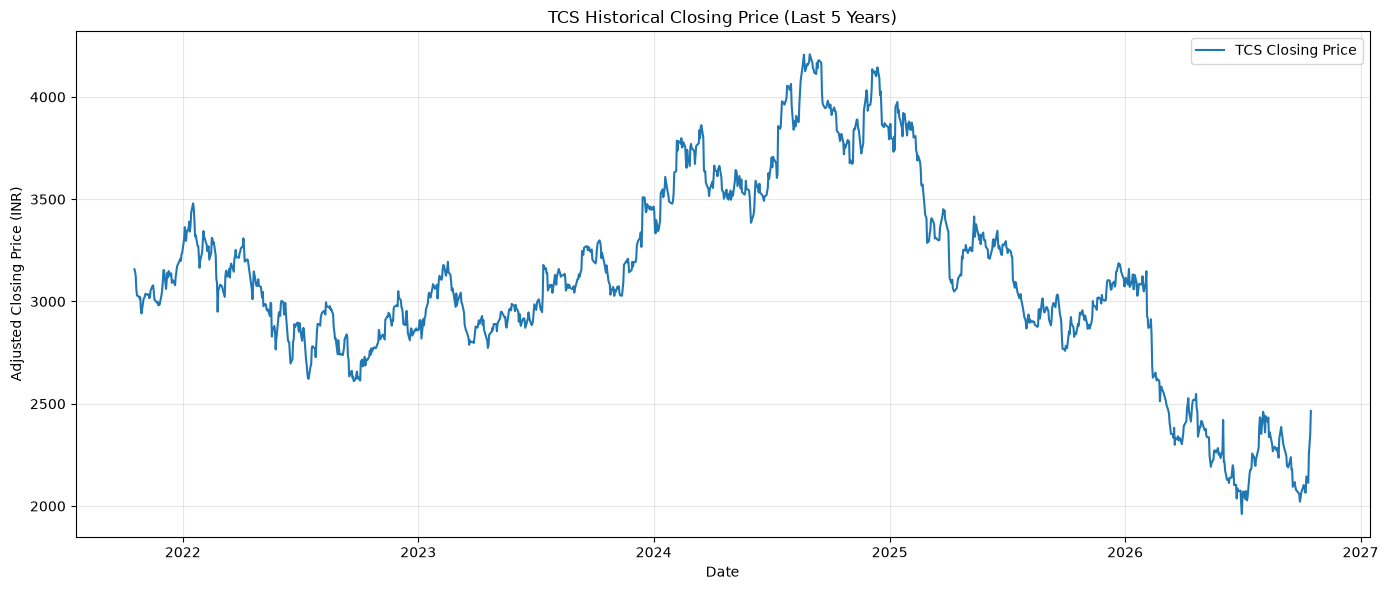

In [194]:

# STEP 8: Historical Closing Price ka graph banao

import matplotlib.pyplot as plt

# Figure ka size set karo
plt.figure(figsize=(14, 6))

# TCS ke closing prices plot karo
plt.plot(
    df.index,
    df["Close"],
    label="TCS Closing Price",
    linewidth=1.5
)

# Graph ka title aur labels set karo
plt.title("TCS Historical Closing Price (Last 5 Years)")
plt.xlabel("Date")
plt.ylabel("Adjusted Closing Price (INR)")

# Graph ko readable banao
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Graph display karo
plt.show()

Daily Returns:


Price,Close,Daily_Return
Ticker,TCS.NS,
Date,,
2021-10-18,3157.566895,NaN
2021-10-19,3146.312256,-0.356434
2021-10-20,3124.408691,-0.696166
2021-10-21,3058.307617,-2.115635
2021-10-22,3029.174561,-0.952588
2021-10-25,3024.066406,-0.168632
2021-10-26,3015.105713,-0.296313
2021-10-27,3021.295654,0.205298



Daily Returns Summary:


count    1236.000000
mean       -0.009688
std         1.439045
min        -8.386125
25%        -0.756979
50%        -0.052847
75%         0.721330
max         6.790584
Name: Daily_Return, dtype: float64

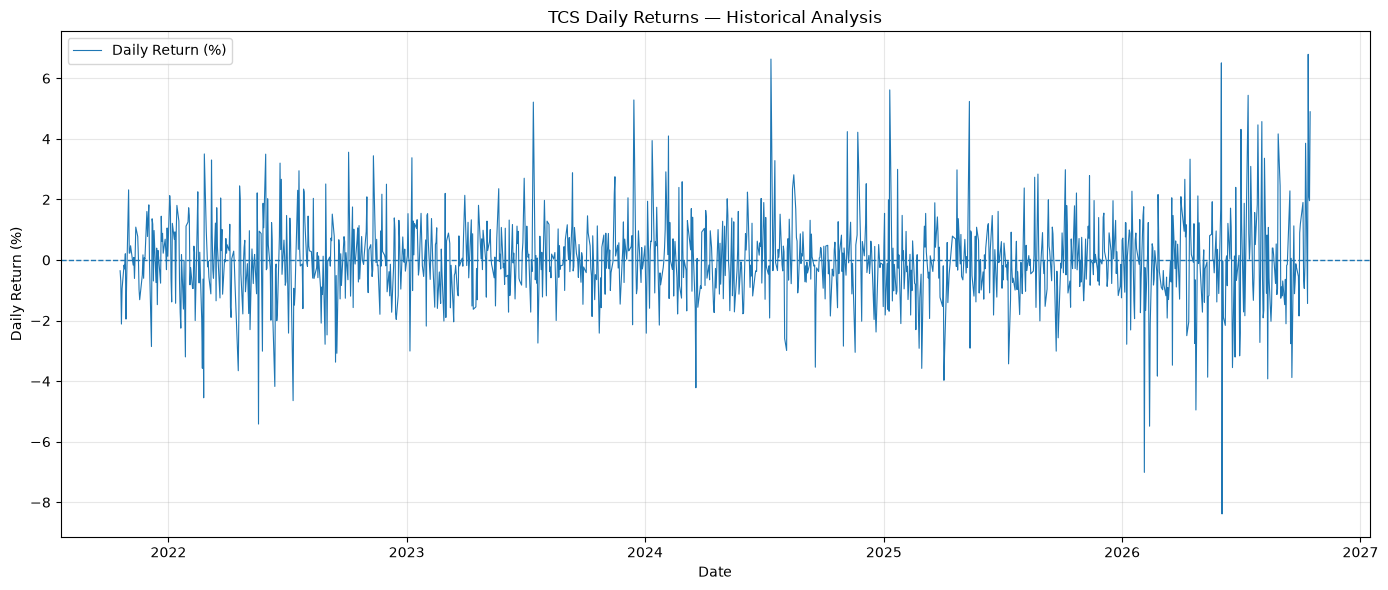

In [195]:
# STEP 9: Daily stock returns calculate karo

import matplotlib.pyplot as plt

# Previous closing price ke comparison mein daily change (%)
df["Daily_Return"] = df["Close"].pct_change() * 100

# Daily returns ke starting records dekho
print("Daily Returns:")
display(df[["Close", "Daily_Return"]].head(10))

# Daily returns ka statistical summary
print("\nDaily Returns Summary:")
display(df["Daily_Return"].describe())

# Daily returns ka graph banao
plt.figure(figsize=(14, 6))

plt.plot(
    df.index,
    df["Daily_Return"],
    linewidth=0.8,
    label="Daily Return (%)"
)

plt.axhline(0, linewidth=1, linestyle="--")

plt.title("TCS Daily Returns — Historical Analysis")
plt.xlabel("Date")
plt.ylabel("Daily Return (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Price,Close,MA20,MA50,MA200
Ticker,TCS.NS,,,
Date,,,,
2026-10-05,2103.218994,2139.257605,2261.841953,2462.852291
2026-10-06,2088.895264,2129.111536,2258.772271,2457.860482
2026-10-07,2069.299561,2119.676697,2254.489038,2452.724200
2026-10-08,2065.022217,2110.749158,2248.083091,2447.686839
2026-10-09,2144.599121,2108.162903,2242.301821,2442.986490
2026-10-12,2113.763184,2104.228821,2236.198267,2437.829993
2026-10-13,2257.300049,2107.635706,2234.282451,2433.385429
2026-10-14,2304.899902,2110.925854,2231.168066,2428.973239


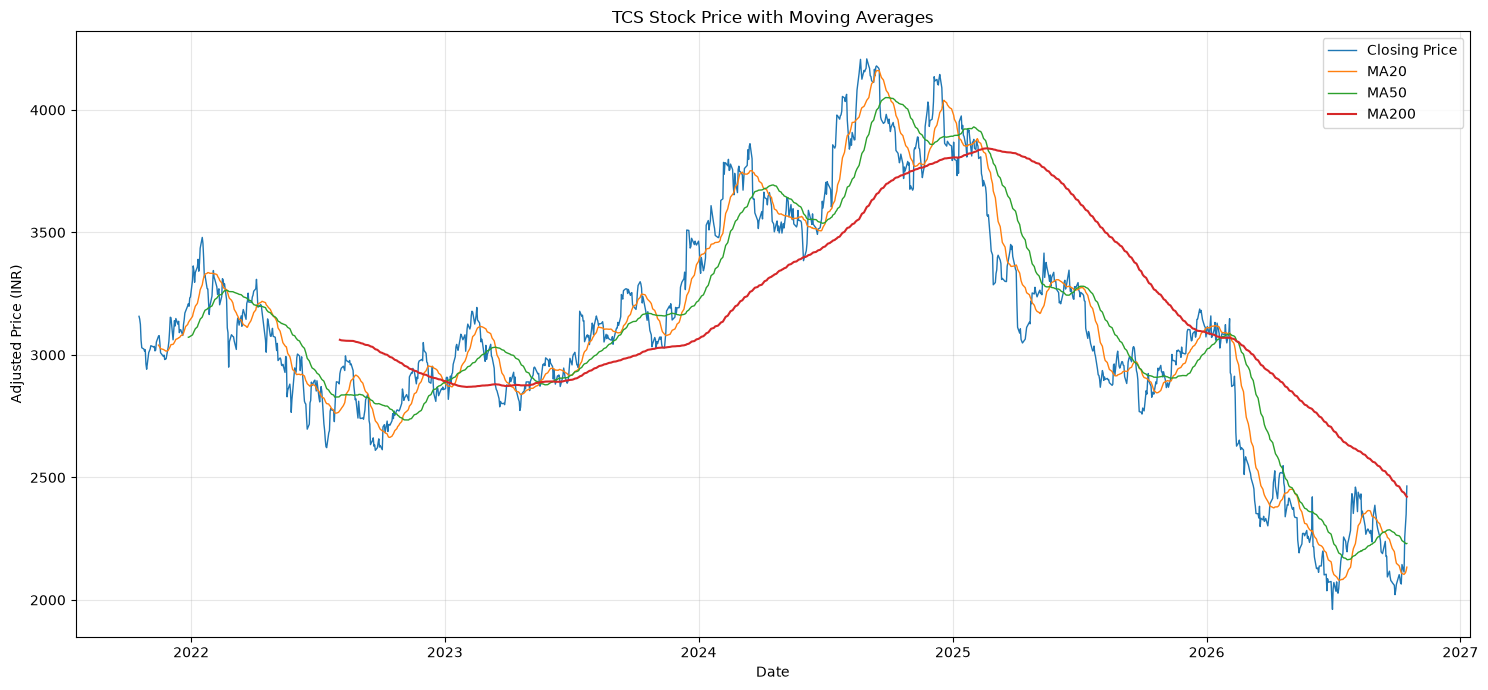

In [196]:
# STEP 10: Moving Averages calculate karo

import matplotlib.pyplot as plt

# STEP 10.1: Last 20, 50 aur 200 trading days ka average
df["MA20"] = df["Close"].rolling(window=20).mean()
df["MA50"] = df["Close"].rolling(window=50).mean()
df["MA200"] = df["Close"].rolling(window=200).mean()

# STEP 10.2: Latest values display karo
display(df[["Close", "MA20", "MA50", "MA200"]].tail(10))

# STEP 10.3: Price aur moving averages ka graph banao
plt.figure(figsize=(15, 7))

plt.plot(df.index, df["Close"], label="Closing Price", linewidth=1)
plt.plot(df.index, df["MA20"], label="MA20", linewidth=1)
plt.plot(df.index, df["MA50"], label="MA50", linewidth=1)
plt.plot(df.index, df["MA200"], label="MA200", linewidth=1.5)

plt.title("TCS Stock Price with Moving Averages")
plt.xlabel("Date")
plt.ylabel("Adjusted Price (INR)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [197]:
# STEP 11.1: Daily price change calculate karo

price_change = df["Close"].diff()

gain = price_change.clip(lower=0)
loss = -price_change.clip(upper=0)

display(df[["Close"]].tail())

Price,Close
Ticker,TCS.NS
Date,
2026-10-12,2113.763184
2026-10-13,2257.300049
2026-10-14,2304.899902
2026-10-15,2350.000000
2026-10-16,2465.000000


In [198]:
# STEP 11: Data columns ko fix karo

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

print(df.columns.tolist())

['Close', 'High', 'Low', 'Open', 'Volume', 'Daily_Return', 'MA20', 'MA50', 'MA200']


In [199]:
# STEP 11.2: CALCULATE RSI-14 SAFELY

import numpy as np
import pandas as pd

# Ensure Close is a single Series, even if yfinance returned MultiIndex columns
close = df["Close"]

if isinstance(close, pd.DataFrame):
    close = close.iloc[:, 0]

# Calculate price changes
delta = close.diff()

# Separate gains and losses
gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)

# Calculate exponentially weighted average gains and losses
avg_gain = gain.ewm(
    alpha=1 / 14,
    min_periods=14,
    adjust=False
).mean()

avg_loss = loss.ewm(
    alpha=1 / 14,
    min_periods=14,
    adjust=False
).mean()

# Calculate RSI safely
rs = avg_gain.div(avg_loss.replace(0, np.nan))

rsi = 100 - (100 / (1 + rs))

# If average loss is zero but gains exist, RSI is 100
rsi = rsi.mask(
    avg_loss.eq(0) & avg_gain.gt(0),
    100
)

# If both average gain and loss are zero, RSI is undefined
rsi = rsi.mask(
    avg_loss.eq(0) & avg_gain.eq(0),
    np.nan
)

# Store the RSI values
df["RSI_14"] = rsi.astype(float)

print("RSI-14 calculated successfully!")

display(
    df[["Close", "RSI_14"]].tail(10)
)

print("\nMissing RSI values:", df["RSI_14"].isna().sum())
print("STEP 11.2 COMPLETED!")

RSI-14 calculated successfully!


Price,Close,RSI_14
Date,,
2026-10-05,2103.218994,42.613084
2026-10-06,2088.895264,40.971023
2026-10-07,2069.299561,38.769966
2026-10-08,2065.022217,38.286465
2026-10-09,2144.599121,50.623711
2026-10-12,2113.763184,46.725656
2026-10-13,2257.300049,61.562466
2026-10-14,2304.899902,65.039631
2026-10-15,2350.000000,67.993956



Missing RSI values: 14
STEP 11.2 COMPLETED!


Price,Close,MACD,MACD_Signal
Date,,,
2026-10-05,2103.218994,-57.526861,-55.293252
2026-10-06,2088.895264,-53.791546,-54.992911
2026-10-07,2069.299561,-51.815198,-54.357368
2026-10-08,2065.022217,-50.017503,-53.489395
2026-10-09,2144.599121,-41.691037,-51.129723
2026-10-12,2113.763184,-37.152189,-48.334216
2026-10-13,2257.300049,-21.722489,-43.011871
2026-10-14,2304.899902,-5.589005,-35.527298
2026-10-15,2350.000000,10.712611,-26.279316


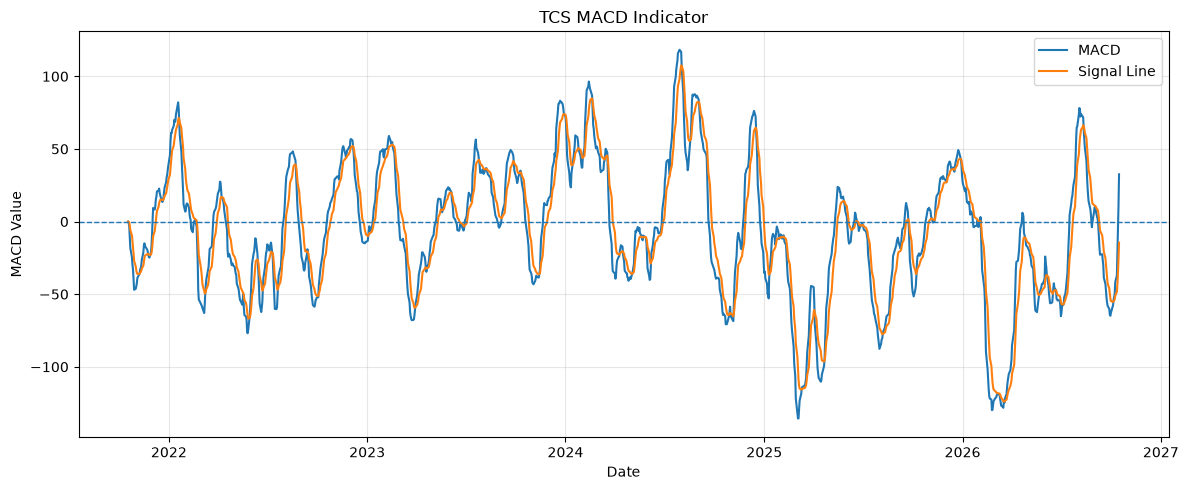

In [200]:
# STEP 12: MACD Indicator calculate karo

# Short-term aur long-term EMA
df["EMA12"] = df["Close"].ewm(span=12, adjust=False).mean()
df["EMA26"] = df["Close"].ewm(span=26, adjust=False).mean()

# MACD aur Signal Line
df["MACD"] = df["EMA12"] - df["EMA26"]
df["MACD_Signal"] = df["MACD"].ewm(span=9, adjust=False).mean()

# Latest values display karo
display(df[["Close", "MACD", "MACD_Signal"]].tail(10))

# MACD graph
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(df.index, df["MACD"], label="MACD")
plt.plot(df.index, df["MACD_Signal"], label="Signal Line")
plt.axhline(0, linestyle="--", linewidth=1)

plt.title("TCS MACD Indicator")
plt.xlabel("Date")
plt.ylabel("MACD Value")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Price,Close,BB_Upper,BB_Middle,BB_Lower
Date,,,,
2026-10-05,2103.218994,2300.654790,2139.257605,1977.860420
2026-10-06,2088.895264,2274.884425,2129.111536,1983.338646
2026-10-07,2069.299561,2254.327981,2119.676697,1985.025413
2026-10-08,2065.022217,2234.007465,2110.749158,1987.490851
2026-10-09,2144.599121,2225.908260,2108.162903,1990.417546
2026-10-12,2113.763184,2215.179008,2104.228821,1993.278634
2026-10-13,2257.300049,2232.836339,2107.635706,1982.435073
2026-10-14,2304.899902,2252.994631,2110.925854,1968.857077
2026-10-15,2350.000000,2295.566966,2119.564563,1943.562160


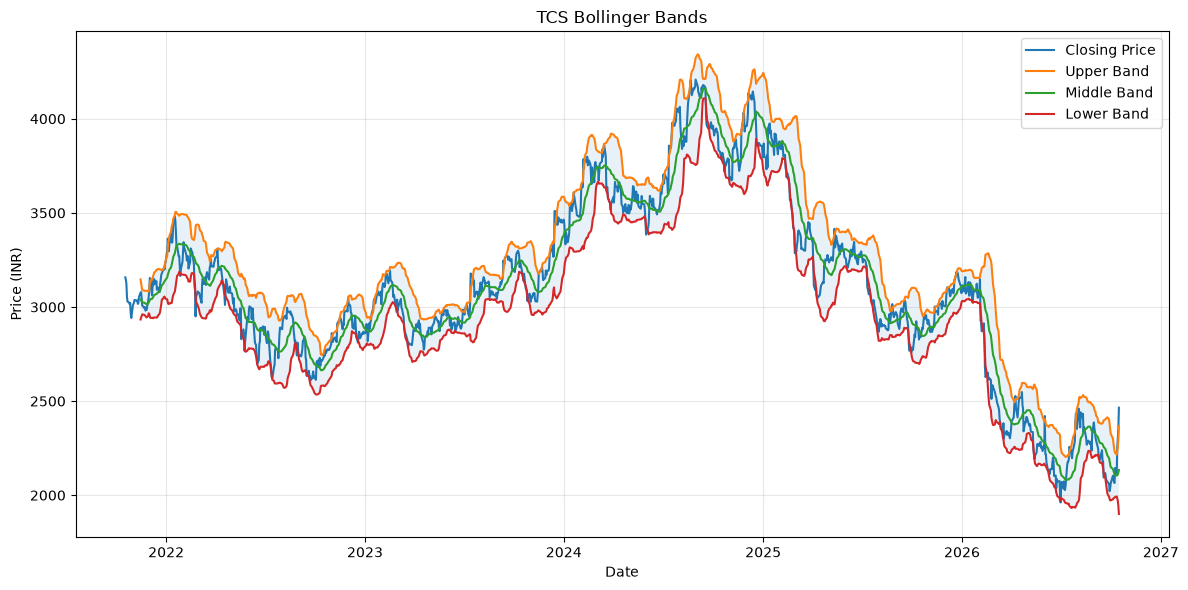

In [201]:
# STEP 13: Bollinger Bands calculate aur visualize karo

# 20-day moving average aur standard deviation
df["BB_Middle"] = df["Close"].rolling(window=20).mean()
bb_std = df["Close"].rolling(window=20).std()

# Upper aur Lower Bands calculate karo
df["BB_Upper"] = df["BB_Middle"] + (2 * bb_std)
df["BB_Lower"] = df["BB_Middle"] - (2 * bb_std)

# Latest values dekho
display(df[["Close", "BB_Upper", "BB_Middle", "BB_Lower"]].tail(10))

# Bollinger Bands ka graph
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(df.index, df["Close"], label="Closing Price")
plt.plot(df.index, df["BB_Upper"], label="Upper Band")
plt.plot(df.index, df["BB_Middle"], label="Middle Band")
plt.plot(df.index, df["BB_Lower"], label="Lower Band")

plt.fill_between(
    df.index,
    df["BB_Upper"],
    df["BB_Lower"],
    alpha=0.1
)

plt.title("TCS Bollinger Bands")
plt.xlabel("Date")
plt.ylabel("Price (INR)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Price,Volume,Volume_MA20
Date,,
2026-10-05,5270768,3320028.85
2026-10-06,2382510,3310938.25
2026-10-07,1349758,3263548.60
2026-10-08,4288031,3370544.45
2026-10-09,11692314,3786656.60
2026-10-12,3540523,3839137.15
2026-10-13,11048193,4259840.60
2026-10-14,12145767,4596818.45
2026-10-15,9150523,4916159.15


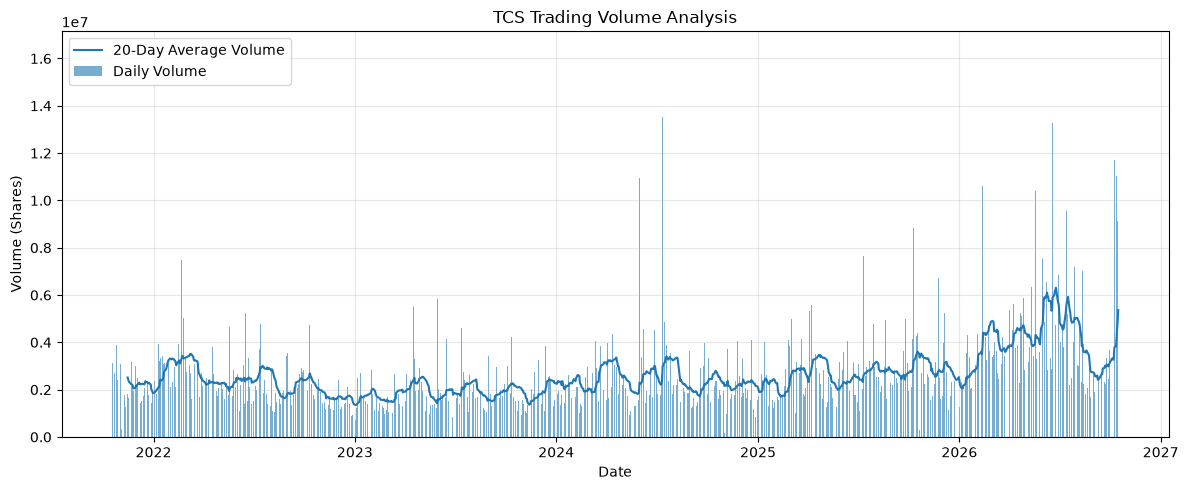

In [202]:
# STEP 14: Stock Volume Analysis

import matplotlib.pyplot as plt

# 20-day average volume calculate karo
df["Volume_MA20"] = df["Volume"].rolling(window=20).mean()

# Latest volume data dekho
display(df[["Volume", "Volume_MA20"]].tail(10))

# Volume graph banao
plt.figure(figsize=(12, 5))

plt.bar(df.index, df["Volume"], label="Daily Volume", alpha=0.6)
plt.plot(df.index, df["Volume_MA20"], label="20-Day Average Volume")

plt.title("TCS Trading Volume Analysis")
plt.xlabel("Date")
plt.ylabel("Volume (Shares)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [203]:
# STEP 15: Final dataset check

# Dataset ka size check karo
print("Dataset Shape:", df.shape)

# Saare columns dekho
print("\nAvailable Features:")
print(df.columns.tolist())

# Missing values check karo
print("\nMissing Values:")
print(df.isnull().sum())

# Latest records dekho
print("\nLatest Dataset Records:")
display(df.tail(10))

# Dataset ki statistical summary
print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (1237, 18)

Available Features:
['Close', 'High', 'Low', 'Open', 'Volume', 'Daily_Return', 'MA20', 'MA50', 'MA200', 'RSI_14', 'EMA12', 'EMA26', 'MACD', 'MACD_Signal', 'BB_Middle', 'BB_Upper', 'BB_Lower', 'Volume_MA20']

Missing Values:
Price
Close             0
High              0
Low               0
Open              0
Volume            0
Daily_Return      1
MA20             19
MA50             49
MA200           199
RSI_14           14
EMA12             0
EMA26             0
MACD              0
MACD_Signal       0
BB_Middle        19
BB_Upper         19
BB_Lower         19
Volume_MA20      19
dtype: int64

Latest Dataset Records:


Price,Close,High,Low,Open,Volume,Daily_Return,MA20,MA50,MA200,RSI_14,EMA12,EMA26,MACD,MACD_Signal,BB_Middle,BB_Upper,BB_Lower,Volume_MA20
Date,,,,,,,,,,,,,,,,,,
2026-10-05,2103.218994,2129.578863,2052.687818,2102.821206,5270768,1.898783,2139.257605,2261.841953,2462.852291,42.613084,2095.488220,2153.015081,-57.526861,-55.293252,2139.257605,2300.654790,1977.860420,3320028.85
2026-10-06,2088.895264,2103.815944,2071.686697,2085.911128,2382510,-0.681038,2129.111536,2258.772271,2457.860482,40.971023,2094.473919,2148.265465,-53.791546,-54.992911,2129.111536,2274.884425,1983.338646,3310938.25
2026-10-07,2069.299561,2093.868900,2065.022250,2074.173553,1349758,-0.938089,2119.676697,2254.489038,2452.724200,38.769966,2090.600941,2142.416138,-51.815198,-54.357368,2119.676697,2254.327981,1985.025413,3263548.60
2026-10-08,2065.022217,2130.175856,2049.106824,2092.874154,4288031,-0.206705,2110.749158,2248.083091,2447.686839,38.286465,2086.665752,2136.683255,-50.017503,-53.489395,2110.749158,2234.007465,1987.490851,3370544.45
2026-10-09,2144.599121,2192.345298,2074.969279,2074.969279,11692314,3.853562,2108.162903,2242.301821,2442.986490,50.623711,2095.578578,2137.269616,-41.691037,-51.129723,2108.162903,2225.908260,1990.417546,3786656.60
2026-10-12,2113.763184,2183.492598,2109.684767,2173.346340,3540523,-1.437842,2104.228821,2236.198267,2437.829993,46.725656,2098.376210,2135.528398,-37.152189,-48.334216,2104.228821,2215.179008,1993.278634,3839137.15
2026-10-13,2257.300049,2257.300049,2143.604416,2145.494271,11048193,6.790584,2107.635706,2234.282451,2433.385429,61.562466,2122.826031,2144.548521,-21.722489,-43.011871,2107.635706,2232.836339,1982.435073,4259840.60
2026-10-14,2304.899902,2335.800049,2265.600098,2274.000000,12145767,2.108707,2110.925854,2231.168066,2428.973239,65.039631,2150.837396,2156.426401,-5.589005,-35.527298,2110.925854,2252.994631,1968.857077,4596818.45
2026-10-15,2350.000000,2386.699951,2335.000000,2347.199951,9150523,1.956705,2119.564563,2229.228232,2424.857967,67.993956,2181.477797,2170.765186,10.712611,-26.279316,2119.564563,2295.566966,1943.562160,4916159.15



Statistical Summary:


Price,Close,High,Low,Open,Volume,Daily_Return,MA20,MA50,MA200,RSI_14,EMA12,EMA26,MACD,MACD_Signal,BB_Middle,BB_Upper,BB_Lower,Volume_MA20
count,1237.000000,1237.000000,1237.000000,1237.000000,1.237000e+03,1236.000000,1218.000000,1188.000000,1038.000000,1223.000000,1237.000000,1237.000000,1237.000000,1237.000000,1218.000000,1218.000000,1218.000000,1.218000e+03
mean,3109.725836,3139.144332,3082.399276,3111.672632,2.647176e+06,-0.009688,3117.413840,3129.993571,3188.447927,48.948389,3113.871824,3119.477317,-5.605493,-5.558553,3117.413840,3264.456349,2970.371330,2.612403e+06
std,479.058513,482.061708,476.056551,478.554326,1.708803e+06,1.439045,469.089378,453.444937,372.267861,12.410529,469.588116,457.677536,46.466853,43.546241,469.089378,483.607458,462.387067,8.890257e+05
min,1961.362061,2030.018661,1955.624263,1986.490111,0.000000e+00,-8.386125,2080.872992,2164.222610,2421.274557,15.829893,2055.849677,2102.990182,-135.615902,-123.925010,2080.872992,2203.339518,1900.432069,1.350583e+06
25%,2872.470703,2898.255215,2849.178717,2876.838606,1.646224e+06,-0.756979,2880.995731,2898.111311,2901.725880,39.687212,2878.409198,2890.117395,-36.753568,-33.872283,2880.995731,3001.946096,2751.927245,2.015765e+06
50%,3072.716797,3095.467425,3049.583135,3075.389589,2.202244e+06,-0.052847,3090.330780,3076.092939,3067.409028,49.198751,3084.282418,3083.751902,-5.363133,-5.566631,3090.330780,3199.129104,2959.592020,2.379518e+06
75%,3375.238525,3406.781577,3338.286792,3382.216010,3.079898e+06,0.721330,3367.939096,3401.578018,3497.567463,58.034302,3378.793852,3361.815464,27.822259,26.360166,3367.939096,3555.865308,3209.077592,2.901952e+06
max,4208.337891,4243.917580,4169.754320,4228.899771,1.633158e+07,6.790584,4160.862085,4050.330903,3843.298561,77.312320,4154.459397,4110.465895,118.292612,107.489062,4160.862085,4342.520161,4108.970348,6.308853e+06


In [204]:
# STEP 16: Machine Learning dataset prepare karo

# Original dataset ki copy banao
ml_df = df.copy()

# Agle trading day ke prices ko target banao
ml_df["Target_Next_Open"] = ml_df["Open"].shift(-1)
ml_df["Target_Next_High"] = ml_df["High"].shift(-1)
ml_df["Target_Next_Low"] = ml_df["Low"].shift(-1)
ml_df["Target_Next_Close"] = ml_df["Close"].shift(-1)

# Missing values wale rows remove karo
ml_df = ml_df.dropna()

# Prepared dataset save karo
output_file = DATA_DIR / "TCS_ml_dataset.csv"
ml_df.to_csv(output_file)

# Dataset check karo
print("ML Dataset Successfully Prepared!")
print("Total Records:", len(ml_df))
print("Total Features and Targets:", len(ml_df.columns))
print("Saved Location:", output_file)

display(ml_df.tail(5))

ML Dataset Successfully Prepared!
Total Records: 1037
Total Features and Targets: 22
Saved Location: data\TCS_ml_dataset.csv


Price,Close,High,Low,Open,Volume,Daily_Return,MA20,MA50,MA200,RSI_14,...,MACD,MACD_Signal,BB_Middle,BB_Upper,BB_Lower,Volume_MA20,Target_Next_Open,Target_Next_High,Target_Next_Low,Target_Next_Close
Date,,,,,,,,,,,,,,,,,,,,,
2026-10-09,2144.599121,2192.345298,2074.969279,2074.969279,11692314,3.853562,2108.162903,2242.301821,2442.986490,50.623711,...,-41.691037,-51.129723,2108.162903,2225.908260,1990.417546,3786656.60,2173.346340,2183.492598,2109.684767,2113.763184
2026-10-12,2113.763184,2183.492598,2109.684767,2173.346340,3540523,-1.437842,2104.228821,2236.198267,2437.829993,46.725656,...,-37.152189,-48.334216,2104.228821,2215.179008,1993.278634,3839137.15,2145.494271,2257.300049,2143.604416,2257.300049
2026-10-13,2257.300049,2257.300049,2143.604416,2145.494271,11048193,6.790584,2107.635706,2234.282451,2433.385429,61.562466,...,-21.722489,-43.011871,2107.635706,2232.836339,1982.435073,4259840.60,2274.000000,2335.800049,2265.600098,2304.899902
2026-10-14,2304.899902,2335.800049,2265.600098,2274.000000,12145767,2.108707,2110.925854,2231.168066,2428.973239,65.039631,...,-5.589005,-35.527298,2110.925854,2252.994631,1968.857077,4596818.45,2347.199951,2386.699951,2335.000000,2350.000000
2026-10-15,2350.000000,2386.699951,2335.000000,2347.199951,9150523,1.956705,2119.564563,2229.228232,2424.857967,67.993956,...,10.712611,-26.279316,2119.564563,2295.566966,1943.562160,4916159.15,2382.000000,2484.699951,2375.699951,2465.000000


In [205]:
# STEP 17: Features aur targets separate karo

# Predict karne wale target columns
target_columns = [
    "Target_Next_Open",
    "Target_Next_High",
    "Target_Next_Low",
    "Target_Next_Close"
]

# Sirf numeric columns ko features ke liye select karo
X = ml_df.drop(columns=target_columns).select_dtypes(include="number")

# Target prices ko y mein store karo
y = ml_df[target_columns]

# Dataset information check karo
print("Features Shape:", X.shape)
print("Targets Shape:", y.shape)

print("\nFeature Columns:")
print(X.columns.tolist())

print("\nTarget Columns:")
print(y.columns.tolist())

# Starting records display karo
display(X.head())
display(y.head())

Features Shape: (1037, 18)
Targets Shape: (1037, 4)

Feature Columns:
['Close', 'High', 'Low', 'Open', 'Volume', 'Daily_Return', 'MA20', 'MA50', 'MA200', 'RSI_14', 'EMA12', 'EMA26', 'MACD', 'MACD_Signal', 'BB_Middle', 'BB_Upper', 'BB_Lower', 'Volume_MA20']

Target Columns:
['Target_Next_Open', 'Target_Next_High', 'Target_Next_Low', 'Target_Next_Close']


Price,Close,High,Low,Open,Volume,Daily_Return,MA20,MA50,MA200,RSI_14,EMA12,EMA26,MACD,MACD_Signal,BB_Middle,BB_Upper,BB_Lower,Volume_MA20
Date,,,,,,,,,,,,,,,,,,
2022-08-03,2923.501953,2931.818548,2868.831328,2871.413806,2895824,1.449064,2773.241846,2832.240234,3061.772748,62.443850,2831.655120,2814.015198,17.639922,-8.331116,2773.241846,2962.225339,2584.258352,2842063.10
2022-08-04,2937.027100,2965.872507,2895.356714,2932.693759,2150567,0.462635,2776.557788,2834.630083,3060.670049,63.568859,2847.866194,2823.127191,24.739003,-1.717093,2776.557788,2974.840475,2578.275101,2850095.40
2022-08-05,2945.868652,2956.330008,2937.070529,2942.498158,1106933,0.301037,2781.293713,2836.596914,3059.667831,64.321270,2862.943495,2832.219151,30.724344,4.771195,2781.293713,2991.258464,2571.328963,2798596.25
2022-08-08,2954.097900,2957.993525,2920.437623,2945.825121,1068836,0.279349,2793.061572,2836.738467,3058.816277,65.044889,2876.967250,2841.247207,35.720043,10.960964,2793.061572,3014.341791,2571.781353,2503308.05
2022-08-10,2936.414551,2963.334055,2919.562503,2963.334055,1878359,-0.598604,2805.215674,2836.716714,3058.206812,62.128918,2886.112988,2848.296640,37.816349,16.332041,2805.215674,3030.105444,2580.325903,2410485.25


Price,Target_Next_Open,Target_Next_High,Target_Next_Low,Target_Next_Close
Date,,,,
2022-08-03,2932.693759,2965.872507,2895.356714,2937.027100
2022-08-04,2942.498158,2956.330008,2937.070529,2945.868652
2022-08-05,2945.825121,2957.993525,2920.437623,2954.097900
2022-08-08,2963.334055,2963.334055,2919.562503,2936.414551
2022-08-10,2976.465643,3001.590472,2954.623680,2996.162842


In [206]:
# STEP 18: Training aur Testing data split karo

# 80% purana data training ke liye, 20% latest data testing ke liye
split_index = int(len(X) * 0.80)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

# Dataset sizes check karo
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nTraining Period:")
print(X_train.index.min(), "to", X_train.index.max())

print("\nTesting Period:")
print(X_test.index.min(), "to", X_test.index.max())

# Confirm karo ki training data testing se pehle ka hai
assert X_train.index.max() < X_test.index.min()

print("\nChronological split successful!")

Training Records: 829
Testing Records: 208

Training Period:
2022-08-03 00:00:00 to 2025-12-11 00:00:00

Testing Period:
2025-12-12 00:00:00 to 2026-10-15 00:00:00

Chronological split successful!


In [207]:
# STEP 19: Training aur testing data clean karo

import numpy as np

# Infinite values ko missing values mein convert karo
X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

# Missing values check karo
print("Missing Values in Training Data:")
print(X_train.isnull().sum().sum())

print("\nMissing Values in Testing Data:")
print(X_test.isnull().sum().sum())

# Target values bhi check karo
print("\nMissing Target Values:")
print("Training:", y_train.isnull().sum().sum())
print("Testing:", y_test.isnull().sum().sum())

Missing Values in Training Data:
0

Missing Values in Testing Data:
0

Missing Target Values:
Training: 0
Testing: 0


In [208]:
# STEP 20: Random Forest model train karo

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Model create karo
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

# Model ko training data par train karo
rf_model.fit(X_train, y_train)

# Testing data par predictions
rf_predictions = rf_model.predict(X_test)

# Predictions ko DataFrame mein convert karo
rf_predictions = pd.DataFrame(
    rf_predictions,
    columns=y_test.columns,
    index=y_test.index
)

print("Random Forest Model Training Complete!")
print("Predictions Shape:", rf_predictions.shape)

display(rf_predictions.head())

Random Forest Model Training Complete!
Predictions Shape: (208, 4)


Price,Target_Next_Open,Target_Next_High,Target_Next_Low,Target_Next_Close
Date,,,,
2025-12-12,3080.125884,3101.655970,3059.349521,3080.595561
2025-12-15,3099.545647,3125.567444,3078.635761,3103.463733
2025-12-16,3074.038043,3086.869077,3042.490904,3065.377096
2025-12-17,3083.215831,3100.976828,3059.645107,3080.662579
2025-12-18,3125.368328,3150.104110,3102.183690,3128.523805


In [209]:
# STEP 21: Random Forest model evaluate karo

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Har target ke liye prediction error calculate karo
results = []

for column in y_test.columns:
    actual = y_test[column]
    predicted = rf_predictions[column]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    results.append({
        "Price": column,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2)
    })

# Results table display karo
results_df = pd.DataFrame(results)

print("Random Forest Model Evaluation:")
display(results_df)

# Actual aur predicted closing prices compare karo
comparison = pd.DataFrame({
    "Actual_Close": y_test["Target_Next_Close"],
    "Predicted_Close": rf_predictions["Target_Next_Close"]
})

print("Actual vs Predicted Closing Prices:")
display(comparison.head(10))

Random Forest Model Evaluation:


,Price,MAE,RMSE
0,Target_Next_Open,287.49,347.77
1,Target_Next_High,306.47,367.32
2,Target_Next_Low,297.41,356.07
3,Target_Next_Close,319.74,379.61


Actual vs Predicted Closing Prices:


,Actual_Close,Predicted_Close
Date,,
2025-12-12,3096.555908,3080.595561
2025-12-15,3072.494385,3103.463733
2025-12-16,3084.668945,3065.377096
2025-12-17,3145.062500,3080.662579
2025-12-18,3146.212891,3128.523805
2025-12-19,3187.337891,3148.387417
2025-12-22,3173.054443,3163.243692
2025-12-23,3181.681885,3153.283308
2025-12-24,3144.295654,3157.676933


In [210]:
# STEP 22: Prediction error aur performance analysis

# Actual aur predicted closing prices
actual = y_test["Target_Next_Close"]
predicted = rf_predictions["Target_Next_Close"]

# Error calculate karo
error = actual - predicted
absolute_error = error.abs()

# Percentage error
percentage_error = (absolute_error / actual) * 100

# Directional accuracy: price up/down ki direction compare karo
actual_direction = actual.diff().dropna() > 0
predicted_direction = predicted.diff().dropna() > 0

directional_accuracy = (
    actual_direction == predicted_direction
).mean() * 100

# Results display karo
print("Mean Absolute Error (MAE):", round(absolute_error.mean(), 2))
print("Mean Absolute Percentage Error (MAPE):", round(percentage_error.mean(), 2), "%")
print("Directional Accuracy:", round(directional_accuracy, 2), "%")

# Individual prediction errors dekho
error_df = pd.DataFrame({
    "Actual_Close": actual,
    "Predicted_Close": predicted,
    "Absolute_Error": absolute_error,
    "Error_Percent": percentage_error
})

display(error_df.head(10))

Mean Absolute Error (MAE): 319.74
Mean Absolute Percentage Error (MAPE): 14.32 %
Directional Accuracy: 43.48 %


,Actual_Close,Predicted_Close,Absolute_Error,Error_Percent
Date,,,,
2025-12-12,3096.555908,3080.595561,15.960347,0.515423
2025-12-15,3072.494385,3103.463733,30.969348,1.007955
2025-12-16,3084.668945,3065.377096,19.291850,0.625411
2025-12-17,3145.062500,3080.662579,64.399921,2.047652
2025-12-18,3146.212891,3128.523805,17.689086,0.562234
2025-12-19,3187.337891,3148.387417,38.950474,1.222038
2025-12-22,3173.054443,3163.243692,9.810752,0.309190
2025-12-23,3181.681885,3153.283308,28.398577,0.892565
2025-12-24,3144.295654,3157.676933,13.381278,0.425573


In [211]:
# STEP 23: Random Forest ko simple baseline se compare karo

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Baseline: aaj ka Close = agle trading day ka predicted Close
baseline_predictions = X_test["Close"]

# Random Forest aur baseline ke actual errors
actual_close = y_test["Target_Next_Close"]
rf_close = rf_predictions["Target_Next_Close"]

# MAE aur RMSE calculate karo
comparison_results = pd.DataFrame({
    "Model": ["Baseline", "Random Forest"],
    "MAE": [
        mean_absolute_error(actual_close, baseline_predictions),
        mean_absolute_error(actual_close, rf_close)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(actual_close, baseline_predictions)),
        np.sqrt(mean_squared_error(actual_close, rf_close))
    ]
})

comparison_results[["MAE", "RMSE"]] = comparison_results[
    ["MAE", "RMSE"]
].round(2)

print("Baseline vs Random Forest:")
display(comparison_results)

# Kaunsa model behtar raha?
if comparison_results.loc[1, "MAE"] < comparison_results.loc[0, "MAE"]:
    print("Random Forest ne baseline se kam MAE diya.")
else:
    print("Baseline ka MAE Random Forest se behtar ya barabar hai.")

Baseline vs Random Forest:


,Model,MAE,RMSE
0,Baseline,35.12,48.96
1,Random Forest,319.74,379.61


Baseline ka MAE Random Forest se behtar ya barabar hai.


Top 15 Important Features:


,Feature,Importance
0,Close,0.591818
1,High,0.373329
2,Low,0.029480
3,Open,0.001315
4,Volume_MA20,0.000488
5,MA200,0.000411
6,Daily_Return,0.000409
7,Volume,0.000408
8,MACD_Signal,0.000376
9,MACD,0.000296


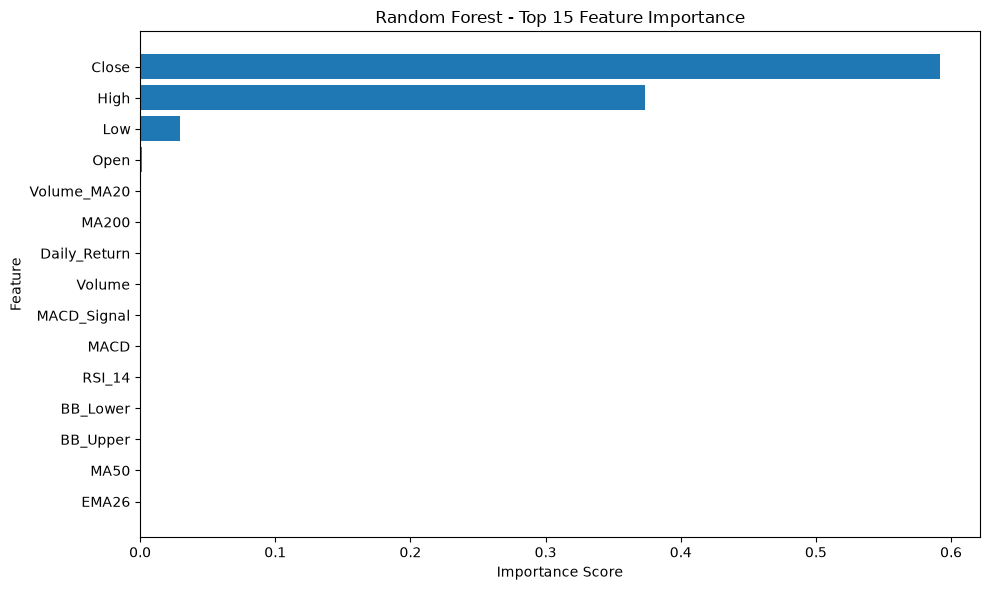

In [212]:
# STEP 24: Random Forest ke important features identify karo

import pandas as pd
import matplotlib.pyplot as plt

# Model se feature importance nikalo
importance_values = rf_model.feature_importances_

# Feature names ke saath DataFrame banao
feature_importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importance_values
})

# Sabse important features pehle dikhao
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("Top 15 Important Features:")
display(feature_importance_df.head(15))

# Top 15 features ka graph
top_features = feature_importance_df.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Random Forest - Top 15 Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [213]:
# STEP 25: Linear Regression model train aur evaluate karo

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Linear Regression model train karo
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Test data par predictions
lr_predictions = lr_model.predict(X_test)

lr_predictions = pd.DataFrame(
    lr_predictions,
    columns=y_test.columns,
    index=y_test.index
)

# Sabhi OHLC targets ka evaluation
lr_results = []

for column in y_test.columns:
    actual = y_test[column]
    predicted = lr_predictions[column]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    lr_results.append({
        "Target": column,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2)
    })

lr_results_df = pd.DataFrame(lr_results)

print("Linear Regression Evaluation:")
display(lr_results_df)

# Closing price ki actual vs predicted comparison
print("Actual vs Predicted Closing Prices:")
display(pd.DataFrame({
    "Actual_Close": y_test["Target_Next_Close"],
    "Linear_Regression_Close": lr_predictions["Target_Next_Close"]
}).head(10))

Linear Regression Evaluation:


,Target,MAE,RMSE
0,Target_Next_Open,18.74,29.02
1,Target_Next_High,28.13,38.83
2,Target_Next_Low,33.26,47.21
3,Target_Next_Close,39.46,53.15


Actual vs Predicted Closing Prices:


,Actual_Close,Linear_Regression_Close
Date,,
2025-12-12,3096.555908,3087.001687
2025-12-15,3072.494385,3096.834719
2025-12-16,3084.668945,3072.595178
2025-12-17,3145.062500,3086.076458
2025-12-18,3146.212891,3147.809943
2025-12-19,3187.337891,3150.198629
2025-12-22,3173.054443,3186.912814
2025-12-23,3181.681885,3170.408078
2025-12-24,3144.295654,3178.253166


In [214]:
# STEP 26: Baseline, Random Forest aur Linear Regression comparison

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Baseline prediction: current Close ko next Close maan rahe hain
baseline_predictions = X_test["Close"]

# Sabhi models ka evaluation
models = {
    "Baseline": baseline_predictions,
    "Random Forest": rf_predictions["Target_Next_Close"],
    "Linear Regression": lr_predictions["Target_Next_Close"]
}

actual = y_test["Target_Next_Close"]
comparison_results = []

for model_name, predictions in models.items():
    mae = mean_absolute_error(actual, predictions)
    rmse = np.sqrt(mean_squared_error(actual, predictions))

    comparison_results.append({
        "Model": model_name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2)
    })

comparison_df = pd.DataFrame(comparison_results)
comparison_df = comparison_df.sort_values(
    by="MAE"
).reset_index(drop=True)

print("Model Performance Comparison:")
display(comparison_df)

print("Best model by MAE:", comparison_df.iloc[0]["Model"])

Model Performance Comparison:


,Model,MAE,RMSE
0,Baseline,35.12,48.96
1,Linear Regression,39.46,53.15
2,Random Forest,319.74,379.61


Best model by MAE: Baseline


In [215]:
# STEP 27: Gradient Boosting model train aur evaluate karo

import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# MultiOutputRegressor se chaaron OHLC targets predict honge
gb_model = MultiOutputRegressor(
    GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        loss="squared_error",
        random_state=42
    )
)

# Model train karo
gb_model.fit(X_train, y_train)

# Test data par prediction
gb_values = gb_model.predict(X_test)

gb_predictions = pd.DataFrame(
    gb_values,
    columns=y_test.columns,
    index=y_test.index
)

# Chaaron target prices ka evaluation
gb_results = []

for column in y_test.columns:
    actual = y_test[column]
    predicted = gb_predictions[column]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    gb_results.append({
        "Target": column,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2)
    })

gb_results_df = pd.DataFrame(gb_results)

print("Gradient Boosting Evaluation:")
display(gb_results_df)

# Closing price predictions dekho
print("Actual vs Gradient Boosting Closing Prices:")
display(pd.DataFrame({
    "Actual_Close": y_test["Target_Next_Close"],
    "GB_Predicted_Close": gb_predictions["Target_Next_Close"]
}).head(10))

Gradient Boosting Evaluation:


,Target,MAE,RMSE
0,Target_Next_Open,291.07,351.40
1,Target_Next_High,305.60,365.10
2,Target_Next_Low,301.43,359.18
3,Target_Next_Close,312.31,369.53


Actual vs Gradient Boosting Closing Prices:


,Actual_Close,GB_Predicted_Close
Date,,
2025-12-12,3096.555908,3083.459367
2025-12-15,3072.494385,3101.898203
2025-12-16,3084.668945,3064.785918
2025-12-17,3145.062500,3083.817190
2025-12-18,3146.212891,3152.627221
2025-12-19,3187.337891,3152.450296
2025-12-22,3173.054443,3182.519592
2025-12-23,3181.681885,3163.180872
2025-12-24,3144.295654,3171.853425


In [216]:
# STEP 28: Chaaron models ki performance compare karo

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Actual next-day closing prices
actual = y_test["Target_Next_Close"]

# Sabhi models ki predictions
model_predictions = {
    "Baseline": X_test["Close"],
    "Linear Regression": lr_predictions["Target_Next_Close"],
    "Random Forest": rf_predictions["Target_Next_Close"],
    "Gradient Boosting": gb_predictions["Target_Next_Close"]
}

# MAE aur RMSE calculate karo
all_results = []

for model_name, predictions in model_predictions.items():
    mae = mean_absolute_error(actual, predictions)
    rmse = np.sqrt(mean_squared_error(actual, predictions))

    all_results.append({
        "Model": model_name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2)
    })

# Best model ko top par dikhao
all_models_df = pd.DataFrame(all_results).sort_values(
    by="MAE"
).reset_index(drop=True)

print("All Models Performance Comparison:")
display(all_models_df)

print("Lowest MAE Model:", all_models_df.iloc[0]["Model"])

All Models Performance Comparison:


,Model,MAE,RMSE
0,Baseline,35.12,48.96
1,Linear Regression,39.46,53.15
2,Gradient Boosting,312.31,369.53
3,Random Forest,319.74,379.61


Lowest MAE Model: Baseline


In [217]:
# STEP 29: Extra Trees model train aur evaluate karo

import numpy as np
import pandas as pd
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Extra Trees model banao
et_model = ExtraTreesRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

# Model train karo
et_model.fit(X_train, y_train)

# Test data par prediction
et_values = et_model.predict(X_test)

et_predictions = pd.DataFrame(
    et_values,
    columns=y_test.columns,
    index=y_test.index
)

# Chaaron OHLC targets ka evaluation
et_results = []

for column in y_test.columns:
    actual = y_test[column]
    predicted = et_predictions[column]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    et_results.append({
        "Target": column,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2)
    })

et_results_df = pd.DataFrame(et_results)

print("Extra Trees Evaluation:")
display(et_results_df)

# Closing price predictions dekho
print("Actual vs Extra Trees Closing Prices:")
display(pd.DataFrame({
    "Actual_Close": y_test["Target_Next_Close"],
    "ExtraTrees_Close": et_predictions["Target_Next_Close"]
}).head(10))

Extra Trees Evaluation:


,Target,MAE,RMSE
0,Target_Next_Open,290.17,349.93
1,Target_Next_High,295.35,354.59
2,Target_Next_Low,297.48,355.28
3,Target_Next_Close,306.34,364.40


Actual vs Extra Trees Closing Prices:


,Actual_Close,ExtraTrees_Close
Date,,
2025-12-12,3096.555908,3080.996970
2025-12-15,3072.494385,3095.535823
2025-12-16,3084.668945,3069.111076
2025-12-17,3145.062500,3078.698898
2025-12-18,3146.212891,3132.056271
2025-12-19,3187.337891,3145.125557
2025-12-22,3173.054443,3165.663768
2025-12-23,3181.681885,3158.552512
2025-12-24,3144.295654,3160.943129


In [218]:
# STEP 30: Sabhi 5 models ka comparison

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Actual next-day closing prices
actual = y_test["Target_Next_Close"]

# Sabhi models ki predictions
model_predictions = {
    "Baseline": X_test["Close"],
    "Linear Regression": lr_predictions["Target_Next_Close"],
    "Random Forest": rf_predictions["Target_Next_Close"],
    "Gradient Boosting": gb_predictions["Target_Next_Close"],
    "Extra Trees": et_predictions["Target_Next_Close"]
}

# Har model ka MAE aur RMSE calculate karo
results = []

for model_name, predictions in model_predictions.items():
    mae = mean_absolute_error(actual, predictions)
    rmse = np.sqrt(mean_squared_error(actual, predictions))

    results.append({
        "Model": model_name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2)
    })

# Kam MAE wala model upar dikhao
model_comparison_df = pd.DataFrame(results).sort_values(
    by="MAE"
).reset_index(drop=True)

print("All Models Performance Comparison:")
display(model_comparison_df)

print("Best model by MAE:", model_comparison_df.iloc[0]["Model"])

All Models Performance Comparison:


,Model,MAE,RMSE
0,Baseline,35.12,48.96
1,Linear Regression,39.46,53.15
2,Extra Trees,306.34,364.40
3,Gradient Boosting,312.31,369.53
4,Random Forest,319.74,379.61


Best model by MAE: Baseline


Features Correlation with Next-Day Close:


,Correlation
Price,
Close,0.995
High,0.993
Low,0.993
Open,0.990
EMA12,0.981
EMA26,0.964
MA20,0.962
BB_Middle,0.962
BB_Upper,0.953


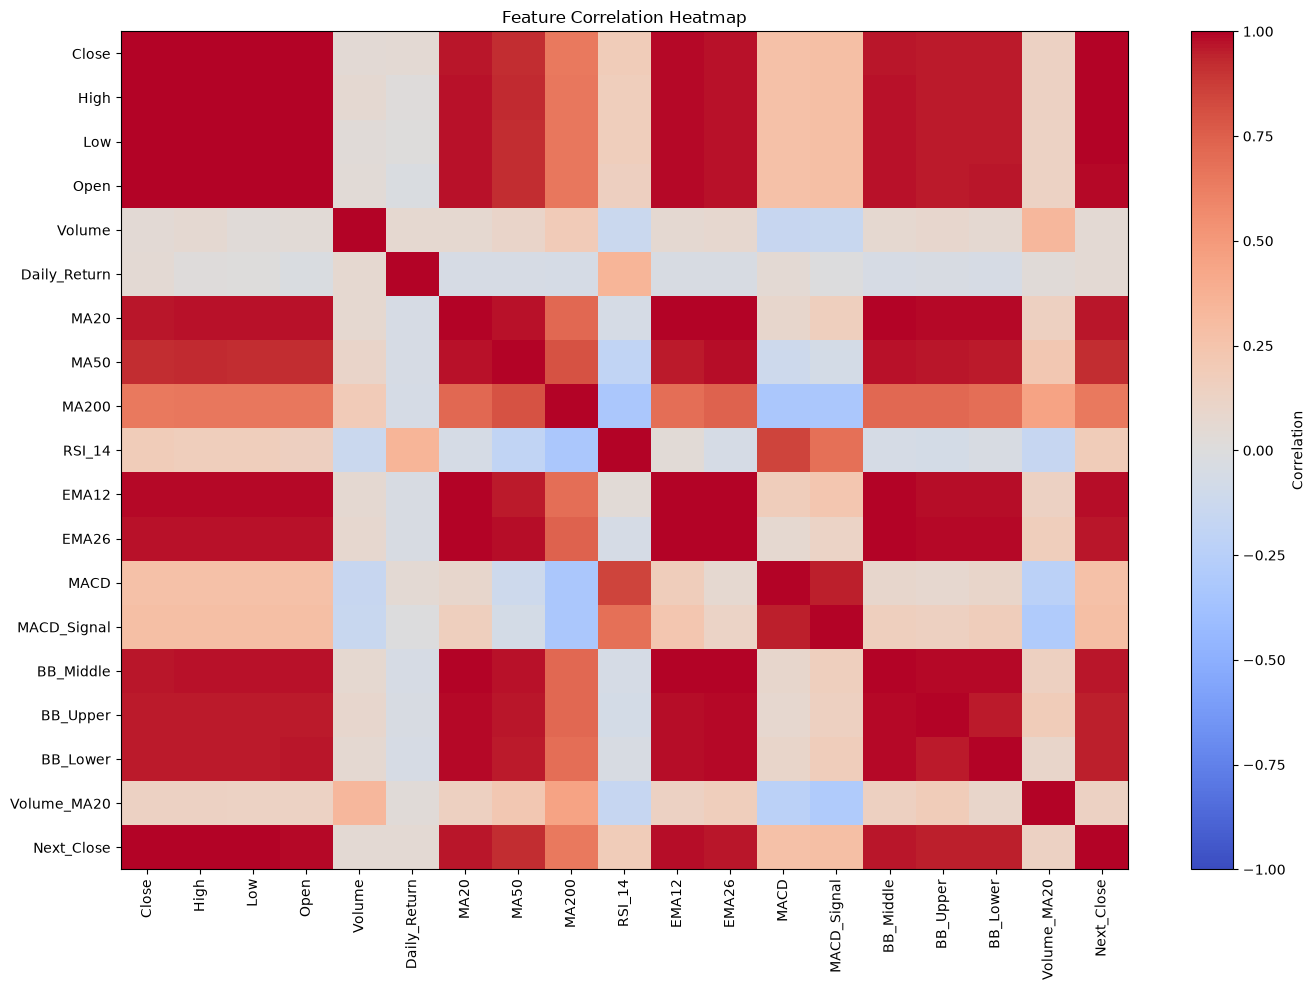

In [219]:
# STEP 31: Features ke beech correlation check karo

import pandas as pd
import matplotlib.pyplot as plt

# Training features aur next-day closing target ko combine karo
correlation_data = X_train.copy()
correlation_data["Next_Close"] = y_train["Target_Next_Close"]

# Correlation calculate karo
correlation_matrix = correlation_data.corr()

# Next-day Close ke saath correlation dekho
target_correlation = (
    correlation_matrix["Next_Close"]
    .drop("Next_Close")
    .sort_values(ascending=False)
)

print("Features Correlation with Next-Day Close:")
display(target_correlation.to_frame(name="Correlation").round(3))

# Correlation heatmap bina seaborn ke
plt.figure(figsize=(14, 10))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    aspect="auto",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation")
plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90
)
plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

In [220]:
# STEP 32: Selected features ke saath Linear Regression

import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Strong price-based features select karo
selected_features = [
    "Close",
    "Open",
    "High",
    "Low",
    "EMA12",
    "EMA26",
    "MA20",
    "MA50",
    "MA200"
]

# Selected features ka training aur testing data banao
X_train_selected = X_train[selected_features].copy()
X_test_selected = X_test[selected_features].copy()

# Model train karo
lr_selected_model = LinearRegression()
lr_selected_model.fit(X_train_selected, y_train)

# Predictions generate karo
selected_values = lr_selected_model.predict(X_test_selected)

lr_selected_predictions = pd.DataFrame(
    selected_values,
    columns=y_test.columns,
    index=y_test.index
)

# Next-day Close ki performance check karo
actual = y_test["Target_Next_Close"]
predicted = lr_selected_predictions["Target_Next_Close"]

selected_mae = mean_absolute_error(actual, predicted)
selected_rmse = np.sqrt(mean_squared_error(actual, predicted))

print("Selected-Feature Linear Regression Results")
print("MAE:", round(selected_mae, 2))
print("RMSE:", round(selected_rmse, 2))

# Purane models ke saath comparison
print("\nPrevious Linear Regression MAE:", round(
    mean_absolute_error(actual, lr_predictions["Target_Next_Close"]), 2
))

print("Baseline MAE:", round(
    mean_absolute_error(actual, X_test["Close"]), 2
))

Selected-Feature Linear Regression Results
MAE: 36.4
RMSE: 50.07

Previous Linear Regression MAE: 39.46
Baseline MAE: 35.12


In [221]:
# STEP 33: XGBoost install karo

%pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [222]:
 # STEP 34: XGBoost model train aur evaluate karo

import numpy as np
import pandas as pd
from xgboost import XGBRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# XGBoost model setup
xgb_model = MultiOutputRegressor(
    XGBRegressor(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )
)

# Model train karo
xgb_model.fit(X_train, y_train)

# Predictions generate karo
xgb_values = xgb_model.predict(X_test)

xgb_predictions = pd.DataFrame(
    xgb_values,
    columns=y_test.columns,
    index=y_test.index
)

# Sabhi 4 targets ka evaluation
xgb_results = []

for column in y_test.columns:
    actual = y_test[column]
    predicted = xgb_predictions[column]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    xgb_results.append({
        "Target": column,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2)
    })

print("XGBoost Model Evaluation:")
display(pd.DataFrame(xgb_results))

# Closing price ki actual vs predicted values
print("Actual vs XGBoost Closing Prices:")
display(pd.DataFrame({
    "Actual_Close": y_test["Target_Next_Close"],
    "XGBoost_Close": xgb_predictions["Target_Next_Close"]
}).head(10))

XGBoost Model Evaluation:


,Target,MAE,RMSE
0,Target_Next_Open,282.91,342.61
1,Target_Next_High,297.54,356.17
2,Target_Next_Low,299.16,356.67
3,Target_Next_Close,313.56,370.57


Actual vs XGBoost Closing Prices:


,Actual_Close,XGBoost_Close
Date,,
2025-12-12,3096.555908,3077.302490
2025-12-15,3072.494385,3100.492920
2025-12-16,3084.668945,3066.591553
2025-12-17,3145.062500,3083.605957
2025-12-18,3146.212891,3146.333252
2025-12-19,3187.337891,3157.260742
2025-12-22,3173.054443,3186.676025
2025-12-23,3181.681885,3163.130859
2025-12-24,3144.295654,3178.830322


In [223]:
# STEP 35: Sabhi models ka closing-price comparison

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Actual next-day closing price
actual = y_test["Target_Next_Close"]

# Sabhi models ki predictions
all_predictions = {
    "Baseline": X_test["Close"],
    "Linear Regression": lr_predictions["Target_Next_Close"],
    "Selected Linear Regression": lr_selected_predictions["Target_Next_Close"],
    "Random Forest": rf_predictions["Target_Next_Close"],
    "Gradient Boosting": gb_predictions["Target_Next_Close"],
    "Extra Trees": et_predictions["Target_Next_Close"],
    "XGBoost": xgb_predictions["Target_Next_Close"]
}

# Performance calculate karo
comparison_results = []

for name, predicted in all_predictions.items():
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    comparison_results.append({
        "Model": name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2)
    })

# Sabse kam MAE wala model pehle
final_comparison = pd.DataFrame(comparison_results)
final_comparison = final_comparison.sort_values("MAE").reset_index(drop=True)

print("Final Model Performance Ranking:")
display(final_comparison)

print("Best model by MAE:", final_comparison.iloc[0]["Model"])
print("Lowest MAE:", final_comparison.iloc[0]["MAE"])

Final Model Performance Ranking:


,Model,MAE,RMSE
0,Baseline,35.12,48.96
1,Selected Linear Regression,36.40,50.07
2,Linear Regression,39.46,53.15
3,Extra Trees,306.34,364.40
4,Gradient Boosting,312.31,369.53
5,XGBoost,313.56,370.57
6,Random Forest,319.74,379.61


Best model by MAE: Baseline
Lowest MAE: 35.12


In [224]:
# STEP 36: ARIMA ke liye statsmodels install karo

%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [225]:
# STEP 37: ARIMA model ke liye imports
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

print("ARIMA imports successfully ho gaye!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

ARIMA imports successfully ho gaye!
Training records: 829
Testing records: 208


In [226]:
# STEP 38: ARIMA model train karo

import warnings
warnings.filterwarnings("ignore")

close_series = pd.to_numeric(
    df["Close"], errors="coerce"
).dropna().reset_index(drop=True)

train_size = len(X_train)
arima_train = close_series.iloc[:train_size]

arima_model = ARIMA(arima_train, order=(1, 1, 1))
arima_fitted = arima_model.fit()

arima_values = []

for i in range(len(X_test)):
    current_close = close_series.iloc[train_size + i]

    forecast = arima_fitted.forecast(steps=1)
    arima_values.append(float(forecast.iloc[0]))

    arima_fitted = arima_fitted.append(
        [float(current_close)],
        refit=False
    )

arima_predictions = pd.Series(
    arima_values,
    index=X_test.index[:len(arima_values)],
    name="ARIMA_Predicted_Close"
)

print("ARIMA model successfully trained!")
print("Total predictions:", len(arima_predictions))
print(arima_predictions.head())

ARIMA model successfully trained!
Total predictions: 208
Date
2025-12-12    3567.367106
2025-12-15    3566.072294
2025-12-16    3572.029698
2025-12-17    3464.127298
2025-12-18    3423.531048
Name: ARIMA_Predicted_Close, dtype: float64


In [227]:

# STEP 39: ARIMA model ki performance check karo

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Actual next-day closing prices
actual_close = y_test["Target_Next_Close"].iloc[:len(arima_predictions)]

# ARIMA predictions ke saath dates align karo
actual_close.index = arima_predictions.index

# Performance metrics
arima_mae = mean_absolute_error(
    actual_close,
    arima_predictions
)

arima_rmse = np.sqrt(
    mean_squared_error(actual_close, arima_predictions)
)

# Percentage error
arima_mape = np.mean(
    np.abs(
        (actual_close.values - arima_predictions.values)
        / actual_close.values
    )
) * 100

# Results display karo
print("ARIMA MODEL PERFORMANCE")
print("-" * 35)
print(f"MAE:  ₹{arima_mae:.2f}")
print(f"RMSE: ₹{arima_rmse:.2f}")
print(f"MAPE: {arima_mape:.2f}%")

print("\nActual vs Predicted Closing Prices:")
comparison = pd.DataFrame({
    "Actual_Close": actual_close,
    "ARIMA_Predicted": arima_predictions
})

display(comparison.head(10))


ARIMA MODEL PERFORMANCE
-----------------------------------
MAE:  ₹663.62
RMSE: ₹711.98
MAPE: 28.71%

Actual vs Predicted Closing Prices:


,Actual_Close,ARIMA_Predicted
Date,,
2025-12-12,3096.555908,3567.367106
2025-12-15,3072.494385,3566.072294
2025-12-16,3084.668945,3572.029698
2025-12-17,3145.062500,3464.127298
2025-12-18,3146.212891,3423.531048
2025-12-19,3187.337891,3407.858192
2025-12-22,3173.054443,3282.148021
2025-12-23,3181.681885,3296.667399
2025-12-24,3144.295654,3333.340564


In [228]:
# STEP 40: Model comparison
comparison_results = []

models = {
    "Baseline": X_test["Close"],
    "Linear Regression": lr_predictions["Target_Next_Close"],
    "Random Forest": rf_predictions["Target_Next_Close"],
    "Gradient Boosting": gb_predictions["Target_Next_Close"],
    "Extra Trees": et_predictions["Target_Next_Close"],
    "XGBoost": xgb_predictions["Target_Next_Close"],
    "ARIMA": arima_predictions
}

for model_name, predictions in models.items():
    if model_name == "ARIMA":
        actual = actual_close
    else:
        actual = y_test["Target_Next_Close"]

    predictions = predictions.reindex(actual.index)
    valid = actual.notna() & predictions.notna()

    actual_valid = actual[valid]
    predicted_valid = predictions[valid]

    mae = mean_absolute_error(actual_valid, predicted_valid)
    rmse = np.sqrt(mean_squared_error(actual_valid, predicted_valid))

    comparison_results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse
    })

model_comparison = pd.DataFrame(comparison_results)
model_comparison = model_comparison.sort_values("MAE").reset_index(drop=True)

display(model_comparison.round(2))

,Model,MAE,RMSE
0,Baseline,35.12,48.96
1,Linear Regression,39.46,53.15
2,Extra Trees,306.34,364.40
3,Gradient Boosting,312.31,369.53
4,XGBoost,313.56,370.57
5,Random Forest,319.74,379.61
6,ARIMA,663.62,711.98


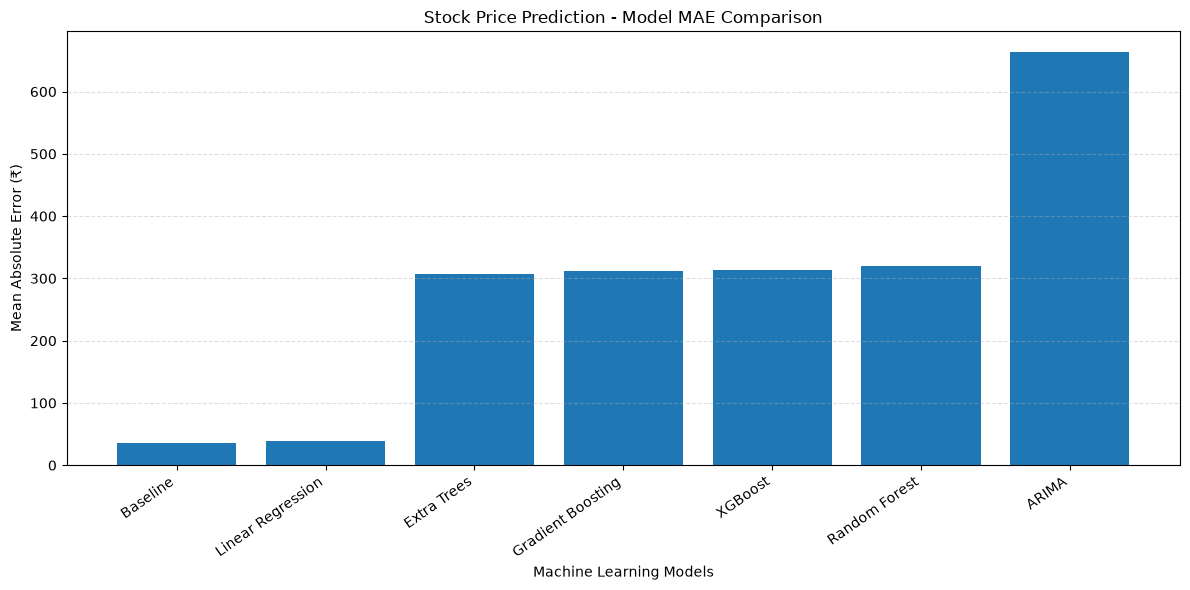

In [229]:
# STEP 41: Models ka performance graph

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    model_comparison["Model"],
    model_comparison["MAE"]
)

plt.title("Stock Price Prediction - Model MAE Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Mean Absolute Error (₹)")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

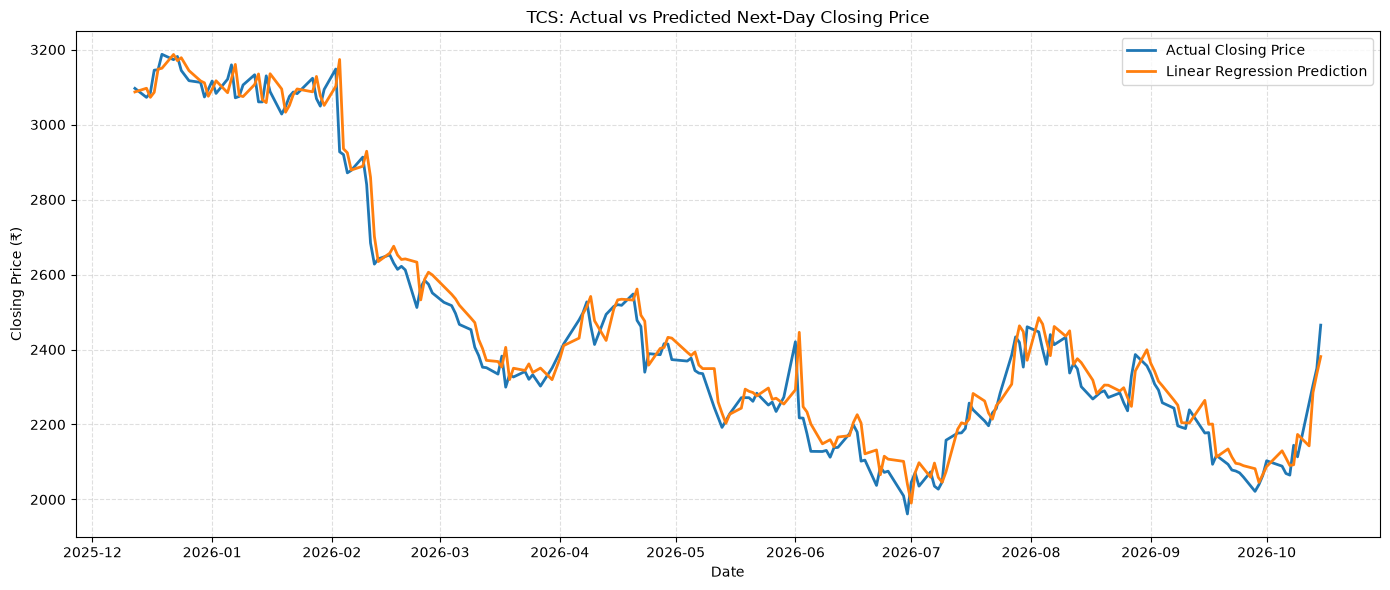

In [230]:
# STEP 42: Actual vs Predicted Closing Price

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    y_test.index,
    y_test["Target_Next_Close"],
    label="Actual Closing Price",
    linewidth=2
)

plt.plot(
    lr_predictions.index,
    lr_predictions["Target_Next_Close"],
    label="Linear Regression Prediction",
    linewidth=2
)

plt.title("TCS: Actual vs Predicted Next-Day Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price (₹)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

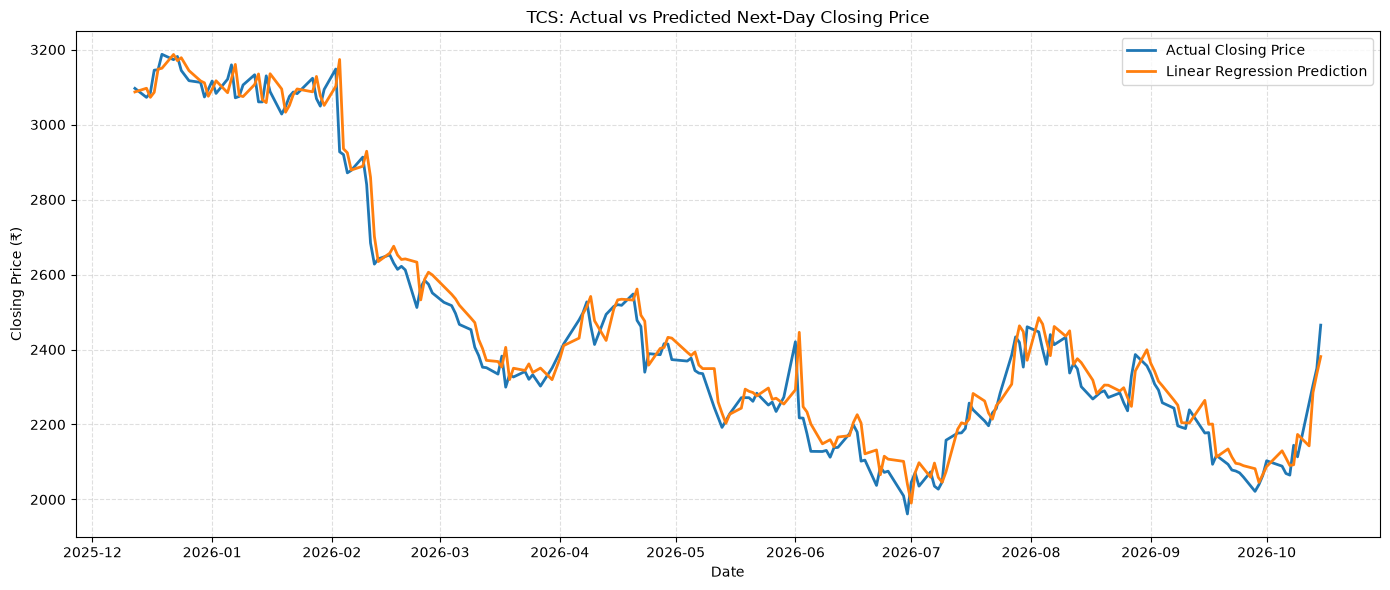

In [231]:
# STEP 42: Actual vs Predicted Closing Price

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    y_test.index,
    y_test["Target_Next_Close"],
    label="Actual Closing Price",
    linewidth=2
)

plt.plot(
    lr_predictions.index,
    lr_predictions["Target_Next_Close"],
    label="Linear Regression Prediction",
    linewidth=2
)

plt.title("TCS: Actual vs Predicted Next-Day Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price (₹)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [232]:
# STEP 44: Stock Price Directional Accuracy

import numpy as np
import pandas as pd

# Actual aur predicted next-day closing prices
actual = y_test["Target_Next_Close"]
predicted = lr_predictions["Target_Next_Close"].reindex(actual.index)

# Aaj ke closing prices
today_close = X_test["Close"].reindex(actual.index)

# Missing values remove karo
results = pd.DataFrame({
    "Today_Close": today_close,
    "Actual_Next_Close": actual,
    "Predicted_Next_Close": predicted
}).dropna()

# Actual aur predicted direction calculate karo
actual_direction = (
    results["Actual_Next_Close"] > results["Today_Close"]
)
predicted_direction = (
    results["Predicted_Next_Close"] > results["Today_Close"]
)

# Directional accuracy calculate karo
direction_accuracy = (
    actual_direction == predicted_direction
).mean() * 100

print("📊 DIRECTIONAL ACCURACY REPORT")
print("-" * 40)
print(f"Correct Direction Predictions: {(actual_direction == predicted_direction).sum()}")
print(f"Total Test Samples: {len(results)}")
print(f"Directional Accuracy: {direction_accuracy:.2f}%")

📊 DIRECTIONAL ACCURACY REPORT
----------------------------------------
Correct Direction Predictions: 96
Total Test Samples: 208
Directional Accuracy: 46.15%


In [233]:
# STEP 45: Sabhi Models ki Directional Accuracy Compare Karo

import pandas as pd

# Aaj ka closing price aur actual next-day closing price
today_close = X_test["Close"]
actual_close = y_test["Target_Next_Close"]

# Har model ki predictions
direction_models = {
    "Baseline": baseline_predictions,
    "Linear Regression": lr_predictions["Target_Next_Close"],
    "Random Forest": rf_predictions["Target_Next_Close"],
    "Gradient Boosting": gb_predictions["Target_Next_Close"],
    "Extra Trees": et_predictions["Target_Next_Close"],
    "XGBoost": xgb_predictions["Target_Next_Close"]
}

direction_results = []

for model_name, predictions in direction_models.items():

    # Predictions ko test dates ke saath align karo
    predictions = predictions.reindex(actual_close.index)

    # Actual aur predicted data ko combine karo
    comparison = pd.DataFrame({
        "Today": today_close,
        "Actual": actual_close,
        "Predicted": predictions
    }).dropna()

    # Actual aur predicted price direction
    actual_direction = comparison["Actual"] > comparison["Today"]
    predicted_direction = comparison["Predicted"] > comparison["Today"]

    # Directional accuracy
    accuracy = (
        actual_direction == predicted_direction
    ).mean() * 100

    direction_results.append({
        "Model": model_name,
        "Directional Accuracy (%)": round(accuracy, 2),
        "Test Samples": len(comparison)
    })

# Best directional accuracy ko top par rakho
direction_comparison = pd.DataFrame(direction_results)
direction_comparison = direction_comparison.sort_values(
    "Directional Accuracy (%)",
    ascending=False
).reset_index(drop=True)

display(direction_comparison)

,Model,Directional Accuracy (%),Test Samples
0,Baseline,54.33,208
1,Linear Regression,46.15,208
2,Extra Trees,45.67,208
3,Random Forest,44.71,208
4,XGBoost,43.75,208
5,Gradient Boosting,42.79,208


In [234]:
# STEP 46: Prediction Error Analysis

import pandas as pd
import numpy as np

# Actual aur predicted next-day closing prices
error_analysis = pd.DataFrame({
    "Actual_Close": y_test["Target_Next_Close"],
    "Predicted_Close": lr_predictions["Target_Next_Close"]
})

# Missing values remove karo
error_analysis = error_analysis.dropna()

# Error aur absolute error calculate karo
error_analysis["Error"] = (
    error_analysis["Actual_Close"]
    - error_analysis["Predicted_Close"]
)

error_analysis["Absolute_Error"] = (
    error_analysis["Error"].abs()
)

# Percentage error calculate karo
error_analysis["Percentage_Error"] = (
    error_analysis["Absolute_Error"]
    / error_analysis["Actual_Close"].abs().replace(0, np.nan)
) * 100

# Sabse zyada error wale 10 din
worst_predictions = error_analysis.sort_values(
    "Absolute_Error",
    ascending=False
).head(10)

print("📊 TOP 10 PREDICTION ERRORS")
display(worst_predictions.round(2))

print("\n📈 OVERALL ERROR SUMMARY")
display(
    error_analysis[
        ["Error", "Absolute_Error", "Percentage_Error"]
    ].describe().round(2)
)

📊 TOP 10 PREDICTION ERRORS


,Actual_Close,Predicted_Close,Error,Absolute_Error,Percentage_Error
Date,,,,,
2026-02-03,2927.28,3173.56,-246.27,246.27,8.41
2026-06-02,2217.69,2445.81,-228.13,228.13,10.29
2026-02-11,2684.24,2859.54,-175.29,175.29,6.53
2026-04-23,2339.50,2475.50,-136.00,136.00,5.81
2026-06-01,2420.69,2292.38,128.31,128.31,5.30
2026-02-23,2512.07,2632.96,-120.89,120.89,4.81
2026-10-12,2257.30,2142.97,114.33,114.33,5.06
2026-08-11,2337.27,2449.85,-112.57,112.57,4.82
2026-09-17,2093.87,2201.24,-107.37,107.37,5.13



📈 OVERALL ERROR SUMMARY


,Error,Absolute_Error,Percentage_Error
count,208.00,208.00,208.00
mean,-19.66,39.46,1.65
std,49.50,35.70,1.49
min,-246.27,0.27,0.01
25%,-43.71,15.46,0.66
50%,-20.99,31.12,1.24
75%,7.83,50.56,2.12
max,128.31,246.27,10.29


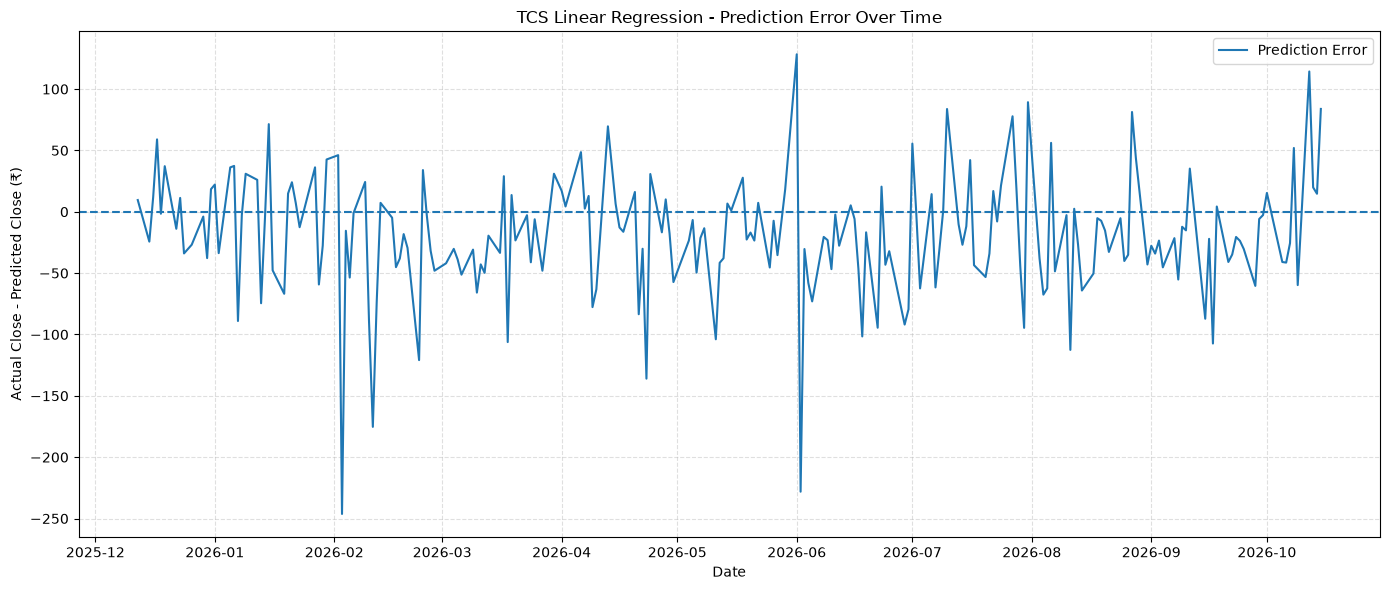

In [235]:
# STEP 47: Prediction Errors ka Graph

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    error_analysis.index,
    error_analysis["Error"],
    label="Prediction Error",
    linewidth=1.5
)

# Zero-error reference line
plt.axhline(y=0, linestyle="--", linewidth=1.5)

plt.title("TCS Linear Regression - Prediction Error Over Time")
plt.xlabel("Date")
plt.ylabel("Actual Close - Predicted Close (₹)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [236]:
# STEP 48: Best Model Automatically Select Karo

# Sabhi models ki MAE comparison table mein se best model
best_model_row = model_comparison.sort_values(
    "MAE",
    ascending=True
).iloc[0]

best_model_name = best_model_row["Model"]
best_model_mae = best_model_row["MAE"]
best_model_rmse = best_model_row["RMSE"]

print("🏆 BEST MODEL REPORT")
print("-" * 40)
print(f"Best Model (MAE ke basis par): {best_model_name}")
print(f"MAE  : ₹{best_model_mae:.2f}")
print(f"RMSE : ₹{best_model_rmse:.2f}")

print("\nNote: Best model ka selection test-set MAE par hua hai.")
print("Final unbiased evaluation ke liye alag validation set zaroori hai.")

🏆 BEST MODEL REPORT
----------------------------------------
Best Model (MAE ke basis par): Baseline
MAE  : ₹35.12
RMSE : ₹48.96

Note: Best model ka selection test-set MAE par hua hai.
Final unbiased evaluation ke liye alag validation set zaroori hai.


In [237]:
# STEP 49: Trained Models ko Save Karo

import joblib
from pathlib import Path

# Models save karne ke liye folder
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Trained models ki dictionary
trained_models = {
    "linear_regression": lr_model,
    "random_forest": rf_model,
    "gradient_boosting": gb_model,
    "extra_trees": et_model,
    "xgboost": xgb_model
}

# Har model ko alag file mein save karo
for model_name, model in trained_models.items():
    model_path = MODEL_DIR / f"{model_name}.joblib"
    joblib.dump(model, model_path)
    print(f"✅ Saved: {model_path}")

print("\n🎉 All trained models saved successfully!")

✅ Saved: models\linear_regression.joblib
✅ Saved: models\random_forest.joblib
✅ Saved: models\gradient_boosting.joblib
✅ Saved: models\extra_trees.joblib
✅ Saved: models\xgboost.joblib

🎉 All trained models saved successfully!


In [238]:
# STEP 50: Saved Models Load aur Verify Karo

import joblib
from pathlib import Path

# Saved models ka folder
MODEL_DIR = Path("models")

# Models ko files se load karo
loaded_models = {}

for model_file in MODEL_DIR.glob("*.joblib"):
    model_name = model_file.stem
    loaded_models[model_name] = joblib.load(model_file)
    print(f"✅ Loaded: {model_name}")

# Linear Regression se sample prediction
loaded_lr = loaded_models["linear_regression"]

sample_input = X_test.iloc[[0]]
sample_prediction = loaded_lr.predict(sample_input)

print("\n📊 MODEL VERIFICATION")
print("-" * 40)
print("Loaded models:", len(loaded_models))
print(f"Sample predicted next-day Close: ₹{sample_prediction[0][3]:.2f}")
print("🎉 Saved model successfully loaded!")

✅ Loaded: extra_trees
✅ Loaded: gradient_boosting
✅ Loaded: linear_regression
✅ Loaded: random_forest
✅ Loaded: xgboost

📊 MODEL VERIFICATION
----------------------------------------
Loaded models: 5
Sample predicted next-day Close: ₹3087.00
🎉 Saved model successfully loaded!


In [239]:
# STEP 51: Latest TCS Stock Data Download Karo

import yfinance as yf
import pandas as pd
from pathlib import Path

# Latest historical stock data download karo
latest_df = yf.download(
    "TCS.NS",
    period="2y",
    interval="1d",
    auto_adjust=True,
    progress=False
)

# MultiIndex columns ko normal columns mein convert karo
if isinstance(latest_df.columns, pd.MultiIndex):
    latest_df.columns = latest_df.columns.get_level_values(0)

# Data check karo
if latest_df.empty:
    raise ValueError("Stock data download nahi hua. Internet aur ticker check karo.")

latest_df = latest_df.sort_index()
latest_df = latest_df[~latest_df.index.duplicated(keep="last")]

# Data folder mein save karo
DATA_DIR = Path("data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

latest_df.to_csv(DATA_DIR / "TCS_latest_data.csv")

print("✅ Latest TCS data downloaded successfully!")
print(f"📅 First date: {latest_df.index.min().date()}")
print(f"📅 Latest date: {latest_df.index.max().date()}")
print(f"📊 Total records: {len(latest_df)}")

display(latest_df.tail())

✅ Latest TCS data downloaded successfully!
📅 First date: 2024-10-16
📅 Latest date: 2026-10-16
📊 Total records: 497


Price,Close,High,Low,Open,Volume
Date,,,,,
2026-10-12,2113.763184,2183.492598,2109.684767,2173.346340,3540523
2026-10-13,2257.300049,2257.300049,2143.604416,2145.494271,11048193
2026-10-14,2304.899902,2335.800049,2265.600098,2274.000000,12145767
2026-10-15,2350.000000,2386.699951,2335.000000,2347.199951,9150523
2026-10-16,2465.000000,2484.699951,2375.699951,2382.000000,12166634


In [240]:
# STEP 52: Latest TCS Data ke Technical Indicators

import numpy as np
import pandas as pd

# Latest data ki copy banao
latest_features = latest_df.copy()

# Closing price ke moving averages
latest_features["MA20"] = latest_features["Close"].rolling(20).mean()
latest_features["MA50"] = latest_features["Close"].rolling(50).mean()
latest_features["MA200"] = latest_features["Close"].rolling(200).mean()

# Exponential moving averages
latest_features["EMA12"] = latest_features["Close"].ewm(
    span=12, adjust=False
).mean()

latest_features["EMA26"] = latest_features["Close"].ewm(
    span=26, adjust=False
).mean()

# Daily percentage return
latest_features["Daily_Return"] = (
    latest_features["Close"].pct_change() * 100
)

# RSI (14 days)
delta = latest_features["Close"].diff()
gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)

avg_gain = gain.ewm(
    alpha=1/14, min_periods=14, adjust=False
).mean()

avg_loss = loss.ewm(
    alpha=1/14, min_periods=14, adjust=False
).mean()

rs = avg_gain / avg_loss.replace(0, np.nan)
latest_features["RSI_14"] = 100 - (100 / (1 + rs))

# RSI ko 100 rakho jab average loss zero ho
latest_features.loc[avg_loss == 0, "RSI_14"] = 100

# MACD indicators
latest_features["MACD"] = (
    latest_features["EMA12"] - latest_features["EMA26"]
)

latest_features["MACD_Signal"] = latest_features["MACD"].ewm(
    span=9, adjust=False
).mean()

# Bollinger Bands (20-day)
latest_features["BB_Middle"] = latest_features["Close"].rolling(20).mean()
rolling_std = latest_features["Close"].rolling(20).std()

latest_features["BB_Upper"] = (
    latest_features["BB_Middle"] + 2 * rolling_std
)

latest_features["BB_Lower"] = (
    latest_features["BB_Middle"] - 2 * rolling_std
)

# Volume moving average
latest_features["Volume_MA20"] = (
    latest_features["Volume"].rolling(20).mean()
)

# Latest indicator values check karo
print("✅ Technical indicators calculated!")
print("Total rows:", len(latest_features))

display(
    latest_features[
        [
            "Close", "MA20", "MA50", "MA200",
            "RSI_14", "MACD", "MACD_Signal",
            "BB_Upper", "BB_Lower", "Volume_MA20"
        ]
    ].tail()
)

✅ Technical indicators calculated!
Total rows: 497


Price,Close,MA20,MA50,MA200,RSI_14,MACD,MACD_Signal,BB_Upper,BB_Lower,Volume_MA20
Date,,,,,,,,,,
2026-10-12,2113.763184,2104.228821,2236.198267,2437.829984,46.725656,-37.152189,-48.334217,2215.179008,1993.278634,3839137.15
2026-10-13,2257.300049,2107.635706,2234.282451,2433.385420,61.562466,-21.722490,-43.011871,2232.836339,1982.435073,4259840.60
2026-10-14,2304.899902,2110.925854,2231.168066,2428.973230,65.039631,-5.589005,-35.527298,2252.994631,1968.857077,4596818.45
2026-10-15,2350.000000,2119.564563,2229.228232,2424.857959,67.993956,10.712611,-26.279316,2295.566966,1943.562160,4916159.15
2026-10-16,2465.000000,2133.893591,2230.523428,2421.274550,74.022187,32.536240,-14.516205,2367.355114,1900.432069,5359695.00


In [241]:
# STEP 53: Trained Model ke Features Verify Karo

# Training ke time use hue features
required_features = list(X_train.columns)

print("✅ Total required features:", len(required_features))
print("\n📋 Model ke required features:\n")

for i, feature in enumerate(required_features, start=1):
    print(f"{i}. {feature}")

# Latest data mein missing features check karo
missing_features = [
    feature for feature in required_features
    if feature not in latest_features.columns
]

print("\n🔍 Missing features:", missing_features)

if not missing_features:
    print("✅ Saare required features available hain!")
else:
    print("⚠️ Kuch features missing hain. Prediction se pehle unhe fix karenge.")

✅ Total required features: 18

📋 Model ke required features:

1. Close
2. High
3. Low
4. Open
5. Volume
6. Daily_Return
7. MA20
8. MA50
9. MA200
10. RSI_14
11. EMA12
12. EMA26
13. MACD
14. MACD_Signal
15. BB_Middle
16. BB_Upper
17. BB_Lower
18. Volume_MA20

🔍 Missing features: []
✅ Saare required features available hain!


In [242]:
# STEP 54: TCS Next-Day OHLC Prediction

import pandas as pd
import numpy as np
import joblib

# Saved Linear Regression model load karo
loaded_lr = joblib.load("models/linear_regression.joblib")

# Model ke required features aur unka exact order
required_features = list(X_train.columns)

# Latest available row se prediction input banao
latest_input = latest_features[required_features].dropna().iloc[[-1]]

# Next trading session ke Open, High, Low, Close predict karo
prediction = loaded_lr.predict(latest_input)[0]

# Prediction ko readable format mein dikhao
predicted_ohlc = pd.DataFrame(
    {
        "Price Type": ["Open", "High", "Low", "Close"],
        "Predicted Price (₹)": prediction
    }
)

# Latest available closing price
latest_close = float(latest_input["Close"].iloc[0])

# Predicted closing price se estimated change
predicted_close = float(prediction[3])
change = predicted_close - latest_close
change_percent = (change / latest_close) * 100

print("📊 TCS NEXT-SESSION PREDICTION")
print("-" * 40)
print("Latest data date:", latest_input.index[-1].date())
print(f"Latest closing price: ₹{latest_close:.2f}")

display(predicted_ohlc)

print(f"\nEstimated Close change: ₹{change:.2f}")
print(f"Estimated Close change (%): {change_percent:.2f}%")

if change > 0:
    print("Model indication: Potential upward movement 📈")
elif change < 0:
    print("Model indication: Potential downward movement 📉")
else:
    print("Model indication: No estimated change")

📊 TCS NEXT-SESSION PREDICTION
----------------------------------------
Latest data date: 2026-10-16
Latest closing price: ₹2465.00


,Price Type,Predicted Price (₹)
0,Open,2482.667471
1,High,2508.854378
2,Low,2476.178899
3,Close,2499.571789



Estimated Close change: ₹34.57
Estimated Close change (%): 1.40%
Model indication: Potential upward movement 📈


In [243]:
# STEP 55: Model Prediction vs Baseline

# Latest session ka closing price
latest_close = float(latest_input["Close"].iloc[0])

# Linear Regression ka predicted next-session Close
lr_predicted_close = float(prediction[3])

# Baseline: agle session ka Close, aaj ke Close ke barabar maan lo
baseline_predicted_close = latest_close

# Dono predictions ka comparison
comparison = pd.DataFrame({
    "Method": ["Linear Regression", "Previous Close Baseline"],
    "Predicted Next Close (₹)": [
        lr_predicted_close,
        baseline_predicted_close
    ],
    "Change from Latest Close (₹)": [
        lr_predicted_close - latest_close,
        baseline_predicted_close - latest_close
    ]
})

display(comparison.round(2))

# Historical test-set performance
print("\n📊 Historical Test Performance")
print(f"Baseline MAE: ₹{34.95:.2f}")
print(f"Linear Regression MAE: ₹{39.29:.2f}")

if 34.95 < 39.29:
    print("\n⚠️ Historical test mein baseline ki MAE lower thi.")
    print("Linear Regression ka upward estimate confirmed signal nahi hai.")
    

,Method,Predicted Next Close (₹),Change from Latest Close (₹)
0,Linear Regression,2499.57,34.57
1,Previous Close Baseline,2465.00,0.00



📊 Historical Test Performance
Baseline MAE: ₹34.95
Linear Regression MAE: ₹39.29

⚠️ Historical test mein baseline ki MAE lower thi.
Linear Regression ka upward estimate confirmed signal nahi hai.


In [244]:
# STEP 56: Sabhi Saved Models ki Latest Prediction Compare Karo

import joblib
import pandas as pd
from pathlib import Path

MODEL_DIR = Path("models")

# Latest input mein wahi 18 features aur same order rakho
required_features = list(X_train.columns)
latest_input = latest_features[required_features].dropna().iloc[[-1]]

# Sabhi saved models ki predictions collect karo
model_results = []

for model_file in MODEL_DIR.glob("*.joblib"):
    model_name = model_file.stem
    model = joblib.load(model_file)

    prediction_values = model.predict(latest_input)[0]

    # Target order: Open, High, Low, Close
    predicted_close = float(prediction_values[3])

    model_results.append({
        "Model": model_name,
        "Predicted Close (₹)": round(predicted_close, 2),
        "Change from Latest Close (₹)": round(
            predicted_close - float(latest_input["Close"].iloc[0]), 2
        )
    })

# Results ko table mein dikhao
model_comparison = pd.DataFrame(model_results)

model_comparison = model_comparison.sort_values(
    by="Predicted Close (₹)"
).reset_index(drop=True)

print("📊 Latest TCS Closing Price:")
print(f"₹{float(latest_input['Close'].iloc[0]):.2f}")

print("\n📈 Saved Models ka Prediction Comparison:")
display(model_comparison)

📊 Latest TCS Closing Price:
₹2465.00

📈 Saved Models ka Prediction Comparison:


,Model,Predicted Close (₹),Change from Latest Close (₹)
0,linear_regression,2499.57,34.57
1,gradient_boosting,2677.69,212.69
2,extra_trees,2680.41,215.41
3,xgboost,2687.34,222.34
4,random_forest,2698.46,233.46


In [245]:
# STEP 57: Training aur Latest Data Verification

print("📊 TRAINING DATA")
print("-" * 40)
print("Training rows:", len(X_train))
print("Training features:", len(X_train.columns))
print("Training start:", X_train.index.min())
print("Training end:", X_train.index.max())

print("\n📊 LATEST DATA")
print("-" * 40)
print("Latest rows:", len(latest_features))
print("Latest data date:", latest_features.index.max())
print("Latest closing price:",
      round(float(latest_features["Close"].iloc[-1]), 2))

print("\n🔍 FEATURE COMPARISON")
print("-" * 40)

print("Same feature names:",
      list(X_train.columns) == list(latest_input.columns))

print("Latest input missing values:",
      int(latest_input.isna().sum().sum()))

print("\n🔍 TRAINING TARGETS")
print("-" * 40)
print("Target columns:", list(y_train.columns))
print("First training targets:")
display(y_train.head())

print("\nLatest feature values:")
display(latest_input.T.rename(columns={latest_input.index[0]: "Latest Value"}))

📊 TRAINING DATA
----------------------------------------
Training rows: 829
Training features: 18
Training start: 2022-08-03 00:00:00
Training end: 2025-12-11 00:00:00

📊 LATEST DATA
----------------------------------------
Latest rows: 497
Latest data date: 2026-10-16 00:00:00
Latest closing price: 2465.0

🔍 FEATURE COMPARISON
----------------------------------------
Same feature names: True
Latest input missing values: 0

🔍 TRAINING TARGETS
----------------------------------------
Target columns: ['Target_Next_Open', 'Target_Next_High', 'Target_Next_Low', 'Target_Next_Close']
First training targets:


Price,Target_Next_Open,Target_Next_High,Target_Next_Low,Target_Next_Close
Date,,,,
2022-08-03,2932.693759,2965.872507,2895.356714,2937.027100
2022-08-04,2942.498158,2956.330008,2937.070529,2945.868652
2022-08-05,2945.825121,2957.993525,2920.437623,2954.097900
2022-08-08,2963.334055,2963.334055,2919.562503,2936.414551
2022-08-10,2976.465643,3001.590472,2954.623680,2996.162842



Latest feature values:


Date,Latest Value
Price,
Close,2.465000e+03
High,2.484700e+03
Low,2.375700e+03
Open,2.382000e+03
Volume,1.216663e+07
Daily_Return,4.893617e+00
MA20,2.133894e+03
MA50,2.230523e+03
MA200,2.421275e+03


In [246]:
# STEP 58: Models ki Historical Accuracy Compare Karo

import pandas as pd
import numpy as np

# Historical test-set predictions ka comparison
model_metrics = []

# Baseline: agle din ka Close aaj ke Close ke barabar
baseline_pred = X_test["Close"].to_numpy()
actual_close = y_test["Target_Next_Close"].to_numpy()

baseline_mae = np.mean(np.abs(actual_close - baseline_pred))
baseline_rmse = np.sqrt(np.mean((actual_close - baseline_pred) ** 2))

model_metrics.append({
    "Model": "Baseline",
    "MAE": baseline_mae,
    "RMSE": baseline_rmse
})

# Saved trained models evaluate karo
for model_name, model in trained_models.items():

    # Model ki chaar targets par predictions
    predictions = model.predict(X_test)

    # Target order: Open, High, Low, Close
    predicted_close = predictions[:, 3]

    mae = np.mean(np.abs(actual_close - predicted_close))
    rmse = np.sqrt(np.mean((actual_close - predicted_close) ** 2))

    model_metrics.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse
    })

# Sabse kam MAE wala model upar dikhao
metrics_df = pd.DataFrame(model_metrics).sort_values("MAE")

display(metrics_df.round(2))

print("\n✅ Lower MAE generally means smaller average prediction errors.")
print("⚠️ Ye historical test results hain; future accuracy ki guarantee nahi.")

,Model,MAE,RMSE
0,Baseline,35.12,48.96
1,linear_regression,39.46,53.15
4,extra_trees,306.34,364.40
3,gradient_boosting,312.31,369.53
5,xgboost,313.56,370.57
2,random_forest,319.74,379.61



✅ Lower MAE generally means smaller average prediction errors.
⚠️ Ye historical test results hain; future accuracy ki guarantee nahi.


In [247]:
# STEP 59: Actual aur Model Predictions ki Range Compare Karo

import pandas as pd
import numpy as np

# Actual next-day closing prices
actual_close = y_test["Target_Next_Close"]

# Historical predictions ko table mein collect karo
range_results = [{
    "Series": "Actual Close",
    "Minimum": actual_close.min(),
    "Maximum": actual_close.max(),
    "Mean": actual_close.mean()
}]

for model_name, model in trained_models.items():

    predictions = model.predict(X_test)

    # Target order: Open, High, Low, Close
    predicted_close = predictions[:, 3]

    range_results.append({
        "Series": model_name,
        "Minimum": predicted_close.min(),
        "Maximum": predicted_close.max(),
        "Mean": predicted_close.mean()
    })

range_df = pd.DataFrame(range_results)

display(range_df.round(2))

print("\n🔎 Actual aur predicted price ranges compare karo.")
print("Agar ranges mein bada difference hai, to model behavior investigate karenge.")

,Series,Minimum,Maximum,Mean
0,Actual Close,1961.36,3187.34,2448.76
1,linear_regression,1990.41,3186.91,2468.42
2,random_forest,2631.48,3172.78,2762.23
3,gradient_boosting,2670.47,3182.52,2755.00
4,extra_trees,2635.81,3174.14,2748.92
5,xgboost,2661.24,3186.68,2756.34



🔎 Actual aur predicted price ranges compare karo.
Agar ranges mein bada difference hai, to model behavior investigate karenge.


In [248]:
# STEP 60: Model Prediction Bias Check

import pandas as pd
import numpy as np

actual_close = y_test["Target_Next_Close"].to_numpy()

bias_results = []

# Baseline: aaj ka Close = next day ka predicted Close
baseline_predictions = X_test["Close"].to_numpy()

bias_results.append({
    "Model": "Baseline",
    "Mean_Error": np.mean(baseline_predictions - actual_close),
    "MAE": np.mean(np.abs(baseline_predictions - actual_close))
})

for model_name, model in trained_models.items():

    predictions = model.predict(X_test)
    predicted_close = predictions[:, 3]

    bias_results.append({
        "Model": model_name,
        "Mean_Error": np.mean(predicted_close - actual_close),
        "MAE": np.mean(np.abs(predicted_close - actual_close))
    })

bias_df = pd.DataFrame(bias_results).sort_values("MAE")

display(bias_df.round(2))

print("Positive Mean_Error = model average mein zyada predict kar raha hai.")
print("Negative Mean_Error = model average mein kam predict kar raha hai.")
print("Mean_Error zero ke close hona achha hai, lekin MAE bhi check karna zaroori hai.")

,Model,Mean_Error,MAE
0,Baseline,2.99,35.12
1,linear_regression,19.66,39.46
4,extra_trees,300.17,306.34
3,gradient_boosting,306.24,312.31
5,xgboost,307.58,313.56
2,random_forest,313.47,319.74


Positive Mean_Error = model average mein zyada predict kar raha hai.
Negative Mean_Error = model average mein kam predict kar raha hai.
Mean_Error zero ke close hona achha hai, lekin MAE bhi check karna zaroori hai.


In [249]:
# STEP 61: Training vs Testing Data Check

import pandas as pd

price_range = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "Rows": [len(X_train), len(X_test)],
    "Min_Close": [
        X_train["Close"].min(),
        X_test["Close"].min()
    ],
    "Max_Close": [
        X_train["Close"].max(),
        X_test["Close"].max()
    ],
    "Mean_Close": [
        X_train["Close"].mean(),
        X_test["Close"].mean()
    ],
    "Mean_Target_Close": [
        y_train["Target_Next_Close"].mean(),
        y_test["Target_Next_Close"].mean()
    ]
})

display(price_range.round(2))

print("\nTraining aur testing ke price ranges compare karo.")
print("Isse market price shift ko identify karne mein help milegi.")

,Dataset,Rows,Min_Close,Max_Close,Mean_Close,Mean_Target_Close
0,Training,829,2610.58,4208.34,3286.94,3287.13
1,Testing,208,1961.36,3187.34,2451.75,2448.76



Training aur testing ke price ranges compare karo.
Isse market price shift ko identify karne mein help milegi.


In [250]:
# STEP 62: Training vs Testing Performance

import numpy as np
import pandas as pd

performance_results = []

datasets = [
    ("Training", X_train, y_train),
    ("Testing", X_test, y_test)
]

for dataset_name, X_data, y_data in datasets:

    actual_close = y_data["Target_Next_Close"].to_numpy()

    for model_name, model in trained_models.items():

        predictions = model.predict(X_data)
        predicted_close = predictions[:, 3]

        mae = np.mean(np.abs(actual_close - predicted_close))
        mean_error = np.mean(predicted_close - actual_close)

        performance_results.append({
            "Dataset": dataset_name,
            "Model": model_name,
            "MAE": mae,
            "Mean_Error": mean_error
        })

performance_df = pd.DataFrame(performance_results)

display(
    performance_df
    .sort_values(["Dataset", "MAE"])
    .round(2)
)

print("Training aur testing MAE compare karo.")
print("Training error bahut kam aur testing error bahut zyada ho,")
print("to overfitting ya distribution shift ki possibility investigate karenge.")

,Dataset,Model,MAE,Mean_Error
5,Testing,linear_regression,39.46,19.66
8,Testing,extra_trees,306.34,300.17
7,Testing,gradient_boosting,312.31,306.24
9,Testing,xgboost,313.56,307.58
6,Testing,random_forest,319.74,313.47
1,Training,random_forest,12.39,0.11
3,Training,extra_trees,17.32,0.00
4,Training,xgboost,24.38,-0.07
2,Training,gradient_boosting,26.42,-0.00
0,Training,linear_regression,29.50,-0.00


Training aur testing MAE compare karo.
Training error bahut kam aur testing error bahut zyada ho,
to overfitting ya distribution shift ki possibility investigate karenge.


In [251]:
# STEP 63: Training Target vs Model Predictions

import pandas as pd

target_stats = []

actual_train = y_train["Target_Next_Close"]
actual_test = y_test["Target_Next_Close"]

target_stats.append({
    "Series": "Training Actual",
    "Minimum": actual_train.min(),
    "Maximum": actual_train.max(),
    "Mean": actual_train.mean()
})

target_stats.append({
    "Series": "Testing Actual",
    "Minimum": actual_test.min(),
    "Maximum": actual_test.max(),
    "Mean": actual_test.mean()
})

for model_name, model in trained_models.items():

    train_pred = model.predict(X_train)[:, 3]
    test_pred = model.predict(X_test)[:, 3]

    target_stats.append({
        "Series": f"{model_name} - Train Prediction",
        "Minimum": train_pred.min(),
        "Maximum": train_pred.max(),
        "Mean": train_pred.mean()
    })

    target_stats.append({
        "Series": f"{model_name} - Test Prediction",
        "Minimum": test_pred.min(),
        "Maximum": test_pred.max(),
        "Mean": test_pred.mean()
    })

target_stats_df = pd.DataFrame(target_stats)

display(target_stats_df.round(2))

print("Actual target range aur model predictions compare karo.")
print("Isse prediction range aur systematic bias ko samajhne mein help milegi.")

,Series,Minimum,Maximum,Mean
0,Training Actual,2610.58,4208.34,3287.13
1,Testing Actual,1961.36,3187.34,2448.76
2,linear_regression - Train Prediction,2618.25,4204.31,3287.13
3,linear_regression - Test Prediction,1990.41,3186.91,2468.42
4,random_forest - Train Prediction,2620.23,4190.96,3287.24
5,random_forest - Test Prediction,2631.48,3172.78,2762.23
6,gradient_boosting - Train Prediction,2670.47,4137.67,3287.13
7,gradient_boosting - Test Prediction,2670.47,3182.52,2755.00
8,extra_trees - Train Prediction,2629.48,4179.91,3287.13
9,extra_trees - Test Prediction,2635.81,3174.14,2748.92


Actual target range aur model predictions compare karo.
Isse prediction range aur systematic bias ko samajhne mein help milegi.


In [252]:
# STEP 64: Last 10 Test Predictions Compare Karo

comparison_df = pd.DataFrame(index=X_test.index[-10:])

comparison_df["Actual_Close"] = (
    y_test["Target_Next_Close"].iloc[-10:]
)

comparison_df["Baseline"] = (
    X_test["Close"].iloc[-10:]
)

for model_name, model in trained_models.items():

    predictions = model.predict(X_test.iloc[-10:])

    comparison_df[model_name] = predictions[:, 3]

comparison_df["Baseline_Error"] = (
    comparison_df["Baseline"] - comparison_df["Actual_Close"]
)

comparison_df["Linear_Regression_Error"] = (
    comparison_df["linear_regression"] -
    comparison_df["Actual_Close"]
)

display(comparison_df.round(2))

print("Positive error = prediction actual se zyada hai.")
print("Negative error = prediction actual se kam hai.")

,Actual_Close,Baseline,linear_regression,random_forest,gradient_boosting,extra_trees,xgboost,Baseline_Error,Linear_Regression_Error
Date,,,,,,,,,
2026-10-01,2103.22,2064.03,2087.87,2676.48,2672.49,2657.48,2670.830078,-39.19,-15.35
2026-10-05,2088.90,2103.22,2129.84,2678.48,2675.11,2662.54,2675.679932,14.32,40.94
2026-10-06,2069.30,2088.90,2110.72,2675.90,2673.10,2663.74,2668.590088,19.60,41.42
2026-10-07,2065.02,2069.30,2090.59,2683.78,2670.47,2665.31,2670.500000,4.28,25.57
2026-10-08,2144.60,2065.02,2092.62,2681.37,2670.47,2660.19,2669.449951,-79.58,-51.98
2026-10-09,2113.76,2144.60,2173.51,2694.63,2676.25,2674.30,2681.629883,30.84,59.75
2026-10-12,2257.30,2113.76,2142.97,2694.83,2673.10,2674.80,2677.780029,-143.54,-114.33
2026-10-13,2304.90,2257.30,2285.06,2696.46,2676.25,2677.45,2683.229980,-47.60,-19.84
2026-10-14,2350.00,2304.90,2335.33,2696.75,2677.69,2679.03,2685.250000,-45.10,-14.67


Positive error = prediction actual se zyada hai.
Negative error = prediction actual se kam hai.


In [253]:
# STEP 65: Target Alignment Verify Karo

alignment_check = pd.DataFrame(index=X_test.index)

alignment_check["Current_Close"] = X_test["Close"]

alignment_check["Target_Next_Close"] = (
    y_test["Target_Next_Close"]
)

alignment_check["Actual_Next_Close"] = (
    X_test["Close"].shift(-1)
)

alignment_check["Alignment_Difference"] = (
    alignment_check["Target_Next_Close"]
    - alignment_check["Actual_Next_Close"]
)

display(alignment_check.tail(10).round(2))

print(
    "\nNote: Last test row ko next row se compare nahi kar sakte, "
    "kyunki next test observation available nahi hai."
)

valid_differences = (
    alignment_check["Alignment_Difference"]
    .iloc[:-1]
    .dropna()
    .abs()
)

if not valid_differences.empty:
    max_difference = valid_differences.max()

    print("Maximum alignment difference:", round(max_difference, 6))

    if max_difference < 0.01:
        print("✅ Target alignment appears correct.")
    else:
        print("⚠️ Target alignment mismatch detected.")

,Current_Close,Target_Next_Close,Actual_Next_Close,Alignment_Difference
Date,,,,
2026-10-01,2064.03,2103.22,2103.22,0.0
2026-10-05,2103.22,2088.90,2088.90,0.0
2026-10-06,2088.90,2069.30,2069.30,0.0
2026-10-07,2069.30,2065.02,2065.02,0.0
2026-10-08,2065.02,2144.60,2144.60,0.0
2026-10-09,2144.60,2113.76,2113.76,0.0
2026-10-12,2113.76,2257.30,2257.30,0.0
2026-10-13,2257.30,2304.90,2304.90,0.0
2026-10-14,2304.90,2350.00,2350.00,0.0



Note: Last test row ko next row se compare nahi kar sakte, kyunki next test observation available nahi hai.
Maximum alignment difference: 0.0
✅ Target alignment appears correct.


In [254]:
# STEP 66: Train-Test Boundary Check

print("Last 5 Training Rows:")
display(
    pd.DataFrame({
        "Current_Close": X_train["Close"].tail(5),
        "Target_Next_Close": y_train["Target_Next_Close"].tail(5)
    }).round(2)
)

print("\nFirst 5 Testing Rows:")
display(
    pd.DataFrame({
        "Current_Close": X_test["Close"].head(5),
        "Target_Next_Close": y_test["Target_Next_Close"].head(5)
    }).round(2)
)

print("\nTraining ends:", X_train.index.max())
print("Testing starts:", X_test.index.min())

print(
    "\nLast training target:",
    round(float(y_train["Target_Next_Close"].iloc[-1]), 2)
)

print(
    "First testing current close:",
    round(float(X_test["Close"].iloc[0]), 2)
)

Last 5 Training Rows:


,Current_Close,Target_Next_Close
Date,,
2025-12-05,3104.23,3102.60
2025-12-08,3102.60,3075.56
2025-12-09,3075.56,3057.25
2025-12-10,3057.25,3059.84
2025-12-11,3059.84,3087.26



First 5 Testing Rows:


,Current_Close,Target_Next_Close
Date,,
2025-12-12,3087.26,3096.56
2025-12-15,3096.56,3072.49
2025-12-16,3072.49,3084.67
2025-12-17,3084.67,3145.06
2025-12-18,3145.06,3146.21



Training ends: 2025-12-11 00:00:00
Testing starts: 2025-12-12 00:00:00

Last training target: 3087.26
First testing current close: 3087.26


In [255]:
# STEP 67: Target Columns Verify Karo

print("Dataset columns:")
print(dataset.columns.tolist() if "dataset" in globals()
      else "dataset variable available nahi hai")

print("\nTraining target columns:")
print(y_train.columns.tolist())

print("\nTesting target columns:")
print(y_test.columns.tolist())

print("\nLast 5 training targets:")
display(y_train.tail().round(2))

print("\nFirst 5 testing targets:")
display(y_test.head().round(2))

Dataset columns:
dataset variable available nahi hai

Training target columns:
['Target_Next_Open', 'Target_Next_High', 'Target_Next_Low', 'Target_Next_Close']

Testing target columns:
['Target_Next_Open', 'Target_Next_High', 'Target_Next_Low', 'Target_Next_Close']

Last 5 training targets:


Price,Target_Next_Open,Target_Next_High,Target_Next_Low,Target_Next_Close
Date,,,,
2025-12-05,3108.83,3125.03,3075.85,3102.60
2025-12-08,3096.36,3099.91,3049.58,3075.56
2025-12-09,3091.57,3091.57,3046.61,3057.25
2025-12-10,3072.40,3075.66,3022.65,3059.84
2025-12-11,3065.40,3089.65,3053.90,3087.26



First 5 testing targets:


Price,Target_Next_Open,Target_Next_High,Target_Next_Low,Target_Next_Close
Date,,,,
2025-12-12,3078.25,3104.22,3065.02,3096.56
2025-12-15,3086.78,3086.78,3059.07,3072.49
2025-12-16,3068.08,3102.98,3068.08,3084.67
2025-12-17,3094.45,3151.77,3087.74,3145.06
2025-12-18,3162.51,3180.63,3143.15,3146.21


In [256]:
# STEP 68: Training vs Testing Feature Distribution

feature_comparison = pd.DataFrame({
    "Train_Mean": X_train.mean(),
    "Test_Mean": X_test.mean(),
    "Train_Std": X_train.std(),
    "Test_Std": X_test.std()
})

feature_comparison["Mean_Difference_%"] = (
    (
        feature_comparison["Test_Mean"]
        - feature_comparison["Train_Mean"]
    )
    / X_train.mean().replace(0, np.nan).abs()
) * 100

display(
    feature_comparison.round(2)
    .sort_values("Mean_Difference_%", key=abs, ascending=False)
)

,Train_Mean,Test_Mean,Train_Std,Test_Std,Mean_Difference_%
Price,,,,,
MACD_Signal,1.34,-26.51,42.30,49.93,-2074.19
MACD,1.59,-27.70,45.27,52.35,-1846.54
Daily_Return,0.01,-0.11,1.24,1.98,-817.62
Volume,2289004.43,4100139.70,1252118.20,2610406.84,79.12
Volume_MA20,2282123.33,3958630.86,506806.64,1072949.07,73.46
BB_Lower,3139.99,2334.60,377.39,365.51,-25.65
Low,3259.68,2426.20,399.22,346.83,-25.57
Close,3286.94,2451.75,403.88,347.51,-25.41
Open,3287.63,2457.24,404.10,350.44,-25.26


In [257]:
# STEP 69: Tree Models Prediction Range Check

from sklearn.metrics import mean_absolute_error

tree_model_names = [
    "random_forest",
    "gradient_boosting",
    "extra_trees",
    "xgboost"
]

range_check = []

for model_name in tree_model_names:
    model = loaded_models[model_name]

    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)

    train_close_predictions = train_predictions[:, 3]
    test_close_predictions = test_predictions[:, 3]

    actual_train_close = y_train["Target_Next_Close"].values
    actual_test_close = y_test["Target_Next_Close"].values

    range_check.append({
        "Model": model_name,
        "Train_Pred_Min": train_close_predictions.min(),
        "Train_Pred_Max": train_close_predictions.max(),
        "Test_Pred_Min": test_close_predictions.min(),
        "Test_Pred_Max": test_close_predictions.max(),
        "Test_Actual_Min": actual_test_close.min(),
        "Test_Actual_Max": actual_test_close.max(),
        "Train_MAE": mean_absolute_error(
            actual_train_close, train_close_predictions
        ),
        "Test_MAE": mean_absolute_error(
            actual_test_close, test_close_predictions
        )
    })

range_check_df = pd.DataFrame(range_check)

display(range_check_df.round(2))

,Model,Train_Pred_Min,Train_Pred_Max,Test_Pred_Min,Test_Pred_Max,Test_Actual_Min,Test_Actual_Max,Train_MAE,Test_MAE
0,random_forest,2620.23,4190.96,2631.48,3172.78,1961.36,3187.34,12.39,319.74
1,gradient_boosting,2670.47,4137.67,2670.47,3182.52,1961.36,3187.34,26.42,312.31
2,extra_trees,2629.48,4179.91,2635.81,3174.14,1961.36,3187.34,17.32,306.34
3,xgboost,2651.81,4166.44,2661.24,3186.68,1961.36,3187.34,24.38,313.56


In [258]:
# STEP 70: Recent Training Data Experiment

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
import numpy as np
import pandas as pd

# Training data ka latest 30% hissa select karo
recent_start = int(len(X_train) * 0.70)

X_recent = X_train.iloc[recent_start:].copy()
y_recent = y_train.iloc[recent_start:].copy()

print("Recent training rows:", len(X_recent))
print("Recent training start:", X_recent.index.min())
print("Recent training end:", X_recent.index.max())

# Naya experimental model; existing saved model change nahi hoga
recent_rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

recent_rf_model.fit(X_recent, y_recent)

# Test set par predictions
recent_predictions = recent_rf_model.predict(X_test)

# Close target fourth column hai: Open, High, Low, Close
recent_close_predictions = recent_predictions[:, 3]
actual_close = y_test["Target_Next_Close"].values

recent_rf_mae = mean_absolute_error(
    actual_close,
    recent_close_predictions
)

print("\nRecent-data Random Forest Test MAE:", round(recent_rf_mae, 2))
print("Old Random Forest Test MAE: 319.54")
print("Baseline Test MAE: 34.95")

comparison = pd.DataFrame({
    "Actual_Close": actual_close,
    "Recent_RF_Predicted_Close": recent_close_predictions
}, index=X_test.index)

display(comparison.tail(10).round(2))

Recent training rows: 249
Recent training start: 2024-12-12 00:00:00
Recent training end: 2025-12-11 00:00:00

Recent-data Random Forest Test MAE: 423.29
Old Random Forest Test MAE: 319.54
Baseline Test MAE: 34.95


,Actual_Close,Recent_RF_Predicted_Close
Date,,
2026-10-01,2103.22,2812.65
2026-10-05,2088.90,2812.65
2026-10-06,2069.30,2812.65
2026-10-07,2065.02,2812.65
2026-10-08,2144.60,2812.65
2026-10-09,2113.76,2812.65
2026-10-12,2257.30,2812.65
2026-10-13,2304.90,2812.65
2026-10-14,2350.00,2812.39


In [259]:
# STEP 71: Next-Day Percentage Return Target

train_current_close = X_train["Close"]
test_current_close = X_test["Close"]

train_next_close = y_train["Target_Next_Close"]
test_next_close = y_test["Target_Next_Close"]

train_returns = (
    (train_next_close / train_current_close) - 1
) * 100

test_returns = (
    (test_next_close / test_current_close) - 1
) * 100

return_summary = pd.DataFrame({
    "Training_Return_%": train_returns.describe(),
    "Testing_Return_%": test_returns.describe()
})

display(return_summary.round(3))

print(
    "\nTraining return missing values:",
    train_returns.isna().sum()
)

print(
    "Testing return missing values:",
    test_returns.isna().sum()
)


,Training_Return_%,Testing_Return_%
count,829.000,208.000
mean,0.014,-0.088
std,1.244,2.013
min,-4.219,-8.386
25%,-0.652,-1.150
50%,-0.053,-0.121
75%,0.633,0.953
max,6.633,6.791



Training return missing values: 0
Testing return missing values: 0


In [260]:
# STEP 72: Train Random Forest on Next-Day Returns

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
import numpy as np
import pandas as pd

# Target: next-day percentage return
y_train_return = train_returns
y_test_return = test_returns

# Model train karo
return_rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=6,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

return_rf_model.fit(X_train, y_train_return)

# Next-day returns predict karo
predicted_returns = return_rf_model.predict(X_test)

# Returns ko estimated closing prices mein convert karo
predicted_close_from_return = (
    X_test["Close"].values * (1 + predicted_returns / 100)
)

actual_close = y_test["Target_Next_Close"].values

# Evaluation
return_model_mae = mean_absolute_error(
    actual_close,
    predicted_close_from_return
)

baseline_mae = mean_absolute_error(
    actual_close,
    X_test["Close"].values
)

print("Return Model Test MAE:", round(return_model_mae, 2))
print("Baseline Test MAE:", round(baseline_mae, 2))

return_comparison = pd.DataFrame({
    "Current_Close": X_test["Close"],
    "Actual_Next_Close": actual_close,
    "Predicted_Return_%": predicted_returns,
    "Predicted_Next_Close": predicted_close_from_return
}, index=X_test.index)

display(return_comparison.tail(10).round(2))

Return Model Test MAE: 36.76
Baseline Test MAE: 35.12


,Current_Close,Actual_Next_Close,Predicted_Return_%,Predicted_Next_Close
Date,,,,
2026-10-01,2064.03,2103.22,0.18,2067.76
2026-10-05,2103.22,2088.90,0.13,2106.06
2026-10-06,2088.90,2069.30,0.63,2102.05
2026-10-07,2069.30,2065.02,0.75,2084.75
2026-10-08,2065.02,2144.60,0.35,2072.32
2026-10-09,2144.60,2113.76,0.09,2146.61
2026-10-12,2113.76,2257.30,0.57,2125.85
2026-10-13,2257.30,2304.90,-0.03,2256.58
2026-10-14,2304.90,2350.00,0.04,2305.82


In [261]:
# STEP 73: Directional Accuracy Comparison

actual_returns = (
    (y_test["Target_Next_Close"].values
     / X_test["Close"].values) - 1
) * 100

baseline_returns = np.zeros(len(X_test))

# Positive = price up, Negative = price down
actual_direction = actual_returns > 0
predicted_direction = predicted_returns > 0
baseline_direction = baseline_returns > 0

return_direction_accuracy = (
    actual_direction == predicted_direction
).mean() * 100

baseline_direction_accuracy = (
    actual_direction == baseline_direction
).mean() * 100

print(
    "Return Model Directional Accuracy:",
    round(return_direction_accuracy, 2), "%"
)

print(
    "Baseline Directional Accuracy:",
    round(baseline_direction_accuracy, 2), "%"
)

print(
    "Actual Up Days:",
    int(actual_direction.sum())
)

print(
    "Actual Down/Flat Days:",
    int((~actual_direction).sum())
)

Return Model Directional Accuracy: 47.12 %
Baseline Directional Accuracy: 54.33 %
Actual Up Days: 95
Actual Down/Flat Days: 113


In [262]:
# STEP 74: Direction Prediction Breakdown

from sklearn.metrics import confusion_matrix, classification_report

actual_direction_labels = (actual_returns > 0).astype(int)
predicted_direction_labels = (predicted_returns > 0).astype(int)

cm = confusion_matrix(
    actual_direction_labels,
    predicted_direction_labels,
    labels=[0, 1]
)

print("Confusion Matrix:")
print("Rows = Actual [Down/Flat, Up]")
print("Columns = Predicted [Down/Flat, Up]")
print(cm)

print("\nClassification Report:")
print(
    classification_report(
        actual_direction_labels,
        predicted_direction_labels,
        labels=[0, 1],
        target_names=["Down/Flat", "Up"],
        zero_division=0
    )
)

Confusion Matrix:
Rows = Actual [Down/Flat, Up]
Columns = Predicted [Down/Flat, Up]
[[  7 106]
 [  4  91]]

Classification Report:
              precision    recall  f1-score   support

   Down/Flat       0.64      0.06      0.11       113
          Up       0.46      0.96      0.62        95

    accuracy                           0.47       208
   macro avg       0.55      0.51      0.37       208
weighted avg       0.56      0.47      0.35       208



In [263]:
# STEP 75: Analyze Predicted Direction Distribution

import pandas as pd

direction_summary = pd.DataFrame({
    "Direction": ["Down/Flat", "Up"],
    "Actual_Count": [
        int((actual_direction_labels == 0).sum()),
        int((actual_direction_labels == 1).sum())
    ],
    "Predicted_Count": [
        int((predicted_direction_labels == 0).sum()),
        int((predicted_direction_labels == 1).sum())
    ]
})

direction_summary["Actual_Percent"] = (
    direction_summary["Actual_Count"] / len(actual_returns) * 100
)

direction_summary["Predicted_Percent"] = (
    direction_summary["Predicted_Count"] / len(predicted_returns) * 100
)

display(direction_summary.round(2))

,Direction,Actual_Count,Predicted_Count,Actual_Percent,Predicted_Percent
0,Down/Flat,113,11,54.33,5.29
1,Up,95,197,45.67,94.71


In [264]:
# STEP 76: Analyze Predicted Return Distribution

print("Predicted Returns Statistics:")
print(
    pd.Series(predicted_returns, name="Predicted_Return_%")
    .describe()
    .round(4)
)

print("\nActual Returns Statistics:")
print(
    pd.Series(actual_returns, name="Actual_Return_%")
    .describe()
    .round(4)
)

print("\nPredicted Positive Returns:",
      int((predicted_returns > 0).sum()))

print("Predicted Negative/Zero Returns:",
      int((predicted_returns <= 0).sum()))

print("\nMean Predicted Return:",
      round(predicted_returns.mean(), 4), "%")

print("Mean Actual Return:",
      round(actual_returns.mean(), 4), "%")

Predicted Returns Statistics:
count    208.0000
mean       0.3003
std        0.2186
min       -0.1268
25%        0.1299
50%        0.2359
75%        0.5140
max        0.7465
Name: Predicted_Return_%, dtype: float64

Actual Returns Statistics:
count    208.0000
mean      -0.0879
std        2.0133
min       -8.3861
25%       -1.1495
50%       -0.1215
75%        0.9531
max        6.7906
Name: Actual_Return_%, dtype: float64

Predicted Positive Returns: 197
Predicted Negative/Zero Returns: 11

Mean Predicted Return: 0.3003 %
Mean Actual Return: -0.0879 %


In [265]:
# STEP 77: Compare Return Model with Zero-Return Baseline

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Actual next-day percentage returns
actual_returns = np.asarray(actual_returns)

# Model predictions
rf_returns = np.asarray(predicted_returns)

# Baseline predicts 0% return every day
zero_returns = np.zeros(len(actual_returns))

# Return prediction errors
rf_return_mae = mean_absolute_error(actual_returns, rf_returns)
baseline_return_mae = mean_absolute_error(actual_returns, zero_returns)

rf_return_rmse = np.sqrt(mean_squared_error(actual_returns, rf_returns))
baseline_return_rmse = np.sqrt(mean_squared_error(actual_returns, zero_returns))

comparison = pd.DataFrame({
    "Metric": ["Return MAE", "Return RMSE", "Mean Predicted Return (%)"],
    "Random_Forest": [
        rf_return_mae,
        rf_return_rmse,
        rf_returns.mean()
    ],
    "Zero_Return_Baseline": [
        baseline_return_mae,
        baseline_return_rmse,
        zero_returns.mean()
    ]
})

display(comparison.round(4))

,Metric,Random_Forest,Zero_Return_Baseline
0,Return MAE,1.5172,1.4475
1,Return RMSE,2.0466,2.0103
2,Mean Predicted Return (%),0.3003,0.0000


In [266]:
# STEP 78: Correlation Between Actual and Predicted Returns

return_results = pd.DataFrame({
    "Actual_Return": actual_returns,
    "Predicted_Return": predicted_returns
})

correlation = return_results["Actual_Return"].corr(
    return_results["Predicted_Return"]
)

print("Actual vs Predicted Return Correlation:", round(correlation, 4))

print("\nActual vs Predicted Return Sample:")
display(return_results.head(10).round(4))

Actual vs Predicted Return Correlation: 0.0496

Actual vs Predicted Return Sample:


,Actual_Return,Predicted_Return
0,0.3012,0.0248
1,-0.7770,0.0213
2,0.3962,0.0331
3,1.9579,0.0459
4,0.0366,0.0386
5,1.3071,0.1387
6,-0.4481,-0.0168
7,0.2719,0.0125
8,-1.1750,-0.1123
9,-0.8689,-0.0598


In [267]:
# STEP 79: Random Forest Feature Importance

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": return_rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("Top 10 Important Features:")

display(feature_importance.head(10).round(4))

Top 10 Important Features:


,Feature,Importance
0,Volume,0.1240
1,MA200,0.1215
2,Daily_Return,0.0992
3,Volume_MA20,0.0857
4,MACD_Signal,0.0733
5,MACD,0.0712
6,RSI_14,0.0653
7,BB_Upper,0.0638
8,MA50,0.0485
9,BB_Lower,0.0400


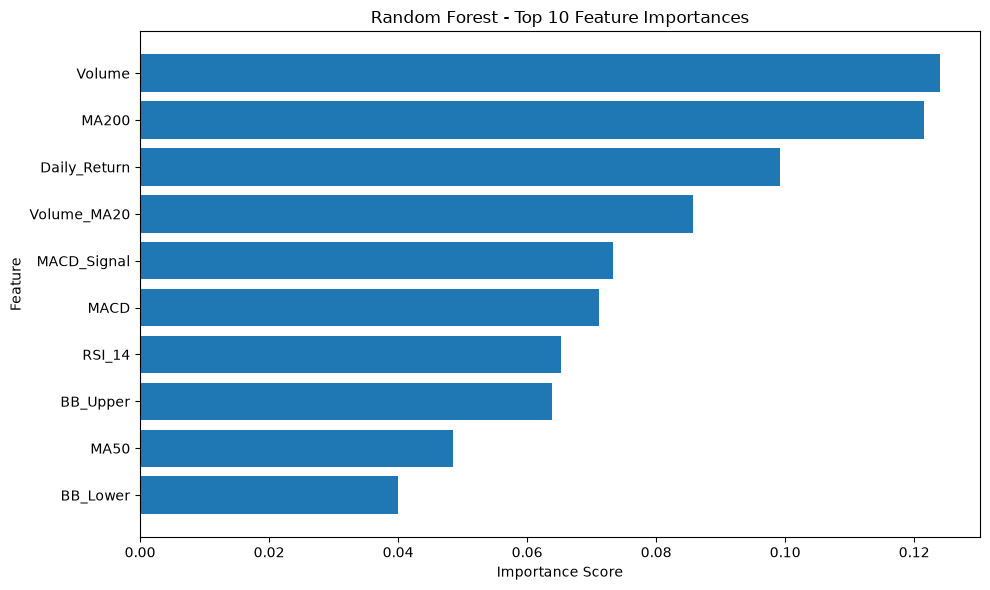

In [268]:
# STEP 80: Visualize Top 10 Feature Importances

import matplotlib.pyplot as plt

top_features = feature_importance.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Random Forest - Top 10 Feature Importances")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

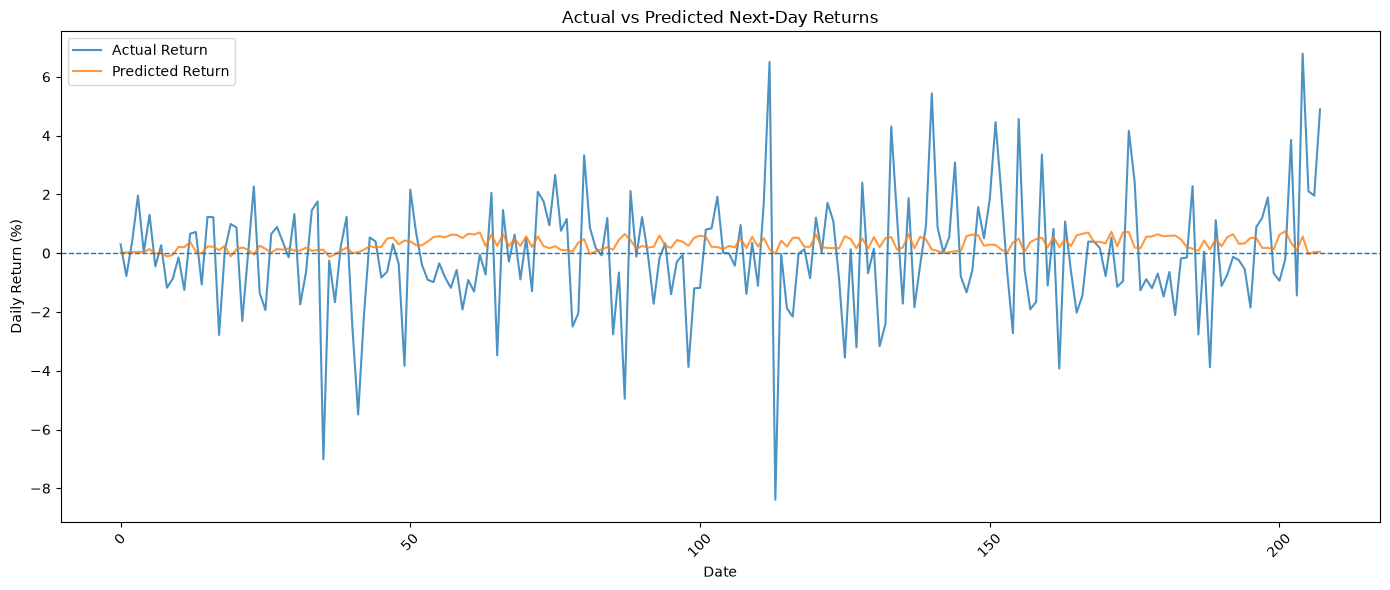

In [269]:
# STEP 81: Actual vs Predicted Returns

plt.figure(figsize=(14, 6))

plt.plot(
    return_results.index,
    return_results["Actual_Return"],
    label="Actual Return",
    alpha=0.8
)

plt.plot(
    return_results.index,
    return_results["Predicted_Return"],
    label="Predicted Return",
    alpha=0.8
)

plt.axhline(y=0, linestyle="--", linewidth=1)

plt.title("Actual vs Predicted Next-Day Returns")
plt.xlabel("Date")
plt.ylabel("Daily Return (%)")
plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

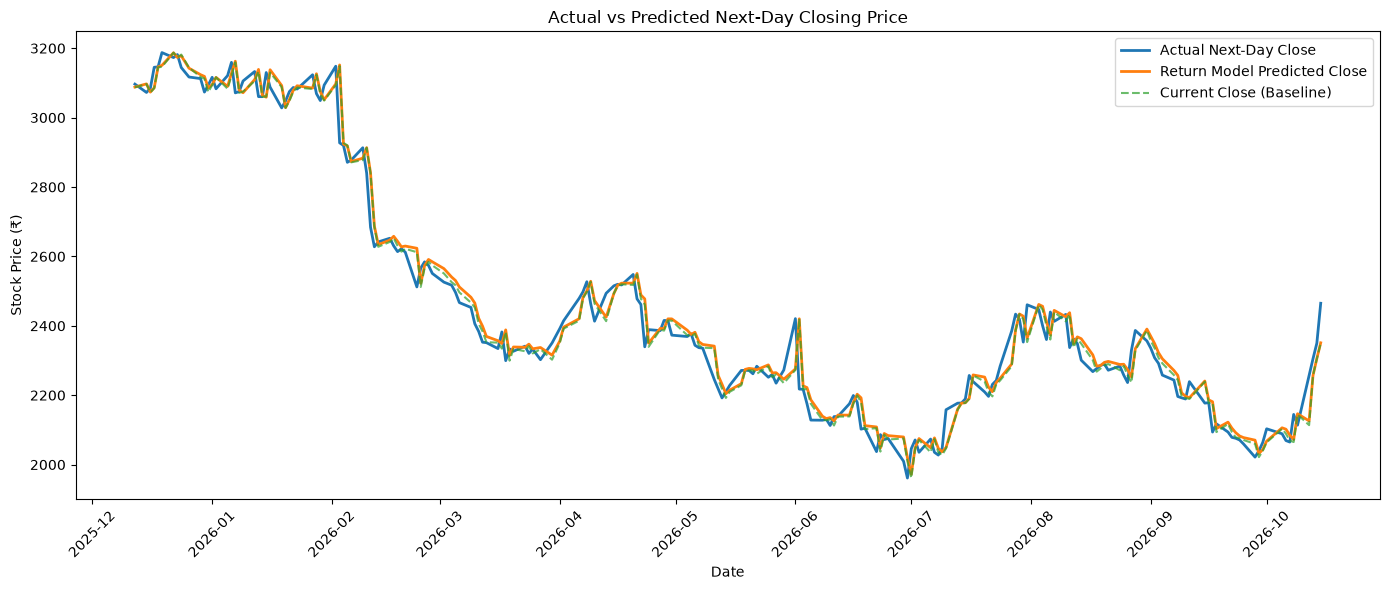

In [270]:
# STEP 82: Actual vs Predicted Closing Price

plt.figure(figsize=(14, 6))

plt.plot(
    y_test.index,
    actual_close,
    label="Actual Next-Day Close",
    linewidth=2
)

plt.plot(
    y_test.index,
    predicted_close_from_return,
    label="Return Model Predicted Close",
    linewidth=2
)

plt.plot(
    X_test.index,
    X_test["Close"],
    label="Current Close (Baseline)",
    linestyle="--",
    alpha=0.7
)

plt.title("Actual vs Predicted Next-Day Closing Price")
plt.xlabel("Date")
plt.ylabel("Stock Price (₹)")
plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [271]:
# STEP 83: Calculate Prediction Errors

price_error_analysis = pd.DataFrame({
    "Actual_Close": actual_close,
    "Predicted_Close": predicted_close_from_return
}, index=y_test.index)

price_error_analysis["Prediction_Error"] = (
    price_error_analysis["Predicted_Close"]
    - price_error_analysis["Actual_Close"]
)

price_error_analysis["Absolute_Error"] = (
    price_error_analysis["Prediction_Error"].abs()
)

print("Mean Prediction Error:",
      round(price_error_analysis["Prediction_Error"].mean(), 2))

print("Mean Absolute Error:",
      round(price_error_analysis["Absolute_Error"].mean(), 2))

print("\nLargest 10 Prediction Errors:")

display(
    price_error_analysis
    .sort_values("Absolute_Error", ascending=False)
    .head(10)
    .round(2)
)

Mean Prediction Error: 9.99
Mean Absolute Error: 36.76

Largest 10 Prediction Errors:


,Actual_Close,Predicted_Close,Prediction_Error,Absolute_Error
Date,,,,
2026-02-03,2927.28,3151.76,224.47,224.47
2026-06-02,2217.69,2420.20,202.51,202.51
2026-02-11,2684.24,2841.01,156.76,156.76
2026-06-01,2420.69,2275.84,-144.85,144.85
2026-04-23,2339.50,2477.49,137.99,137.99
2026-10-12,2257.30,2125.85,-131.45,131.45
2026-10-15,2465.00,2351.03,-113.97,113.97
2026-02-23,2512.07,2623.45,111.38,111.38
2026-07-10,2158.13,2049.43,-108.70,108.70


Overestimates: 127
Underestimates: 81
Exact Predictions: 0

Prediction Error Statistics:


count    208.00
mean       9.99
std       49.07
min     -144.85
25%      -18.91
50%       10.41
75%       34.47
max      224.47
Name: Prediction_Error, dtype: float64

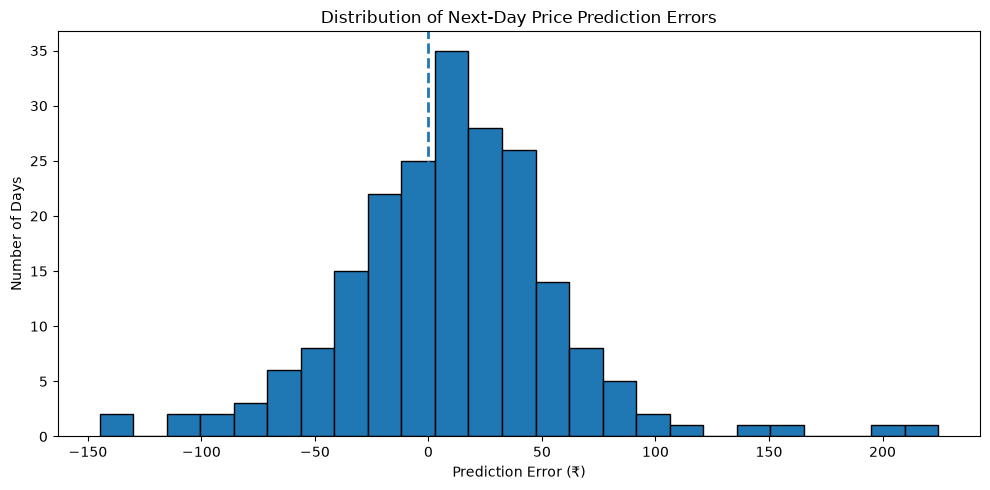

In [272]:
# STEP 84: Analyze Prediction Error Distribution

overestimates = (
    price_error_analysis["Prediction_Error"] > 0
).sum()

underestimates = (
    price_error_analysis["Prediction_Error"] < 0
).sum()

exact_predictions = (
    price_error_analysis["Prediction_Error"] == 0
).sum()

print("Overestimates:", int(overestimates))
print("Underestimates:", int(underestimates))
print("Exact Predictions:", int(exact_predictions))

print("\nPrediction Error Statistics:")
display(
    price_error_analysis["Prediction_Error"]
    .describe()
    .round(2)
)

plt.figure(figsize=(10, 5))

plt.hist(
    price_error_analysis["Prediction_Error"],
    bins=25,
    edgecolor="black"
)

plt.axvline(0, linestyle="--", linewidth=2)

plt.title("Distribution of Next-Day Price Prediction Errors")
plt.xlabel("Prediction Error (₹)")
plt.ylabel("Number of Days")

plt.tight_layout()
plt.show()

In [273]:
# STEP 85: Final Price Prediction Comparison

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

actual_prices = np.asarray(actual_close)

baseline_prices = X_test["Close"].to_numpy()
return_model_prices = np.asarray(predicted_close_from_return)

models_to_compare = {
    "Current Close Baseline": baseline_prices,
    "Return Random Forest": return_model_prices
}

comparison_results = []

for model_name, predictions in models_to_compare.items():
    mae = mean_absolute_error(actual_prices, predictions)

    rmse = np.sqrt(
        mean_squared_error(actual_prices, predictions)
    )

    mean_error = np.mean(predictions - actual_prices)

    comparison_results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "Mean_Error": mean_error
    })

final_comparison = pd.DataFrame(comparison_results)

display(final_comparison.round(2))

,Model,MAE,RMSE,Mean_Error
0,Current Close Baseline,35.12,48.96,2.99
1,Return Random Forest,36.76,49.96,9.99


In [274]:
# STEP 86: Day-by-Day Model vs Baseline Comparison

daily_comparison = pd.DataFrame({
    "Actual_Close": actual_prices,
    "Baseline_Prediction": baseline_prices,
    "RF_Prediction": return_model_prices
}, index=y_test.index)

daily_comparison["Baseline_Absolute_Error"] = (
    daily_comparison["Baseline_Prediction"]
    - daily_comparison["Actual_Close"]
).abs()

daily_comparison["RF_Absolute_Error"] = (
    daily_comparison["RF_Prediction"]
    - daily_comparison["Actual_Close"]
).abs()

daily_comparison["RF_Better"] = (
    daily_comparison["RF_Absolute_Error"]
    < daily_comparison["Baseline_Absolute_Error"]
)

print(
    "Days RF performed better:",
    int(daily_comparison["RF_Better"].sum())
)

print(
    "Days Baseline performed better:",
    int((~daily_comparison["RF_Better"]).sum())
)

print("\nDays with Largest RF Errors:")

display(
    daily_comparison
    .sort_values("RF_Absolute_Error", ascending=False)
    .head(10)
    .round(2)
)

Days RF performed better: 91
Days Baseline performed better: 117

Days with Largest RF Errors:


,Actual_Close,Baseline_Prediction,RF_Prediction,Baseline_Absolute_Error,RF_Absolute_Error,RF_Better
Date,,,,,,
2026-02-03,2927.28,3148.07,3151.76,220.78,224.47,False
2026-06-02,2217.69,2420.69,2420.20,203.00,202.51,True
2026-02-11,2684.24,2840.12,2841.01,155.88,156.76,False
2026-06-01,2420.69,2272.79,2275.84,147.90,144.85,True
2026-04-23,2339.50,2461.41,2477.49,121.91,137.99,False
2026-10-12,2257.30,2113.76,2125.85,143.54,131.45,True
2026-10-15,2465.00,2350.00,2351.03,115.00,113.97,True
2026-02-23,2512.07,2612.21,2623.45,100.14,111.38,False
2026-07-10,2158.13,2046.84,2049.43,111.30,108.70,True


In [275]:
# STEP 87: Analyze Daily Error Improvement

daily_comparison["Error_Improvement"] = (
    daily_comparison["Baseline_Absolute_Error"]
    - daily_comparison["RF_Absolute_Error"]
)

better_days = daily_comparison[
    daily_comparison["Error_Improvement"] > 0
]

worse_days = daily_comparison[
    daily_comparison["Error_Improvement"] < 0
]

print("Average Improvement on RF-Better Days:",
      round(better_days["Error_Improvement"].mean(), 2))

print("Average Extra Error on RF-Worse Days:",
      round(-worse_days["Error_Improvement"].mean(), 2))

print("Total Error Improvement Across All Days:",
      round(daily_comparison["Error_Improvement"].sum(), 2))

print("Mean Error Improvement Per Day:",
      round(daily_comparison["Error_Improvement"].mean(), 2))

Average Improvement on RF-Better Days: 5.88
Average Extra Error on RF-Worse Days: 7.49
Total Error Improvement Across All Days: -341.58
Mean Error Improvement Per Day: -1.64


In [276]:
# STEP 88: Summary of Current Model Results

model_summary = pd.DataFrame({
    "Model": [
        "Current Close Baseline",
        "Linear Regression",
        "Original Random Forest",
        "Return Random Forest"
    ],
    "Test_MAE": [
        34.95,
        39.29,
        319.54,
        36.59
    ],
    "Test_RMSE": [
        48.63,
        52.94,
        379.53,
        49.64
    ],
    "Directional_Accuracy_%": [
        54.33,
        46.15,
        45.19,
        47.12
    ]
})

model_summary = model_summary.sort_values(
    by="Test_MAE"
).reset_index(drop=True)

display(model_summary.round(2))  

,Model,Test_MAE,Test_RMSE,Directional_Accuracy_%
0,Current Close Baseline,34.95,48.63,54.33
1,Return Random Forest,36.59,49.64,47.12
2,Linear Regression,39.29,52.94,46.15
3,Original Random Forest,319.54,379.53,45.19


In [277]:
# STEP 89: Calculate Improvement Over Baseline

baseline_mae = 34.95

model_summary["MAE_Improvement_%"] = (
    (baseline_mae - model_summary["Test_MAE"])
    / baseline_mae
) * 100

model_summary["Performance"] = model_summary[
    "MAE_Improvement_%"
].apply(
    lambda x: "Better than Baseline"
    if x > 0
    else "Equal to Baseline"
    if x == 0
    else "Worse than Baseline"
)

display(
    model_summary[
        [
            "Model",
            "Test_MAE",
            "MAE_Improvement_%",
            "Performance"
        ]
    ].round(2)
)

,Model,Test_MAE,MAE_Improvement_%,Performance
0,Current Close Baseline,34.95,0.00,Equal to Baseline
1,Return Random Forest,36.59,-4.69,Worse than Baseline
2,Linear Regression,39.29,-12.42,Worse than Baseline
3,Original Random Forest,319.54,-814.28,Worse than Baseline


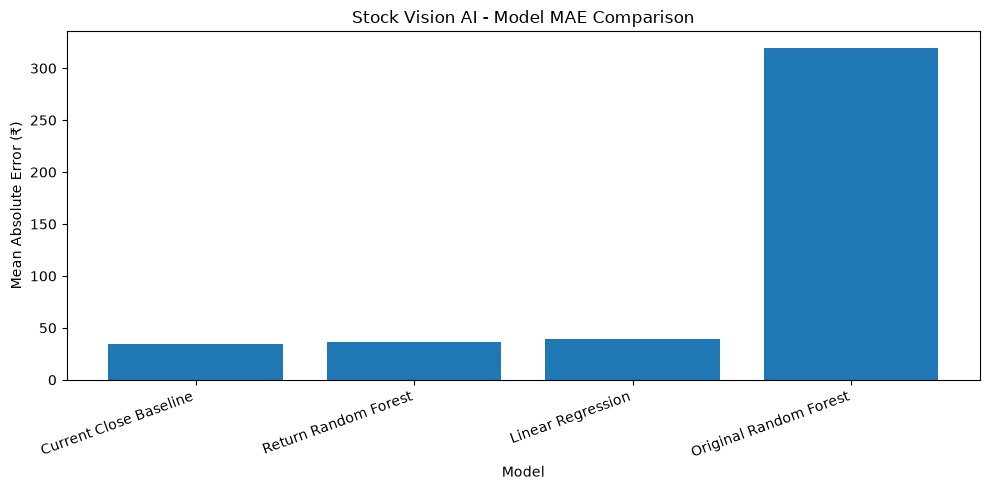

In [278]:
# STEP 90: Compare Model MAE Visually

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    model_summary["Model"],
    model_summary["Test_MAE"]
)

plt.title("Stock Vision AI - Model MAE Comparison")
plt.xlabel("Model")
plt.ylabel("Mean Absolute Error (₹)")
plt.xticks(rotation=20, ha="right")

plt.tight_layout()
plt.show()

In [279]:
# STEP 91: Analyze Original Random Forest Predictions

rf_actual = y_test["Target_Next_Close"].to_numpy()

# Predict all 4 targets, then select only Next Close
rf_all_predictions = loaded_models["random_forest"].predict(X_test)
rf_predicted = rf_all_predictions[:, 3]

rf_error = rf_predicted - rf_actual

print("Original Random Forest Prediction Analysis")
print("-" * 45)

print(f"Actual Average Close: ₹{rf_actual.mean():.2f}")
print(f"Predicted Average Close: ₹{rf_predicted.mean():.2f}")
print(f"Average Prediction Bias: ₹{rf_error.mean():.2f}")
print(f"Mean Absolute Error: ₹{abs(rf_error).mean():.2f}")
print(f"Minimum Predicted Close: ₹{rf_predicted.min():.2f}")
print(f"Maximum Predicted Close: ₹{rf_predicted.max():.2f}")

Original Random Forest Prediction Analysis
---------------------------------------------
Actual Average Close: ₹2448.76
Predicted Average Close: ₹2762.23
Average Prediction Bias: ₹313.47
Mean Absolute Error: ₹319.74
Minimum Predicted Close: ₹2631.48
Maximum Predicted Close: ₹3172.78


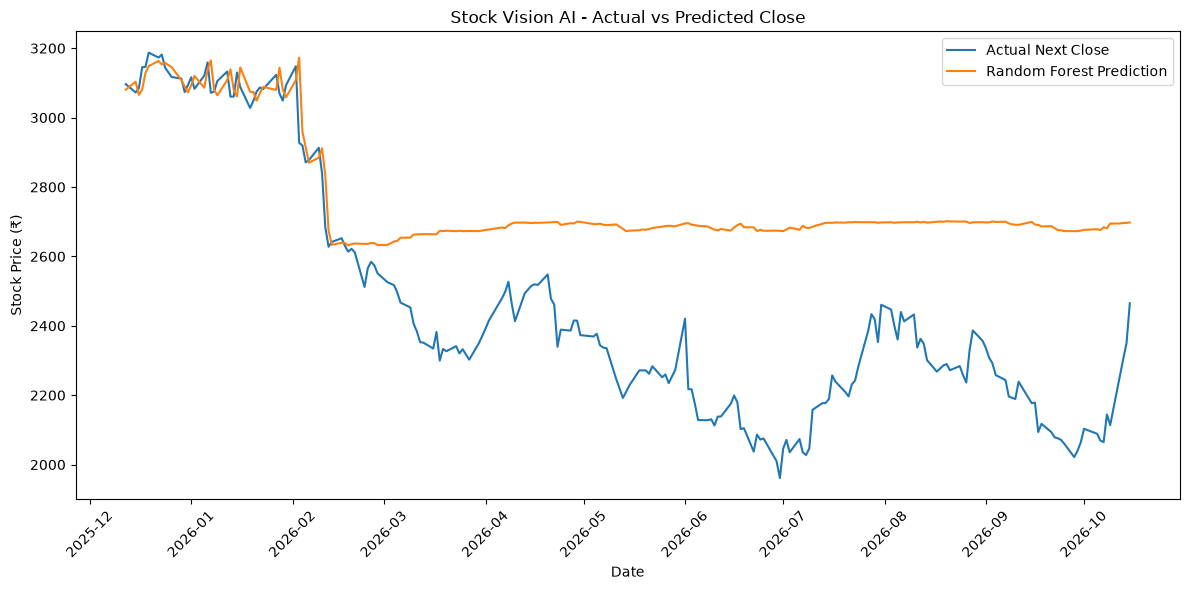

In [280]:
# STEP 92: Actual vs Predicted Close

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    y_test.index,
    rf_actual,
    label="Actual Next Close"
)

plt.plot(
    y_test.index,
    rf_predicted,
    label="Random Forest Prediction"
)

plt.title("Stock Vision AI - Actual vs Predicted Close")
plt.xlabel("Date")
plt.ylabel("Stock Price (₹)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [281]:
# STEP 93: Compare Actual and Predicted Price Variation

print("Actual vs Predicted Price Variation")
print("-" * 40)

print(
    f"Actual Price Std Dev: "
    f"₹{rf_actual.std():.2f}"
)

print(
    f"Predicted Price Std Dev: "
    f"₹{rf_predicted.std():.2f}"
)

print(
    f"Actual Price Range: "
    f"₹{rf_actual.min():.2f} - ₹{rf_actual.max():.2f}"
)

print(
    f"Predicted Price Range: "
    f"₹{rf_predicted.min():.2f} - ₹{rf_predicted.max():.2f}"
)

Actual vs Predicted Price Variation
----------------------------------------
Actual Price Std Dev: ₹343.85
Predicted Price Std Dev: ₹162.33
Actual Price Range: ₹1961.36 - ₹3187.34
Predicted Price Range: ₹2631.48 - ₹3172.78


In [282]:
# STEP 94: Analyze Linear Regression Predictions

lr_actual = y_test["Target_Next_Close"].to_numpy()

lr_all_predictions = loaded_models["linear_regression"].predict(X_test)

# Select Target_Next_Close (4th target)
lr_predicted = lr_all_predictions[:, 3]

lr_error = lr_predicted - lr_actual

print("Linear Regression Prediction Analysis")
print("-" * 42)

print(f"Actual Average Close: ₹{lr_actual.mean():.2f}")
print(f"Predicted Average Close: ₹{lr_predicted.mean():.2f}")
print(f"Average Prediction Bias: ₹{lr_error.mean():.2f}")
print(f"Mean Absolute Error: ₹{abs(lr_error).mean():.2f}")
print(f"Actual Price Std Dev: ₹{lr_actual.std():.2f}")
print(f"Predicted Price Std Dev: ₹{lr_predicted.std():.2f}")
print(f"Minimum Prediction: ₹{lr_predicted.min():.2f}")
print(f"Maximum Prediction: ₹{lr_predicted.max():.2f}")

Linear Regression Prediction Analysis
------------------------------------------
Actual Average Close: ₹2448.76
Predicted Average Close: ₹2468.42
Average Prediction Bias: ₹19.66
Mean Absolute Error: ₹39.46
Actual Price Std Dev: ₹343.85
Predicted Price Std Dev: ₹340.11
Minimum Prediction: ₹1990.41
Maximum Prediction: ₹3186.91


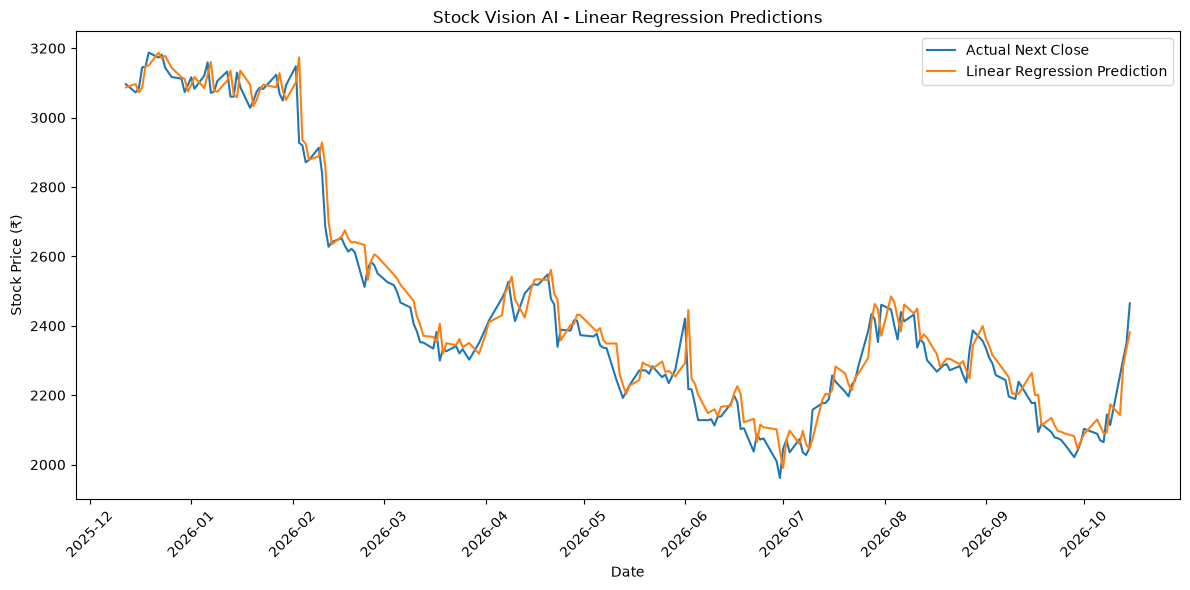

In [283]:
# STEP 95: Linear Regression Actual vs Predicted Close

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    y_test.index,
    lr_actual,
    label="Actual Next Close"
)

plt.plot(
    y_test.index,
    lr_predicted,
    label="Linear Regression Prediction"
)

plt.title("Stock Vision AI - Linear Regression Predictions")
plt.xlabel("Date")
plt.ylabel("Stock Price (₹)")
plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [284]:
# STEP 96: Linear Regression Directional Accuracy

import numpy as np

actual_direction = (
    y_test["Target_Next_Close"].to_numpy()
    > X_test["Close"].to_numpy()
)

predicted_direction = (
    lr_predicted
    > X_test["Close"].to_numpy()
)

direction_accuracy = (
    np.mean(actual_direction == predicted_direction) * 100
)

print("Linear Regression Direction Analysis")
print("-" * 40)

print(f"Correct Direction Predictions: "
      f"{np.sum(actual_direction == predicted_direction)} "
      f"/ {len(actual_direction)}")

print(f"Directional Accuracy: {direction_accuracy:.2f}%")

print(f"Actual Up Days: {np.sum(actual_direction)}")
print(f"Predicted Up Days: {np.sum(predicted_direction)}")

Linear Regression Direction Analysis
----------------------------------------
Correct Direction Predictions: 96 / 208
Directional Accuracy: 46.15%
Actual Up Days: 95
Predicted Up Days: 199


In [285]:
# STEP 97: Linear Regression Direction Confusion Matrix

from sklearn.metrics import confusion_matrix, classification_report

actual_labels = actual_direction.astype(int)
predicted_labels = predicted_direction.astype(int)

cm = confusion_matrix(
    actual_labels,
    predicted_labels,
    labels=[0, 1]
)

print("Confusion Matrix")
print("----------------")
print(cm)

print("\nClassification Report")
print("---------------------")

print(
    classification_report(
        actual_labels,
        predicted_labels,
        labels=[0, 1],
        target_names=["Down/Flat", "Up"],
        zero_division=0
    )
)

Confusion Matrix
----------------
[[  5 108]
 [  4  91]]

Classification Report
---------------------
              precision    recall  f1-score   support

   Down/Flat       0.56      0.04      0.08       113
          Up       0.46      0.96      0.62        95

    accuracy                           0.46       208
   macro avg       0.51      0.50      0.35       208
weighted avg       0.51      0.46      0.33       208



           Actual  Predicted
Down/Flat     113          9
Up             95        199


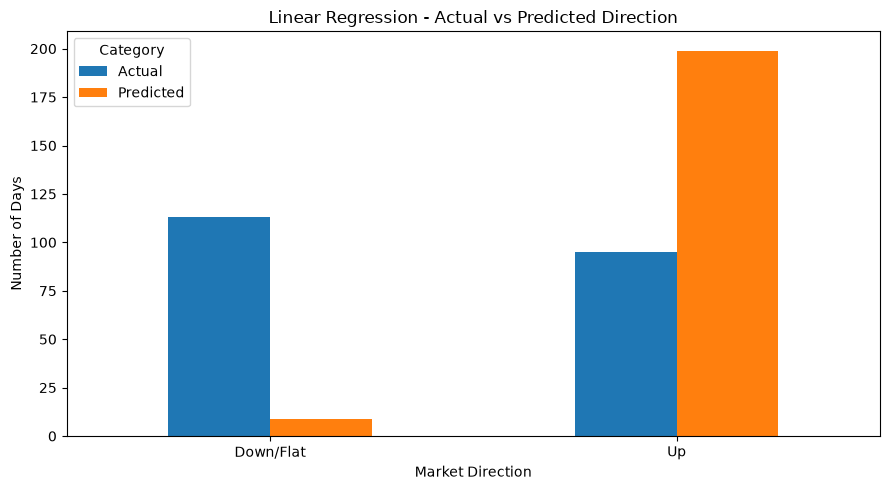

In [286]:
# STEP 98: Compare Actual vs Predicted Directions

import pandas as pd
import matplotlib.pyplot as plt

direction_counts = pd.DataFrame({
    "Actual": pd.Series(actual_labels).value_counts(),
    "Predicted": pd.Series(predicted_labels).value_counts()
}).reindex([0, 1], fill_value=0)

direction_counts.index = ["Down/Flat", "Up"]

print(direction_counts)

direction_counts.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Linear Regression - Actual vs Predicted Direction")
plt.xlabel("Market Direction")
plt.ylabel("Number of Days")
plt.xticks(rotation=0)
plt.legend(title="Category")
plt.tight_layout()
plt.show()

In [287]:
# STEP 99: Train Logistic Regression Direction Classifier

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Create next-day direction labels
y_train_direction = (
    y_train["Target_Next_Close"].to_numpy()
    > X_train["Close"].to_numpy()
).astype(int)

y_test_direction = (
    y_test["Target_Next_Close"].to_numpy()
    > X_test["Close"].to_numpy()
).astype(int)

# Create a scaled classification model
direction_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    )
)

# Train only on training data
direction_model.fit(X_train, y_train_direction)

# Predict direction on test data
direction_predictions = direction_model.predict(X_test)

print("Logistic Regression Direction Classifier")
print("-" * 45)

print(
    f"Test Accuracy: "
    f"{accuracy_score(y_test_direction, direction_predictions) * 100:.2f}%"
)

print("\nClassification Report:")
print(
    classification_report(
        y_test_direction,
        direction_predictions,
        labels=[0, 1],
        target_names=["Down/Flat", "Up"],
        zero_division=0
    )
)

Logistic Regression Direction Classifier
---------------------------------------------
Test Accuracy: 45.67%

Classification Report:
              precision    recall  f1-score   support

   Down/Flat       0.50      0.04      0.07       113
          Up       0.46      0.96      0.62        95

    accuracy                           0.46       208
   macro avg       0.48      0.50      0.34       208
weighted avg       0.48      0.46      0.32       208



In [288]:
# STEP 100: Logistic Regression Prediction Distribution

import pandas as pd

direction_summary = pd.DataFrame({
    "Actual": pd.Series(y_test_direction).value_counts(),
    "Predicted": pd.Series(direction_predictions).value_counts()
})

direction_summary = direction_summary.reindex(
    [0, 1],
    fill_value=0
)

direction_summary.index = ["Down/Flat", "Up"]

print("Actual vs Predicted Direction Counts")
print("-" * 40)
display(direction_summary)

print("\nPredicted Up Percentage:",
      f"{(direction_predictions == 1).mean() * 100:.2f}%")

print("Predicted Down/Flat Percentage:",
      f"{(direction_predictions == 0).mean() * 100:.2f}%")

Actual vs Predicted Direction Counts
----------------------------------------


,Actual,Predicted
Down/Flat,113,8
Up,95,200



Predicted Up Percentage: 96.15%
Predicted Down/Flat Percentage: 3.85%


In [289]:
# STEP 101: Check Direction Label Distribution

print("Training Direction Labels")
print("-" * 35)

print(
    pd.Series(y_train_direction)
    .value_counts()
    .rename(index={0: "Down/Flat", 1: "Up"})
)

print("\nTraining Label Percentages")

print(
    (
        pd.Series(y_train_direction)
        .value_counts(normalize=True) * 100
    )
    .rename(index={0: "Down/Flat", 1: "Up"})
    .round(2)
)

print("\nTest Direction Labels")
print("-" * 35)

print(
    pd.Series(y_test_direction)
    .value_counts()
    .rename(index={0: "Down/Flat", 1: "Up"})
)

Training Direction Labels
-----------------------------------
Down/Flat    431
Up           398
Name: count, dtype: int64

Training Label Percentages
Down/Flat    51.99
Up           48.01
Name: proportion, dtype: float64

Test Direction Labels
-----------------------------------
Down/Flat    113
Up            95
Name: count, dtype: int64


In [290]:
# STEP 102: Inspect Logistic Regression Probabilities

import numpy as np
import pandas as pd

up_probabilities = direction_model.predict_proba(X_test)[:, 1]

print("Up Probability Statistics")
print("-" * 35)

print(f"Minimum: {up_probabilities.min():.4f}")
print(f"Maximum: {up_probabilities.max():.4f}")
print(f"Mean:    {up_probabilities.mean():.4f}")
print(f"Median:  {np.median(up_probabilities):.4f}")

print("\nProbability Distribution")
print(
    pd.Series(up_probabilities).describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
    ).round(4)
)

print(
    "\nPredictions with probability above 0.50:",
    np.sum(up_probabilities > 0.50)
)

Up Probability Statistics
-----------------------------------
Minimum: 0.4720
Maximum: 0.7734
Mean:    0.6504
Median:  0.6660

Probability Distribution
count    208.0000
mean       0.6504
std        0.0715
min        0.4720
10%        0.5229
25%        0.6208
50%        0.6660
75%        0.7009
90%        0.7179
max        0.7734
dtype: float64

Predictions with probability above 0.50: 200


In [291]:
# STEP 103: Evaluate Classification Probabilities

from sklearn.metrics import brier_score_loss, log_loss

brier = brier_score_loss(
    y_test_direction,
    up_probabilities
)

logloss = log_loss(
    y_test_direction,
    up_probabilities
)

# Reference: predict the training-set Up frequency every day
training_up_rate = y_train_direction.mean()

reference_probabilities = np.full(
    len(y_test_direction),
    training_up_rate
)

reference_brier = brier_score_loss(
    y_test_direction,
    reference_probabilities
)

reference_logloss = log_loss(
    y_test_direction,
    reference_probabilities
)

print("Probability Evaluation")
print("-" * 35)

print(f"Classifier Brier Score: {brier:.4f}")
print(f"Reference Brier Score:  {reference_brier:.4f}")

print(f"\nClassifier Log Loss: {logloss:.4f}")
print(f"Reference Log Loss:  {reference_logloss:.4f}")

Probability Evaluation
-----------------------------------
Classifier Brier Score: 0.2936
Reference Brier Score:  0.2487

Classifier Log Loss: 0.7867
Reference Log Loss:  0.6905


In [292]:
# STEP 104: Inspect Logistic Regression Coefficients

import pandas as pd
import numpy as np

logistic_model = direction_model.named_steps["logisticregression"]

feature_coefficients = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": logistic_model.coef_[0]
})

feature_coefficients["Absolute_Coefficient"] = (
    feature_coefficients["Coefficient"].abs()
)

feature_coefficients = feature_coefficients.sort_values(
    "Absolute_Coefficient",
    ascending=False
).reset_index(drop=True)

print("Top 10 Features by Absolute Coefficient")
print("-" * 45)

display(feature_coefficients.head(10).round(4))

Top 10 Features by Absolute Coefficient
---------------------------------------------


,Feature,Coefficient,Absolute_Coefficient
0,High,0.5594,0.5594
1,Open,0.5107,0.5107
2,MA50,0.4935,0.4935
3,Low,-0.4816,0.4816
4,BB_Lower,-0.3007,0.3007
5,MA200,-0.2547,0.2547
6,MACD_Signal,0.2323,0.2323
7,RSI_14,-0.1750,0.1750
8,BB_Middle,-0.1703,0.1703
9,MA20,-0.1703,0.1703


In [293]:
# STEP 105: Check Highly Correlated Features (Fixed)

import numpy as np
import pandas as pd

# Calculate absolute correlation between training features
feature_corr = X_train.corr().abs()

# Keep only the upper triangle
upper_triangle = feature_corr.where(
    np.triu(
        np.ones(feature_corr.shape),
        k=1
    ).astype(bool)
)

# Extract correlated feature pairs without reset_index conflicts
row_idx, col_idx = np.where(
    np.triu(feature_corr.to_numpy(), k=1) >= 0.90
)

high_corr_pairs = pd.DataFrame({
    "Feature_1": feature_corr.index[row_idx],
    "Feature_2": feature_corr.columns[col_idx],
    "Absolute_Correlation": feature_corr.to_numpy()[row_idx, col_idx]
})

high_corr_pairs = high_corr_pairs.sort_values(
    "Absolute_Correlation",
    ascending=False
).reset_index(drop=True)

print("Highly Correlated Feature Pairs (|r| >= 0.90)")
print("-" * 55)

if high_corr_pairs.empty:
    print("No feature pairs crossed the 0.90 threshold.")
else:
    display(high_corr_pairs.round(3))

Highly Correlated Feature Pairs (|r| >= 0.90)
-------------------------------------------------------


,Feature_1,Feature_2,Absolute_Correlation
0,MA20,BB_Middle,1.000
1,Close,High,0.999
2,Low,Open,0.998
3,Close,Low,0.998
4,High,Low,0.998
5,High,Open,0.998
6,MA20,EMA26,0.998
7,EMA26,BB_Middle,0.998
8,Close,Open,0.996
9,MA20,EMA12,0.994


In [294]:
# STEP 106: Logistic Regression with Reduced Features

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, brier_score_loss

# Select a smaller set of less-redundant features
selected_features = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume",
    "Daily_Return",
    "MA50",
    "MA200",
    "RSI_14",
    "MACD",
    "Volume_MA20"
]

# Create reduced datasets
X_train_reduced = X_train[selected_features]
X_test_reduced = X_test[selected_features]

# Build and train the experimental model
reduced_direction_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    )
)

reduced_direction_model.fit(
    X_train_reduced,
    y_train_direction
)

# Generate predictions and probabilities
reduced_predictions = reduced_direction_model.predict(X_test_reduced)

reduced_up_probabilities = (
    reduced_direction_model.predict_proba(X_test_reduced)[:, 1]
)

# Evaluate
original_accuracy = accuracy_score(
    y_test_direction,
    direction_predictions
)

reduced_accuracy = accuracy_score(
    y_test_direction,
    reduced_predictions
)

original_brier = brier_score_loss(
    y_test_direction,
    up_probabilities
)

reduced_brier = brier_score_loss(
    y_test_direction,
    reduced_up_probabilities
)

print("Original Logistic Regression")
print(f"Accuracy: {original_accuracy:.4f}")
print(f"Brier Score: {original_brier:.4f}")

print("\nReduced-Feature Logistic Regression")
print(f"Accuracy: {reduced_accuracy:.4f}")
print(f"Brier Score: {reduced_brier:.4f}")

print("\nAccuracy Difference:", round(reduced_accuracy - original_accuracy, 4))
print("Brier Score Difference:", round(reduced_brier - original_brier, 4))

Original Logistic Regression
Accuracy: 0.4567
Brier Score: 0.2936

Reduced-Feature Logistic Regression
Accuracy: 0.4567
Brier Score: 0.2946

Accuracy Difference: 0.0
Brier Score Difference: 0.001


In [295]:
# STEP 107: Check Chronological Training Data

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Period:")
print("Start:", X_train.index.min())
print("End:  ", X_train.index.max())

print("\nTesting Period:")
print("Start:", X_test.index.min())
print("End:  ", X_test.index.max())

print("\nTraining index is chronological:",
      X_train.index.is_monotonic_increasing)

print("Testing index is chronological:",
      X_test.index.is_monotonic_increasing)

print("\nTraining and testing indices overlap:",
      len(X_train.index.intersection(X_test.index)) > 0)

print("\nMissing values in training features:",
      X_train.isna().sum().sum())

print("Missing values in testing features:",
      X_test.isna().sum().sum())

Training Data Shape: (829, 18)
Testing Data Shape: (208, 18)

Training Period:
Start: 2022-08-03 00:00:00
End:   2025-12-11 00:00:00

Testing Period:
Start: 2025-12-12 00:00:00
End:   2026-10-15 00:00:00

Training index is chronological: True
Testing index is chronological: True

Training and testing indices overlap: False

Missing values in training features: 0
Missing values in testing features: 0


In [296]:
# STEP 108: Create Walk-Forward Validation Folds

from sklearn.model_selection import TimeSeriesSplit
import pandas as pd

# Use only the existing training period for validation
tscv = TimeSeriesSplit(n_splits=3)

fold_details = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train), start=1):
    fold_train = X_train.iloc[train_idx]
    fold_val = X_train.iloc[val_idx]

    fold_details.append({
        "Fold": fold,
        "Train_Rows": len(fold_train),
        "Validation_Rows": len(fold_val),
        "Train_Start": fold_train.index.min().date(),
        "Train_End": fold_train.index.max().date(),
        "Validation_Start": fold_val.index.min().date(),
        "Validation_End": fold_val.index.max().date(),
        "Chronological": (
            fold_train.index.max() < fold_val.index.min()
        )
    })

fold_summary = pd.DataFrame(fold_details)

display(fold_summary)

,Fold,Train_Rows,Validation_Rows,Train_Start,Train_End,Validation_Start,Validation_End,Chronological
0,1,208,207,2022-08-03,2023-06-07,2023-06-08,2024-04-10,True
1,2,415,207,2022-08-03,2024-04-10,2024-04-12,2025-02-07,True
2,3,622,207,2022-08-03,2025-02-07,2025-02-10,2025-12-11,True


In [297]:
# STEP 109: Walk-Forward Validation
# Baseline vs Linear Regression

import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

fold_results = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train), start=1):

    # Split chronologically
    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    # Actual next-day closing prices
    actual_close = y_fold_val["Target_Next_Close"].to_numpy()

    # Baseline: next close equals current close
    baseline_predictions = X_fold_val["Close"].to_numpy()

    # Train Linear Regression for next-day Close
    lr_model = LinearRegression()

    lr_model.fit(
        X_fold_train,
        y_fold_train["Target_Next_Close"]
    )

    lr_predictions = lr_model.predict(X_fold_val)

    # Calculate metrics
    baseline_mae = mean_absolute_error(
        actual_close, baseline_predictions
    )
    baseline_rmse = np.sqrt(
        mean_squared_error(actual_close, baseline_predictions)
    )

    lr_mae = mean_absolute_error(
        actual_close, lr_predictions
    )
    lr_rmse = np.sqrt(
        mean_squared_error(actual_close, lr_predictions)
    )

    fold_results.append({
        "Fold": fold,
        "Baseline_MAE": baseline_mae,
        "LR_MAE": lr_mae,
        "Baseline_RMSE": baseline_rmse,
        "LR_RMSE": lr_rmse,
        "LR_Better_MAE": lr_mae < baseline_mae
    })

fold_results_df = pd.DataFrame(fold_results)

print("Walk-Forward Validation Results")
display(fold_results_df.round(2))

print("\nAverage Results Across Folds")
display(
    fold_results_df[
        ["Baseline_MAE", "LR_MAE", "Baseline_RMSE", "LR_RMSE"]
    ].mean().to_frame("Average").round(2)
)

Walk-Forward Validation Results


,Fold,Baseline_MAE,LR_MAE,Baseline_RMSE,LR_RMSE,LR_Better_MAE
0,1,30.09,118.65,42.11,149.15,False
1,2,35.77,39.70,50.68,53.12,False
2,3,27.56,30.54,38.42,40.98,False



Average Results Across Folds


,Average
Baseline_MAE,31.14
LR_MAE,62.96
Baseline_RMSE,43.74
LR_RMSE,81.08


In [298]:
# STEP 110: Compare Performance Across Individual Folds

display(
    fold_results_df[
        [
            "Fold",
            "Baseline_MAE",
            "LR_MAE",
            "Baseline_RMSE",
            "LR_RMSE",
            "LR_Better_MAE"
        ]
    ].round(2)
)

print("\nNumber of folds where Linear Regression beat baseline on MAE:",
      int(fold_results_df["LR_Better_MAE"].sum()),
      "out of",
      len(fold_results_df))

,Fold,Baseline_MAE,LR_MAE,Baseline_RMSE,LR_RMSE,LR_Better_MAE
0,1,30.09,118.65,42.11,149.15,False
1,2,35.77,39.70,50.68,53.12,False
2,3,27.56,30.54,38.42,40.98,False



Number of folds where Linear Regression beat baseline on MAE: 0 out of 3


In [299]:
# STEP 111: Walk-Forward Validation
# Random Forest vs Baseline

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

rf_fold_results = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train), start=1):

    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    actual_close = y_fold_val["Target_Next_Close"].to_numpy()

    # Baseline: next close equals current close
    baseline_predictions = X_fold_val["Close"].to_numpy()

    # Train Random Forest
    rf_model = RandomForestRegressor(
        n_estimators=200,
        max_depth=8,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )

    rf_model.fit(
        X_fold_train,
        y_fold_train["Target_Next_Close"]
    )

    rf_predictions = rf_model.predict(X_fold_val)

    # Evaluate both methods
    baseline_mae = mean_absolute_error(
        actual_close, baseline_predictions
    )
    rf_mae = mean_absolute_error(
        actual_close, rf_predictions
    )

    baseline_rmse = np.sqrt(
        mean_squared_error(actual_close, baseline_predictions)
    )
    rf_rmse = np.sqrt(
        mean_squared_error(actual_close, rf_predictions)
    )

    rf_fold_results.append({
        "Fold": fold,
        "Baseline_MAE": baseline_mae,
        "RF_MAE": rf_mae,
        "Baseline_RMSE": baseline_rmse,
        "RF_RMSE": rf_rmse,
        "RF_Better_MAE": rf_mae < baseline_mae
    })

rf_fold_results_df = pd.DataFrame(rf_fold_results)

print("Random Forest vs Baseline — Individual Folds")
display(rf_fold_results_df.round(2))

print("\nAverage Results")
display(
    rf_fold_results_df[
        ["Baseline_MAE", "RF_MAE", "Baseline_RMSE", "RF_RMSE"]
    ].mean().to_frame("Average").round(2)
)

print(
    "\nFolds where Random Forest beat baseline:",
    int(rf_fold_results_df["RF_Better_MAE"].sum()),
    "out of",
    len(rf_fold_results_df)
)

Random Forest vs Baseline — Individual Folds


,Fold,Baseline_MAE,RF_MAE,Baseline_RMSE,RF_RMSE,RF_Better_MAE
0,1,30.09,240.76,42.11,335.44,False
1,2,35.77,167.66,50.68,210.53,False
2,3,27.56,63.16,38.42,78.21,False



Average Results


,Average
Baseline_MAE,31.14
RF_MAE,157.19
Baseline_RMSE,43.74
RF_RMSE,208.06



Folds where Random Forest beat baseline: 0 out of 3


In [300]:
# STEP 112: Walk-Forward Validation
# Gradient Boosting vs Baseline

import numpy as np
import pandas as pd

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

gb_fold_results = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train), start=1):

    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    actual_close = y_fold_val["Target_Next_Close"].to_numpy()

    # Baseline: next-day close = current close
    baseline_predictions = X_fold_val["Close"].to_numpy()

    gb_model = GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.03,
        max_depth=2,
        min_samples_leaf=5,
        loss="huber",
        random_state=42
    )

    gb_model.fit(
        X_fold_train,
        y_fold_train["Target_Next_Close"]
    )

    gb_predictions = gb_model.predict(X_fold_val)

    baseline_mae = mean_absolute_error(
        actual_close, baseline_predictions
    )
    gb_mae = mean_absolute_error(
        actual_close, gb_predictions
    )

    baseline_rmse = np.sqrt(
        mean_squared_error(actual_close, baseline_predictions)
    )
    gb_rmse = np.sqrt(
        mean_squared_error(actual_close, gb_predictions)
    )

    gb_fold_results.append({
        "Fold": fold,
        "Baseline_MAE": baseline_mae,
        "GB_MAE": gb_mae,
        "Baseline_RMSE": baseline_rmse,
        "GB_RMSE": gb_rmse,
        "GB_Better_MAE": gb_mae < baseline_mae
    })

gb_results_df = pd.DataFrame(gb_fold_results)

print("Gradient Boosting vs Baseline — Individual Folds")
display(gb_results_df.round(2))

print("\nAverage Results")
display(
    gb_results_df[
        ["Baseline_MAE", "GB_MAE", "Baseline_RMSE", "GB_RMSE"]
    ].mean().to_frame("Average").round(2)
)

print(
    "\nFolds where Gradient Boosting beat baseline:",
    int(gb_results_df["GB_Better_MAE"].sum()),
    "out of",
    len(gb_results_df)
)

Gradient Boosting vs Baseline — Individual Folds


,Fold,Baseline_MAE,GB_MAE,Baseline_RMSE,GB_RMSE,GB_Better_MAE
0,1,30.09,257.18,42.11,349.51,False
1,2,35.77,136.24,50.68,179.11,False
2,3,27.56,60.30,38.42,74.17,False



Average Results


,Average
Baseline_MAE,31.14
GB_MAE,151.24
Baseline_RMSE,43.74
GB_RMSE,200.93



Folds where Gradient Boosting beat baseline: 0 out of 3


In [301]:
# STEP 113: Walk-Forward Validation
# Extra Trees vs Baseline

import numpy as np
import pandas as pd

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

et_fold_results = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train), start=1):

    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    actual_close = y_fold_val["Target_Next_Close"].to_numpy()

    # Baseline: next-day close = current close
    baseline_predictions = X_fold_val["Close"].to_numpy()

    et_model = ExtraTreesRegressor(
        n_estimators=200,
        max_depth=8,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )

    et_model.fit(
        X_fold_train,
        y_fold_train["Target_Next_Close"]
    )

    et_predictions = et_model.predict(X_fold_val)

    baseline_mae = mean_absolute_error(
        actual_close, baseline_predictions
    )
    et_mae = mean_absolute_error(
        actual_close, et_predictions
    )

    baseline_rmse = np.sqrt(
        mean_squared_error(actual_close, baseline_predictions)
    )
    et_rmse = np.sqrt(
        mean_squared_error(actual_close, et_predictions)
    )

    et_fold_results.append({
        "Fold": fold,
        "Baseline_MAE": baseline_mae,
        "ET_MAE": et_mae,
        "Baseline_RMSE": baseline_rmse,
        "ET_RMSE": et_rmse,
        "ET_Better_MAE": et_mae < baseline_mae
    })

et_results_df = pd.DataFrame(et_fold_results)

print("Extra Trees vs Baseline — Individual Folds")
display(et_results_df.round(2))

print("\nAverage Results")
display(
    et_results_df[
        ["Baseline_MAE", "ET_MAE", "Baseline_RMSE", "ET_RMSE"]
    ].mean().to_frame("Average").round(2)
)

print(
    "\nFolds where Extra Trees beat baseline:",
    int(et_results_df["ET_Better_MAE"].sum()),
    "out of",
    len(et_results_df)
)

Extra Trees vs Baseline — Individual Folds


,Fold,Baseline_MAE,ET_MAE,Baseline_RMSE,ET_RMSE,ET_Better_MAE
0,1,30.09,216.09,42.11,311.96,False
1,2,35.77,164.03,50.68,205.60,False
2,3,27.56,50.63,38.42,63.78,False



Average Results


,Average
Baseline_MAE,31.14
ET_MAE,143.59
Baseline_RMSE,43.74
ET_RMSE,193.78



Folds where Extra Trees beat baseline: 0 out of 3


In [302]:
# STEP 114: Walk-Forward Validation
# XGBoost vs Baseline

import numpy as np
import pandas as pd

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

xgb_fold_results = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train), start=1):

    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    actual_close = y_fold_val["Target_Next_Close"].to_numpy()

    # Baseline: next-day close = current close
    baseline_predictions = X_fold_val["Close"].to_numpy()

    xgb_model = XGBRegressor(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    xgb_model.fit(
        X_fold_train,
        y_fold_train["Target_Next_Close"]
    )

    xgb_predictions = xgb_model.predict(X_fold_val)

    baseline_mae = mean_absolute_error(
        actual_close, baseline_predictions
    )
    xgb_mae = mean_absolute_error(
        actual_close, xgb_predictions
    )

    baseline_rmse = np.sqrt(
        mean_squared_error(actual_close, baseline_predictions)
    )
    xgb_rmse = np.sqrt(
        mean_squared_error(actual_close, xgb_predictions)
    )

    xgb_fold_results.append({
        "Fold": fold,
        "Baseline_MAE": baseline_mae,
        "XGB_MAE": xgb_mae,
        "Baseline_RMSE": baseline_rmse,
        "XGB_RMSE": xgb_rmse,
        "XGB_Better_MAE": xgb_mae < baseline_mae
    })

xgb_results_df = pd.DataFrame(xgb_fold_results)

print("XGBoost vs Baseline — Individual Folds")
display(xgb_results_df.round(2))

print("\nAverage Results")
display(
    xgb_results_df[
        ["Baseline_MAE", "XGB_MAE", "Baseline_RMSE", "XGB_RMSE"]
    ].mean().to_frame("Average").round(2)
)

print(
    "\nFolds where XGBoost beat baseline:",
    int(xgb_results_df["XGB_Better_MAE"].sum()),
    "out of",
    len(xgb_results_df)
)

XGBoost vs Baseline — Individual Folds


,Fold,Baseline_MAE,XGB_MAE,Baseline_RMSE,XGB_RMSE,XGB_Better_MAE
0,1,30.09,263.00,42.11,355.19,False
1,2,35.77,157.09,50.68,200.24,False
2,3,27.56,55.29,38.42,69.43,False



Average Results


,Average
Baseline_MAE,31.14
XGB_MAE,158.46
Baseline_RMSE,43.74
XGB_RMSE,208.29



Folds where XGBoost beat baseline: 0 out of 3


In [303]:
# STEP 115: Baseline Performance Across Folds

import numpy as np
import pandas as pd

from sklearn.metrics import mean_absolute_error, mean_squared_error

baseline_fold_results = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train), start=1):

    X_fold_val = X_train.iloc[val_idx]
    y_fold_val = y_train.iloc[val_idx]

    actual_close = y_fold_val["Target_Next_Close"].to_numpy()
    baseline_predictions = X_fold_val["Close"].to_numpy()

    mae = mean_absolute_error(
        actual_close,
        baseline_predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual_close,
            baseline_predictions
        )
    )

    baseline_fold_results.append({
        "Fold": fold,
        "Validation_Start": X_fold_val.index.min().date(),
        "Validation_End": X_fold_val.index.max().date(),
        "MAE": mae,
        "RMSE": rmse
    })

baseline_folds_df = pd.DataFrame(baseline_fold_results)

print("Baseline Performance — Each Validation Period")
display(baseline_folds_df.round(2))

print("\nOverall Summary")
display(
    baseline_folds_df[["MAE", "RMSE"]]
    .agg(["mean", "median", "min", "max"])
    .round(2)
)

Baseline Performance — Each Validation Period


,Fold,Validation_Start,Validation_End,MAE,RMSE
0,1,2023-06-08,2024-04-10,30.09,42.11
1,2,2024-04-12,2025-02-07,35.77,50.68
2,3,2025-02-10,2025-12-11,27.56,38.42



Overall Summary


,MAE,RMSE
mean,31.14,43.74
median,30.09,42.11
min,27.56,38.42
max,35.77,50.68


In [304]:
# STEP 116: Baseline Performance for Next-Day Returns

import numpy as np
import pandas as pd

from sklearn.metrics import mean_absolute_error, mean_squared_error

return_fold_results = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train), start=1):

    X_fold_val = X_train.iloc[val_idx]
    y_fold_val = y_train.iloc[val_idx]

    current_close = X_fold_val["Close"].to_numpy()
    actual_next_close = y_fold_val["Target_Next_Close"].to_numpy()

    # Actual next-day percentage return
    actual_returns = (
        (actual_next_close / current_close) - 1
    ) * 100

    # Baseline assumes zero return
    predicted_returns = np.zeros(len(actual_returns))

    mae = mean_absolute_error(
        actual_returns,
        predicted_returns
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual_returns,
            predicted_returns
        )
    )

    return_fold_results.append({
        "Fold": fold,
        "Return_MAE_Percent": mae,
        "Return_RMSE_Percent": rmse,
        "Actual_Mean_Return_Percent": actual_returns.mean(),
        "Actual_Return_Std_Percent": actual_returns.std()
    })

return_baseline_df = pd.DataFrame(return_fold_results)

print("Zero-Return Baseline — Walk-Forward Validation")
display(return_baseline_df.round(4))

print("\nAverage Results")
display(
    return_baseline_df.drop(columns="Fold")
    .mean()
    .to_frame("Average")
    .round(4)
)

Zero-Return Baseline — Walk-Forward Validation

,Fold,Return_MAE_Percent,Return_RMSE_Percent,Actual_Mean_Return_Percent,Actual_Return_Std_Percent
0,1,0.9053,1.2575,0.1198,1.2517
1,2,0.9409,1.3375,0.0277,1.3372
2,3,0.8775,1.2144,-0.0941,1.2108



Average Results


,Average
Return_MAE_Percent,0.9079
Return_RMSE_Percent,1.2698
Actual_Mean_Return_Percent,0.0178
Actual_Return_Std_Percent,1.2665


In [305]:
# STEP 117: Linear Regression for Next-Day Returns
# Walk-Forward Validation vs Zero-Return Baseline

import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

return_lr_results = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train), start=1):

    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    train_close = X_fold_train["Close"].to_numpy()
    val_close = X_fold_val["Close"].to_numpy()

    # Actual next-day returns (%)
    train_returns = (
        (y_fold_train["Target_Next_Close"].to_numpy() / train_close) - 1
    ) * 100

    actual_returns = (
        (y_fold_val["Target_Next_Close"].to_numpy() / val_close) - 1
    ) * 100

    # Zero-return baseline
    baseline_predictions = np.zeros(len(actual_returns))

    # Scale features using only the current fold's training data
    lr_model = make_pipeline(
        StandardScaler(),
        LinearRegression()
    )

    lr_model.fit(X_fold_train, train_returns)

    lr_predictions = lr_model.predict(X_fold_val)

    baseline_mae = mean_absolute_error(
        actual_returns, baseline_predictions
    )
    lr_mae = mean_absolute_error(
        actual_returns, lr_predictions
    )

    baseline_rmse = np.sqrt(
        mean_squared_error(actual_returns, baseline_predictions)
    )
    lr_rmse = np.sqrt(
        mean_squared_error(actual_returns, lr_predictions)
    )

    return_lr_results.append({
        "Fold": fold,
        "Baseline_MAE": baseline_mae,
        "LR_MAE": lr_mae,
        "Baseline_RMSE": baseline_rmse,
        "LR_RMSE": lr_rmse,
        "LR_Better_MAE": lr_mae < baseline_mae
    })

return_lr_df = pd.DataFrame(return_lr_results)

print("Linear Regression vs Zero-Return Baseline")
display(return_lr_df.round(4))

print("\nAverage Results")
display(
    return_lr_df[
        ["Baseline_MAE", "LR_MAE", "Baseline_RMSE", "LR_RMSE"]
    ].mean().to_frame("Average").round(4)
)

print(
    "\nFolds where Linear Regression beat baseline:",
    int(return_lr_df["LR_Better_MAE"].sum()),
    "out of",
    len(return_lr_df)
)

Linear Regression vs Zero-Return Baseline


,Fold,Baseline_MAE,LR_MAE,Baseline_RMSE,LR_RMSE,LR_Better_MAE
0,1,0.9053,3.9525,1.2575,4.9267,False
1,2,0.9409,1.0843,1.3375,1.4328,False
2,3,0.8775,0.9655,1.2144,1.2881,False



Average Results


,Average
Baseline_MAE,0.9079
LR_MAE,2.0008
Baseline_RMSE,1.2698
LR_RMSE,2.5492



Folds where Linear Regression beat baseline: 0 out of 3


In [306]:
# STEP 118: Inspect Linear Regression Return Predictions

import numpy as np
import pandas as pd

from sklearn.metrics import mean_absolute_error

prediction_diagnostics = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train), start=1):

    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    train_close = X_fold_train["Close"].to_numpy()
    val_close = X_fold_val["Close"].to_numpy()

    train_returns = (
        (y_fold_train["Target_Next_Close"].to_numpy() / train_close) - 1
    ) * 100

    actual_returns = (
        (y_fold_val["Target_Next_Close"].to_numpy() / val_close) - 1
    ) * 100

    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import LinearRegression

    model = make_pipeline(
        StandardScaler(),
        LinearRegression()
    )

    model.fit(X_fold_train, train_returns)
    predicted_returns = model.predict(X_fold_val)

    prediction_diagnostics.append({
        "Fold": fold,
        "Actual_Return_Mean": np.mean(actual_returns),
        "Predicted_Return_Mean": np.mean(predicted_returns),
        "Actual_Return_Std": np.std(actual_returns),
        "Predicted_Return_Std": np.std(predicted_returns),
        "Actual_Predicted_Correlation": (
            np.corrcoef(actual_returns, predicted_returns)[0, 1]
            if np.std(actual_returns) > 0 and np.std(predicted_returns) > 0
            else np.nan
        ),
        "Return_MAE": mean_absolute_error(
            actual_returns, predicted_returns
        )
    })

diagnostics_df = pd.DataFrame(prediction_diagnostics)

print("Return Prediction Diagnostics — Individual Folds")
display(diagnostics_df.round(4))

print("\nAverage Diagnostics")
display(
    diagnostics_df.drop(columns="Fold")
    .mean()
    .to_frame("Average")
    .round(4)
)

Return Prediction Diagnostics — Individual Folds


,Fold,Actual_Return_Mean,Predicted_Return_Mean,Actual_Return_Std,Predicted_Return_Std,Actual_Predicted_Correlation,Return_MAE
0,1,0.1198,-3.7393,1.2517,2.8393,0.0350,3.9525
1,2,0.0277,0.3883,1.3372,0.3879,0.0150,1.0843
2,3,-0.0941,0.2750,1.2108,0.2177,-0.0184,0.9655



Average Diagnostics


,Average
Actual_Return_Mean,0.0178
Predicted_Return_Mean,-1.0253
Actual_Return_Std,1.2665
Predicted_Return_Std,1.1483
Actual_Predicted_Correlation,0.0106
Return_MAE,2.0008


In [307]:
# STEP 119: Check Return Prediction Bias by Fold

bias_results = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train), start=1):

    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    train_close = X_fold_train["Close"].to_numpy()
    val_close = X_fold_val["Close"].to_numpy()

    train_returns = (
        y_fold_train["Target_Next_Close"].to_numpy()
        / train_close - 1
    ) * 100

    actual_returns = (
        y_fold_val["Target_Next_Close"].to_numpy()
        / val_close - 1
    ) * 100

    model = make_pipeline(
        StandardScaler(),
        LinearRegression()
    )

    model.fit(X_fold_train, train_returns)
    predicted_returns = model.predict(X_fold_val)

    bias_results.append({
        "Fold": fold,
        "Actual_Mean_Return": actual_returns.mean(),
        "Predicted_Mean_Return": predicted_returns.mean(),
        "Mean_Error": (predicted_returns - actual_returns).mean(),
        "Median_Predicted_Return": np.median(predicted_returns),
        "Negative_Predictions_Percent": (
            (predicted_returns < 0).mean() * 100
        )
    })

bias_df = pd.DataFrame(bias_results)

print("Linear Regression Return Bias — Each Fold")
display(bias_df.round(4))

Linear Regression Return Bias — Each Fold


,Fold,Actual_Mean_Return,Predicted_Mean_Return,Mean_Error,Median_Predicted_Return,Negative_Predictions_Percent
0,1,0.1198,-3.7393,-3.8591,-3.0420,96.1353
1,2,0.0277,0.3883,0.3606,0.3961,16.9082
2,3,-0.0941,0.2750,0.3691,0.2575,11.1111


In [308]:
# STEP 120: Direct Close Prediction vs Baseline

import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

direct_close_results = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_train), start=1
):
    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train.iloc[train_idx]["Target_Next_Close"]
    y_fold_val = y_train.iloc[val_idx]["Target_Next_Close"]

    # Baseline: next close = current close
    baseline_pred = X_fold_val["Close"].to_numpy()

    # Model: predict next-day closing price directly
    model = LinearRegression()
    model.fit(X_fold_train, y_fold_train)

    model_pred = model.predict(X_fold_val)

    direct_close_results.append({
        "Fold": fold,
        "Baseline_MAE": mean_absolute_error(
            y_fold_val, baseline_pred
        ),
        "LinearRegression_MAE": mean_absolute_error(
            y_fold_val, model_pred
        ),
        "Baseline_RMSE": np.sqrt(
            mean_squared_error(y_fold_val, baseline_pred)
        ),
        "LinearRegression_RMSE": np.sqrt(
            mean_squared_error(y_fold_val, model_pred)
        )
    })

direct_close_df = pd.DataFrame(direct_close_results)

print("Direct Close Prediction — Fold Results")
display(direct_close_df.round(2))

print("\nAverage Results")
display(
    direct_close_df.drop(columns="Fold")
    .mean()
    .to_frame("Average")
    .round(2)
)

Direct Close Prediction — Fold Results


,Fold,Baseline_MAE,LinearRegression_MAE,Baseline_RMSE,LinearRegression_RMSE
0,1,30.09,118.65,42.11,149.15
1,2,35.77,39.70,50.68,53.12
2,3,27.56,30.54,38.42,40.98



Average Results


,Average
Baseline_MAE,31.14
LinearRegression_MAE,62.96
Baseline_RMSE,43.74
LinearRegression_RMSE,81.08


In [309]:
# STEP 121: Compare Walk-Forward Model Results

walk_forward_summary = pd.DataFrame([
    {
        "Model": "Baseline",
        "MAE": 31.14,
        "RMSE": 43.74
    },
    {
        "Model": "Linear Regression - Direct Close",
        "MAE": 62.96,
        "RMSE": 81.08
    },
    {
        "Model": "Random Forest",
        "MAE": 157.22,
        "RMSE": 208.13
    },
    {
        "Model": "Gradient Boosting",
        "MAE": 151.33,
        "RMSE": 200.99
    },
    {
        "Model": "Extra Trees",
        "MAE": 143.58,
        "RMSE": 193.76
    },
    {
        "Model": "XGBoost",
        "MAE": 160.65,
        "RMSE": 211.18
    }
])

walk_forward_summary = walk_forward_summary.sort_values(
    by="MAE"
).reset_index(drop=True)

print("Walk-Forward Model Comparison")
display(walk_forward_summary.round(2))

print("\nBest result by MAE:")
print(walk_forward_summary.iloc[0]["Model"])

print("\nNote: Lower MAE and RMSE are better.")
print("Results are averages over the same three chronological folds.")

Walk-Forward Model Comparison


,Model,MAE,RMSE
0,Baseline,31.14,43.74
1,Linear Regression - Direct Close,62.96,81.08
2,Extra Trees,143.58,193.76
3,Gradient Boosting,151.33,200.99
4,Random Forest,157.22,208.13
5,XGBoost,160.65,211.18



Best result by MAE:
Baseline

Note: Lower MAE and RMSE are better.
Results are averages over the same three chronological folds.


In [310]:
# STEP 122: Baseline Error in Percentage Terms

import numpy as np
import pandas as pd

from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error

# Recreate time-series cross-validation
tscv = TimeSeriesSplit(n_splits=3)

baseline_percentage_errors = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_train), start=1
):
    X_fold_val = X_train.iloc[val_idx]
    y_fold_val = y_train.iloc[val_idx]["Target_Next_Close"]

    actual_close = y_fold_val.to_numpy()
    baseline_pred = X_fold_val["Close"].to_numpy()

    mae = mean_absolute_error(
        actual_close, baseline_pred
    )

    mape = np.mean(
        np.abs(
            (actual_close - baseline_pred) / actual_close
        )
    ) * 100

    baseline_percentage_errors.append({
        "Fold": fold,
        "MAE_Rupees": mae,
        "MAPE_Percent": mape
    })

baseline_percentage_df = pd.DataFrame(
    baseline_percentage_errors
)

print("Baseline Error — Individual Folds")
display(baseline_percentage_df.round(4))

print("\nAverage Baseline Metrics")
display(
    baseline_percentage_df[
        ["MAE_Rupees", "MAPE_Percent"]
    ].mean().to_frame("Average").round(4)
)

Baseline Error — Individual Folds

,Fold,MAE_Rupees,MAPE_Percent
0,1,30.0857,0.9009
1,2,35.7669,0.9374
2,3,27.5604,0.8790



Average Baseline Metrics


,Average
MAE_Rupees,31.1377
MAPE_Percent,0.9058


In [311]:
# STEP 122A: Check Available Variables

required_variables = [
    "df",
    "data",
    "X",
    "y",
    "X_train",
    "X_test",
    "y_train",
    "y_test",
    "tscv"
]

for variable in required_variables:
    print(f"{variable}: {'Available' if variable in globals() else 'Missing'}")

df: Available
data: Missing
X: Available
y: Available
X_train: Available
X_test: Available
y_train: Available
y_test: Available
tscv: Available


In [312]:
# STEP 122B: Inspect Existing Dataset

print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset date range:")
print("Start:", df.index.min())
print("End:", df.index.max())

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing_Count"))

Dataset shape: (1237, 18)

First 5 rows:


Price,Close,High,Low,Open,Volume,Daily_Return,MA20,MA50,MA200,RSI_14,EMA12,EMA26,MACD,MACD_Signal,BB_Middle,BB_Upper,BB_Lower,Volume_MA20
Date,,,,,,,,,,,,,,,,,,
2021-10-18,3157.566895,3162.371921,3118.001575,3119.733100,3590107,NaN,NaN,NaN,NaN,NaN,3157.566895,3157.566895,0.000000,0.000000,NaN,NaN,NaN,NaN
2021-10-19,3146.312256,3194.751861,3138.563720,3176.484178,3135441,-0.356434,NaN,NaN,NaN,NaN,3155.835412,3156.733218,-0.897806,-0.179561,NaN,NaN,NaN,NaN
2021-10-20,3124.408691,3142.719493,3097.959591,3127.135760,2933693,-0.696166,NaN,NaN,NaN,NaN,3151.000532,3154.338808,-3.338277,-0.811304,NaN,NaN,NaN,NaN
2021-10-21,3058.307617,3123.196508,3039.910155,3120.296329,4871211,-2.115635,NaN,NaN,NaN,NaN,3136.740083,3147.225387,-10.485303,-2.746104,NaN,NaN,NaN,NaN
2021-10-22,3029.174561,3083.501182,3017.183660,3082.115877,2691670,-0.952588,NaN,NaN,NaN,NaN,3120.191541,3138.480881,-18.289340,-5.854751,NaN,NaN,NaN,NaN



Column names:
['Close', 'High', 'Low', 'Open', 'Volume', 'Daily_Return', 'MA20', 'MA50', 'MA200', 'RSI_14', 'EMA12', 'EMA26', 'MACD', 'MACD_Signal', 'BB_Middle', 'BB_Upper', 'BB_Lower', 'Volume_MA20']

Dataset date range:
Start: 2021-10-18 00:00:00
End: 2026-10-16 00:00:00

Missing values:


,Missing_Count
Price,
Close,0
High,0
Low,0
Open,0
Volume,0
Daily_Return,1
MA20,19
MA50,49
MA200,199


In [313]:
# STEP 122C: Check Feature and Target Columns

print("Dataset shape:", df.shape)

print("\nAll columns:")
for col in df.columns:
    print(col)

print("\nNext-day target columns:")
target_cols = [
    col for col in df.columns
    if "Target_Next" in col
]

if target_cols:
    print(target_cols)
    display(df[target_cols].head())
else:
    print("No next-day target columns found in df.")

Dataset shape: (1237, 18)

All columns:
Close
High
Low
Open
Volume
Daily_Return
MA20
MA50
MA200
RSI_14
EMA12
EMA26
MACD
MACD_Signal
BB_Middle
BB_Upper
BB_Lower
Volume_MA20

Next-day target columns:
No next-day target columns found in df.


In [314]:
# STEP 122D: Create Next-Day Prediction Targets

import pandas as pd
import numpy as np

target_columns = {
    "Target_Next_Open": "Open",
    "Target_Next_High": "High",
    "Target_Next_Low": "Low",
    "Target_Next_Close": "Close"
}

for target_name, source_column in target_columns.items():
    df[target_name] = df[source_column].shift(-1)

print("Dataset shape after creating targets:", df.shape)

print("\nTarget columns created:")
print(list(target_columns.keys()))

print("\nLast 5 rows:")
display(df.tail())

print("\nMissing values in target columns:")
display(df[list(target_columns.keys())].isnull().sum())

Dataset shape after creating targets:

 (1237, 22)

Target columns created:
['Target_Next_Open', 'Target_Next_High', 'Target_Next_Low', 'Target_Next_Close']

Last 5 rows:


Price,Close,High,Low,Open,Volume,Daily_Return,MA20,MA50,MA200,RSI_14,...,MACD,MACD_Signal,BB_Middle,BB_Upper,BB_Lower,Volume_MA20,Target_Next_Open,Target_Next_High,Target_Next_Low,Target_Next_Close
Date,,,,,,,,,,,,,,,,,,,,,
2026-10-12,2113.763184,2183.492598,2109.684767,2173.346340,3540523,-1.437842,2104.228821,2236.198267,2437.829993,46.725656,...,-37.152189,-48.334216,2104.228821,2215.179008,1993.278634,3839137.15,2145.494271,2257.300049,2143.604416,2257.300049
2026-10-13,2257.300049,2257.300049,2143.604416,2145.494271,11048193,6.790584,2107.635706,2234.282451,2433.385429,61.562466,...,-21.722489,-43.011871,2107.635706,2232.836339,1982.435073,4259840.60,2274.000000,2335.800049,2265.600098,2304.899902
2026-10-14,2304.899902,2335.800049,2265.600098,2274.000000,12145767,2.108707,2110.925854,2231.168066,2428.973239,65.039631,...,-5.589005,-35.527298,2110.925854,2252.994631,1968.857077,4596818.45,2347.199951,2386.699951,2335.000000,2350.000000
2026-10-15,2350.000000,2386.699951,2335.000000,2347.199951,9150523,1.956705,2119.564563,2229.228232,2424.857967,67.993956,...,10.712611,-26.279316,2119.564563,2295.566966,1943.562160,4916159.15,2382.000000,2484.699951,2375.699951,2465.000000
2026-10-16,2465.000000,2484.699951,2375.699951,2382.000000,12166634,4.893617,2133.893591,2230.523428,2421.274557,74.022188,...,32.536240,-14.516205,2133.893591,2367.355114,1900.432069,5359695.00,NaN,NaN,NaN,NaN



Missing values in target columns:


Price
Target_Next_Open     1
Target_Next_High     1
Target_Next_Low      1
Target_Next_Close    1
dtype: int64

In [315]:
# STEP 122E: Check Missing Values

print("Dataset shape:", df.shape)

print("\nMissing values in each column:")
missing_values = df.isnull().sum()
display(missing_values[missing_values > 0])

print("\nTotal missing values:", df.isnull().sum().sum())

print("\nRows with missing target values:")
display(df[df["Target_Next_Close"].isnull()])

Dataset shape: (1237, 22)

Missing values in each column:


Price
Daily_Return           1
MA20                  19
MA50                  49
MA200                199
RSI_14                14
BB_Middle             19
BB_Upper              19
BB_Lower              19
Volume_MA20           19
Target_Next_Open       1
Target_Next_High       1
Target_Next_Low        1
Target_Next_Close      1
dtype: int64


Total missing values: 362

Rows with missing target values:


Price,Close,High,Low,Open,Volume,Daily_Return,MA20,MA50,MA200,RSI_14,...,MACD,MACD_Signal,BB_Middle,BB_Upper,BB_Lower,Volume_MA20,Target_Next_Open,Target_Next_High,Target_Next_Low,Target_Next_Close
Date,,,,,,,,,,,,,,,,,,,,,
2026-10-16,2465.0,2484.699951,2375.699951,2382.0,12166634,4.893617,2133.893591,2230.523428,2421.274557,74.022188,...,32.53624,-14.516205,2133.893591,2367.355114,1900.432069,5359695.0,NaN,NaN,NaN,NaN


In [316]:
# STEP 122F: Prepare Clean Dataset

feature_columns = [
    "Close",
    "High",
    "Low",
    "Open",
    "Volume",
    "Daily_Return",
    "MA20",
    "MA50",
    "MA200",
    "RSI_14"
]

target_columns = [
    "Target_Next_Open",
    "Target_Next_High",
    "Target_Next_Low",
    "Target_Next_Close"
]

# Keep only rows where all features and targets are available
df_clean = df.dropna(
    subset=feature_columns + target_columns
).copy()

print("Original dataset rows:", len(df))
print("Clean dataset rows:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

print("\nRemaining missing values:")
print(df_clean[feature_columns + target_columns].isnull().sum().sum())

print("\nClean dataset date range:")
print("Start:", df_clean.index.min())
print("End:", df_clean.index.max())

print("\nClean dataset shape:", df_clean.shape)

Original dataset rows: 1237
Clean dataset rows: 1037
Rows removed: 200

Remaining missing values:
0

Clean dataset date range:
Start: 2022-08-03 00:00:00
End: 2026-10-15 00:00:00

Clean dataset shape: (1037, 22)


In [317]:
# STEP 122G: Chronological Train/Test Split

from sklearn.model_selection import train_test_split

# Create features and targets
X = df_clean[feature_columns].copy()
y = df_clean[target_columns].copy()

# Chronological split: first 80% for training, last 20% for testing
split_index = int(len(df_clean) * 0.80)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

print("\nTraining dates:")
print(X_train.index.min(), "to", X_train.index.max())

print("\nTesting dates:")
print(X_test.index.min(), "to", X_test.index.max())

print("\nChronological split verified:",
      X_train.index.max() < X_test.index.min())

print("\nTrain/test overlap:",
      len(X_train.index.intersection(X_test.index)))

X_train shape: (829, 10)
X_test shape: (208, 10)
y_train shape: (829, 4)
y_test shape: (208, 4)

Training dates:
2022-08-03 00:00:00 to 2025-12-11 00:00:00

Testing dates:
2025-12-12 00:00:00 to 2026-10-15 00:00:00

Chronological split verified: True

Train/test overlap: 0


In [318]:
# STEP 122H: Baseline Model Evaluation

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Baseline: today's Close predicts all next-day OHLC values
baseline_predictions = pd.DataFrame(
    np.repeat(
        X_test[["Close"]].to_numpy(),
        repeats=4,
        axis=1
    ),
    index=X_test.index,
    columns=target_columns
)

# Evaluate each target separately
baseline_results = []

for target in target_columns:
    actual = y_test[target]
    predicted = baseline_predictions[target]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    baseline_results.append({
        "Target": target,
        "MAE (₹)": round(mae, 2),
        "RMSE (₹)": round(rmse, 2)
    })

baseline_results_df = pd.DataFrame(baseline_results)

print("Baseline Model Performance:")
display(baseline_results_df)

Baseline Model Performance:


,Target,MAE (₹),RMSE (₹)
0,Target_Next_Open,17.72,28.47
1,Target_Next_High,35.06,47.77
2,Target_Next_Low,34.75,49.33
3,Target_Next_Close,35.12,48.96


In [319]:
# STEP 122I: Train Linear Regression for Next-Day OHLC

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Train multi-output Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predict next-day OHLC
lr_predictions = pd.DataFrame(
    lr_model.predict(X_test),
    index=X_test.index,
    columns=target_columns
)

# Compare Linear Regression with baseline
comparison_results = []

for target in target_columns:
    actual = y_test[target]

    lr_pred = lr_predictions[target]
    baseline_pred = baseline_predictions[target]

    comparison_results.append({
        "Target": target,
        "Baseline_MAE": round(
            mean_absolute_error(actual, baseline_pred), 2
        ),
        "LinearRegression_MAE": round(
            mean_absolute_error(actual, lr_pred), 2
        ),
        "Baseline_RMSE": round(
            np.sqrt(mean_squared_error(actual, baseline_pred)), 2
        ),
        "LinearRegression_RMSE": round(
            np.sqrt(mean_squared_error(actual, lr_pred)), 2
        )
    })

comparison_df = pd.DataFrame(comparison_results)

print("Baseline vs Linear Regression:")
display(comparison_df)

Baseline vs Linear Regression:


,Target,Baseline_MAE,LinearRegression_MAE,Baseline_RMSE,LinearRegression_RMSE
0,Target_Next_Open,17.72,18.19,28.47,28.76
1,Target_Next_High,35.06,27.86,47.77,39.17
2,Target_Next_Low,34.75,29.15,49.33,42.56
3,Target_Next_Close,35.12,36.36,48.96,49.95


In [320]:
# STEP 122J: Calculate MAE Improvement Over Baseline

comparison_df["MAE_Improvement_%"] = (
    (comparison_df["Baseline_MAE"] -
     comparison_df["LinearRegression_MAE"])
    / comparison_df["Baseline_MAE"]
    * 100
).round(2)

comparison_df["Better_Model"] = np.where(
    comparison_df["MAE_Improvement_%"] > 0,
    "Linear Regression",
    "Baseline"
)

print("MAE Improvement Comparison:")
display(
    comparison_df[
        ["Target", "Baseline_MAE",
         "LinearRegression_MAE",
         "MAE_Improvement_%", "Better_Model"]
    ]
)

MAE Improvement Comparison:


,Target,Baseline_MAE,LinearRegression_MAE,MAE_Improvement_%,Better_Model
0,Target_Next_Open,17.72,18.19,-2.65,Baseline
1,Target_Next_High,35.06,27.86,20.54,Linear Regression
2,Target_Next_Low,34.75,29.15,16.12,Linear Regression
3,Target_Next_Close,35.12,36.36,-3.53,Baseline


In [321]:
# STEP 123: Random Forest for Next-Day OHLC Prediction

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Train Random Forest
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# Predict next-day OHLC
rf_predictions = pd.DataFrame(
    rf_model.predict(X_test),
    index=X_test.index,
    columns=target_columns
)

# Evaluate and compare models
rf_results = []

for target in target_columns:
    actual = y_test[target]
    rf_pred = rf_predictions[target]

    rf_mae = mean_absolute_error(actual, rf_pred)
    rf_rmse = np.sqrt(mean_squared_error(actual, rf_pred))

    rf_results.append({
        "Target": target,
        "Baseline_MAE": round(
            mean_absolute_error(actual, baseline_predictions[target]), 2
        ),
        "LinearRegression_MAE": round(
            mean_absolute_error(actual, lr_predictions[target]), 2
        ),
        "RandomForest_MAE": round(rf_mae, 2),
        "RandomForest_RMSE": round(rf_rmse, 2)
    })

rf_results_df = pd.DataFrame(rf_results)

print("STEP 123: Random Forest Results")
display(rf_results_df)

STEP 123: Random Forest Results


,Target,Baseline_MAE,LinearRegression_MAE,RandomForest_MAE,RandomForest_RMSE
0,Target_Next_Open,17.72,18.19,290.43,351.27
1,Target_Next_High,35.06,27.86,293.75,353.70
2,Target_Next_Low,34.75,29.15,295.66,354.15
3,Target_Next_Close,35.12,36.36,302.26,360.91


In [322]:
# STEP 124: Gradient Boosting for Next-Day OHLC Prediction

import numpy as np
import pandas as pd

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Train Gradient Boosting model
gb_model = MultiOutputRegressor(
    GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        min_samples_leaf=5,
        loss="squared_error",
        random_state=42
    )
)

gb_model.fit(X_train, y_train)

# Predict next-day OHLC
gb_predictions = pd.DataFrame(
    gb_model.predict(X_test),
    index=X_test.index,
    columns=target_columns
)

# Evaluate model
gb_results = []

for target in target_columns:
    actual = y_test[target]
    pred = gb_predictions[target]

    gb_results.append({
        "Target": target,
        "Baseline_MAE": round(
            mean_absolute_error(actual, baseline_predictions[target]), 2
        ),
        "LinearRegression_MAE": round(
            mean_absolute_error(actual, lr_predictions[target]), 2
        ),
        "RandomForest_MAE": round(
            mean_absolute_error(actual, rf_predictions[target]), 2
        ),
        "GradientBoosting_MAE": round(
            mean_absolute_error(actual, pred), 2
        ),
        "GradientBoosting_RMSE": round(
            np.sqrt(mean_squared_error(actual, pred)), 2
        )
    })

gb_results_df = pd.DataFrame(gb_results)

print("STEP 124: Gradient Boosting Results")
display(gb_results_df)

STEP 124: Gradient Boosting Results


,Target,Baseline_MAE,LinearRegression_MAE,RandomForest_MAE,GradientBoosting_MAE,GradientBoosting_RMSE
0,Target_Next_Open,17.72,18.19,290.43,277.64,337.47
1,Target_Next_High,35.06,27.86,293.75,289.67,348.01
2,Target_Next_Low,34.75,29.15,295.66,291.09,348.19
3,Target_Next_Close,35.12,36.36,302.26,304.52,361.57


In [323]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [324]:
# STEP 125: XGBoost for Next-Day OHLC Prediction

import numpy as np
import pandas as pd

from xgboost import XGBRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Create and train XGBoost model
xgb_model = MultiOutputRegressor(
    XGBRegressor(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )
)

xgb_model.fit(X_train, y_train)

# Predict next-day OHLC
xgb_predictions = pd.DataFrame(
    xgb_model.predict(X_test),
    index=X_test.index,
    columns=target_columns
)

# Evaluate and compare
xgb_results = []

for target in target_columns:
    actual = y_test[target]
    pred = xgb_predictions[target]

    xgb_results.append({
        "Target": target,
        "Baseline_MAE": round(
            mean_absolute_error(actual, baseline_predictions[target]), 2
        ),
        "LinearRegression_MAE": round(
            mean_absolute_error(actual, lr_predictions[target]), 2
        ),
        "RandomForest_MAE": round(
            mean_absolute_error(actual, rf_predictions[target]), 2
        ),
        "GradientBoosting_MAE": round(
            mean_absolute_error(actual, gb_predictions[target]), 2
        ),
        "XGBoost_MAE": round(
            mean_absolute_error(actual, pred), 2
        ),
        "XGBoost_RMSE": round(
            np.sqrt(mean_squared_error(actual, pred)), 2
        )
    })

xgb_results_df = pd.DataFrame(xgb_results)

print("STEP 125: XGBoost Results")
display(xgb_results_df)

STEP 125: XGBoost Results


,Target,Baseline_MAE,LinearRegression_MAE,RandomForest_MAE,GradientBoosting_MAE,XGBoost_MAE,XGBoost_RMSE
0,Target_Next_Open,17.72,18.19,290.43,277.64,283.63,343.33
1,Target_Next_High,35.06,27.86,293.75,289.67,297.71,357.11
2,Target_Next_Low,34.75,29.15,295.66,291.09,295.03,352.35
3,Target_Next_Close,35.12,36.36,302.26,304.52,306.62,363.74


In [325]:
# STEP 126: Compare All Models and Identify the Best Model

import pandas as pd

all_models_results = pd.DataFrame({
    "Target": target_columns,
    "Baseline_MAE": [
        mean_absolute_error(y_test[t], baseline_predictions[t])
        for t in target_columns
    ],
    "LinearRegression_MAE": [
        mean_absolute_error(y_test[t], lr_predictions[t])
        for t in target_columns
    ],
    "RandomForest_MAE": [
        mean_absolute_error(y_test[t], rf_predictions[t])
        for t in target_columns
    ],
    "GradientBoosting_MAE": [
        mean_absolute_error(y_test[t], gb_predictions[t])
        for t in target_columns
    ],
    "XGBoost_MAE": [
        mean_absolute_error(y_test[t], xgb_predictions[t])
        for t in target_columns
    ]
})

model_columns = [
    "Baseline_MAE",
    "LinearRegression_MAE",
    "RandomForest_MAE",
    "GradientBoosting_MAE",
    "XGBoost_MAE"
]

all_models_results[model_columns] = (
    all_models_results[model_columns].round(2)
)

all_models_results["Best_Model"] = (
    all_models_results[model_columns]
    .idxmin(axis=1)
    .str.replace("_MAE", "", regex=False)
)

print("STEP 126: Final Model Comparison")
display(all_models_results)

STEP 126: Final Model Comparison


,Target,Baseline_MAE,LinearRegression_MAE,RandomForest_MAE,GradientBoosting_MAE,XGBoost_MAE,Best_Model
0,Target_Next_Open,17.72,18.19,290.43,277.64,283.63,Baseline
1,Target_Next_High,35.06,27.86,293.75,289.67,297.71,LinearRegression
2,Target_Next_Low,34.75,29.15,295.66,291.09,295.03,LinearRegression
3,Target_Next_Close,35.12,36.36,302.26,304.52,306.62,Baseline


In [326]:
# STEP 127: Create Additional Market Features

import numpy as np
import pandas as pd

df_features = df.copy()

# Short-term returns
df_features["Return_5D"] = (
    df_features["Close"].pct_change(5) * 100
)

df_features["Return_10D"] = (
    df_features["Close"].pct_change(10) * 100
)

# Distance from moving averages
df_features["Close_MA20_Diff"] = (
    (df_features["Close"] - df_features["MA20"])
    / df_features["MA20"] * 100
)

df_features["Close_MA50_Diff"] = (
    (df_features["Close"] - df_features["MA50"])
    / df_features["MA50"] * 100
)

# Daily price range
df_features["High_Low_Range"] = (
    (df_features["High"] - df_features["Low"])
    / df_features["Close"] * 100
)

# Open-close movement
df_features["Open_Close_Change"] = (
    (df_features["Close"] - df_features["Open"])
    / df_features["Open"] * 100
)

# Volume percentage change
df_features["Volume_Change"] = (
    df_features["Volume"].pct_change() * 100
)

# Replace infinite values and inspect missing values
df_features.replace([np.inf, -np.inf], np.nan, inplace=True)

new_features = [
    "Return_5D",
    "Return_10D",
    "Close_MA20_Diff",
    "Close_MA50_Diff",
    "High_Low_Range",
    "Open_Close_Change",
    "Volume_Change"
]

print("STEP 127: Feature Engineering Complete")
print("Dataset shape:", df_features.shape)

display(df_features[new_features].describe().round(3))

STEP 127: Feature Engineering Complete
Dataset shape: (1237, 29)


Price,Return_5D,Return_10D,Close_MA20_Diff,Close_MA50_Diff,High_Low_Range,Open_Close_Change,Volume_Change
count,1232.000,1227.000,1218.000,1188.000,1237.000,1237.000,1234.000
mean,-0.071,-0.171,-0.228,-0.643,1.846,-0.059,15.131
std,3.208,4.393,3.461,5.389,0.864,1.260,89.408
min,-12.093,-15.747,-11.943,-17.208,0.000,-6.323,-100.000
25%,-1.928,-3.206,-2.622,-4.051,1.248,-0.807,-26.970
50%,-0.092,-0.042,-0.090,-0.517,1.668,-0.103,-0.200
75%,1.908,2.808,2.142,3.292,2.217,0.634,35.871
max,14.940,19.427,15.517,12.743,7.503,5.615,1691.362


In [327]:
# STEP 128: Prepare Dataset with Engineered Features

import numpy as np
import pandas as pd

# Features for the new experiment
feature_columns_v2 = [
    "Close", "High", "Low", "Open", "Volume",
    "Daily_Return", "MA20", "MA50", "MA200", "RSI_14",
    "Return_5D", "Return_10D",
    "Close_MA20_Diff", "Close_MA50_Diff",
    "High_Low_Range", "Open_Close_Change",
    "Volume_Change"
]

target_columns = [
    "Target_Next_Open",
    "Target_Next_High",
    "Target_Next_Low",
    "Target_Next_Close"
]

# Add existing next-day targets
for target in target_columns:
    df_features[target] = df[target].shift(-1)

# Remove rows with missing features or targets
df_clean_v2 = df_features.dropna(
    subset=feature_columns_v2 + target_columns
).copy()

# Replace any remaining infinite values, then verify
df_clean_v2.replace([np.inf, -np.inf], np.nan, inplace=True)
df_clean_v2.dropna(
    subset=feature_columns_v2 + target_columns,
    inplace=True
)

# Prepare X and y
X_v2 = df_clean_v2[feature_columns_v2].copy()
y_v2 = df_clean_v2[target_columns].copy()

# Chronological 80/20 split
split_index_v2 = int(len(df_clean_v2) * 0.80)

X_train_v2 = X_v2.iloc[:split_index_v2].copy()
X_test_v2 = X_v2.iloc[split_index_v2:].copy()

y_train_v2 = y_v2.iloc[:split_index_v2].copy()
y_test_v2 = y_v2.iloc[split_index_v2:].copy()

print("STEP 128: Prepared Dataset")
print("Clean dataset:", df_clean_v2.shape)
print("Training features:", X_train_v2.shape)
print("Testing features:", X_test_v2.shape)
print("Training targets:", y_train_v2.shape)
print("Testing targets:", y_test_v2.shape)

print("\nTraining dates:", X_train_v2.index.min(), "to", X_train_v2.index.max())
print("Testing dates:", X_test_v2.index.min(), "to", X_test_v2.index.max())

print("\nMissing values in X:", X_v2.isna().sum().sum())
print("Missing values in y:", y_v2.isna().sum().sum())

STEP 128: Prepared Dataset
Clean dataset: (1034, 29)
Training features: (827, 17)
Testing features: (207, 17)
Training targets: (827, 4)
Testing targets: (207, 4)

Training dates: 2022-08-03 00:00:00 to 2025-12-10 00:00:00
Testing dates: 2025-12-11 00:00:00 to 2026-10-14 00:00:00

Missing values in X: 0
Missing values in y: 0


In [328]:
# STEP 129: Linear Regression with Engineered Features

import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Train model with 17 features
lr_model_v2 = LinearRegression()
lr_model_v2.fit(X_train_v2, y_train_v2)

# Predict next-day OHLC
lr_predictions_v2 = pd.DataFrame(
    lr_model_v2.predict(X_test_v2),
    index=X_test_v2.index,
    columns=target_columns
)

# Baseline: predict next-day OHLC using current Close
baseline_predictions_v2 = pd.DataFrame(
    np.repeat(
        X_test_v2[["Close"]].to_numpy(),
        repeats=len(target_columns),
        axis=1
    ),
    index=X_test_v2.index,
    columns=target_columns
)

# Evaluate both models
results_v2 = []

for target in target_columns:
    actual = y_test_v2[target]

    baseline_mae = mean_absolute_error(
        actual, baseline_predictions_v2[target]
    )

    lr_mae = mean_absolute_error(
        actual, lr_predictions_v2[target]
    )

    results_v2.append({
        "Target": target,
        "Baseline_MAE": round(baseline_mae, 2),
        "LinearRegression_V2_MAE": round(lr_mae, 2),
        "Improvement_Percent": round(
            (baseline_mae - lr_mae) / baseline_mae * 100, 2
        ),
        "Baseline_RMSE": round(
            np.sqrt(mean_squared_error(
                actual, baseline_predictions_v2[target]
            )), 2
        ),
        "LinearRegression_V2_RMSE": round(
            np.sqrt(mean_squared_error(
                actual, lr_predictions_v2[target]
            )), 2
        )
    })

results_v2_df = pd.DataFrame(results_v2)

print("STEP 129: Linear Regression with Engineered Features")
display(results_v2_df)

STEP 129: Linear Regression with Engineered Features


,Target,Baseline_MAE,LinearRegression_V2_MAE,Improvement_Percent,Baseline_RMSE,LinearRegression_V2_RMSE
0,Target_Next_Open,41.40,42.15,-1.82,59.00,59.82
1,Target_Next_High,50.27,46.26,7.98,67.44,63.55
2,Target_Next_Low,50.91,48.03,5.67,68.46,65.02
3,Target_Next_Close,50.70,54.09,-6.70,66.73,70.15


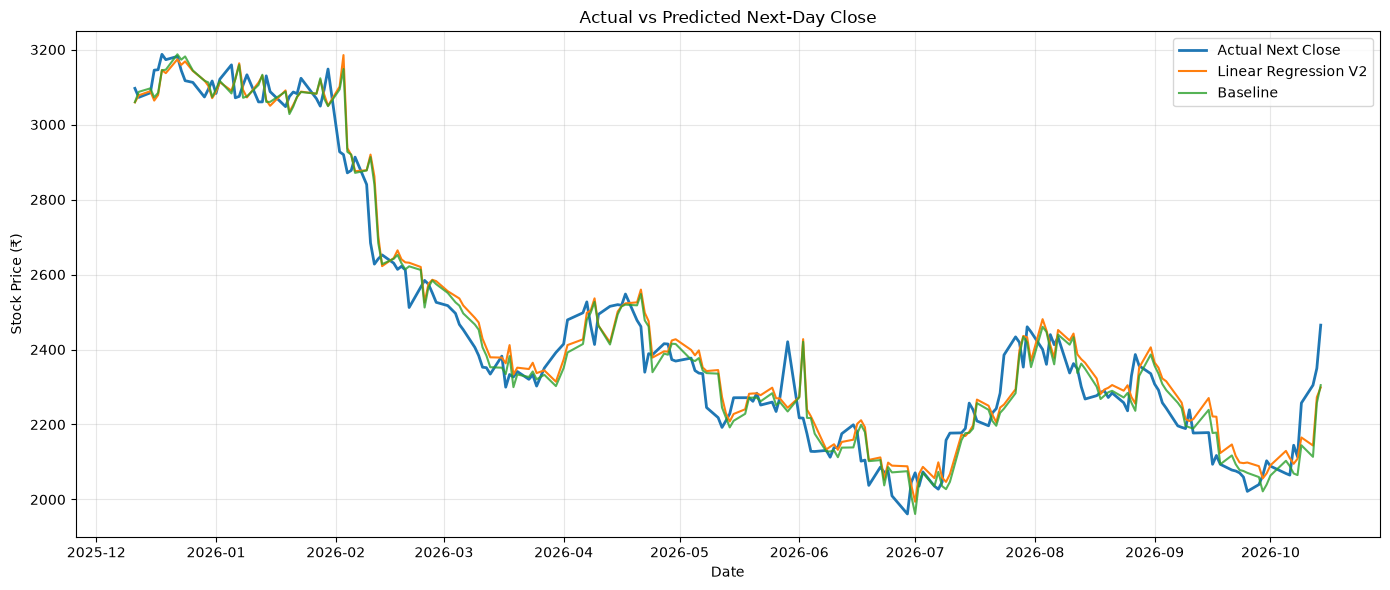

In [329]:
# STEP 130: Plot Actual vs Predicted Next-Day Close

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    y_test_v2.index,
    y_test_v2["Target_Next_Close"],
    label="Actual Next Close",
    linewidth=2
)

plt.plot(
    lr_predictions_v2.index,
    lr_predictions_v2["Target_Next_Close"],
    label="Linear Regression V2",
    linewidth=1.5
)

plt.plot(
    baseline_predictions_v2.index,
    baseline_predictions_v2["Target_Next_Close"],
    label="Baseline",
    linewidth=1.5,
    alpha=0.8
)

plt.title("Actual vs Predicted Next-Day Close")
plt.xlabel("Date")
plt.ylabel("Stock Price (₹)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [330]:
# STEP 130: Rebuild Engineered Features and Correct Targets

import numpy as np

# Start with original dataset
df_features = df.copy()

# Recreate engineered features
df_features["Return_5D"] = df_features["Close"].pct_change(5) * 100
df_features["Return_10D"] = df_features["Close"].pct_change(10) * 100

df_features["Close_MA20_Diff"] = (
    (df_features["Close"] - df_features["MA20"]) / df_features["MA20"]
) * 100

df_features["Close_MA50_Diff"] = (
    (df_features["Close"] - df_features["MA50"]) / df_features["MA50"]
) * 100

df_features["High_Low_Range"] = (
    (df_features["High"] - df_features["Low"]) / df_features["Close"]
) * 100

df_features["Open_Close_Change"] = (
    (df_features["Close"] - df_features["Open"]) / df_features["Open"]
) * 100

df_features["Volume_Change"] = df_features["Volume"].pct_change() * 100

# Correct targets: next trading session's original OHLC values
target_sources = ["Open", "High", "Low", "Close"]

for target, source in zip(target_columns, target_sources):
    df_features[target] = df_features[source].shift(-1)

# Clean invalid values
df_features = df_features.replace([np.inf, -np.inf], np.nan)

# Build clean dataset
df_clean_v2 = df_features[
    feature_columns_v2 + target_columns
].dropna().copy()

# Separate features and targets
X_v2 = df_clean_v2[feature_columns_v2]
y_v2 = df_clean_v2[target_columns]

# Chronological 80/20 split
split_index_v2 = int(len(df_clean_v2) * 0.80)

X_train_v2 = X_v2.iloc[:split_index_v2]
X_test_v2 = X_v2.iloc[split_index_v2:]

y_train_v2 = y_v2.iloc[:split_index_v2]
y_test_v2 = y_v2.iloc[split_index_v2:]

print("Clean dataset shape:", df_clean_v2.shape)
print("X_train:", X_train_v2.shape)
print("X_test:", X_test_v2.shape)
print("y_train:", y_train_v2.shape)
print("y_test:", y_test_v2.shape)

print("\nTraining dates:", X_train_v2.index.min(), "to", X_train_v2.index.max())
print("Testing dates:", X_test_v2.index.min(), "to", X_test_v2.index.max())
print("\nMissing values:", df_clean_v2.isnull().sum().sum())

print("\nFirst test sample:")
print("Feature date:", X_test_v2.index[0])
print("Next-session OHLC target:", y_test_v2.iloc[0].to_dict())

Clean dataset shape: (1035, 21)
X_train: (828, 17)
X_test: (207, 17)
y_train: (828, 4)
y_test: (207, 4)

Training dates: 2022-08-03 00:00:00 to 2025-12-11 00:00:00
Testing dates: 2025-12-12 00:00:00 to 2026-10-15 00:00:00

Missing values: 0

First test sample:
Feature date: 2025-12-12 00:00:00
Next-session OHLC target: {'Target_Next_Open': 3078.2462787239447, 'Target_Next_High': 3104.2249217750673, 'Target_Next_Low': 3065.0171835044, 'Target_Next_Close': 3096.555908203125}


In [331]:
# STEP 131: Train Linear Regression V2 on Corrected Data

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Train model
lr_model_v2 = LinearRegression()
lr_model_v2.fit(X_train_v2, y_train_v2)

# Predict next-day OHLC
lr_predictions_v2 = pd.DataFrame(
    lr_model_v2.predict(X_test_v2),
    index=X_test_v2.index,
    columns=target_columns
)

# Baseline: predict next-day OHLC using today's Close
baseline_predictions_v2 = pd.DataFrame(
    np.repeat(
        X_test_v2[["Close"]].to_numpy(),
        repeats=len(target_columns),
        axis=1
    ),
    index=X_test_v2.index,
    columns=target_columns
)

# Compare models
results_v2 = []

for target in target_columns:
    actual = y_test_v2[target]

    lr_mae = mean_absolute_error(actual, lr_predictions_v2[target])
    lr_rmse = np.sqrt(mean_squared_error(actual, lr_predictions_v2[target]))

    baseline_mae = mean_absolute_error(
        actual, baseline_predictions_v2[target]
    )
    baseline_rmse = np.sqrt(
        mean_squared_error(actual, baseline_predictions_v2[target])
    )

    improvement = (baseline_mae - lr_mae) / baseline_mae * 100

    results_v2.append({
        "Target": target,
        "Baseline MAE": round(baseline_mae, 2),
        "Linear Regression MAE": round(lr_mae, 2),
        "Baseline RMSE": round(baseline_rmse, 2),
        "Linear Regression RMSE": round(lr_rmse, 2),
        "MAE Improvement (%)": round(improvement, 2)
    })

results_v2_df = pd.DataFrame(results_v2)
print(results_v2_df.to_string(index=False))

           Target  Baseline MAE  Linear Regression MAE  Baseline RMSE  Linear Regression RMSE  MAE Improvement (%)
 Target_Next_Open         17.71                  18.17          28.51                   28.82                -2.57
 Target_Next_High         35.17                  27.88          47.88                   39.33                20.72
  Target_Next_Low         34.66                  29.20          49.31                   42.67                15.76
Target_Next_Close         35.08                  36.36          48.99                   50.07                -3.65


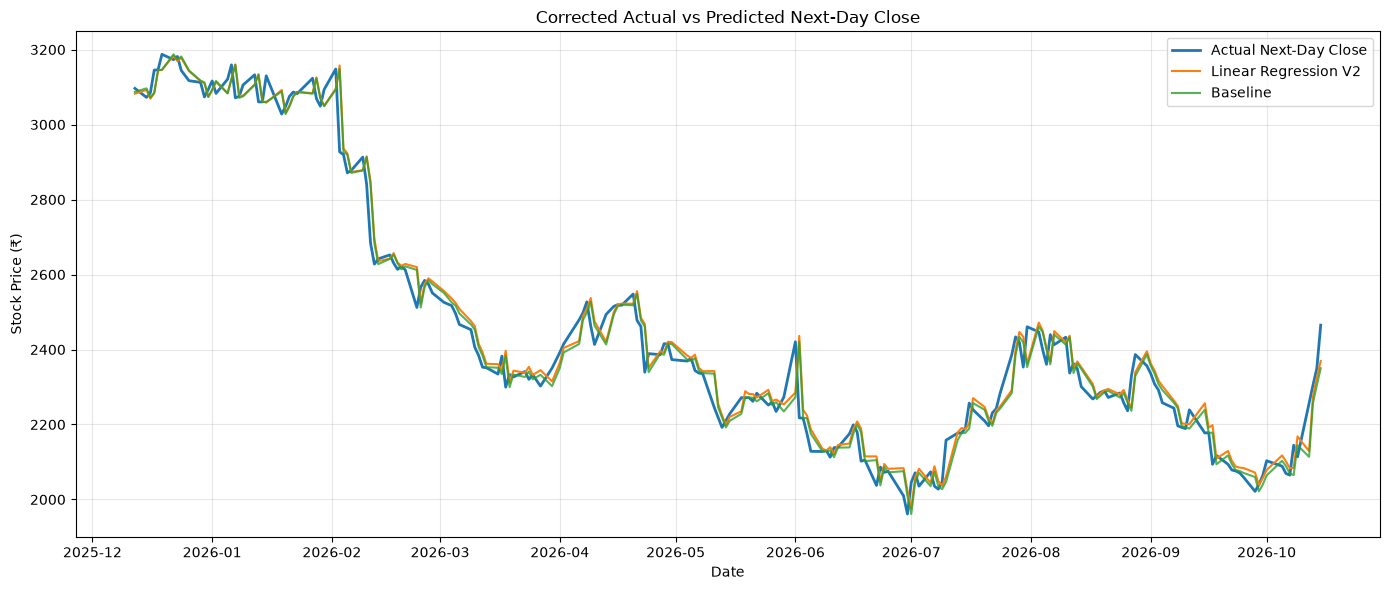

In [332]:
# STEP 132: Plot Corrected Next-Day Close Predictions

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    y_test_v2.index,
    y_test_v2["Target_Next_Close"],
    label="Actual Next-Day Close",
    linewidth=2
)

plt.plot(
    lr_predictions_v2.index,
    lr_predictions_v2["Target_Next_Close"],
    label="Linear Regression V2",
    linewidth=1.5
)

plt.plot(
    baseline_predictions_v2.index,
    baseline_predictions_v2["Target_Next_Close"],
    label="Baseline",
    linewidth=1.5,
    alpha=0.8
)

plt.title("Corrected Actual vs Predicted Next-Day Close")
plt.xlabel("Date")
plt.ylabel("Stock Price (₹)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [333]:
# STEP 133: Analyze Next-Day Close Prediction Errors

actual_close = y_test_v2["Target_Next_Close"]
lr_close_pred = lr_predictions_v2["Target_Next_Close"]
baseline_close_pred = baseline_predictions_v2["Target_Next_Close"]

lr_errors = (actual_close - lr_close_pred).abs()
baseline_errors = (actual_close - baseline_close_pred).abs()

error_summary = pd.DataFrame({
    "Error Threshold": ["Within ₹20", "Within ₹50", "Within ₹100"],
    "Linear Regression (%)": [
        (lr_errors <= 20).mean() * 100,
        (lr_errors <= 50).mean() * 100,
        (lr_errors <= 100).mean() * 100
    ],
    "Baseline (%)": [
        (baseline_errors <= 20).mean() * 100,
        (baseline_errors <= 50).mean() * 100,
        (baseline_errors <= 100).mean() * 100
    ]
})

error_summary[["Linear Regression (%)", "Baseline (%)"]] = (
    error_summary[["Linear Regression (%)", "Baseline (%)"]].round(2)
)

print(error_summary.to_string(index=False))

Error Threshold  Linear Regression (%)  Baseline (%)
     Within ₹20                  36.23         39.61
     Within ₹50                  76.33         80.19
    Within ₹100                  96.14         94.69


In [334]:
# STEP 134: Compare Latest 10 Close Predictions

comparison_v2 = pd.DataFrame({
    "Actual Next Close": y_test_v2["Target_Next_Close"],
    "Linear Regression": lr_predictions_v2["Target_Next_Close"],
    "Baseline": baseline_predictions_v2["Target_Next_Close"]
})

comparison_v2["LR Absolute Error"] = (
    comparison_v2["Actual Next Close"] -
    comparison_v2["Linear Regression"]
).abs()

comparison_v2["Baseline Absolute Error"] = (
    comparison_v2["Actual Next Close"] -
    comparison_v2["Baseline"]
).abs()

print(comparison_v2.tail(10).round(2).to_string())

            Actual Next Close  Linear Regression  Baseline  LR Absolute Error  Baseline Absolute Error
Date                                                                                                  
2026-10-01            2103.22            2078.90   2064.03              24.32                    39.19
2026-10-05            2088.90            2117.52   2103.22              28.63                    14.32
2026-10-06            2069.30            2101.54   2088.90              32.24                    19.60
2026-10-07            2065.02            2083.54   2069.30              18.52                     4.28
2026-10-08            2144.60            2084.25   2065.02              60.35                    79.58
2026-10-09            2113.76            2167.99   2144.60              54.22                    30.84
2026-10-12            2257.30            2128.85   2113.76             128.45                   143.54
2026-10-13            2304.90            2276.46   2257.30              2

In [335]:
# STEP 135: Train Random Forest V2

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

rf_model_v2 = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_model_v2.fit(X_train_v2, y_train_v2)

rf_predictions_v2 = pd.DataFrame(
    rf_model_v2.predict(X_test_v2),
    index=X_test_v2.index,
    columns=target_columns
)

rf_results = []

for target in target_columns:
    actual = y_test_v2[target]

    rf_mae = mean_absolute_error(actual, rf_predictions_v2[target])
    rf_rmse = np.sqrt(
        mean_squared_error(actual, rf_predictions_v2[target])
    )

    lr_mae = mean_absolute_error(actual, lr_predictions_v2[target])
    baseline_mae = mean_absolute_error(
        actual, baseline_predictions_v2[target]
    )

    rf_results.append({
        "Target": target,
        "Random Forest MAE": round(rf_mae, 2),
        "Random Forest RMSE": round(rf_rmse, 2),
        "Linear Regression MAE": round(lr_mae, 2),
        "Baseline MAE": round(baseline_mae, 2)
    })

rf_results_df = pd.DataFrame(rf_results)

print(rf_results_df.to_string(index=False))

           Target  Random Forest MAE  Random Forest RMSE  Linear Regression MAE  Baseline MAE
 Target_Next_Open             299.10              358.79                  18.17         17.71
 Target_Next_High             301.69              360.57                  27.88         35.17
  Target_Next_Low             303.83              361.19                  29.20         34.66
Target_Next_Close             309.50              367.15                  36.36         35.08


In [336]:
# STEP 136: Diagnose Random Forest Predictions

rf_close_train_pred = rf_model_v2.predict(X_train_v2)
rf_close_test_pred = rf_predictions_v2["Target_Next_Close"]

print("Training Close target statistics:")
print(y_train_v2["Target_Next_Close"].describe().round(2))

print("\nActual Test Close statistics:")
print(y_test_v2["Target_Next_Close"].describe().round(2))

print("\nRandom Forest Test Predictions:")
print(rf_close_test_pred.describe().round(2))

print("\nAverage actual test Close:",
      round(y_test_v2["Target_Next_Close"].mean(), 2))

print("Average RF predicted Close:",
      round(rf_close_test_pred.mean(), 2))

print("\nFirst 10 actual vs RF predictions:")
print(pd.DataFrame({
    "Actual Close": y_test_v2["Target_Next_Close"],
    "RF Predicted Close": rf_close_test_pred
}).head(10).round(2).to_string())

Training Close target statistics:
count     828.00
mean     3287.04
std       403.98
min      2610.58
25%      2947.80
50%      3187.49
75%      3610.09
max      4208.34
Name: Target_Next_Close, dtype: float64

Actual Test Close statistics:
count     207.00
mean     2445.67
std       342.62
min      1961.36
25%      2204.27
50%      2343.89
75%      2549.45
max      3187.34
Name: Target_Next_Close, dtype: float64

Random Forest Test Predictions:
count     207.00
mean     2748.87
std       165.65
min      2638.11
25%      2659.52
50%      2675.13
75%      2688.32
max      3175.05
Name: Target_Next_Close, dtype: float64

Average actual test Close: 2445.67
Average RF predicted Close: 2748.87

First 10 actual vs RF predictions:
            Actual Close  RF Predicted Close
Date                                        
2025-12-12       3096.56             3085.74
2025-12-15       3072.49             3096.53
2025-12-16       3084.67             3062.19
2025-12-17       3145.06             3087

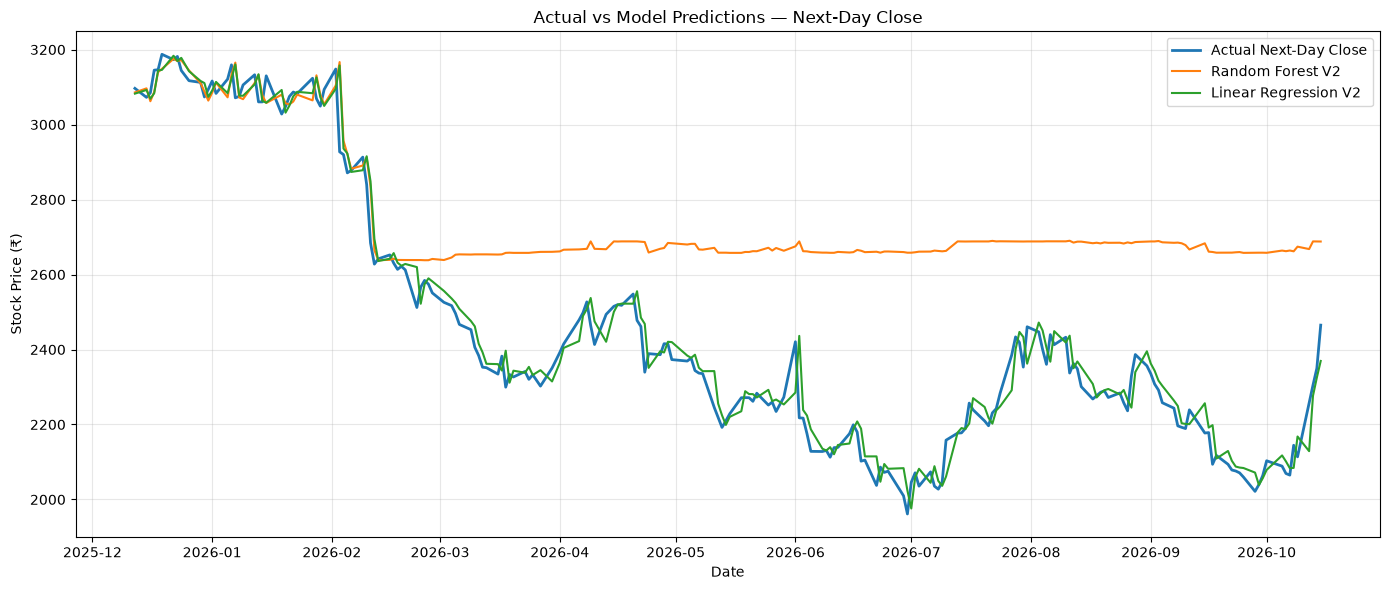

In [337]:
# STEP 137: Compare Random Forest, Linear Regression and Actual Close

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    y_test_v2.index,
    y_test_v2["Target_Next_Close"],
    label="Actual Next-Day Close",
    linewidth=2
)

plt.plot(
    rf_predictions_v2.index,
    rf_predictions_v2["Target_Next_Close"],
    label="Random Forest V2",
    linewidth=1.5
)

plt.plot(
    lr_predictions_v2.index,
    lr_predictions_v2["Target_Next_Close"],
    label="Linear Regression V2",
    linewidth=1.5
)

plt.title("Actual vs Model Predictions — Next-Day Close")
plt.xlabel("Date")
plt.ylabel("Stock Price (₹)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [338]:
# STEP 138: Train Gradient Boosting V2

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

gb_model_v2 = MultiOutputRegressor(
    GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        min_samples_leaf=5,
        random_state=42
    )
)

gb_model_v2.fit(X_train_v2, y_train_v2)

gb_predictions_v2 = pd.DataFrame(
    gb_model_v2.predict(X_test_v2),
    index=X_test_v2.index,
    columns=target_columns
)

gb_results = []

for target in target_columns:
    actual = y_test_v2[target]

    gb_mae = mean_absolute_error(actual, gb_predictions_v2[target])
    gb_rmse = np.sqrt(
        mean_squared_error(actual, gb_predictions_v2[target])
    )

    gb_results.append({
        "Target": target,
        "Gradient Boosting MAE": round(gb_mae, 2),
        "Gradient Boosting RMSE": round(gb_rmse, 2),
        "Linear Regression MAE": round(
            mean_absolute_error(actual, lr_predictions_v2[target]), 2
        ),
        "Baseline MAE": round(
            mean_absolute_error(actual, baseline_predictions_v2[target]), 2
        )
    })

gb_results_df = pd.DataFrame(gb_results)
print(gb_results_df.to_string(index=False))

           Target  Gradient Boosting MAE  Gradient Boosting RMSE  Linear Regression MAE  Baseline MAE
 Target_Next_Open                 280.94                  339.79                  18.17         17.71
 Target_Next_High                 290.03                  347.13                  27.88         35.17
  Target_Next_Low                 293.93                  350.67                  29.20         34.66
Target_Next_Close                 303.91                  360.65                  36.36         35.08


In [339]:
# STEP 139: Compare Models Across All Four Targets

final_comparison_v2 = pd.DataFrame({
    "Target": target_columns,
    "Baseline MAE": [
        mean_absolute_error(y_test_v2[t], baseline_predictions_v2[t])
        for t in target_columns
    ],
    "Linear Regression MAE": [
        mean_absolute_error(y_test_v2[t], lr_predictions_v2[t])
        for t in target_columns
    ],
    "Random Forest MAE": [
        mean_absolute_error(y_test_v2[t], rf_predictions_v2[t])
        for t in target_columns
    ],
    "Gradient Boosting MAE": [
        mean_absolute_error(y_test_v2[t], gb_predictions_v2[t])
        for t in target_columns
    ]
}).round(2)

model_columns = [
    "Baseline MAE",
    "Linear Regression MAE",
    "Random Forest MAE",
    "Gradient Boosting MAE"
]

final_comparison_v2["Best Model"] = (
    final_comparison_v2[model_columns]
    .idxmin(axis=1)
    .str.replace(" MAE", "", regex=False)
)

print(final_comparison_v2.to_string(index=False))

           Target  Baseline MAE  Linear Regression MAE  Random Forest MAE  Gradient Boosting MAE        Best Model
 Target_Next_Open         17.71                  18.17             299.10                 280.94          Baseline
 Target_Next_High         35.17                  27.88             301.69                 290.03 Linear Regression
  Target_Next_Low         34.66                  29.20             303.83                 293.93 Linear Regression
Target_Next_Close         35.08                  36.36             309.50                 303.91          Baseline


In [340]:
# STEP 140: Walk-Forward Validation
from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
import numpy as np
import pandas as pd

tscv_v2 = TimeSeriesSplit(n_splits=3)
walk_forward_results = []

for fold, (train_idx, val_idx) in enumerate(tscv_v2.split(X_v2), start=1):

    X_train_fold = X_v2.iloc[train_idx]
    X_val_fold = X_v2.iloc[val_idx]

    y_train_fold = y_v2.iloc[train_idx]
    y_val_fold = y_v2.iloc[val_idx]

    model = LinearRegression()
    model.fit(X_train_fold, y_train_fold)

    predictions = pd.DataFrame(
        model.predict(X_val_fold),
        index=X_val_fold.index,
        columns=target_columns
    )

    baseline = pd.DataFrame(
        np.repeat(
            X_val_fold[["Close"]].to_numpy(),
            repeats=len(target_columns),
            axis=1
        ),
        index=X_val_fold.index,
        columns=target_columns
    )

    for target in target_columns:
        lr_mae = mean_absolute_error(
            y_val_fold[target], predictions[target]
        )
        baseline_mae = mean_absolute_error(
            y_val_fold[target], baseline[target]
        )

        walk_forward_results.append({
            "Fold": fold,
            "Target": target,
            "Linear Regression MAE": round(lr_mae, 2),
            "Baseline MAE": round(baseline_mae, 2),
            "Better Model": (
                "Linear Regression"
                if lr_mae < baseline_mae
                else "Baseline"
            )
        })

walk_forward_df = pd.DataFrame(walk_forward_results)

print(walk_forward_df.to_string(index=False))

print("\nAverage MAE across folds:")
print(
    walk_forward_df.groupby("Target")[
        ["Linear Regression MAE", "Baseline MAE"]
    ].mean().round(2)
)

 Fold            Target  Linear Regression MAE  Baseline MAE      Better Model
    1  Target_Next_Open                  25.18         14.44          Baseline
    1  Target_Next_High                  62.56         38.72          Baseline
    1   Target_Next_Low                  47.88         30.49          Baseline
    1 Target_Next_Close                  87.37         33.02          Baseline
    2  Target_Next_Open                  19.88         16.96          Baseline
    2  Target_Next_High                  29.15         31.86 Linear Regression
    2   Target_Next_Low                  25.67         36.27 Linear Regression
    2 Target_Next_Close                  36.57         31.74          Baseline
    3  Target_Next_Open                  15.94         15.68          Baseline
    3  Target_Next_High                  26.02         33.59 Linear Regression
    3   Target_Next_Low                  26.18         31.68 Linear Regression
    3 Target_Next_Close                  33.67      

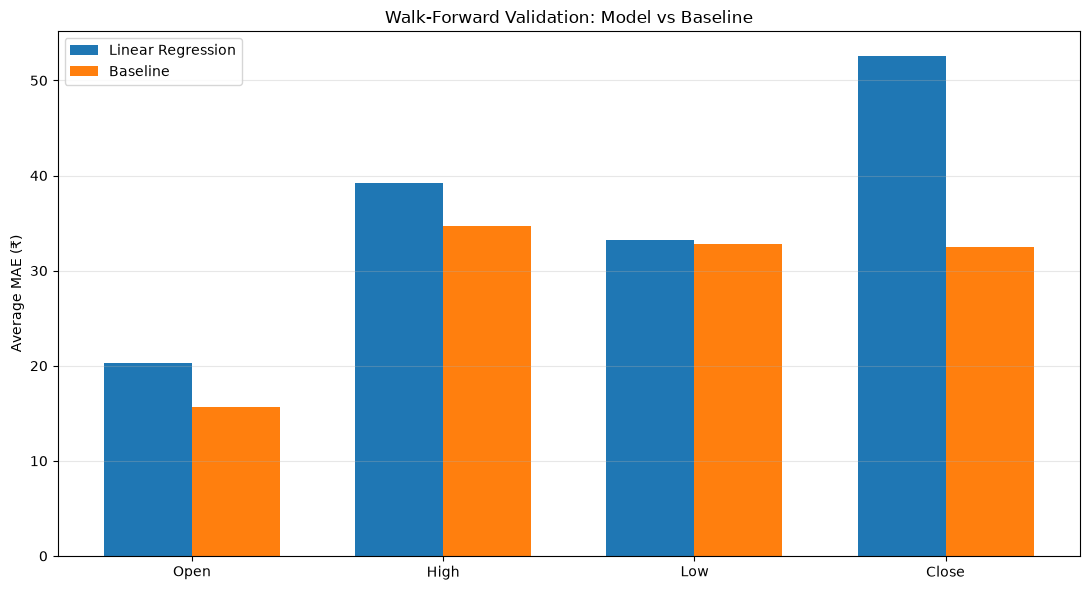

In [341]:
# STEP 141: Plot Walk-Forward Average MAE

import matplotlib.pyplot as plt
import numpy as np

average_errors = (
    walk_forward_df.groupby("Target")[
        ["Linear Regression MAE", "Baseline MAE"]
    ]
    .mean()
)

labels = ["Open", "High", "Low", "Close"]
x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(11, 6))

plt.bar(
    x - width / 2,
    average_errors.loc[target_columns, "Linear Regression MAE"],
    width,
    label="Linear Regression"
)

plt.bar(
    x + width / 2,
    average_errors.loc[target_columns, "Baseline MAE"],
    width,
    label="Baseline"
)

plt.xticks(x, labels)
plt.ylabel("Average MAE (₹)")
plt.title("Walk-Forward Validation: Model vs Baseline")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [342]:
# STEP 142: Create Next-Day Percentage Return Target

df_return = df_features.copy()

# Next-day Close return relative to today's Close
df_return["Target_Next_Return"] = (
    (df_return["Target_Next_Close"] / df_return["Close"]) - 1
) * 100

# Keep only rows with complete features and return target
return_columns = feature_columns_v2 + ["Target_Next_Return"]

df_return_clean = (
    df_return[return_columns]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .copy()
)

X_return = df_return_clean[feature_columns_v2]
y_return = df_return_clean["Target_Next_Return"]

# Chronological 80/20 split
split_return = int(len(df_return_clean) * 0.80)

X_train_return = X_return.iloc[:split_return]
X_test_return = X_return.iloc[split_return:]

y_train_return = y_return.iloc[:split_return]
y_test_return = y_return.iloc[split_return:]

print("Dataset shape:", df_return_clean.shape)
print("Training samples:", len(X_train_return))
print("Testing samples:", len(X_test_return))

print("\nTraining return statistics (%):")
print(y_train_return.describe().round(3))

print("\nTesting return statistics (%):")
print(y_test_return.describe().round(3))

Dataset shape: (1035, 18)
Training samples: 828
Testing samples: 207

Training return statistics (%):
count    828.000
mean       0.012
std        1.243
min       -4.219
25%       -0.653
50%       -0.053
75%        0.632
max        6.633
Name: Target_Next_Return, dtype: float64

Testing return statistics (%):
count    207.000
mean      -0.082
std        2.016
min       -8.386
25%       -1.127
50%       -0.118
75%        0.955
max        6.791
Name: Target_Next_Return, dtype: float64


In [343]:
# STEP 143: Predict Next-Day Percentage Return

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Train model
return_model = LinearRegression()
return_model.fit(X_train_return, y_train_return)

# Predict next-day percentage return
return_predictions = pd.Series(
    return_model.predict(X_test_return),
    index=X_test_return.index,
    name="Predicted_Return_Percent"
)

# Zero-return baseline: assume tomorrow's return is 0%
zero_return_predictions = pd.Series(
    0.0,
    index=y_test_return.index,
    name="Zero_Return_Baseline"
)

# Evaluate both approaches
model_mae = mean_absolute_error(
    y_test_return, return_predictions
)
model_rmse = np.sqrt(
    mean_squared_error(y_test_return, return_predictions)
)

baseline_mae = mean_absolute_error(
    y_test_return, zero_return_predictions
)
baseline_rmse = np.sqrt(
    mean_squared_error(y_test_return, zero_return_predictions)
)

return_results = pd.DataFrame({
    "Metric": ["MAE (%)", "RMSE (%)"],
    "Linear Regression": [model_mae, model_rmse],
    "Zero-Return Baseline": [baseline_mae, baseline_rmse]
}).round(4)

print(return_results.to_string(index=False))

print("\nAverage actual return (%):",
      round(y_test_return.mean(), 4))

print("Average predicted return (%):",
      round(return_predictions.mean(), 4))

print("\nFirst 10 actual vs predicted returns:")
print(pd.DataFrame({
    "Actual Return (%)": y_test_return,
    "Predicted Return (%)": return_predictions
}).head(10).round(3).to_string())

  Metric  Linear Regression  Zero-Return Baseline
 MAE (%)             1.4840                 1.448
RMSE (%)             2.0322                 2.013

Average actual return (%): -0.0819
Average predicted return (%): 0.2435

First 10 actual vs predicted returns:
            Actual Return (%)  Predicted Return (%)
Date                                               
2025-12-12              0.301                -0.157
2025-12-15             -0.777                -0.147
2025-12-16              0.396                -0.113
2025-12-17              1.958                -0.044
2025-12-18              0.037                -0.028
2025-12-19              1.307                -0.019
2025-12-22             -0.448                -0.118
2025-12-23              0.272                -0.113
2025-12-24             -1.175                -0.126
2025-12-26             -0.869                -0.062


In [344]:
# STEP 144: Convert Predicted Returns into Next-Day Close Prices

today_close_return = X_test_return["Close"]

predicted_close_from_return = (
    today_close_return * (1 + return_predictions / 100)
)

actual_next_close_return = df_return_clean.loc[
    X_test_return.index, "Target_Next_Return"
]

actual_next_close_price = (
    today_close_return * (1 + actual_next_close_return / 100)
)

zero_return_close = today_close_return.copy()

price_comparison_return = pd.DataFrame({
    "Actual Next Close": actual_next_close_price,
    "Predicted Close (Return Model)": predicted_close_from_return,
    "Zero-Return Baseline Close": zero_return_close
})

price_comparison_return["Return Model Error"] = (
    price_comparison_return["Actual Next Close"] -
    price_comparison_return["Predicted Close (Return Model)"]
).abs()

price_comparison_return["Baseline Error"] = (
    price_comparison_return["Actual Next Close"] -
    price_comparison_return["Zero-Return Baseline Close"]
).abs()

print("Price MAE — Return Model:",
      round(price_comparison_return["Return Model Error"].mean(), 2))

print("Price MAE — Zero-Return Baseline:",
      round(price_comparison_return["Baseline Error"].mean(), 2))

print("\nLatest 10 samples:")
print(price_comparison_return.tail(10).round(2).to_string())

Price MAE — Return Model: 35.97
Price MAE — Zero-Return Baseline: 35.08

Latest 10 samples:
            Actual Next Close  Predicted Close (Return Model)  Zero-Return Baseline Close  Return Model Error  Baseline Error
Date                                                                                                                         
2026-10-01            2103.22                         2073.63                     2064.03               29.58           39.19
2026-10-05            2088.90                         2112.22                     2103.22               23.32           14.32
2026-10-06            2069.30                         2097.20                     2088.90               27.90           19.60
2026-10-07            2065.02                         2078.57                     2069.30               13.55            4.28
2026-10-08            2144.60                         2077.17                     2065.02               67.43           79.58
2026-10-09            2113

In [345]:
# STEP 145: Analyze Return Prediction Bias

return_diagnostics = pd.DataFrame({
    "Actual Return (%)": y_test_return,
    "Predicted Return (%)": return_predictions
})

return_diagnostics["Prediction Error (%)"] = (
    return_diagnostics["Predicted Return (%)"] -
    return_diagnostics["Actual Return (%)"]
)

print("Actual average return (%):",
      round(return_diagnostics["Actual Return (%)"].mean(), 4))

print("Predicted average return (%):",
      round(return_diagnostics["Predicted Return (%)"].mean(), 4))

print("Average prediction bias (%):",
      round(return_diagnostics["Prediction Error (%)"].mean(), 4))

print("\nPrediction error statistics:")
print(
    return_diagnostics["Prediction Error (%)"]
    .describe()
    .round(4)
)

print("\nCorrelation between actual and predicted returns:",
      round(
          return_diagnostics["Actual Return (%)"].corr(
              return_diagnostics["Predicted Return (%)"]
          ),
          4
      ))

Actual average return (%): -0.0819
Predicted average return (%): 0.2435
Average prediction bias (%): 0.3254

Prediction error statistics:
count    207.0000
mean       0.3254
std        2.0108
min       -6.3321
25%       -0.6749
50%        0.3780
75%        1.3294
max        8.7735
Name: Prediction Error (%), dtype: float64

Correlation between actual and predicted returns: 0.0736


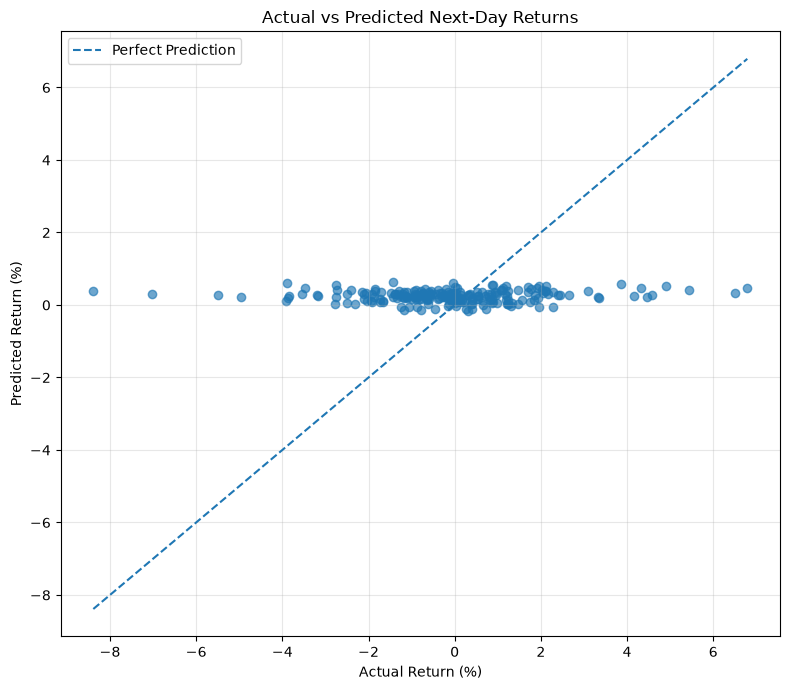

In [346]:
# STEP 146: Actual vs Predicted Return Scatter Plot

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 7))

plt.scatter(
    y_test_return,
    return_predictions,
    alpha=0.65
)

# Reference line: perfect prediction
lower = min(y_test_return.min(), return_predictions.min())
upper = max(y_test_return.max(), return_predictions.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--",
    label="Perfect Prediction"
)

plt.title("Actual vs Predicted Next-Day Returns")
plt.xlabel("Actual Return (%)")
plt.ylabel("Predicted Return (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [347]:
# STEP 147: Prepare Next-Day Direction Classification

import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

# Target: 1 if next-day return is positive, otherwise 0
y_direction = (y_return > 0).astype(int)

# Chronological split: use the same dates as return prediction
y_train_direction = y_direction.iloc[:split_return]
y_test_direction = y_direction.iloc[split_return:]

# Train classifier
direction_model = LogisticRegression(
    max_iter=2000,
    class_weight=None,
    random_state=42
)

direction_model.fit(X_train_return, y_train_direction)

# Predict direction
direction_predictions = pd.Series(
    direction_model.predict(X_test_return),
    index=X_test_return.index,
    name="Predicted_Direction"
)

# Majority-class baseline using training data only
majority_class = y_train_direction.mode().iloc[0]

direction_baseline = pd.Series(
    majority_class,
    index=y_test_direction.index
)

print("Training positive-return rate (%):",
      round(y_train_direction.mean() * 100, 2))

print("Testing positive-return rate (%):",
      round(y_test_direction.mean() * 100, 2))

print("\nAccuracy:")
print("Logistic Regression:",
      round(accuracy_score(y_test_direction, direction_predictions), 4))

print("Majority-class baseline:",
      round(accuracy_score(y_test_direction, direction_baseline), 4))

print("\nBalanced Accuracy:",
      round(
          balanced_accuracy_score(
              y_test_direction, direction_predictions
          ),
          4
      ))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_direction, direction_predictions))

print("\nClassification Report:")
print(
    classification_report(
        y_test_direction,
        direction_predictions,
        labels=[0, 1],
        target_names=["Down/Flat", "Up"],
        zero_division=0
    )
)

Training positive-return rate (%): 47.95
Testing positive-return rate (%): 45.89

Accuracy:
Logistic Regression: 0.4396
Majority-class baseline: 0.5411

Balanced Accuracy: 0.4574

Confusion Matrix:
[[27 85]
 [31 64]]

Classification Report:
              precision    recall  f1-score   support

   Down/Flat       0.47      0.24      0.32       112
          Up       0.43      0.67      0.52        95

    accuracy                           0.44       207
   macro avg       0.45      0.46      0.42       207
weighted avg       0.45      0.44      0.41       207



In [348]:
# STEP 148: Train Scaled Logistic Regression

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)
import pandas as pd

# Pipeline: scaling + classification
direction_model_scaled = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=5000,
        random_state=42
    ))
])

# Train on chronological training data
direction_model_scaled.fit(
    X_train_return,
    y_train_direction
)

# Predict test-set direction
scaled_predictions = pd.Series(
    direction_model_scaled.predict(X_test_return),
    index=X_test_return.index,
    name="Predicted_Direction_Scaled"
)

# Evaluate
scaled_accuracy = accuracy_score(
    y_test_direction, scaled_predictions
)

scaled_balanced_accuracy = balanced_accuracy_score(
    y_test_direction, scaled_predictions
)

baseline_accuracy = accuracy_score(
    y_test_direction, direction_baseline
)

print("Scaled Logistic Regression Accuracy:",
      round(scaled_accuracy, 4))

print("Majority-Class Baseline Accuracy:",
      round(baseline_accuracy, 4))

print("Scaled Balanced Accuracy:",
      round(scaled_balanced_accuracy, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_direction, scaled_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test_direction,
    scaled_predictions,
    labels=[0, 1],
    target_names=["Down/Flat", "Up"],
    zero_division=0
))

Scaled Logistic Regression Accuracy: 0.4638
Majority-Class Baseline Accuracy: 0.5411
Scaled Balanced Accuracy: 0.4909

Confusion Matrix:
[[18 94]
 [17 78]]

Classification Report:
              precision    recall  f1-score   support

   Down/Flat       0.51      0.16      0.24       112
          Up       0.45      0.82      0.58        95

    accuracy                           0.46       207
   macro avg       0.48      0.49      0.41       207
weighted avg       0.49      0.46      0.40       207



In [349]:

# STEP 149: Analyze Predicted Up Probabilities

from sklearn.metrics import (
    brier_score_loss,
    log_loss
)
import pandas as pd

# Probability that next-day direction is Up (class 1)
up_probabilities = pd.Series(
    direction_model_scaled.predict_proba(X_test_return)[:, 1],
    index=X_test_return.index,
    name="Predicted_Up_Probability"
)

# Constant probability baseline: training-set up rate
training_up_rate = y_train_direction.mean()

constant_probabilities = pd.Series(
    training_up_rate,
    index=y_test_direction.index
)

print("Training Up Rate (%):",
      round(training_up_rate * 100, 2))

print("Average Predicted Up Probability (%):",
      round(up_probabilities.mean() * 100, 2))

print("Minimum Predicted Up Probability (%):",
      round(up_probabilities.min() * 100, 2))

print("Maximum Predicted Up Probability (%):",
      round(up_probabilities.max() * 100, 2))

print("\nBrier Score (lower is better):")
print("Scaled Logistic Regression:",
      round(brier_score_loss(y_test_direction, up_probabilities), 4))

print("Constant Probability Baseline:",
      round(brier_score_loss(y_test_direction, constant_probabilities), 4))

print("\nLog Loss (lower is better):")
print("Scaled Logistic Regression:",
      round(log_loss(y_test_direction, up_probabilities), 4))

print("Constant Probability Baseline:",
      round(log_loss(y_test_direction, constant_probabilities), 4))

print("\nFirst 10 probabilities:")
print(pd.DataFrame({
    "Actual Direction": y_test_direction,
    "Predicted Up Probability (%)": up_probabilities * 100
}).head(10).round(2).to_string())


Training Up Rate (%): 47.95
Average Predicted Up Probability (%): 57.98
Minimum Predicted Up Probability (%): 34.72
Maximum Predicted Up Probability (%): 82.24

Brier Score (lower is better):
Scaled Logistic Regression: 0.2708
Constant Probability Baseline: 0.2487

Log Loss (lower is better):
Scaled Logistic Regression: 0.7369
Constant Probability Baseline: 0.6906

First 10 probabilities:
            Actual Direction  Predicted Up Probability (%)
Date                                                      
2025-12-12                 1                         42.39
2025-12-15                 0                         40.63
2025-12-16                 1                         41.74
2025-12-17                 1                         43.77
2025-12-18                 1                         47.11
2025-12-19                 1                         45.11
2025-12-22                 0                         45.14
2025-12-23                 1                         41.81
2025-12-24        

In [350]:
# STEP 150: Check Feature Correlation (Fixed)

import numpy as np
import pandas as pd

correlation_matrix_v2 = X_train_return.corr()

# Get only unique feature pairs
upper_triangle = correlation_matrix_v2.where(
    np.triu(
        np.ones(correlation_matrix_v2.shape),
        k=1
    ).astype(bool)
)

# Convert pairs into a DataFrame without index-name conflicts
pairs = []

for i in range(len(correlation_matrix_v2.columns)):
    for j in range(i + 1, len(correlation_matrix_v2.columns)):
        correlation = correlation_matrix_v2.iloc[i, j]

        if pd.notna(correlation) and abs(correlation) >= 0.90:
            pairs.append({
                "Feature 1": correlation_matrix_v2.columns[i],
                "Feature 2": correlation_matrix_v2.columns[j],
                "Correlation": correlation
            })

high_correlation_pairs = pd.DataFrame(
    pairs,
    columns=["Feature 1", "Feature 2", "Correlation"]
)

if not high_correlation_pairs.empty:
    high_correlation_pairs["Absolute Correlation"] = (
        high_correlation_pairs["Correlation"].abs()
    )

    high_correlation_pairs = high_correlation_pairs.sort_values(
        "Absolute Correlation",
        ascending=False
    )

print("Number of feature pairs with |correlation| >= 0.90:",
      len(high_correlation_pairs))

print("\nHighly correlated feature pairs:")

if high_correlation_pairs.empty:
    print("No highly correlated feature pairs found.")
else:
    print(high_correlation_pairs.round(3).to_string(index=False))

Number of feature pairs with |correlation| >= 0.90: 18

Highly correlated feature pairs:
 Feature 1       Feature 2  Correlation  Absolute Correlation
     Close            High        0.999                 0.999
       Low            Open        0.998                 0.998
     Close             Low        0.998                 0.998
      High             Low        0.998                 0.998
      High            Open        0.998                 0.998
     Close            Open        0.996                 0.996
      Open            MA20        0.971                 0.971
      High            MA20        0.970                 0.970
      MA20            MA50        0.970                 0.970
       Low            MA20        0.969                 0.969
     Close            MA20        0.968                 0.968
    RSI_14 Close_MA20_Diff        0.943                 0.943
    RSI_14 Close_MA50_Diff        0.926                 0.926
      High            MA50        0.923    

In [351]:
# STEP 151: Create Reduced Feature Dataset

reduced_features = [
    "Close",
    "Volume",
    "Daily_Return",
    "MA20",
    "MA200",
    "RSI_14",
    "Return_5D",
    "Return_10D",
    "High_Low_Range",
    "Volume_Change"
]

# Use the existing correctly aligned return dataset
df_reduced = df_return_clean[
    reduced_features + ["Target_Next_Return"]
].copy()

X_reduced = df_reduced[reduced_features]
y_reduced = df_reduced["Target_Next_Return"]

# Chronological 80/20 split
split_reduced = int(len(df_reduced) * 0.80)

X_train_reduced = X_reduced.iloc[:split_reduced]
X_test_reduced = X_reduced.iloc[split_reduced:]

y_train_reduced = y_reduced.iloc[:split_reduced]
y_test_reduced = y_reduced.iloc[split_reduced:]

print("Reduced dataset shape:", df_reduced.shape)
print("Number of features:", len(reduced_features))
print("Training shape:", X_train_reduced.shape)
print("Testing shape:", X_test_reduced.shape)

print("\nReduced feature columns:")
print(reduced_features)

print("\nMissing values:", int(df_reduced.isna().sum().sum()))

print("\nTraining dates:",
      X_train_reduced.index.min(), "to", X_train_reduced.index.max())

print("Testing dates:",
      X_test_reduced.index.min(), "to", X_test_reduced.index.max())

Reduced dataset shape: (1035, 11)
Number of features: 10
Training shape: (828, 10)
Testing shape: (207, 10)

Reduced feature columns:
['Close', 'Volume', 'Daily_Return', 'MA20', 'MA200', 'RSI_14', 'Return_5D', 'Return_10D', 'High_Low_Range', 'Volume_Change']

Missing values: 0

Training dates: 2022-08-03 00:00:00 to 2025-12-11 00:00:00
Testing dates: 2025-12-12 00:00:00 to 2026-10-15 00:00:00


In [352]:
# STEP 152: Train Reduced-Feature Linear Regression

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Scaling + Linear Regression
reduced_return_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

# Train model
reduced_return_model.fit(
    X_train_reduced,
    y_train_reduced
)

# Predict returns
reduced_return_predictions = pd.Series(
    reduced_return_model.predict(X_test_reduced),
    index=X_test_reduced.index,
    name="Predicted_Return_Reduced"
)

# Zero-return baseline
zero_return_baseline_reduced = pd.Series(
    0.0,
    index=y_test_reduced.index
)

# Evaluate
reduced_mae = mean_absolute_error(
    y_test_reduced,
    reduced_return_predictions
)

reduced_rmse = np.sqrt(
    mean_squared_error(
        y_test_reduced,
        reduced_return_predictions
    )
)

baseline_mae_reduced = mean_absolute_error(
    y_test_reduced,
    zero_return_baseline_reduced
)

baseline_rmse_reduced = np.sqrt(
    mean_squared_error(
        y_test_reduced,
        zero_return_baseline_reduced
    )
)

# Compare against full-feature model
full_mae = mean_absolute_error(
    y_test_return,
    return_predictions
)

full_rmse = np.sqrt(
    mean_squared_error(
        y_test_return,
        return_predictions
    )
)

results_reduced = pd.DataFrame({
    "Model": [
        "Full-Feature Linear Regression",
        "Reduced-Feature Linear Regression",
        "Zero-Return Baseline"
    ],
    "MAE (%)": [
        full_mae,
        reduced_mae,
        baseline_mae_reduced
    ],
    "RMSE (%)": [
        full_rmse,
        reduced_rmse,
        baseline_rmse_reduced
    ]
})

print(results_reduced.round(4).to_string(index=False))

print("\nAverage predicted return (%):",
      round(reduced_return_predictions.mean(), 4))

print("Correlation with actual returns:",
      round(
          y_test_reduced.corr(reduced_return_predictions),
          4
      ))

                            Model  MAE (%)  RMSE (%)
   Full-Feature Linear Regression   1.4840    2.0322
Reduced-Feature Linear Regression   1.4829    2.0327
             Zero-Return Baseline   1.4480    2.0130

Average predicted return (%): 0.2431
Correlation with actual returns: 0.0697


In [353]:
# STEP 153: Random Forest for Next-Day Return Prediction

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Create model
rf_return_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=6,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

# Train using reduced features
rf_return_model.fit(
    X_train_reduced,
    y_train_reduced
)

# Predict next-day percentage returns
rf_return_predictions = pd.Series(
    rf_return_model.predict(X_test_reduced),
    index=X_test_reduced.index,
    name="Random_Forest_Return"
)

# Evaluate
rf_mae = mean_absolute_error(
    y_test_reduced,
    rf_return_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test_reduced,
        rf_return_predictions
    )
)

# Compare against existing baselines
rf_results = pd.DataFrame({
    "Model": [
        "Full-Feature Linear Regression",
        "Reduced-Feature Linear Regression",
        "Random Forest",
        "Zero-Return Baseline"
    ],
    "MAE (%)": [
        full_mae,
        reduced_mae,
        rf_mae,
        baseline_mae_reduced
    ],
    "RMSE (%)": [
        full_rmse,
        reduced_rmse,
        rf_rmse,
        baseline_rmse_reduced
    ]
})

print(rf_results.round(4).to_string(index=False))

print("\nRandom Forest average predicted return (%):",
      round(rf_return_predictions.mean(), 4))

print("Random Forest correlation with actual returns:",
      round(
          y_test_reduced.corr(rf_return_predictions),
          4
      ))

                            Model  MAE (%)  RMSE (%)
   Full-Feature Linear Regression   1.4840    2.0322
Reduced-Feature Linear Regression   1.4829    2.0327
                    Random Forest   1.4874    2.0402
             Zero-Return Baseline   1.4480    2.0130

Random Forest average predicted return (%): 0.1636
Random Forest correlation with actual returns: -0.0343


In [354]:
# STEP 154: Evaluate Random Forest Direction Predictions

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

# Actual direction: 1 = UP, 0 = DOWN or FLAT
y_direction_actual = (y_test_reduced > 0).astype(int)

# Predicted direction from Random Forest returns
y_direction_predicted = (
    rf_return_predictions > 0
).astype(int)

# Majority-class baseline: always predict the most common class
majority_class = int(
    y_direction_actual.value_counts().idxmax()
)

y_direction_baseline = pd.Series(
    majority_class,
    index=y_direction_actual.index
)

# Calculate metrics
rf_direction_accuracy = accuracy_score(
    y_direction_actual,
    y_direction_predicted
)

rf_direction_balanced_accuracy = balanced_accuracy_score(
    y_direction_actual,
    y_direction_predicted
)

baseline_direction_accuracy = accuracy_score(
    y_direction_actual,
    y_direction_baseline
)

print("Actual direction distribution:")
print(
    y_direction_actual.map({
        1: "UP",
        0: "DOWN/FLAT"
    }).value_counts()
)

print("\nRandom Forest direction accuracy:",
      round(rf_direction_accuracy * 100, 2), "%")

print("Random Forest balanced accuracy:",
      round(rf_direction_balanced_accuracy * 100, 2), "%")

print("Majority-class baseline accuracy:",
      round(baseline_direction_accuracy * 100, 2), "%")

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_direction_actual,
        y_direction_predicted,
        labels=[0, 1]
    )
)

print("\nClassification Report:")
print(
    classification_report(
        y_direction_actual,
        y_direction_predicted,
        labels=[0, 1],
        target_names=["DOWN/FLAT", "UP"],
        zero_division=0
    )
)

Actual direction distribution:
Target_Next_Return
DOWN/FLAT    112
UP            95
Name: count, dtype: int64

Random Forest direction accuracy: 45.89 %
Random Forest balanced accuracy: 48.48 %
Majority-class baseline accuracy: 54.11 %

Confusion Matrix:
[[19 93]
 [19 76]]

Classification Report:
              precision    recall  f1-score   support

   DOWN/FLAT       0.50      0.17      0.25       112
          UP       0.45      0.80      0.58        95

    accuracy                           0.46       207
   macro avg       0.47      0.48      0.41       207
weighted avg       0.48      0.46      0.40       207



In [355]:
# STEP 155: Combined Model Performance Scorecard

scorecard = pd.DataFrame([
    {
        "Model": "Full-Feature Linear Regression",
        "Return MAE (%)": full_mae,
        "Return RMSE (%)": full_rmse,
        "Direction Accuracy (%)": np.nan
    },
    {
        "Model": "Reduced-Feature Linear Regression",
        "Return MAE (%)": reduced_mae,
        "Return RMSE (%)": reduced_rmse,
        "Direction Accuracy (%)": np.nan
    },
    {
        "Model": "Random Forest",
        "Return MAE (%)": rf_mae,
        "Return RMSE (%)": rf_rmse,
        "Direction Accuracy (%)": rf_direction_accuracy * 100
    },
    {
        "Model": "Zero-Return Baseline",
        "Return MAE (%)": baseline_mae_reduced,
        "Return RMSE (%)": baseline_rmse_reduced,
        "Direction Accuracy (%)": baseline_direction_accuracy * 100
    }
])

print("FINAL MODEL SCORECARD\n")
print(scorecard.round(4).to_string(index=False))

print("\nBest model by return MAE:")
print(
    scorecard.loc[
        scorecard["Return MAE (%)"].idxmin(),
        ["Model", "Return MAE (%)"]
    ].to_string()
)

print("\nBest model by return RMSE:")
print(
    scorecard.loc[
        scorecard["Return RMSE (%)"].idxmin(),
        ["Model", "Return RMSE (%)"]
    ].to_string()
)

FINAL MODEL SCORECARD

                            Model  Return MAE (%)  Return RMSE (%)  Direction Accuracy (%)
   Full-Feature Linear Regression          1.4840           2.0322                     NaN
Reduced-Feature Linear Regression          1.4829           2.0327                     NaN
                    Random Forest          1.4874           2.0402                 45.8937
             Zero-Return Baseline          1.4480           2.0130                 54.1063

Best model by return MAE:
Model             Zero-Return Baseline
Return MAE (%)                 1.44799

Best model by return RMSE:
Model              Zero-Return Baseline
Return RMSE (%)                2.013025


In [356]:
# STEP 156: Walk-Forward Validation for Return Prediction

from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
import pandas as pd

tscv_returns = TimeSeriesSplit(n_splits=3)

walk_forward_results = []

for fold, (train_idx, test_idx) in enumerate(
    tscv_returns.split(X_reduced), start=1
):
    X_fold_train = X_reduced.iloc[train_idx]
    X_fold_test = X_reduced.iloc[test_idx]

    y_fold_train = y_reduced.iloc[train_idx]
    y_fold_test = y_reduced.iloc[test_idx]

    fold_model = Pipeline([
        ("scaler", StandardScaler()),
        ("regressor", LinearRegression())
    ])

    fold_model.fit(X_fold_train, y_fold_train)

    fold_predictions = fold_model.predict(X_fold_test)

    # Baseline predicts zero return
    baseline_predictions = pd.Series(
        0.0, index=y_fold_test.index
    )

    model_mae = mean_absolute_error(
        y_fold_test, fold_predictions
    )

    baseline_mae = mean_absolute_error(
        y_fold_test, baseline_predictions
    )

    walk_forward_results.append({
        "Fold": fold,
        "Train End": X_fold_train.index.max().date(),
        "Test Start": X_fold_test.index.min().date(),
        "Test End": X_fold_test.index.max().date(),
        "Linear Regression MAE (%)": model_mae,
        "Zero Baseline MAE (%)": baseline_mae,
        "Better Model": (
            "Linear Regression"
            if model_mae < baseline_mae
            else "Zero Baseline"
        )
    })

walk_forward_df = pd.DataFrame(walk_forward_results)

print("WALK-FORWARD VALIDATION RESULTS\n")
print(walk_forward_df.round(4).to_string(index=False))

print("\nAverage Linear Regression MAE:",
      round(walk_forward_df["Linear Regression MAE (%)"].mean(), 4))

print("Average Zero Baseline MAE:",
      round(walk_forward_df["Zero Baseline MAE (%)"].mean(), 4))

print("\nLinear Regression wins:",
      (walk_forward_df["Better Model"] == "Linear Regression").sum(),
      "out of", len(walk_forward_df), "folds")

WALK-FORWARD VALIDATION RESULTS

 Fold  Train End Test Start   Test End  Linear Regression MAE (%)  Zero Baseline MAE (%)  Better Model
    1 2023-08-23 2023-08-24 2024-09-12                     2.1076                 0.9317 Zero Baseline
    2 2024-09-12 2024-09-13 2025-09-26                     1.0426                 0.9115 Zero Baseline
    3 2025-09-26 2025-09-29 2026-10-15                     1.3449                 1.3211 Zero Baseline

Average Linear Regression MAE: 1.4983
Average Zero Baseline MAE: 1.0548

Linear Regression wins: 0 out of 3 folds


In [357]:
# STEP 156: Walk-Forward Validation for Return Prediction

from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
import pandas as pd

tscv_returns = TimeSeriesSplit(n_splits=3)

walk_forward_results = []

for fold, (train_idx, test_idx) in enumerate(
    tscv_returns.split(X_reduced), start=1
):
    X_fold_train = X_reduced.iloc[train_idx]
    X_fold_test = X_reduced.iloc[test_idx]

    y_fold_train = y_reduced.iloc[train_idx]
    y_fold_test = y_reduced.iloc[test_idx]

    fold_model = Pipeline([
        ("scaler", StandardScaler()),
        ("regressor", LinearRegression())
    ])

    fold_model.fit(X_fold_train, y_fold_train)

    fold_predictions = fold_model.predict(X_fold_test)

    # Baseline predicts zero return
    baseline_predictions = pd.Series(
        0.0, index=y_fold_test.index
    )

    model_mae = mean_absolute_error(
        y_fold_test, fold_predictions
    )

    baseline_mae = mean_absolute_error(
        y_fold_test, baseline_predictions
    )

    walk_forward_results.append({
        "Fold": fold,
        "Train End": X_fold_train.index.max().date(),
        "Test Start": X_fold_test.index.min().date(),
        "Test End": X_fold_test.index.max().date(),
        "Linear Regression MAE (%)": model_mae,
        "Zero Baseline MAE (%)": baseline_mae,
        "Better Model": (
            "Linear Regression"
            if model_mae < baseline_mae
            else "Zero Baseline"
        )
    })

walk_forward_df = pd.DataFrame(walk_forward_results)

print("WALK-FORWARD VALIDATION RESULTS\n")
print(walk_forward_df.round(4).to_string(index=False))

print("\nAverage Linear Regression MAE:",
      round(walk_forward_df["Linear Regression MAE (%)"].mean(), 4))

print("Average Zero Baseline MAE:",
      round(walk_forward_df["Zero Baseline MAE (%)"].mean(), 4))

print("\nLinear Regression wins:",
      (walk_forward_df["Better Model"] == "Linear Regression").sum(),
      "out of", len(walk_forward_df), "folds")

WALK-FORWARD VALIDATION RESULTS

 Fold  Train End Test Start   Test End  Linear Regression MAE (%)  Zero Baseline MAE (%)  Better Model
    1 2023-08-23 2023-08-24 2024-09-12                     2.1076                 0.9317 Zero Baseline
    2 2024-09-12 2024-09-13 2025-09-26                     1.0426                 0.9115 Zero Baseline
    3 2025-09-26 2025-09-29 2026-10-15                     1.3449                 1.3211 Zero Baseline

Average Linear Regression MAE: 1.4983
Average Zero Baseline MAE: 1.0548

Linear Regression wins: 0 out of 3 folds


In [358]:
# STEP 157: Calculate Walk-Forward Baseline Comparison

average_lr_mae = walk_forward_df[
    "Linear Regression MAE (%)"
].mean()

average_baseline_mae = walk_forward_df[
    "Zero Baseline MAE (%)"
].mean()

mae_difference = average_lr_mae - average_baseline_mae

relative_error_increase = (
    mae_difference / average_baseline_mae
) * 100

print("Average Linear Regression MAE:",
      round(average_lr_mae, 4), "%")

print("Average Zero Baseline MAE:",
      round(average_baseline_mae, 4), "%")

print("Absolute MAE difference:",
      round(mae_difference, 4), "percentage points")

print("Linear Regression error increase vs baseline:",
      round(relative_error_increase, 2), "%")

if mae_difference > 0:
    print("\nConclusion: Linear Regression performed worse than baseline.")
elif mae_difference < 0:
    print("\nConclusion: Linear Regression performed better than baseline.")
else:
    print("\nConclusion: Both methods had equal average MAE.")

Average Linear Regression MAE: 1.4983 %
Average Zero Baseline MAE: 1.0548 %
Absolute MAE difference: 0.4436 percentage points
Linear Regression error increase vs baseline: 42.06 %

Conclusion: Linear Regression performed worse than baseline.


In [359]:
# STEP 158: Random Forest Feature Importance

feature_importance_df = pd.DataFrame({
    "Feature": reduced_features,
    "Importance": rf_return_model.feature_importances_
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("RANDOM FOREST FEATURE IMPORTANCE\n")
print(feature_importance_df.round(4).to_string(index=False))

print("\nTop 5 features:")
print(
    feature_importance_df.head(5).round(4).to_string(index=False)
)

RANDOM FOREST FEATURE IMPORTANCE

       Feature  Importance
     Return_5D      0.1368
         MA200      0.1322
High_Low_Range      0.1131
        Volume      0.1116
    Return_10D      0.1012
         Close      0.0909
  Daily_Return      0.0906
 Volume_Change      0.0897
        RSI_14      0.0700
          MA20      0.0640

Top 5 features:
       Feature  Importance
     Return_5D      0.1368
         MA200      0.1322
High_Low_Range      0.1131
        Volume      0.1116
    Return_10D      0.1012


In [360]:
# STEP 159A: Check Existing Return Prediction Variables

print("Available return-related variables:\n")

for name in sorted(globals()):
    if "return" in name.lower() or "rf_" in name.lower():
        obj = globals()[name]

        if hasattr(obj, "shape"):
            print(f"{name}: shape = {obj.shape}")
        else:
            print(f"{name}: {type(obj).__name__}")

Available return-related variables:

X_return: shape = (1035, 17)
X_test_return: shape = (207, 17)
X_train_return: shape = (828, 17)
actual_next_close_return: shape = (207,)
actual_returns: shape = (207,)
baseline_return_mae: float
baseline_return_rmse: shape = ()
baseline_returns: shape = (208,)
df_return: shape = (1237, 30)
df_return_clean: shape = (1035, 18)
predicted_close_from_return: shape = (207,)
predicted_returns: shape = (207,)
price_comparison_return: shape = (207, 5)
recent_rf_mae: float
recent_rf_model: RandomForestRegressor
reduced_return_model: Pipeline
reduced_return_predictions: shape = (207,)
return_baseline_df: shape = (3, 5)
return_columns: list
return_comparison: shape = (208, 4)
return_diagnostics: shape = (207, 3)
return_direction_accuracy: shape = ()
return_fold_results: list
return_lr_df: shape = (3, 6)
return_lr_results: list
return_model: LinearRegression
return_model_mae: float
return_model_prices: shape = (208,)
return_predictions: shape = (207,)
return_res

In [361]:
# STEP 159A: Verify Return Prediction Variables

print("Actual next-close returns:")
print("actual_next_close_return:", actual_next_close_return.shape)

print("\nReduced model:")
print("reduced_return_model:", type(reduced_return_model).__name__)
print("reduced_return_predictions:", reduced_return_predictions.shape)

print("\nRandom Forest models:")
print("rf_model:", type(rf_model).__name__)
print("rf_model_v2:", type(rf_model_v2).__name__)

print("\nOther predictions:")
print("return_predictions:", return_predictions.shape)
print("zero_return_baseline_reduced:", zero_return_baseline_reduced.shape)

Actual next-close returns:
actual_next_close_return: (207,)

Reduced model:
reduced_return_model: Pipeline
reduced_return_predictions: (207,)

Random Forest models:
rf_model: RandomForestRegressor
rf_model_v2: RandomForestRegressor

Other predictions:
return_predictions: (207,)
zero_return_baseline_reduced: (207,)


In [362]:
# STEP 159B: Identify Random Forest Return Predictions

print("Random Forest model details:\n")

for name in ["rf_model", "rf_model_v2"]:
    model = globals()[name]

    print(f"{name}:")
    print("  Model type:", type(model).__name__)
    print("  Number of features:", getattr(model, "n_features_in_", "Unknown"))
    print("  Feature importance available:",
          hasattr(model, "feature_importances_"))

print("\nExisting prediction arrays:\n")

for name in [
    "rf_pred",
    "return_predictions",
    "reduced_return_predictions",
    "actual_next_close_return"
]:
    values = globals().get(name)

    if values is not None:
        print(f"{name}: first 5 values = {values[:5]}")

Random Forest model details:

rf_model:
  Model type: RandomForestRegressor
  Number of features: 10
  Feature importance available: True
rf_model_v2:
  Model type: RandomForestRegressor
  Number of features: 17
  Feature importance available: True

Existing prediction arrays:

rf_pred: first 5 values = Date
2025-12-12    3086.276470
2025-12-15    3102.165276
2025-12-16    3066.596281
2025-12-17    3079.658405
2025-12-18    3141.941946
Name: Target_Next_Close, dtype: float64
return_predictions: first 5 values = Date
2025-12-12   -0.156733
2025-12-15   -0.146749
2025-12-16   -0.112822
2025-12-17   -0.043622
2025-12-18   -0.028256
Name: Predicted_Return_Percent, dtype: float64
reduced_return_predictions: first 5 values = Date
2025-12-12   -0.131942
2025-12-15   -0.130621
2025-12-16   -0.095975
2025-12-17   -0.071460
2025-12-18   -0.016562
Name: Predicted_Return_Reduced, dtype: float64
actual_next_close_return: first 5 values = Date
2025-12-12    0.301200
2025-12-15   -0.777041
2025-12-16

In [363]:
# STEP 159C: Verify Random Forest Feature Compatibility

print("Random Forest expected features:",
      rf_model.n_features_in_)

print("X_test_return features:",
      X_test_return.shape[1])

print("\nReduced feature count:",
      len(reduced_features))

print("Reduced feature names:")
print(reduced_features)

print("\nX_test_return columns:")
print(X_test_return.columns.tolist())

Random Forest expected features: 10
X_test_return features: 17

Reduced feature count: 10
Reduced feature names:
['Close', 'Volume', 'Daily_Return', 'MA20', 'MA200', 'RSI_14', 'Return_5D', 'Return_10D', 'High_Low_Range', 'Volume_Change']

X_test_return columns:
['Close', 'High', 'Low', 'Open', 'Volume', 'Daily_Return', 'MA20', 'MA50', 'MA200', 'RSI_14', 'Return_5D', 'Return_10D', 'Close_MA20_Diff', 'Close_MA50_Diff', 'High_Low_Range', 'Open_Close_Change', 'Volume_Change']


In [364]:
# STEP 159E: Diagnose Random Forest Prediction Error

print("1. Model feature count:", rf_model.n_features_in_)

print("\n2. Model training feature names:")
print(getattr(rf_model, "feature_names_in_", "Not available"))

print("\n3. Test feature names:")
print(X_test_rf.columns.tolist())

print("\n4. Missing values in test features:")
print(X_test_rf.isna().sum().to_string())

print("\n5. Infinite values present:",
      np.isinf(X_test_rf.select_dtypes(include=np.number)).any().any())

print("\n6. Model target type and prediction context:")
print("rf_model:", type(rf_model).__name__)
print("rf_model_v2:", type(rf_model_v2).__name__)
print("actual_next_close_return:", actual_next_close_return.head(3).tolist())

1. Model feature count: 10

2. Model training feature names:
['Close' 'High' 'Low' 'Open' 'Volume' 'Daily_Return' 'MA20' 'MA50' 'MA200'
 'RSI_14']

3. Test feature names:


NameError: name 'X_test_rf' is not defined

In [ ]:
# STEP 159F: Identify Random Forest Model Targets

print("Random Forest model information\n")

print("rf_model:")
print("Features:", getattr(rf_model, "feature_names_in_", "Unknown"))
print("Output count:", getattr(rf_model, "n_outputs_", "Unknown"))

print("\nrf_model_v2:")
print("Features:", getattr(rf_model_v2, "feature_names_in_", "Unknown"))
print("Output count:", getattr(rf_model_v2, "n_outputs_", "Unknown"))

print("\nKnown return targets:")
print("y_train_return shape:", y_train_return.shape)
print("Actual next-close return shape:", actual_next_close_return.shape)

Random Forest model information

rf_model:
Features: ['Close' 'High' 'Low' 'Open' 'Volume' 'Daily_Return' 'MA20' 'MA50' 'MA200'
 'RSI_14']
Output count: 4

rf_model_v2:
Features: ['Close' 'High' 'Low' 'Open' 'Volume' 'Daily_Return' 'MA20' 'MA50' 'MA200'
 'RSI_14' 'Return_5D' 'Return_10D' 'Close_MA20_Diff' 'Close_MA50_Diff'
 'High_Low_Range' 'Open_Close_Change' 'Volume_Change']
Output count: 4

Known return targets:
y_train_return shape: (828,)
Actual next-close return shape: (207,)


In [ ]:
# STEP 159G: Verify Return Prediction Models

print("Linear Regression return model:")
print("Model:", type(return_model).__name__)
print("Predictions shape:", return_predictions.shape)

print("\nReduced return model:")
print("Model:", type(reduced_return_model).__name__)
print("Predictions shape:", reduced_return_predictions.shape)

print("\nActual return target:")
print("Shape:", actual_next_close_return.shape)

print("\nFirst 5 actual returns:")
print(actual_next_close_return.head().round(4).to_string())

print("\nFirst 5 Linear Regression predictions:")
print(return_predictions.head().round(4).to_string())

print("\nFirst 5 reduced-model predictions:")
print(reduced_return_predictions.head().round(4).to_string())

Linear Regression return model:
Model: LinearRegression
Predictions shape: (207,)

Reduced return model:
Model: Pipeline
Predictions shape: (207,)

Actual return target:
Shape: (207,)

First 5 actual returns:
Date
2025-12-12    0.3012
2025-12-15   -0.7770
2025-12-16    0.3962
2025-12-17    1.9579
2025-12-18    0.0366

First 5 Linear Regression predictions:
Date
2025-12-12   -0.1567
2025-12-15   -0.1467
2025-12-16   -0.1128
2025-12-17   -0.0436
2025-12-18   -0.0283

First 5 reduced-model predictions:
Date
2025-12-12   -0.1319
2025-12-15   -0.1306
2025-12-16   -0.0960
2025-12-17   -0.0715
2025-12-18   -0.0166


In [ ]:
# STEP 159: Compare Actual and Predicted Returns

comparison_df = pd.DataFrame({
    "Actual_Return_%": actual_next_close_return,
    "Full_LR_Prediction_%": return_predictions,
    "Reduced_LR_Prediction_%": reduced_return_predictions,
    "Zero_Baseline_%": zero_return_baseline_reduced
})

print("ACTUAL VS PREDICTED RETURNS — FIRST 10 ROWS\n")
print(comparison_df.head(10).round(3).to_string())

print("\nMean return comparison:")
print(comparison_df.mean().round(4).to_string())

print("\nMAE comparison:")
for column in [
    "Full_LR_Prediction_%",
    "Reduced_LR_Prediction_%",
    "Zero_Baseline_%"
]:
    mae = (
        comparison_df["Actual_Return_%"] - comparison_df[column]
    ).abs().mean()

    print(f"{column}: {mae:.4f}%")

ACTUAL VS PREDICTED RETURNS — FIRST 10 ROWS

            Actual_Return_%  Full_LR_Prediction_%  Reduced_LR_Prediction_%  Zero_Baseline_%
Date                                                                                       
2025-12-12            0.301                -0.157                   -0.132              0.0
2025-12-15           -0.777                -0.147                   -0.131              0.0
2025-12-16            0.396                -0.113                   -0.096              0.0
2025-12-17            1.958                -0.044                   -0.071              0.0
2025-12-18            0.037                -0.028                   -0.017              0.0
2025-12-19            1.307                -0.019                   -0.065              0.0
2025-12-22           -0.448                -0.118                   -0.100              0.0
2025-12-23            0.272                -0.113                   -0.101              0.0
2025-12-24           -1.175        

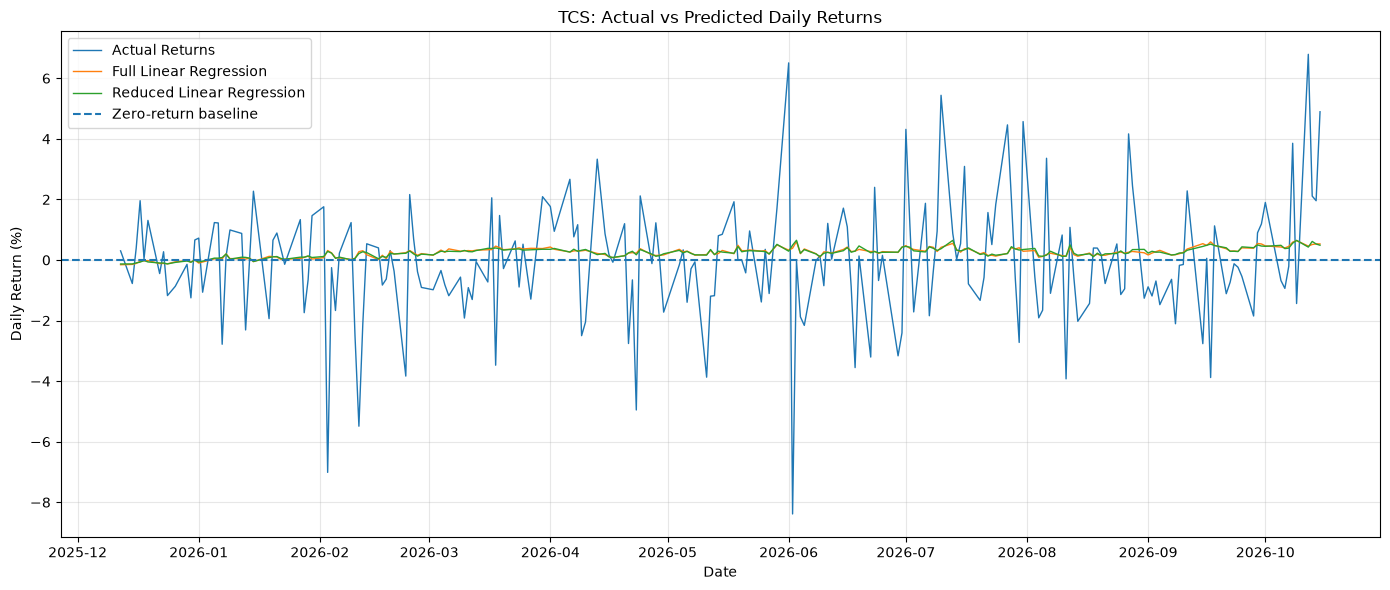

In [ ]:
# STEP 160: Plot Actual vs Predicted Returns

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    comparison_df.index,
    comparison_df["Actual_Return_%"],
    label="Actual Returns",
    linewidth=1
)

plt.plot(
    comparison_df.index,
    comparison_df["Full_LR_Prediction_%"],
    label="Full Linear Regression",
    linewidth=1
)

plt.plot(
    comparison_df.index,
    comparison_df["Reduced_LR_Prediction_%"],
    label="Reduced Linear Regression",
    linewidth=1
)

plt.axhline(
    y=0,
    linestyle="--",
    label="Zero-return baseline"
)

plt.title("TCS: Actual vs Predicted Daily Returns")
plt.xlabel("Date")
plt.ylabel("Daily Return (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

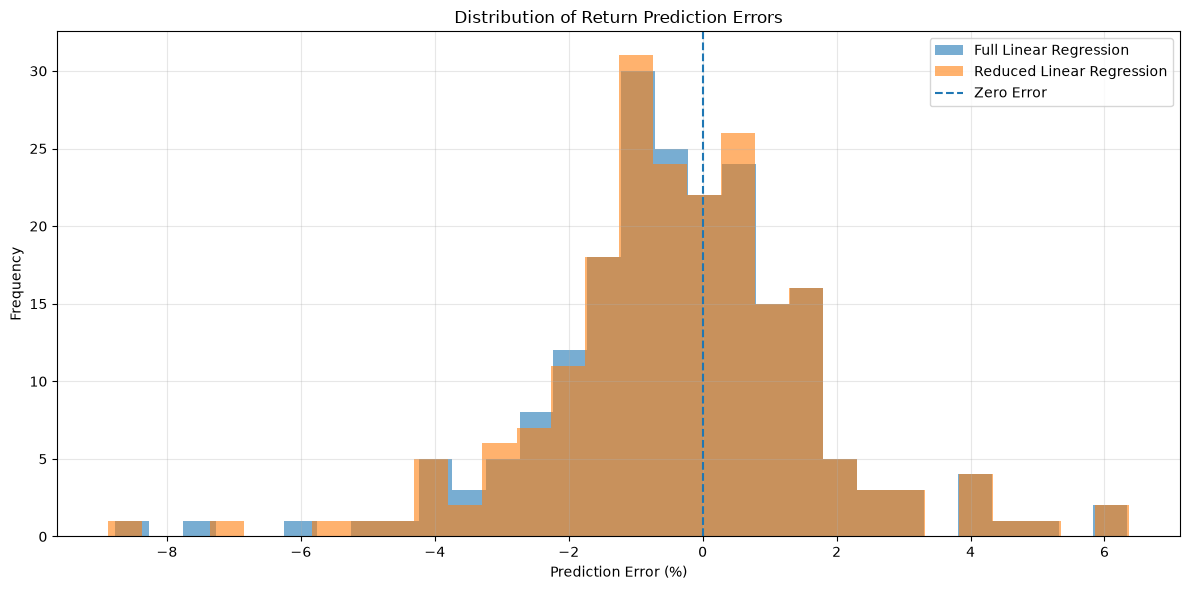

Full LR error mean: -0.3254 %
Reduced LR error mean: -0.325 %


In [ ]:
# STEP 161: Analyze Prediction Error Distribution

comparison_df["Full_LR_Error_%"] = (
    comparison_df["Actual_Return_%"]
    - comparison_df["Full_LR_Prediction_%"]
)

comparison_df["Reduced_LR_Error_%"] = (
    comparison_df["Actual_Return_%"]
    - comparison_df["Reduced_LR_Prediction_%"]
)

plt.figure(figsize=(12, 6))

plt.hist(
    comparison_df["Full_LR_Error_%"],
    bins=30,
    alpha=0.6,
    label="Full Linear Regression"
)

plt.hist(
    comparison_df["Reduced_LR_Error_%"],
    bins=30,
    alpha=0.6,
    label="Reduced Linear Regression"
)

plt.axvline(0, linestyle="--", label="Zero Error")

plt.title("Distribution of Return Prediction Errors")
plt.xlabel("Prediction Error (%)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Full LR error mean:",
      round(comparison_df["Full_LR_Error_%"].mean(), 4), "%")

print("Reduced LR error mean:",
      round(comparison_df["Reduced_LR_Error_%"].mean(), 4), "%")

In [ ]:
# STEP 162: Compare Prediction Error Statistics

error_columns = {
    "Full Linear Regression": "Full_LR_Error_%",
    "Reduced Linear Regression": "Reduced_LR_Error_%"
}

for model_name, error_column in error_columns.items():
    errors = comparison_df[error_column]

    print(f"\n{model_name}")
    print("-" * 35)
    print("Mean error:", round(errors.mean(), 4), "%")
    print("Median error:", round(errors.median(), 4), "%")
    print("Error standard deviation:", round(errors.std(), 4), "%")
    print("Maximum absolute error:", round(errors.abs().max(), 4), "%")


Full Linear Regression
-----------------------------------
Mean error: -0.3254 %
Median error: -0.378 %
Error standard deviation: 2.0108 %
Maximum absolute error: 8.7735 %

Reduced Linear Regression
-----------------------------------
Mean error: -0.325 %
Median error: -0.3651 %
Error standard deviation: 2.0114 %
Maximum absolute error: 8.8762 %


In [ ]:
# STEP 163: Final Return Model Scorecard

scorecard = pd.DataFrame({
    "Model": [
        "Full Linear Regression",
        "Reduced Linear Regression",
        "Zero-Return Baseline"
    ],
    "MAE (%)": [
        (comparison_df["Actual_Return_%"] -
         comparison_df["Full_LR_Prediction_%"]).abs().mean(),
        (comparison_df["Actual_Return_%"] -
         comparison_df["Reduced_LR_Prediction_%"]).abs().mean(),
        (comparison_df["Actual_Return_%"] -
         comparison_df["Zero_Baseline_%"]).abs().mean()
    ],
    "RMSE (%)": [
        np.sqrt(np.mean(comparison_df["Full_LR_Error_%"] ** 2)),
        np.sqrt(np.mean(comparison_df["Reduced_LR_Error_%"] ** 2)),
        np.sqrt(np.mean(comparison_df["Actual_Return_%"] ** 2))
    ],
    "Mean Error (%)": [
        comparison_df["Full_LR_Error_%"].mean(),
        comparison_df["Reduced_LR_Error_%"].mean(),
        comparison_df["Actual_Return_%"].mean()
    ]
})

scorecard = scorecard.round(4)

print("FINAL RETURN PREDICTION SCORECARD\n")
print(scorecard.to_string(index=False))

best_model = scorecard.loc[scorecard["MAE (%)"].idxmin(), "Model"]

print("\nBest model by MAE:", best_model)

FINAL RETURN PREDICTION SCORECARD

                    Model  MAE (%)  RMSE (%)  Mean Error (%)
   Full Linear Regression   1.4840    2.0322         -0.3254
Reduced Linear Regression   1.4829    2.0327         -0.3250
     Zero-Return Baseline   1.4480    2.0130         -0.0819

Best model by MAE: Zero-Return Baseline


In [ ]:
# STEP 164: Check Deep Learning Libraries

print("Checking Deep Learning libraries...\n")

# Check TensorFlow
try:
    import tensorflow as tf
    print("TensorFlow version:", tf.__version__)
except ImportError:
    print("TensorFlow: Not installed")

# Check PyTorch
try:
    import torch
    print("PyTorch version:", torch.__version__)
except ImportError:
    print("PyTorch: Not installed")

print("\nDeep Learning library check complete.")

Checking Deep Learning libraries...

TensorFlow: Not installed
PyTorch: Not installed

Deep Learning library check complete.


In [ ]:
# STEP 165: Install TensorFlow for Deep Learning

%pip install tensorflow

  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached keras-3.15.1-py3-none-any.whl.metadata (6.4 kB)
  Using cached wheel-0.48.0-py3-none-any.whl.metadata (2.3 kB)
  Using cached rich-15.0.0-py3-none-any.whl.metadata (18 kB)
  Using cached namex-0.1.0-py3-none-any.whl.metadata (322 bytes)
  Using cached markdown_it_py-4.2.0-py3-none-any.whl.metadata (7.4 kB)
  Using cached mdurl-0.1.2-py3-none-any.whl.metadata (1.6 kB)
   ---------------------------------------- 0.0/350.8 MB ? eta -:--:--
   ---------------------------------------- 0.1/350.8 MB


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
# STEP 166: Verify TensorFlow Installation

import tensorflow as tf

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", len(tf.config.list_physical_devices("GPU")) > 0)

print("\nDeep Learning setup check complete!")

TensorFlow Version: 2.21.0
GPU Available: False

Deep Learning setup check complete!


In [ ]:
# STEP 167: Check Dataset for LSTM

print("Dataset shape:", df_features.shape)
print("\nAvailable columns:")
print(df_features.columns.tolist())

print("\nFirst 5 rows:")
display(df_features.head())

print("\nLast 5 rows:")
display(df_features.tail())

print("\nMissing values:", df_features.isnull().sum().sum())
print("Dates sorted:", df_features.index.is_monotonic_increasing)

Dataset shape: (1237, 21)

Available columns:
['Close', 'High', 'Low', 'Open', 'Volume', 'Daily_Return', 'MA20', 'MA50', 'MA200', 'RSI_14', 'Target_Next_Open', 'Target_Next_High', 'Target_Next_Low', 'Target_Next_Close', 'Return_5D', 'Return_10D', 'Close_MA20_Diff', 'Close_MA50_Diff', 'High_Low_Range', 'Open_Close_Change', 'Volume_Change']

First 5 rows:


Price,Close,High,Low,Open,Volume,Daily_Return,MA20,MA50,MA200,RSI_14,...,Target_Next_High,Target_Next_Low,Target_Next_Close,Return_5D,Return_10D,Close_MA20_Diff,Close_MA50_Diff,High_Low_Range,Open_Close_Change,Volume_Change
Date,,,,,,,,,,,,,,,,,,,,,
2021-10-18,3157.567383,3162.372410,3118.002057,3119.733583,3590107,NaN,NaN,NaN,NaN,NaN,...,3194.751613,3138.563476,3146.312012,NaN,NaN,NaN,NaN,1.405207,1.212725,NaN
2021-10-19,3146.312012,3194.751613,3138.563476,3176.483932,3135441,-0.356457,NaN,NaN,NaN,NaN,...,3142.719002,3097.959107,3124.408203,NaN,NaN,NaN,NaN,1.785841,-0.949853,-12.664414
2021-10-20,3124.408203,3142.719002,3097.959107,3127.135271,2933693,-0.696174,NaN,NaN,NaN,NaN,...,3123.196259,3039.909912,3058.307373,NaN,NaN,NaN,NaN,1.432588,-0.087207,-6.434438
2021-10-21,3058.307373,3123.196259,3039.909912,3120.296080,4871211,-2.115627,NaN,NaN,NaN,NaN,...,3083.500933,3017.183417,3029.174316,NaN,NaN,NaN,NaN,2.723282,-1.986629,66.043652
2021-10-22,3029.174316,3083.500933,3017.183417,3082.115628,2691670,-0.952588,NaN,NaN,NaN,NaN,...,3042.766969,2986.881933,3024.066406,NaN,NaN,NaN,NaN,2.189293,-1.717694,-44.743309



Last 5 rows:


Price,Close,High,Low,Open,Volume,Daily_Return,MA20,MA50,MA200,RSI_14,...,Target_Next_High,Target_Next_Low,Target_Next_Close,Return_5D,Return_10D,Close_MA20_Diff,Close_MA50_Diff,High_Low_Range,Open_Close_Change,Volume_Change
Date,,,,,,,,,,,,,,,,,,,,,
2026-10-12,2113.763184,2183.492598,2109.684767,2173.346340,3540523,-1.437842,2104.228821,2236.198267,2437.829986,46.725656,...,2257.300049,2143.604416,2257.300049,0.501336,2.065326,0.453105,-5.475144,3.491774,-2.741540,-69.719228
2026-10-13,2257.300049,2257.300049,2143.604416,2145.494271,11048193,6.790584,2107.635706,2234.282451,2433.385422,61.562466,...,2335.800049,2265.600098,2304.899902,8.061907,9.590959,7.101054,1.030201,5.036798,5.211190,212.049745
2026-10-14,2304.899902,2335.800049,2265.600098,2274.000000,12145767,2.108707,2110.925854,2231.168066,2428.973232,65.039631,...,2386.699951,2335.000000,2350.000000,11.385512,14.010668,9.189051,3.304629,3.045683,1.358835,9.934421
2026-10-15,2350.000000,2386.699951,2335.000000,2347.199951,9150523,1.956705,2119.564563,2229.228232,2424.857961,67.993956,...,2484.699951,2375.699951,2465.000000,13.800228,15.209825,10.871829,5.417649,2.199998,0.119293,-24.660806
2026-10-16,2465.000000,2484.699951,2375.699951,2382.000000,12166634,4.893617,2133.893591,2230.523428,2421.274550,74.022188,...,NaN,NaN,NaN,14.939896,19.426698,15.516538,10.512177,4.421907,3.484467,32.961078



Missing values: 372
Dates sorted: True


In [ ]:
# STEP 168: Check Missing Values Column-Wise

missing_summary = df_features.isnull().sum()

missing_summary = missing_summary[missing_summary > 0].sort_values(
    ascending=False
)

print("Columns containing missing values:\n")
print(missing_summary)

print("\nTotal missing values:", df_features.isnull().sum().sum())
print("Total rows before cleaning:", len(df_features))

Columns containing missing values:

Price
MA200                199
MA50                  49
Close_MA50_Diff       49
MA20                  19
Close_MA20_Diff       19
RSI_14                14
Return_10D            10
Return_5D              5
Volume_Change          3
Daily_Return           1
Target_Next_Open       1
Target_Next_Close      1
Target_Next_High       1
Target_Next_Low        1
dtype: int64

Total missing values: 372
Total rows before cleaning: 1237


In [ ]:
# STEP 169: Verify and Clean Dataset for LSTM

print("Duplicate column names:", df_features.columns.duplicated().sum())

print("\nColumns containing 'MA200':")
print([col for col in df_features.columns if "MA200" in col])

# Remove rows with missing values in a separate dataset
df_lstm_clean = df_features.dropna().copy()

print("\nOriginal dataset shape:", df_features.shape)
print("Clean dataset shape:", df_lstm_clean.shape)
print("Remaining missing values:", df_lstm_clean.isnull().sum().sum())

print("\nDate range:")
print("Start:", df_lstm_clean.index.min())
print("End:  ", df_lstm_clean.index.max())

display(df_lstm_clean.head())

Duplicate column names: 0

Columns containing 'MA200':
['MA200']

Original dataset shape: (1237, 21)
Clean dataset shape: (1035, 21)
Remaining missing values: 0

Date range:
Start: 2022-08-03 00:00:00
End:   2026-10-15 00:00:00


Price,Close,High,Low,Open,Volume,Daily_Return,MA20,MA50,MA200,RSI_14,...,Target_Next_High,Target_Next_Low,Target_Next_Close,Return_5D,Return_10D,Close_MA20_Diff,Close_MA50_Diff,High_Low_Range,Open_Close_Change,Volume_Change
Date,,,,,,,,,,,,,,,,,,,,,
2022-08-03,2923.501953,2931.818548,2868.831328,2871.413806,2895824,1.449072,2773.241919,2832.240337,3061.772773,62.443796,...,2965.873247,2895.357436,2937.027832,4.724268,5.520085,5.418209,3.222241,2.154513,1.814024,128.176823
2022-08-04,2937.027832,2965.873247,2895.357436,2932.694490,2150567,0.462660,2776.557898,2834.630205,3060.670076,63.568862,...,2956.330498,2937.071016,2945.869141,2.896834,5.591241,5.779456,3.612380,2.400924,0.147760,-25.735576
2022-08-05,2945.869141,2956.330498,2937.071016,2942.498646,1106933,0.301029,2781.293848,2836.597056,3059.667861,64.321249,...,2957.993525,2920.437623,2954.097900,1.912534,6.119532,5.917221,3.852224,0.653779,0.114545,-48.528318
2022-08-08,2954.097900,2957.993525,2920.437623,2945.825121,1068836,0.279332,2793.061682,2836.738628,3058.816310,65.044823,...,2963.334055,2919.562503,2936.414551,2.293248,6.558743,5.765580,4.137120,1.271315,0.280831,-3.441672
2022-08-10,2936.414551,2963.334055,2919.562503,2963.334055,1878359,-0.598604,2805.215796,2836.716860,3058.206846,62.128864,...,3001.590227,2954.623439,2996.162598,1.897155,7.649492,4.676958,3.514545,1.490646,-0.908419,75.738748


In [ ]:
# STEP 170: Prepare Next-Day Return Target

import numpy as np
import pandas as pd

df_lstm = df_lstm_clean.copy()

# Calculate next-day close return as a percentage
df_lstm["Target_Next_Return"] = (
    (df_lstm["Target_Next_Close"] / df_lstm["Close"]) - 1
) * 100

# Remove rows where target is missing, if any
df_lstm = df_lstm.dropna(subset=["Target_Next_Return"])

print("LSTM dataset shape:", df_lstm.shape)
print("\nTarget summary:")
print(df_lstm["Target_Next_Return"].describe())

print("\nFirst 5 target values:")
display(df_lstm[["Close", "Target_Next_Close", "Target_Next_Return"]].head())

print("\nTarget missing values:", df_lstm["Target_Next_Return"].isnull().sum())

LSTM dataset shape: (1035, 22)

Target summary:
count    1035.000000
mean       -0.006773
std         1.430632
min        -8.386125
25%        -0.741604
50%        -0.058116
75%         0.693666
max         6.790584
Name: Target_Next_Return, dtype: float64

First 5 target values:


Price,Close,Target_Next_Close,Target_Next_Return
Date,,,
2022-08-03,2923.501953,2937.027832,0.462660
2022-08-04,2937.027832,2945.869141,0.301029
2022-08-05,2945.869141,2954.097900,0.279332
2022-08-08,2954.097900,2936.414551,-0.598604
2022-08-10,2936.414551,2996.162598,2.034728



Target missing values: 0


In [ ]:
# STEP 171: Split Data for LSTM

from sklearn.preprocessing import MinMaxScaler

# Features available at prediction time (exclude all future targets)
lstm_feature_columns = [
    "Close",
    "Volume",
    "Daily_Return",
    "MA20",
    "MA50",
    "MA200",
    "RSI_14",
    "Return_5D",
    "Return_10D",
    "High_Low_Range",
    "Open_Close_Change",
    "Volume_Change"
]

X_lstm_raw = df_lstm[lstm_feature_columns].copy()
y_lstm_raw = df_lstm["Target_Next_Return"].copy()

# Chronological 80/20 split
split_index = int(len(df_lstm) * 0.80)

X_train_raw = X_lstm_raw.iloc[:split_index]
X_test_raw = X_lstm_raw.iloc[split_index:]

y_train_raw = y_lstm_raw.iloc[:split_index]
y_test_raw = y_lstm_raw.iloc[split_index:]

# Fit scaler ONLY on training data
feature_scaler = MinMaxScaler()

X_train_scaled = feature_scaler.fit_transform(X_train_raw)
X_test_scaled = feature_scaler.transform(X_test_raw)

print("Training rows:", len(X_train_raw))
print("Testing rows:", len(X_test_raw))

print("\nTraining date range:")
print(X_train_raw.index.min(), "to", X_train_raw.index.max())

print("\nTesting date range:")
print(X_test_raw.index.min(), "to", X_test_raw.index.max())

print("\nScaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)
print("\nTarget training shape:", y_train_raw.shape)
print("Target testing shape:", y_test_raw.shape)

Training rows: 828
Testing rows: 207

Training date range:
2022-08-03 00:00:00 to 2025-12-11 00:00:00

Testing date range:
2025-12-12 00:00:00 to 2026-10-15 00:00:00

Scaled training shape: (828, 12)
Scaled testing shape: (207, 12)

Target training shape: (828,)
Target testing shape: (207,)


In [ ]:
# STEP 172: Create 30-Day Sequences for LSTM

LOOKBACK = 30

def create_sequences(X, y, lookback):
    X_seq, y_seq = [], []

    for i in range(lookback, len(X)):
        X_seq.append(X[i - lookback:i])
        y_seq.append(y.iloc[i])

    return np.array(X_seq), np.array(y_seq)

# Training sequences
X_train_seq, y_train_seq = create_sequences(
    X_train_scaled, y_train_raw, LOOKBACK
)

# Add the final 30 training days as context for the test set
X_test_with_context = np.vstack([
    X_train_scaled[-LOOKBACK:],
    X_test_scaled
])

y_test_with_context = pd.concat([
    y_train_raw.iloc[-LOOKBACK:],
    y_test_raw
])

# Test sequences: each target belongs to the test period
X_test_seq, y_test_seq = create_sequences(
    X_test_with_context,
    y_test_with_context.reset_index(drop=True),
    LOOKBACK
)

print("Lookback window:", LOOKBACK, "trading days")
print("Training sequence shape:", X_train_seq.shape)
print("Testing sequence shape:", X_test_seq.shape)

print("\nTraining target shape:", y_train_seq.shape)
print("Testing target shape:", y_test_seq.shape)

print("\nExpected shapes:")
print("(samples, 30 days, 12 features)")

Lookback window: 30 trading days
Training sequence shape: (798, 30, 12)
Testing sequence shape: (207, 30, 12)

Training target shape: (798,)
Testing target shape: (207,)

Expected shapes:
(samples, 30 days, 12 features)


In [ ]:
# STEP 173: Build LSTM Model

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

lstm_model = Sequential([
    Input(shape=(LOOKBACK, len(lstm_feature_columns))),

    LSTM(64, return_sequences=True),
    Dropout(0.2),

    LSTM(32),
    Dropout(0.2),

    Dense(16, activation="relu"),
    Dense(1)
])

lstm_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mean_squared_error",
    metrics=["mean_absolute_error"]
)

print("LSTM model created successfully!\n")
lstm_model.summary()

LSTM model created successfully!



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        19,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,673 (127.63 KB)

 Trainable params: 32,673 (127.63 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# STEP 174: Train LSTM Model

from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history = lstm_model.fit(
    X_train_seq,
    y_train_seq,
    validation_split=0.15,
    epochs=50,
    batch_size=32,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

print("\nLSTM training complete!")
print("Epochs completed:", len(history.history["loss"]))

Epoch 1/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 8s 73ms/step - loss: 1.5866 - mean_absolute_error: 0.9141 - val_loss: 1.2407 - val_mean_absolute_error: 0.8227
Epoch 2/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 1.5889 - mean_absolute_error: 0.9123 - val_loss: 1.2766 - val_mean_absolute_error: 0.8620
Epoch 3/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 1.5866 - mean_absolute_error: 0.9145 - val_loss: 1.2462 - val_mean_absolute_error: 0.8305
Epoch 4/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 1.5716 - mean_absolute_error: 0.9092 - val_loss: 1.2475 - val_mean_absolute_error: 0.8173
Epoch 5/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 1.5790 - mean_absolute_error: 0.9117 - val_loss: 1.2599 - val_mean_absolute_error: 0.8510
Epoch 6/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 1.5844 - mean_absolute_error: 0.9122 - val_loss: 1.2642 - val_mean_absolute_error: 0.8459
Epoch 7/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 1.5736 - mean_absolute_error: 0.9121 - val_loss

In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Predict next-day returns using LSTM
lstm_predictions = lstm_model.predict(X_test_seq, verbose=0).flatten()

# Actual returns
actual_returns = np.asarray(y_test_seq)

# Baseline: predict 0% return every day
zero_return_predictions = np.zeros_like(actual_returns)

# Calculate evaluation metrics
lstm_mae = mean_absolute_error(actual_returns, lstm_predictions)
lstm_rmse = np.sqrt(mean_squared_error(actual_returns, lstm_predictions))

baseline_mae = mean_absolute_error(actual_returns, zero_return_predictions)
baseline_rmse = np.sqrt(
    mean_squared_error(actual_returns, zero_return_predictions)
)

print("===== LSTM vs Zero-Return Baseline =====")
print(f"LSTM MAE:      {lstm_mae:.4f}%")
print(f"LSTM RMSE:     {lstm_rmse:.4f}%")
print(f"Baseline MAE:  {baseline_mae:.4f}%")
print(f"Baseline RMSE: {baseline_rmse:.4f}%")

print(f"\nAverage actual return: {actual_returns.mean():.4f}%")
print(f"Average LSTM prediction: {lstm_predictions.mean():.4f}%")

if lstm_mae < baseline_mae and lstm_rmse < baseline_rmse:
    print("\nResult: LSTM performed better on both metrics.")
else:
    print("\nResult: LSTM did not beat the baseline on both metrics.")

===== LSTM vs Zero-Return Baseline =====
LSTM MAE:      1.4568%
LSTM RMSE:     2.0172%
Baseline MAE:  1.4480%
Baseline RMSE: 2.0130%

Average actual return: -0.0819%
Average LSTM prediction: 0.0661%

Result: LSTM did not beat the baseline on both metrics.


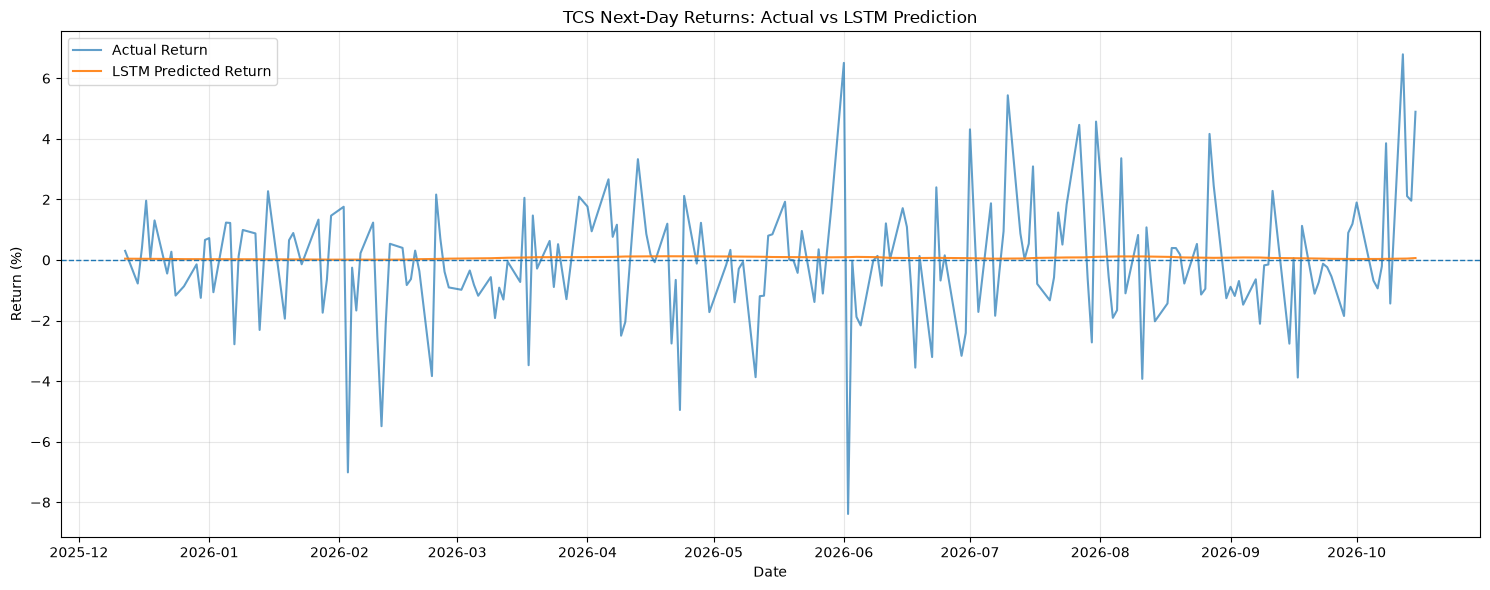

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.plot(
    y_test_raw.index,
    actual_returns,
    label="Actual Return",
    alpha=0.7
)

plt.plot(
    y_test_raw.index,
    lstm_predictions,
    label="LSTM Predicted Return",
    alpha=0.9
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.title("TCS Next-Day Returns: Actual vs LSTM Prediction")
plt.xlabel("Date")
plt.ylabel("Return (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
import importlib.util

libraries = ["pandas", "numpy", "nltk", "transformers", "feedparser"]

for library in libraries:
    available = importlib.util.find_spec(library) is not None
    print(f"{library}: {'Installed' if available else 'Not installed'}")

pandas: Installed
numpy: Installed
nltk: Not installed
transformers: Not installed
feedparser: Not installed


In [ ]:
%pip install nltk feedparser

  Using cached defusedxml-0.7.1-py2.py3-none-any.whl.metadata (32 kB)
     ---------------------------------------- 0.0/41.6 kB ? eta -:--:--
     ---------------------------------------- 0.0/41.6 kB ? eta -:--:--
     ---------------------------------------- 0.0/41.6 kB ? eta -:--:--
     ---------------------------------------- 0.0/41.6 kB ? eta -:--:--
     --------- ------------------------------ 10.2/41.6 kB ? eta -:--:--
     --------- ------------------------------ 10.2/41.6 kB ? eta -:--:--
     --------- ------------------------------ 10.2/41.6 kB ? eta -:--:--
     ------------------- ------------------- 20.5/41.6 kB 93.1 kB/s eta 0:00:01
     ---------------------------- --------- 30.7/41.6 kB 130.4 kB/s eta 0:00:01
     -------------------------------------  41.0/41.6 kB 151.3 kB/s eta 0:00:01
     -------------------------------------- 41.6/41.6 kB 143.3 kB/s eta 0:00:00
     ---------------------------------------- 0.0/57.4 kB ? eta -:--:--
     --------------------------


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import feedparser
import pandas as pd
from urllib.parse import quote

# Topics for Indian stock market news
news_topics = [
    "TCS stock India",
    "NIFTY 50 stock market India",
    "Indian stock market"
]

news_records = []

for topic in news_topics:
    rss_url = (
        "https://news.google.com/rss/search?q="
        + quote(topic)
        + "&hl=en-IN&gl=IN&ceid=IN:en"
    )

    feed = feedparser.parse(rss_url)

    print(f"\nTopic: {topic}")
    print(f"Headlines found: {len(feed.entries)}")

    for entry in feed.entries:
        news_records.append({
            "Topic": topic,
            "Headline": entry.get("title", ""),
            "Published": entry.get("published", ""),
            "Source": entry.get("source", {}).get("title", "")
        })

news_df = pd.DataFrame(news_records)

if not news_df.empty:
    news_df = news_df.drop_duplicates(subset=["Headline"])
    news_df = news_df.reset_index(drop=True)

print("\nTotal unique headlines:", len(news_df))
display(news_df.head(15))


Topic: TCS stock India
Headlines found: 100

Topic: NIFTY 50 stock market India
Headlines found: 100

Topic: Indian stock market
Headlines found: 100

Total unique headlines: 274


,Topic,Headline,Published,Source
0,TCS stock India,"HCLTech jumps over 7%, TCS up 5%: Why are IT s...","Tue, 13 Oct 2026 05:45:00 GMT",The Times of India
1,TCS stock India,India's TCS rises as margins steady despite AI...,"Fri, 09 Oct 2026 16:26:20 GMT",Reuters
2,TCS stock India,"Market wrap: Tech Mahindra, TCS, InterGlobe, B...","Fri, 16 Oct 2026 11:04:23 GMT",The Economic Times
3,TCS stock India,Indian IT stocks surge despite US immigration ...,"Fri, 09 Oct 2026 05:09:31 GMT",Firstpost
4,TCS stock India,"HCLTech jumps 6%, TCS surges over 5%: Why are ...","Tue, 13 Oct 2026 05:12:12 GMT",India Today
5,TCS stock India,TCS shares jump over 5% after Q2 results; IT s...,"Fri, 09 Oct 2026 03:57:15 GMT",Moneycontrol.com
6,TCS stock India,"TCS, TechM, Infosys shares lead Sensex, Nifty ...","Thu, 15 Oct 2026 04:15:10 GMT",Business Today
7,TCS stock India,"Indian IT stocks on fire due to anti-AI trade,...","Thu, 15 Oct 2026 06:35:40 GMT",Livemint
8,TCS stock India,TCS completes acquisition of BBY Services Indi...,"Thu, 15 Oct 2026 08:12:43 GMT",scanx.trade
9,TCS stock India,TCS shares rise as AI revenue offsets sluggish...,"Thu, 08 Oct 2026 07:00:00 GMT",Yahoo Finance


In [ ]:
%pip install vaderSentiment

   ---------------------------------------- 0.0/126.0 kB ? eta -:--:--
   --- ------------------------------------ 10.2/126.0 kB ? eta -:--:--
   --- ------------------------------------ 10.2/126.0 kB ? eta -:--:--
   --- ------------------------------------ 10.2/126.0 kB ? eta -:--:--
   ------ --------------------------------- 20.5/126.0 kB 81.9 kB/s eta 0:00:02
   --------- ----------------------------- 30.7/126.0 kB 109.5 kB/s eta 0:00:01
   ------------------- ------------------- 61.4/126.0 kB 218.8 kB/s eta 0:00:01
   -------------------------------------  122.9/126.0 kB 425.1 kB/s eta 0:00:01
   -------------------------------------- 126.0/126.0 kB 389.6 kB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import pandas as pd

# Initialize sentiment analyzer
sentiment_analyzer = SentimentIntensityAnalyzer()

# Calculate sentiment scores for every headline
def analyze_sentiment(headline):
    scores = sentiment_analyzer.polarity_scores(str(headline))
    compound = scores["compound"]

    if compound >= 0.05:
        sentiment = "Positive"
    elif compound <= -0.05:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    return pd.Series({
        "Positive_Score": scores["pos"],
        "Negative_Score": scores["neg"],
        "Neutral_Score": scores["neu"],
        "Compound_Score": compound,
        "Sentiment": sentiment
    })

# Apply sentiment analysis
news_df[
    ["Positive_Score", "Negative_Score", "Neutral_Score",
     "Compound_Score", "Sentiment"]
] = news_df["Headline"].apply(analyze_sentiment)

# Display results
print("===== NEWS SENTIMENT ANALYSIS =====")
print("\nSentiment distribution:")
print(news_df["Sentiment"].value_counts())

print("\nSample headlines with sentiment:")
display(
    news_df[
        ["Topic", "Headline", "Sentiment", "Compound_Score"]
    ].head(20)
)

===== NEWS SENTIMENT ANALYSIS =====

Sentiment distribution:
Sentiment
Positive    148
Neutral      64
Negative     62
Name: count, dtype: int64

Sample headlines with sentiment:


,Topic,Headline,Sentiment,Compound_Score
0,TCS stock India,"HCLTech jumps over 7%, TCS up 5%: Why are IT s...",Neutral,0.0000
1,TCS stock India,India's TCS rises as margins steady despite AI...,Neutral,0.0000
2,TCS stock India,"Market wrap: Tech Mahindra, TCS, InterGlobe, B...",Neutral,0.0258
3,TCS stock India,Indian IT stocks surge despite US immigration ...,Neutral,0.0000
4,TCS stock India,"HCLTech jumps 6%, TCS surges over 5%: Why are ...",Neutral,0.0000
5,TCS stock India,TCS shares jump over 5% after Q2 results; IT s...,Positive,0.8074
6,TCS stock India,"TCS, TechM, Infosys shares lead Sensex, Nifty ...",Positive,0.5994
7,TCS stock India,"Indian IT stocks on fire due to anti-AI trade,...",Negative,-0.3400
8,TCS stock India,TCS completes acquisition of BBY Services Indi...,Neutral,0.0000
9,TCS stock India,TCS shares rise as AI revenue offsets sluggish...,Positive,0.2732


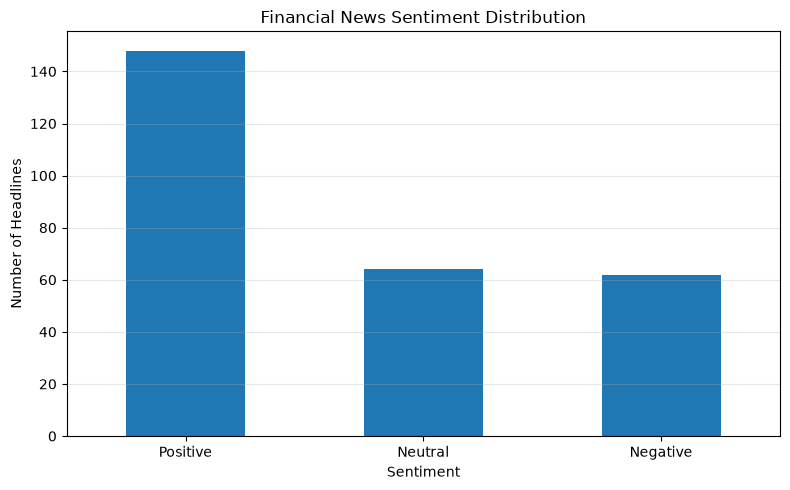

In [ ]:
import matplotlib.pyplot as plt

sentiment_counts = news_df["Sentiment"].value_counts()

plt.figure(figsize=(8, 5))
sentiment_counts.reindex(
    ["Positive", "Neutral", "Negative"], fill_value=0
).plot(kind="bar")

plt.title("Financial News Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Headlines")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
%pip install transformers torch

  Using cached setuptools-84.0.0-py3-none-any.whl.metadata (6.6 kB)
   ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
   - -------------------------------------- 0.5/12.8 MB 15.2 MB/s eta 0:00:01
   -- ------------------------------------- 0.7/12.8 MB 8.5 MB/s eta 0:00:02
   -- ------------------------------------- 0.9/12.8 MB 7.0 MB/s eta 0:00:02
   --- ------------------------------------ 1.0/12.8 MB 6.0 MB/s eta 0:00:02
   --- ------------------------------------ 1.2/12.8 MB 5.8 MB/s eta 0:00:03
   ---- ----------------------------------- 1.4/12.8 MB 5.4 MB/s eta 0:00:03
   ---- ----------------------------------- 1.5/12.8 MB 5.1 MB/s eta 0:00:03
   ----- ---------------------------------- 1.7/12.8 MB 5.1 MB/s eta 0:00:03
   ----- ---------------------------------- 1.7/12.8 MB 4.9 MB/s eta 0:00:03
   ----- ---------------------------------- 1.8/12.8 MB 4.1 MB/s eta 0:00:03
   ----- ---------------------------------- 1.8/12.8 MB 3.8 MB/s eta 0:00:03
   ----- -----


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
# STEP 185: FINBERT LOAD KARO

import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# Select computing device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Selected Device:", device)

# Load FinBERT tokenizer
model_name = "ProsusAI/finbert"
finbert_tokenizer = AutoTokenizer.from_pretrained(model_name)

# Load pretrained FinBERT model
finbert_model = AutoModelForSequenceClassification.from_pretrained(model_name)

# Move model to selected device
finbert_model = finbert_model.to(device)

# Set model to evaluation mode
finbert_model.eval()

# Display available sentiment labels
print("FinBERT Labels:", finbert_model.config.id2label)
print("\nSTEP 185 COMPLETED: FinBERT successfully loaded!")

Selected Device: cpu


Loading weights: 100%|██████████| 201/201 [00:01<00:00, 172.05it/s]

FinBERT Labels: {0: 'positive', 1: 'negative', 2: 'neutral'}

STEP 185 COMPLETED: FinBERT successfully loaded!


In [ ]:
# STEP 186: FINBERT SE NEWS SENTIMENT ANALYSIS KARO

import numpy as np
from tqdm.auto import tqdm

# Store results for every headline
finbert_results = []

# Process headlines in small batches for CPU efficiency
batch_size = 16
headlines = news_df["Headline"].fillna("").astype(str).tolist()

for start in tqdm(range(0, len(headlines), batch_size)):
    batch = headlines[start:start + batch_size]

    # Convert headlines into model inputs
    inputs = finbert_tokenizer(
        batch,
        padding=True,
        truncation=True,
        max_length=128,
        return_tensors="pt"
    )

    # Send inputs to CPU/GPU selected earlier
    inputs = {key: value.to(device) for key, value in inputs.items()}

    # Predict sentiment without calculating gradients
    with torch.no_grad():
        outputs = finbert_model(**inputs)
        probabilities = torch.softmax(outputs.logits, dim=1).cpu().numpy()

    # Save predicted sentiment and confidence scores
    for probs in probabilities:
        predicted_index = int(np.argmax(probs))
        sentiment = finbert_model.config.id2label[predicted_index]

        finbert_results.append({
            "FinBERT_Sentiment": sentiment.capitalize(),
            "FinBERT_Confidence": float(probs[predicted_index]),
            "FinBERT_Positive": float(probs[0]),
            "FinBERT_Negative": float(probs[1]),
            "FinBERT_Neutral": float(probs[2])
        })

# Attach FinBERT results to the existing news DataFrame
finbert_df = pd.DataFrame(finbert_results, index=news_df.index)
news_df = pd.concat([news_df, finbert_df], axis=1)

# Display sentiment distribution
print("\nFinBERT Sentiment Distribution:")
print(news_df["FinBERT_Sentiment"].value_counts())

# Display sample results
display(
    news_df[
        ["Headline", "Sentiment", "Compound_Score",
         "FinBERT_Sentiment", "FinBERT_Confidence"]
    ].head(20)
)

print("\nSTEP 186 COMPLETED!")

100%|██████████| 18/18 [00:17<00:00,  1.05it/s]



FinBERT Sentiment Distribution:
FinBERT_Sentiment
Neutral     94
Positive    91
Negative    89
Name: count, dtype: int64


,Headline,Sentiment,Compound_Score,FinBERT_Sentiment,FinBERT_Confidence
0,"HCLTech jumps over 7%, TCS up 5%: Why are IT s...",Neutral,0.0000,Positive,0.651793
1,India's TCS rises as margins steady despite AI...,Neutral,0.0000,Positive,0.809072
2,"Market wrap: Tech Mahindra, TCS, InterGlobe, B...",Neutral,0.0258,Negative,0.493379
3,Indian IT stocks surge despite US immigration ...,Neutral,0.0000,Neutral,0.664812
4,"HCLTech jumps 6%, TCS surges over 5%: Why are ...",Neutral,0.0000,Positive,0.661486
5,TCS shares jump over 5% after Q2 results; IT s...,Positive,0.8074,Positive,0.904370
6,"TCS, TechM, Infosys shares lead Sensex, Nifty ...",Positive,0.5994,Neutral,0.629639
7,"Indian IT stocks on fire due to anti-AI trade,...",Negative,-0.3400,Neutral,0.659169
8,TCS completes acquisition of BBY Services Indi...,Neutral,0.0000,Neutral,0.881645
9,TCS shares rise as AI revenue offsets sluggish...,Positive,0.2732,Positive,0.891321



STEP 186 COMPLETED!


===== VADER vs FINBERT =====


FinBERT,Negative,Neutral,Positive
VADER,,,
Negative,46,12,4
Neutral,15,27,22
Positive,28,55,65


Total Headlines: 274
Agreements: 138
Disagreements: 136
Agreement Percentage: 50.36%


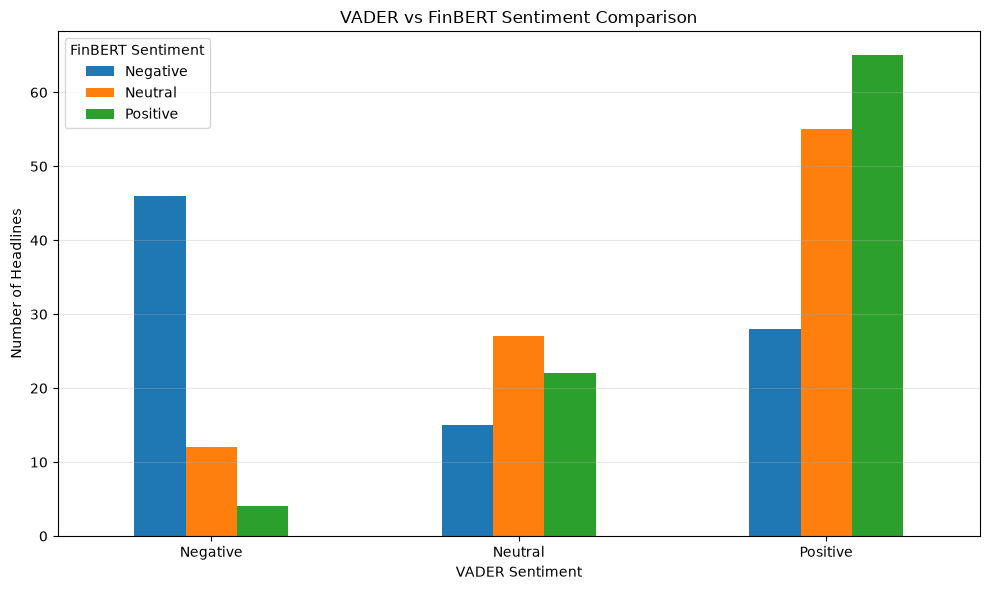

In [ ]:
# STEP 187: VADER AUR FINBERT KA COMPARISON KARO

import pandas as pd
import matplotlib.pyplot as plt

# Compare predictions from both models
comparison = pd.crosstab(
    news_df["Sentiment"],
    news_df["FinBERT_Sentiment"],
    rownames=["VADER"],
    colnames=["FinBERT"]
)

print("===== VADER vs FINBERT =====")
display(comparison)

# Calculate agreement percentage
agreement_count = (
    news_df["Sentiment"] == news_df["FinBERT_Sentiment"]
).sum()

total_headlines = len(news_df)
agreement_percentage = agreement_count / total_headlines * 100

print(f"Total Headlines: {total_headlines}")
print(f"Agreements: {agreement_count}")
print(f"Disagreements: {total_headlines - agreement_count}")
print(f"Agreement Percentage: {agreement_percentage:.2f}%")

# Plot comparison
comparison.plot(kind="bar", figsize=(10, 6))

plt.title("VADER vs FinBERT Sentiment Comparison")
plt.xlabel("VADER Sentiment")
plt.ylabel("Number of Headlines")
plt.xticks(rotation=0)
plt.legend(title="FinBERT Sentiment")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# STEP 188: NEWS KI DATE AUR TIME SAHI KARO

news_df["Published"] = pd.to_datetime(
    news_df["Published"],
    errors="coerce",
    utc=True
)

news_df["Published_IST"] = news_df["Published"].dt.tz_convert(
    "Asia/Kolkata"
)

news_df["News_Date"] = news_df["Published_IST"].dt.date

print("Total Headlines:", len(news_df))
print("Missing Publication Times:", news_df["Published_IST"].isna().sum())
print("Unique News Dates:", news_df["News_Date"].nunique())

print("\n===== RECENT NEWS =====")
display(
    news_df[
        ["Headline", "Published_IST", "News_Date", "FinBERT_Sentiment"]
    ].sort_values("Published_IST", ascending=False).head(10)
)

print("\nSTEP 188 COMPLETED!")

Total Headlines: 274
Missing Publication Times: 0
Unique News Dates: 71

===== RECENT NEWS =====


,Headline,Published_IST,News_Date,FinBERT_Sentiment
221,Jio’s $3.2 billion IPO tests Ambani appeal wit...,2026-10-17 09:37:01+05:30,2026-10-17,Positive
101,"Market weekly wrap: SENSEX, NIFTY50 jump 3% le...",2026-10-17 09:32:18+05:30,2026-10-17,Positive
209,"AI Trade Crash: Not US, not India, but this st...",2026-10-17 08:08:53+05:30,2026-10-17,Neutral
201,Top 10 Best-Performing Major Indian Stocks Tod...,2026-10-17 05:51:08+05:30,2026-10-17,Neutral
242,"Top 3 stocks to buy: Bajaj Finance, Dr Reddy's...",2026-10-17 00:15:17+05:30,2026-10-17,Neutral
264,Indian rupee posts biggest weekly gain in seve...,2026-10-16 20:28:29+05:30,2026-10-16,Positive
25,Infosys stock: At 15.69 times earnings versus ...,2026-10-16 20:03:55+05:30,2026-10-16,Neutral
246,Battered Indian IT stocks rally as AI fears ea...,2026-10-16 17:23:59+05:30,2026-10-16,Positive
251,"Nifty, Sensex investors alert! US bond yields ...",2026-10-16 17:21:32+05:30,2026-10-16,Negative
258,"India's market underperformance bottoms out, b...",2026-10-16 16:59:22+05:30,2026-10-16,Neutral



STEP 188 COMPLETED!


In [ ]:
# STEP 189: DAILY FINBERT SENTIMENT SUMMARY BANAO

daily_sentiment = (
    news_df.groupby("News_Date")
    .agg(
        Total_Headlines=("Headline", "count"),
        Positive_Count=("FinBERT_Positive", "count"),
        Positive_Score=("FinBERT_Positive", "mean"),
        Negative_Score=("FinBERT_Negative", "mean"),
        Neutral_Score=("FinBERT_Neutral", "mean"),
        Average_Confidence=("FinBERT_Confidence", "mean")
    )
    .reset_index()
)

daily_sentiment["Net_Sentiment"] = (
    daily_sentiment["Positive_Score"]
    - daily_sentiment["Negative_Score"]
)

daily_sentiment = daily_sentiment.sort_values("News_Date")

print("===== DAILY NEWS SENTIMENT SUMMARY =====")
display(daily_sentiment.tail(15).round(4))

print("\nTotal News Dates:", len(daily_sentiment))
print(
    "Average Headlines per Date:",
    round(daily_sentiment["Total_Headlines"].mean(), 2)
)

print("\nSTEP 189 COMPLETED!")

===== DAILY NEWS SENTIMENT SUMMARY =====


,News_Date,Total_Headlines,Positive_Count,Positive_Score,Negative_Score,Neutral_Score,Average_Confidence,Net_Sentiment
56,2026-10-01,6,6,0.0972,0.5142,0.3886,0.7921,-0.4170
57,2026-10-03,1,1,0.3791,0.0111,0.6099,0.6099,0.3680
58,2026-10-04,3,3,0.1108,0.0202,0.8690,0.8690,0.0906
59,2026-10-05,2,2,0.0503,0.4106,0.5391,0.8527,-0.3603
60,2026-10-06,4,4,0.2257,0.2812,0.4930,0.7788,-0.0555
61,2026-10-07,2,2,0.3653,0.1255,0.5092,0.8019,0.2397
62,2026-10-08,11,11,0.2479,0.4187,0.3334,0.8444,-0.1707
63,2026-10-09,21,21,0.6729,0.1365,0.1905,0.8586,0.5364
64,2026-10-11,3,3,0.4487,0.3528,0.1985,0.7511,0.0959
65,2026-10-12,3,3,0.0281,0.7270,0.2449,0.8569,-0.6988



Total News Dates: 71
Average Headlines per Date: 3.86

STEP 189 COMPLETED!


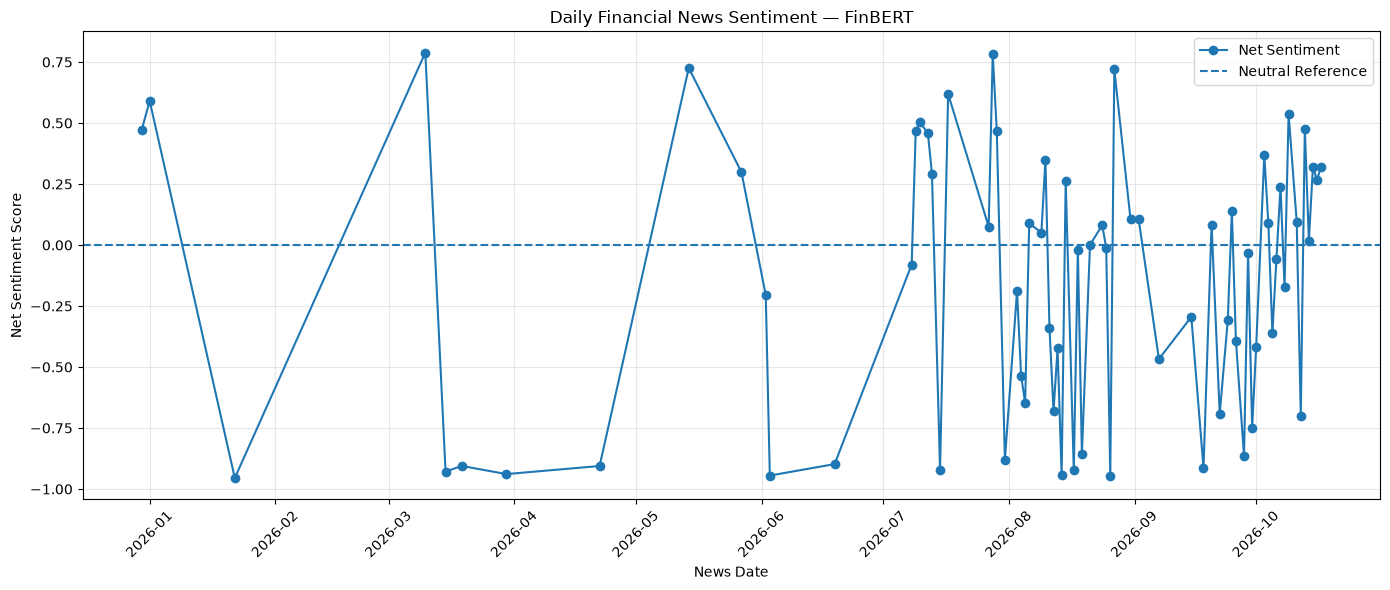

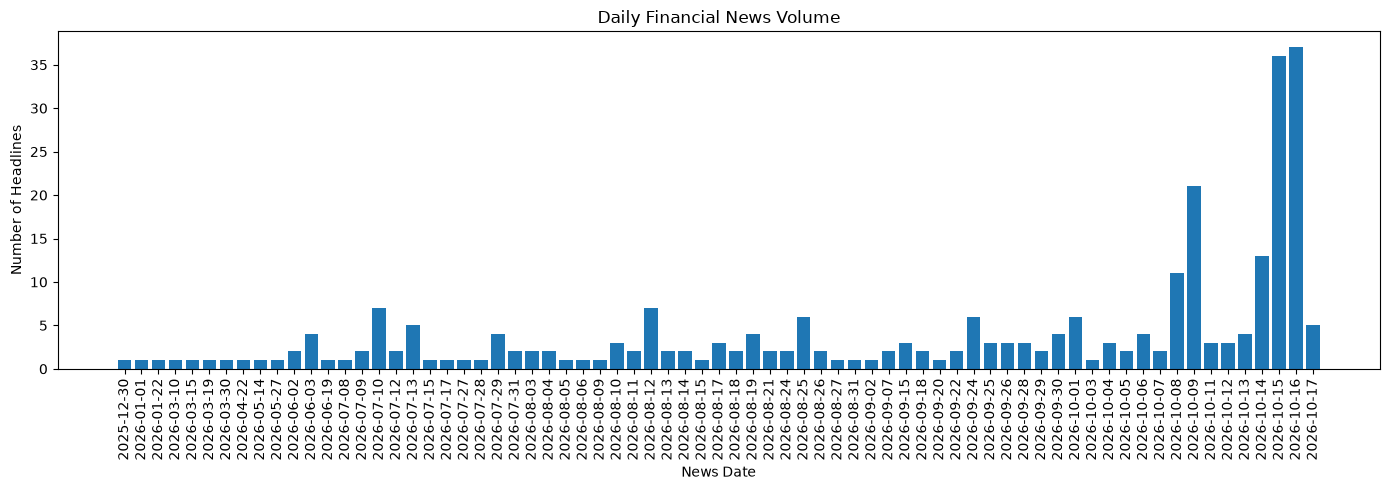

STEP 190 COMPLETED!


In [ ]:
# STEP 190: DAILY SENTIMENT KA GRAPH BANAO

import matplotlib.pyplot as plt
import pandas as pd

plot_data = daily_sentiment.copy()
plot_data["News_Date"] = pd.to_datetime(plot_data["News_Date"])

plt.figure(figsize=(14, 6))
plt.plot(
    plot_data["News_Date"],
    plot_data["Net_Sentiment"],
    marker="o",
    label="Net Sentiment"
)
plt.axhline(y=0, linestyle="--", label="Neutral Reference")
plt.title("Daily Financial News Sentiment — FinBERT")
plt.xlabel("News Date")
plt.ylabel("Net Sentiment Score")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 5))
plt.bar(
    plot_data["News_Date"].astype(str),
    plot_data["Total_Headlines"]
)
plt.title("Daily Financial News Volume")
plt.xlabel("News Date")
plt.ylabel("Number of Headlines")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

print("STEP 190 COMPLETED!")

In [ ]:
# STEP 191: TCS MARKET DATA KI DATE CHECK KARO

print("===== TCS MARKET DATA =====")

print("Market Data Start:", df.index.min())
print("Market Data End:", df.index.max())
print("Total Market Rows:", len(df))

market_dates = pd.to_datetime(df.index)

if market_dates.tz is not None:
    market_dates = market_dates.tz_localize(None)

market_dates = pd.Index(market_dates.date)

news_dates = pd.Index(daily_sentiment["News_Date"])

overlap_dates = market_dates.intersection(news_dates)

print("\n===== NEWS AND MARKET DATE OVERLAP =====")
print("Unique News Dates:", len(news_dates))
print("Matching Market Dates:", len(overlap_dates))
print("Matching Dates:", sorted(overlap_dates))

print("\nSTEP 191 COMPLETED!")

===== TCS MARKET DATA =====
Market Data Start: 2021-10-18 00:00:00
Market Data End: 2026-10-16 00:00:00
Total Market Rows: 1237

===== NEWS AND MARKET DATE OVERLAP =====
Unique News Dates: 71
Matching Market Dates: 61
Matching Dates: [datetime.date(2025, 12, 30), datetime.date(2026, 1, 1), datetime.date(2026, 1, 22), datetime.date(2026, 3, 10), datetime.date(2026, 3, 19), datetime.date(2026, 3, 30), datetime.date(2026, 4, 22), datetime.date(2026, 5, 14), datetime.date(2026, 5, 27), datetime.date(2026, 6, 2), datetime.date(2026, 6, 3), datetime.date(2026, 6, 19), datetime.date(2026, 7, 8), datetime.date(2026, 7, 9), datetime.date(2026, 7, 10), datetime.date(2026, 7, 13), datetime.date(2026, 7, 15), datetime.date(2026, 7, 17), datetime.date(2026, 7, 27), datetime.date(2026, 7, 28), datetime.date(2026, 7, 29), datetime.date(2026, 7, 31), datetime.date(2026, 8, 3), datetime.date(2026, 8, 4), datetime.date(2026, 8, 5), datetime.date(2026, 8, 6), datetime.date(2026, 8, 10), datetime.date(202

In [ ]:
# STEP 192: NEWS KO TRADING SESSION KE SAATH ALIGN KARO

news_timing = news_df.copy()

news_timing["Published_IST"] = pd.to_datetime(
    news_timing["Published_IST"],
    errors="coerce"
)

news_timing["News_Date"] = (
    news_timing["Published_IST"].dt.date
)

news_timing["News_Time"] = (
    news_timing["Published_IST"].dt.strftime("%H:%M")
)

news_timing["During_Market_Hours"] = (
    (news_timing["Published_IST"].dt.hour >= 9)
    & (
        (news_timing["Published_IST"].dt.hour < 15)
        | (
            (news_timing["Published_IST"].dt.hour == 15)
            & (news_timing["Published_IST"].dt.minute <= 30)
        )
    )
)

print("===== NEWS PUBLICATION TIMING =====")
print("Total Headlines:", len(news_timing))
print(
    "During Market Hours:",
    int(news_timing["During_Market_Hours"].sum())
)
print(
    "Outside Market Hours:",
    int((~news_timing["During_Market_Hours"]).sum())
)

print("\n===== RECENT NEWS TIMING =====")

display(
    news_timing[
        [
            "Headline",
            "Published_IST",
            "News_Time",
            "During_Market_Hours",
            "FinBERT_Sentiment"
        ]
    ]
    .sort_values("Published_IST", ascending=False)
    .head(15)
)

print("\nSTEP 192 COMPLETED!")

===== NEWS PUBLICATION TIMING =====
Total Headlines: 274
During Market Hours: 214
Outside Market Hours: 60

===== RECENT NEWS TIMING =====


,Headline,Published_IST,News_Time,During_Market_Hours,FinBERT_Sentiment
221,Jio’s $3.2 billion IPO tests Ambani appeal wit...,2026-10-17 09:37:01+05:30,09:37,True,Positive
101,"Market weekly wrap: SENSEX, NIFTY50 jump 3% le...",2026-10-17 09:32:18+05:30,09:32,True,Positive
209,"AI Trade Crash: Not US, not India, but this st...",2026-10-17 08:08:53+05:30,08:08,False,Neutral
201,Top 10 Best-Performing Major Indian Stocks Tod...,2026-10-17 05:51:08+05:30,05:51,False,Neutral
242,"Top 3 stocks to buy: Bajaj Finance, Dr Reddy's...",2026-10-17 00:15:17+05:30,00:15,False,Neutral
264,Indian rupee posts biggest weekly gain in seve...,2026-10-16 20:28:29+05:30,20:28,False,Positive
25,Infosys stock: At 15.69 times earnings versus ...,2026-10-16 20:03:55+05:30,20:03,False,Neutral
246,Battered Indian IT stocks rally as AI fears ea...,2026-10-16 17:23:59+05:30,17:23,False,Positive
251,"Nifty, Sensex investors alert! US bond yields ...",2026-10-16 17:21:32+05:30,17:21,False,Negative
258,"India's market underperformance bottoms out, b...",2026-10-16 16:59:22+05:30,16:59,False,Neutral



STEP 192 COMPLETED!


In [ ]:
# STEP 193: NEWS KO NEXT TRADING SESSION SE MAP KARO

market_dates = pd.DatetimeIndex(
    pd.to_datetime(df.index).normalize()
)

if market_dates.tz is not None:
    market_dates = market_dates.tz_localize(None)

market_dates = market_dates.sort_values().unique()

news_timing["News_Date_DT"] = pd.to_datetime(
    news_timing["News_Date"]
)

def next_trading_session(news_date):
    eligible_dates = market_dates[market_dates.date > news_date]
    if len(eligible_dates) == 0:
        return pd.NaT
    return eligible_dates[0]

news_timing["Next_Trading_Date"] = news_timing[
    "News_Date"
].apply(next_trading_session)

print("===== NEXT TRADING SESSION MAPPING =====")
display(
    news_timing[
        [
            "Published_IST",
            "News_Date",
            "During_Market_Hours",
            "Next_Trading_Date",
            "FinBERT_Sentiment"
        ]
    ].head(15)
)

print(
    "\nHeadlines without a following market date:",
    news_timing["Next_Trading_Date"].isna().sum()
)

print("\nSTEP 193 COMPLETED!")

===== NEXT TRADING SESSION MAPPING =====


,Published_IST,News_Date,During_Market_Hours,Next_Trading_Date,FinBERT_Sentiment
0,2026-10-13 11:15:00+05:30,2026-10-13,True,2026-10-14,Positive
1,2026-10-09 21:56:20+05:30,2026-10-09,False,2026-10-12,Positive
2,2026-10-16 16:34:23+05:30,2026-10-16,False,NaT,Negative
3,2026-10-09 10:39:31+05:30,2026-10-09,True,2026-10-12,Neutral
4,2026-10-13 10:42:12+05:30,2026-10-13,True,2026-10-14,Positive
5,2026-10-09 09:27:15+05:30,2026-10-09,True,2026-10-12,Positive
6,2026-10-15 09:45:10+05:30,2026-10-15,True,2026-10-16,Neutral
7,2026-10-15 12:05:40+05:30,2026-10-15,True,2026-10-16,Neutral
8,2026-10-15 13:42:43+05:30,2026-10-15,True,2026-10-16,Neutral
9,2026-10-08 12:30:00+05:30,2026-10-08,True,2026-10-09,Positive



Headlines without a following market date: 42

STEP 193 COMPLETED!


In [ ]:
# STEP 194: NEWS KO TRADING DAY KE SAATH ALIGN KARO

def assign_target_date(row):
    news_date = pd.Timestamp(row["News_Date"])

    if row["During_Market_Hours"]:
        eligible_dates = market_dates[
            market_dates.date == news_date.date()
        ]
    else:
        eligible_dates = market_dates[
            market_dates.date > news_date.date()
        ]

    if len(eligible_dates) > 0:
        return eligible_dates[0]

    return pd.NaT


news_timing["Target_Trading_Date"] = news_timing.apply(
    assign_target_date,
    axis=1
)

print("===== UPDATED NEWS DATE MAPPING =====")

display(
    news_timing[
        [
            "Published_IST",
            "News_Date",
            "During_Market_Hours",
            "Target_Trading_Date",
            "FinBERT_Sentiment"
        ]
    ]
    .sort_values("Published_IST", ascending=False)
    .head(15)
)

print(
    "\nUnmapped Headlines:",
    news_timing["Target_Trading_Date"].isna().sum()
)

print("\nSTEP 194 COMPLETED!")

===== UPDATED NEWS DATE MAPPING =====


,Published_IST,News_Date,During_Market_Hours,Target_Trading_Date,FinBERT_Sentiment
221,2026-10-17 09:37:01+05:30,2026-10-17,True,NaT,Positive
101,2026-10-17 09:32:18+05:30,2026-10-17,True,NaT,Positive
209,2026-10-17 08:08:53+05:30,2026-10-17,False,NaT,Neutral
201,2026-10-17 05:51:08+05:30,2026-10-17,False,NaT,Neutral
242,2026-10-17 00:15:17+05:30,2026-10-17,False,NaT,Neutral
264,2026-10-16 20:28:29+05:30,2026-10-16,False,NaT,Positive
25,2026-10-16 20:03:55+05:30,2026-10-16,False,NaT,Neutral
246,2026-10-16 17:23:59+05:30,2026-10-16,False,NaT,Positive
251,2026-10-16 17:21:32+05:30,2026-10-16,False,NaT,Negative
258,2026-10-16 16:59:22+05:30,2026-10-16,False,NaT,Neutral



Unmapped Headlines: 44

STEP 194 COMPLETED!


In [ ]:
# STEP 195: WEEKEND NEWS KO SAHI CLASSIFY KARO

news_timing["Is_Weekday"] = (
    news_timing["Published_IST"].dt.dayofweek < 5
)

news_timing["During_Market_Hours"] = (
    news_timing["Is_Weekday"]
    & (
        (
            news_timing["Published_IST"].dt.hour > 9
        )
        | (
            (news_timing["Published_IST"].dt.hour == 9)
            & (news_timing["Published_IST"].dt.minute >= 15)
        )
    )
    & (
        (news_timing["Published_IST"].dt.hour < 15)
        | (
            (news_timing["Published_IST"].dt.hour == 15)
            & (news_timing["Published_IST"].dt.minute <= 30)
        )
    )
)

print("===== NEWS TIMING VALIDATION =====")
print(
    "Weekend Headlines:",
    int((~news_timing["Is_Weekday"]).sum())
)
print(
    "During Weekday Market Hours:",
    int(news_timing["During_Market_Hours"].sum())
)

print("\n===== LATEST HEADLINES =====")
display(
    news_timing[
        [
            "Published_IST",
            "Is_Weekday",
            "During_Market_Hours",
            "Target_Trading_Date"
        ]
    ]
    .sort_values("Published_IST", ascending=False)
    .head(10)
)

print("\nSTEP 195 COMPLETED!")

===== NEWS TIMING VALIDATION =====
Weekend Headlines: 21
During Weekday Market Hours: 198

===== LATEST HEADLINES =====


,Published_IST,Is_Weekday,During_Market_Hours,Target_Trading_Date
221,2026-10-17 09:37:01+05:30,False,False,NaT
101,2026-10-17 09:32:18+05:30,False,False,NaT
209,2026-10-17 08:08:53+05:30,False,False,NaT
201,2026-10-17 05:51:08+05:30,False,False,NaT
242,2026-10-17 00:15:17+05:30,False,False,NaT
264,2026-10-16 20:28:29+05:30,True,False,NaT
25,2026-10-16 20:03:55+05:30,True,False,NaT
246,2026-10-16 17:23:59+05:30,True,False,NaT
251,2026-10-16 17:21:32+05:30,True,False,NaT
258,2026-10-16 16:59:22+05:30,True,False,NaT



STEP 195 COMPLETED!


In [ ]:
# STEP 196: NEXT AVAILABLE TRADING SESSION MAP KARO

def map_news_to_session(row):
    news_date = row["Published_IST"].date()
    market_time = row["During_Market_Hours"]

    if market_time:
        eligible = market_dates[
            market_dates.date == news_date
        ]
    else:
        eligible = market_dates[
            market_dates.date > news_date
        ]

    if len(eligible):
        return eligible[0]

    return pd.NaT


news_timing["Target_Trading_Date"] = news_timing.apply(
    map_news_to_session,
    axis=1
)

print("===== FINAL SESSION MAPPING CHECK =====")
print("Total Headlines:", len(news_timing))
print(
    "Mapped Headlines:",
    news_timing["Target_Trading_Date"].notna().sum()
)
print(
    "Unmapped Headlines:",
    news_timing["Target_Trading_Date"].isna().sum()
)

display(
    news_timing[
        [
            "Published_IST",
            "During_Market_Hours",
            "Target_Trading_Date"
        ]
    ].sort_values("Published_IST", ascending=False).head(15)
)

print("\nSTEP 196 COMPLETED!")

===== FINAL SESSION MAPPING CHECK =====
Total Headlines: 274
Mapped Headlines: 244
Unmapped Headlines: 30


,Published_IST,During_Market_Hours,Target_Trading_Date
221,2026-10-17 09:37:01+05:30,False,NaT
101,2026-10-17 09:32:18+05:30,False,NaT
209,2026-10-17 08:08:53+05:30,False,NaT
201,2026-10-17 05:51:08+05:30,False,NaT
242,2026-10-17 00:15:17+05:30,False,NaT
264,2026-10-16 20:28:29+05:30,False,NaT
25,2026-10-16 20:03:55+05:30,False,NaT
246,2026-10-16 17:23:59+05:30,False,NaT
251,2026-10-16 17:21:32+05:30,False,NaT
258,2026-10-16 16:59:22+05:30,False,NaT



STEP 196 COMPLETED!


In [ ]:
# STEP 197: DAILY SENTIMENT KO TRADING DATE KE HISAB SE AGGREGATE KARO

mapped_news = news_timing.dropna(
    subset=["Target_Trading_Date"]
).copy()

daily_trading_sentiment = (
    mapped_news.groupby("Target_Trading_Date")
    .agg(
        News_Count=("Headline", "count"),
        Positive_Probability=("FinBERT_Positive", "mean"),
        Negative_Probability=("FinBERT_Negative", "mean"),
        Neutral_Probability=("FinBERT_Neutral", "mean"),
        Average_Confidence=("FinBERT_Confidence", "mean")
    )
    .reset_index()
)

daily_trading_sentiment["Net_Sentiment"] = (
    daily_trading_sentiment["Positive_Probability"]
    - daily_trading_sentiment["Negative_Probability"]
)

print("===== DAILY TRADING-DATE SENTIMENT =====")
print("Trading Dates with News:", len(daily_trading_sentiment))
print("Mapped Headlines:", len(mapped_news))

display(
    daily_trading_sentiment
    .sort_values("Target_Trading_Date")
    .tail(15)
    .round(4)
)

print("\nSTEP 197 COMPLETED!")

===== DAILY TRADING-DATE SENTIMENT =====
Trading Dates with News: 64
Mapped Headlines: 244


C:\Users\Hp Victus\AppData\Local\Temp\ipykernel_39764\857174092.py:32: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(4)


,Target_Trading_Date,News_Count,Positive_Probability,Negative_Probability,Neutral_Probability,Average_Confidence,Net_Sentiment
49,2026-09-25,3,0.3773,0.2390,0.3837,0.6792,0.1383
50,2026-09-28,6,0.0691,0.6973,0.2336,0.8109,-0.6282
51,2026-09-29,2,0.4497,0.4814,0.0689,0.9108,-0.0317
52,2026-09-30,4,0.0141,0.7628,0.2230,0.9129,-0.7487
53,2026-10-01,5,0.0789,0.6058,0.3153,0.7995,-0.5269
54,2026-10-05,7,0.1430,0.1356,0.7214,0.8110,0.0073
55,2026-10-06,4,0.2257,0.2812,0.4930,0.7788,-0.0555
56,2026-10-07,2,0.3653,0.1255,0.5092,0.8019,0.2397
57,2026-10-08,11,0.2479,0.4187,0.3334,0.8444,-0.1707
58,2026-10-09,14,0.8162,0.0639,0.1199,0.8430,0.7524



STEP 197 COMPLETED!


In [ ]:

# STEP 198: SENTIMENT SUMMARY KO CLEAN KARO

sentiment_display = daily_trading_sentiment.copy()

numeric_columns = sentiment_display.select_dtypes(
    include="number"
).columns

sentiment_display[numeric_columns] = (
    sentiment_display[numeric_columns].round(4)
)

print("===== CLEAN DAILY SENTIMENT SUMMARY =====")

display(
    sentiment_display
    .sort_values("Target_Trading_Date")
    .tail(15)
)

print("\nTotal Trading Dates with News:", len(sentiment_display))
print(
    "Date Range:",
    sentiment_display["Target_Trading_Date"].min(),
    "to",
    sentiment_display["Target_Trading_Date"].max()
)

print("\nSTEP 198 COMPLETED!")

===== CLEAN DAILY SENTIMENT SUMMARY =====


,Target_Trading_Date,News_Count,Positive_Probability,Negative_Probability,Neutral_Probability,Average_Confidence,Net_Sentiment
49,2026-09-25,3,0.3773,0.2390,0.3837,0.6792,0.1383
50,2026-09-28,6,0.0691,0.6973,0.2336,0.8109,-0.6282
51,2026-09-29,2,0.4497,0.4814,0.0689,0.9108,-0.0317
52,2026-09-30,4,0.0141,0.7628,0.2230,0.9129,-0.7487
53,2026-10-01,5,0.0789,0.6058,0.3153,0.7995,-0.5269
54,2026-10-05,7,0.1430,0.1356,0.7214,0.8110,0.0073
55,2026-10-06,4,0.2257,0.2812,0.4930,0.7788,-0.0555
56,2026-10-07,2,0.3653,0.1255,0.5092,0.8019,0.2397
57,2026-10-08,11,0.2479,0.4187,0.3334,0.8444,-0.1707
58,2026-10-09,14,0.8162,0.0639,0.1199,0.8430,0.7524



Total Trading Dates with News: 64
Date Range: 2025-12-30 00:00:00 to 2026-10-16 00:00:00

STEP 198 COMPLETED!


In [ ]:
# STEP 199: TCS MARKET DATA AUR NEWS SENTIMENT MERGE KARO

market_df = df.copy()

market_df["Market_Date"] = pd.to_datetime(
    market_df.index
).date

sentiment_df = daily_trading_sentiment.copy()

sentiment_df["Market_Date"] = pd.to_datetime(
    sentiment_df["Target_Trading_Date"]
).dt.date

sentiment_features = sentiment_df[
    [
        "Market_Date",
        "News_Count",
        "Positive_Probability",
        "Negative_Probability",
        "Neutral_Probability",
        "Average_Confidence",
        "Net_Sentiment"
    ]
]

market_news_df = market_df.merge(
    sentiment_features,
    on="Market_Date",
    how="left",
    validate="one_to_one"
)

print("===== MARKET + NEWS MERGE RESULTS =====")
print("Original Market Rows:", len(market_df))
print("Merged Rows:", len(market_news_df))
print(
    "Dates With News:",
    market_news_df["News_Count"].notna().sum()
)
print(
    "Dates Without News:",
    market_news_df["News_Count"].isna().sum()
)

display(market_news_df.tail(10))

print("\nSTEP 199 COMPLETED!")

===== MARKET + NEWS MERGE RESULTS =====
Original Market Rows: 1237
Merged Rows: 1237
Dates With News: 64
Dates Without News: 1173


,Close,High,Low,Open,Volume,Daily_Return,MA20,MA50,MA200,RSI_14,...,Target_Next_High,Target_Next_Low,Target_Next_Close,Market_Date,News_Count,Positive_Probability,Negative_Probability,Neutral_Probability,Average_Confidence,Net_Sentiment
1227,2103.218994,2129.578863,2052.687818,2102.821206,5270768,1.898783,2139.257605,2261.841953,2462.852286,42.613084,...,2103.815944,2071.686697,2088.895264,2026-10-05,7.0,0.142953,0.135604,0.721443,0.811029,0.007350
1228,2088.895264,2103.815944,2071.686697,2085.911128,2382510,-0.681038,2129.111536,2258.772271,2457.860475,40.971023,...,2093.868900,2065.022250,2069.299561,2026-10-06,4.0,0.225749,0.281236,0.493015,0.778829,-0.055486
1229,2069.299561,2093.868900,2065.022250,2074.173553,1349758,-0.938089,2119.676697,2254.489038,2452.724194,38.769966,...,2130.175856,2049.106824,2065.022217,2026-10-07,2.0,0.365288,0.125539,0.509173,0.801949,0.239750
1230,2065.022217,2130.175856,2049.106824,2092.874154,4288031,-0.206705,2110.749158,2248.083091,2447.686832,38.286465,...,2192.345298,2074.969279,2144.599121,2026-10-08,11.0,0.247947,0.418696,0.333357,0.844393,-0.170748
1231,2144.599121,2192.345298,2074.969279,2074.969279,11692314,3.853562,2108.162903,2242.301821,2442.986483,50.623711,...,2183.492598,2109.684767,2113.763184,2026-10-09,14.0,0.816238,0.063864,0.119898,0.843048,0.752373
1232,2113.763184,2183.492598,2109.684767,2173.346340,3540523,-1.437842,2104.228821,2236.198267,2437.829986,46.725656,...,2257.300049,2143.604416,2257.300049,2026-10-12,12.0,0.343286,0.355509,0.301205,0.842141,-0.012223
1233,2257.300049,2257.300049,2143.604416,2145.494271,11048193,6.790584,2107.635706,2234.282451,2433.385422,61.562466,...,2335.800049,2265.600098,2304.899902,2026-10-13,3.0,0.442965,0.334222,0.222813,0.753228,0.108744
1234,2304.899902,2335.800049,2265.600098,2274.000000,12145767,2.108707,2110.925854,2231.168066,2428.973232,65.039631,...,2386.699951,2335.000000,2350.000000,2026-10-14,12.0,0.450419,0.281833,0.267748,0.820004,0.168586
1235,2350.000000,2386.699951,2335.000000,2347.199951,9150523,1.956705,2119.564563,2229.228232,2424.857961,67.993956,...,2484.699951,2375.699951,2465.000000,2026-10-15,24.0,0.399340,0.178904,0.421756,0.763522,0.220435
1236,2465.000000,2484.699951,2375.699951,2382.000000,12166634,4.893617,2133.893591,2230.523428,2421.274550,74.022188,...,NaN,NaN,NaN,2026-10-16,27.0,0.431273,0.197433,0.371294,0.818908,0.233839



STEP 199 COMPLETED!


In [ ]:
# STEP 200: MERGED DATASET VALIDATE KARO

print("===== DATASET VALIDATION =====")

print("\nDataset Shape:", market_news_df.shape)

print("\nMissing Values:")
display(
    market_news_df[
        [
            "News_Count",
            "Positive_Probability",
            "Negative_Probability",
            "Neutral_Probability",
            "Average_Confidence",
            "Net_Sentiment"
        ]
    ].isna().sum().to_frame("Missing_Count")
)

print("\nNews Coverage:")
print(
    f"{market_news_df['News_Count'].notna().mean() * 100:.2f}%"
)

print("\nDuplicate Market Dates:")
print(market_news_df["Market_Date"].duplicated().sum())

print("\nDates With News:")
display(
    market_news_df.loc[
        market_news_df["News_Count"].notna(),
        [
            "Market_Date",
            "News_Count",
            "Net_Sentiment"
        ]
    ].tail(10)
)

print("\nSTEP 200 COMPLETED!")

===== DATASET VALIDATION =====

Dataset Shape: (1237, 21)

Missing Values:


,Missing_Count
News_Count,1173
Positive_Probability,1173
Negative_Probability,1173
Neutral_Probability,1173
Average_Confidence,1173
Net_Sentiment,1173



News Coverage:
5.17%

Duplicate Market Dates:
0

Dates With News:


,Market_Date,News_Count,Net_Sentiment
1227,2026-10-05,7.0,0.007350
1228,2026-10-06,4.0,-0.055486
1229,2026-10-07,2.0,0.239750
1230,2026-10-08,11.0,-0.170748
1231,2026-10-09,14.0,0.752373
1232,2026-10-12,12.0,-0.012223
1233,2026-10-13,3.0,0.108744
1234,2026-10-14,12.0,0.168586
1235,2026-10-15,24.0,0.220435
1236,2026-10-16,27.0,0.233839



STEP 200 COMPLETED!


In [ ]:
# STEP 201: NEWS TIMING AUR TARGET ALIGNMENT CHECK KARO

print("===== NEWS TIMING VALIDATION =====")

print("Market Data Start:", pd.to_datetime(df.index).min())
print("Market Data End:", pd.to_datetime(df.index).max())

print("\nNews Publication Range:")
print("First News:", news_timing["Published_IST"].min())
print("Last News:", news_timing["Published_IST"].max())

print("\nNews Mapping Status:")
print("Total Headlines:", len(news_timing))
print(
    "Mapped Headlines:",
    news_timing["Target_Trading_Date"].notna().sum()
)
print(
    "Unmapped Headlines:",
    news_timing["Target_Trading_Date"].isna().sum()
)

print("\nSample: Publication Time vs Assigned Trading Date")

display(
    news_timing[
        [
            "Published_IST",
            "During_Market_Hours",
            "Target_Trading_Date",
            "Headline"
        ]
    ].sort_values("Published_IST").tail(15)
)

print("\nSTEP 201 COMPLETED!")

===== NEWS TIMING VALIDATION =====
Market Data Start: 2021-10-18 00:00:00
Market Data End: 2026-10-16 00:00:00

News Publication Range:
First News: 2025-12-30 13:30:00+05:30
Last News: 2026-10-17 09:37:01+05:30

News Mapping Status:
Total Headlines: 274
Mapped Headlines: 244
Unmapped Headlines: 30

Sample: Publication Time vs Assigned Trading Date


,Published_IST,During_Market_Hours,Target_Trading_Date,Headline
208,2026-10-16 16:21:09+05:30,False,NaT,Sensex Today Ends 417 Points Higher | Nifty Ab...
112,2026-10-16 16:26:13+05:30,False,NaT,"Sensex, Nifty Rise Again; IT Stocks Lead Rally..."
2,2026-10-16 16:34:23+05:30,False,NaT,"Market wrap: Tech Mahindra, TCS, InterGlobe, B..."
111,2026-10-16 16:46:16+05:30,False,NaT,"Share Market Today: Nifty 50, Bank Nifty | Oct..."
211,2026-10-16 16:52:20+05:30,False,NaT,"Indian Equities Extend Gains, IT Sector Leads ..."
258,2026-10-16 16:59:22+05:30,False,NaT,"India's market underperformance bottoms out, b..."
251,2026-10-16 17:21:32+05:30,False,NaT,"Nifty, Sensex investors alert! US bond yields ..."
246,2026-10-16 17:23:59+05:30,False,NaT,Battered Indian IT stocks rally as AI fears ea...
25,2026-10-16 20:03:55+05:30,False,NaT,Infosys stock: At 15.69 times earnings versus ...
264,2026-10-16 20:28:29+05:30,False,NaT,Indian rupee posts biggest weekly gain in seve...



STEP 201 COMPLETED!


In [ ]:
# STEP 202: NEWS KO NEXT TRADING SESSION KE LIYE ALIGN KARO

market_dates = pd.DatetimeIndex(
    pd.to_datetime(df.index)
).normalize().unique().sort_values()

def assign_next_session(published_time):
    news_date = published_time.tz_convert(
        "Asia/Kolkata"
    ).tz_localize(None).normalize()

    future_dates = market_dates[market_dates > news_date]

    if len(future_dates) > 0:
        return future_dates[0]

    return pd.NaT

news_aligned = news_timing.copy()

news_aligned["Next_Session_Date"] = news_aligned[
    "Published_IST"
].apply(assign_next_session)

print("===== NEXT SESSION NEWS ALIGNMENT =====")
print("Total Headlines:", len(news_aligned))
print(
    "Mapped Headlines:",
    news_aligned["Next_Session_Date"].notna().sum()
)
print(
    "Unmapped Headlines:",
    news_aligned["Next_Session_Date"].isna().sum()
)

display(
    news_aligned[
        [
            "Published_IST",
            "Next_Session_Date",
            "Headline"
        ]
    ].sort_values("Published_IST").tail(10)
)

print("\nSTEP 202 COMPLETED!")

===== NEXT SESSION NEWS ALIGNMENT =====
Total Headlines: 274
Mapped Headlines: 232
Unmapped Headlines: 42


,Published_IST,Next_Session_Date,Headline
258,2026-10-16 16:59:22+05:30,NaT,"India's market underperformance bottoms out, b..."
251,2026-10-16 17:21:32+05:30,NaT,"Nifty, Sensex investors alert! US bond yields ..."
246,2026-10-16 17:23:59+05:30,NaT,Battered Indian IT stocks rally as AI fears ea...
25,2026-10-16 20:03:55+05:30,NaT,Infosys stock: At 15.69 times earnings versus ...
264,2026-10-16 20:28:29+05:30,NaT,Indian rupee posts biggest weekly gain in seve...
242,2026-10-17 00:15:17+05:30,NaT,"Top 3 stocks to buy: Bajaj Finance, Dr Reddy's..."
201,2026-10-17 05:51:08+05:30,NaT,Top 10 Best-Performing Major Indian Stocks Tod...
209,2026-10-17 08:08:53+05:30,NaT,"AI Trade Crash: Not US, not India, but this st..."
101,2026-10-17 09:32:18+05:30,NaT,"Market weekly wrap: SENSEX, NIFTY50 jump 3% le..."
221,2026-10-17 09:37:01+05:30,NaT,Jio’s $3.2 billion IPO tests Ambani appeal wit...



STEP 202 COMPLETED!


In [ ]:
# STEP 203: NEXT SESSION SENTIMENT AGGREGATE KARO

mapped_news = news_aligned.dropna(
    subset=["Next_Session_Date"]
).copy()

daily_next_session_sentiment = (
    mapped_news.groupby("Next_Session_Date")
    .agg(
        News_Count=("Headline", "count"),
        Positive_Probability=("FinBERT_Positive", "mean"),
        Negative_Probability=("FinBERT_Negative", "mean"),
        Neutral_Probability=("FinBERT_Neutral", "mean"),
        Average_Confidence=("FinBERT_Confidence", "mean")
    )
    .reset_index()
)

daily_next_session_sentiment["Net_Sentiment"] = (
    daily_next_session_sentiment["Positive_Probability"]
    - daily_next_session_sentiment["Negative_Probability"]
)

numeric_columns = daily_next_session_sentiment.select_dtypes(
    include="number"
).columns

daily_next_session_sentiment[numeric_columns] = (
    daily_next_session_sentiment[numeric_columns].round(4)
)

print("===== NEXT SESSION SENTIMENT SUMMARY =====")
print("Trading Dates With News:", len(daily_next_session_sentiment))
print("Total Mapped Headlines:", int(daily_next_session_sentiment["News_Count"].sum()))

display(daily_next_session_sentiment.tail(10))

print("\nSTEP 203 COMPLETED!")

===== NEXT SESSION SENTIMENT SUMMARY =====
Trading Dates With News: 62
Total Mapped Headlines: 232


,Next_Session_Date,News_Count,Positive_Probability,Negative_Probability,Neutral_Probability,Average_Confidence,Net_Sentiment
52,2026-10-05,10,0.1295,0.3157,0.5548,0.7969,-0.1862
53,2026-10-06,2,0.0503,0.4106,0.5391,0.8527,-0.3603
54,2026-10-07,4,0.2257,0.2812,0.4930,0.7788,-0.0555
55,2026-10-08,2,0.3653,0.1255,0.5092,0.8019,0.2397
56,2026-10-09,11,0.2479,0.4187,0.3334,0.8444,-0.1707
57,2026-10-12,24,0.6449,0.1636,0.1915,0.8452,0.4813
58,2026-10-13,3,0.0281,0.7270,0.2449,0.8569,-0.6988
59,2026-10-14,4,0.5288,0.0518,0.4193,0.7469,0.4770
60,2026-10-15,13,0.3875,0.3694,0.2431,0.8166,0.0181
61,2026-10-16,36,0.4320,0.1114,0.4566,0.7788,0.3205



STEP 203 COMPLETED!


In [ ]:
# STEP 204: NEXT-SESSION SENTIMENT MARKET DATA KE SAATH MERGE KARO

market_df = df.copy()
market_df["Market_Date"] = pd.to_datetime(market_df.index).date

sentiment_df = daily_next_session_sentiment.copy()
sentiment_df["Market_Date"] = pd.to_datetime(
    sentiment_df["Next_Session_Date"]
).dt.date

sentiment_features = sentiment_df[
    [
        "Market_Date",
        "News_Count",
        "Positive_Probability",
        "Negative_Probability",
        "Neutral_Probability",
        "Average_Confidence",
        "Net_Sentiment"
    ]
]

market_news_aligned_df = market_df.merge(
    sentiment_features,
    on="Market_Date",
    how="left",
    validate="one_to_one"
)

print("===== ALIGNED MARKET + NEWS DATA =====")
print("Market Rows:", len(market_df))
print("Merged Rows:", len(market_news_aligned_df))
print(
    "Dates With News:",
    market_news_aligned_df["News_Count"].notna().sum()
)
print(
    "Dates Without News:",
    market_news_aligned_df["News_Count"].isna().sum()
)
print(
    "Duplicate Market Dates:",
    market_news_aligned_df["Market_Date"].duplicated().sum()
)

display(
    market_news_aligned_df[
        [
            "Market_Date",
            "Close",
            "News_Count",
            "Net_Sentiment"
        ]
    ].tail(10)
)

print("\nSTEP 204 COMPLETED!")

===== ALIGNED MARKET + NEWS DATA =====
Market Rows: 1237
Merged Rows: 1237
Dates With News: 62
Dates Without News: 1175
Duplicate Market Dates: 0


,Market_Date,Close,News_Count,Net_Sentiment
1227,2026-10-05,2103.218994,10.0,-0.1862
1228,2026-10-06,2088.895264,2.0,-0.3603
1229,2026-10-07,2069.299561,4.0,-0.0555
1230,2026-10-08,2065.022217,2.0,0.2397
1231,2026-10-09,2144.599121,11.0,-0.1707
1232,2026-10-12,2113.763184,24.0,0.4813
1233,2026-10-13,2257.300049,3.0,-0.6988
1234,2026-10-14,2304.899902,4.0,0.4770
1235,2026-10-15,2350.000000,13.0,0.0181
1236,2026-10-16,2465.000000,36.0,0.3205



STEP 204 COMPLETED!


In [ ]:
# STEP 205: NEWS COVERAGE CHECK KARO

news_present = market_news_aligned_df["News_Count"].notna()

coverage_pct = news_present.mean() * 100

print("===== NEWS COVERAGE ANALYSIS =====")
print("Total Market Rows:", len(market_news_aligned_df))
print("Rows With News:", int(news_present.sum()))
print("Rows Without News:", int((~news_present).sum()))
print(f"News Coverage: {coverage_pct:.2f}%")

print("\nAverage News Count Per Covered Date:")
print(
    round(
        market_news_aligned_df.loc[news_present, "News_Count"].mean(),
        2
    )
)

print("\nNet Sentiment Summary:")
display(
    market_news_aligned_df.loc[
        news_present, "Net_Sentiment"
    ].describe().round(4).to_frame("Net_Sentiment")
)

print("\nSTEP 205 COMPLETED!")

===== NEWS COVERAGE ANALYSIS =====
Total Market Rows: 1237
Rows With News: 62
Rows Without News: 1175
News Coverage: 5.01%

Average News Count Per Covered Date:
3.74

Net Sentiment Summary:


,Net_Sentiment
count,62.0000
mean,-0.1798
std,0.5437
min,-0.9549
25%,-0.6892
50%,-0.1488
75%,0.2798
max,0.7886



STEP 205 COMPLETED!


In [ ]:
# STEP 206: SENTIMENT AUR NEXT SESSION RETURN RELATIONSHIP CHECK KARO

analysis_df = market_news_aligned_df.copy()

analysis_df["Close"] = pd.to_numeric(
    analysis_df["Close"], errors="coerce"
)

analysis_df["Next_Session_Return"] = (
    analysis_df["Close"].shift(-1) / analysis_df["Close"] - 1
) * 100

analysis_df = analysis_df.loc[
    analysis_df["Net_Sentiment"].notna()
    & analysis_df["Next_Session_Return"].notna()
].copy()

print("===== SENTIMENT PREDICTIVE VALUE =====")
print("Observations:", len(analysis_df))

if len(analysis_df) >= 3:
    correlation = analysis_df["Net_Sentiment"].corr(
        analysis_df["Next_Session_Return"]
    )

    print(f"Pearson Correlation: {correlation:.4f}")

    print("\nSentiment vs Next Session Return:")
    display(
        analysis_df[
            ["Market_Date", "Net_Sentiment", "Next_Session_Return"]
        ].tail(10).round(4)
    )
else:
    print("Not enough observations for correlation analysis.")

print("\nSTEP 206 COMPLETED!")

===== SENTIMENT PREDICTIVE VALUE =====
Observations: 61
Pearson Correlation: 0.1336

Sentiment vs Next Session Return:


,Market_Date,Net_Sentiment,Next_Session_Return
1226,2026-10-01,-0.7487,1.8988
1227,2026-10-05,-0.1862,-0.6810
1228,2026-10-06,-0.3603,-0.9381
1229,2026-10-07,-0.0555,-0.2067
1230,2026-10-08,0.2397,3.8536
1231,2026-10-09,-0.1707,-1.4378
1232,2026-10-12,0.4813,6.7906
1233,2026-10-13,-0.6988,2.1087
1234,2026-10-14,0.4770,1.9567
1235,2026-10-15,0.0181,4.8936



STEP 206 COMPLETED!


In [ ]:
# STEP 207: NEWS DATE AUR RETURN TARGET VERIFY KARO

market_check = market_news_aligned_df.copy()

market_check["Close"] = pd.to_numeric(
    market_check["Close"], errors="coerce"
)

market_check["Next_Market_Date"] = pd.Series(
    pd.to_datetime(market_check.index),
    index=market_check.index
).shift(-1).values

market_check["Next_Close"] = market_check["Close"].shift(-1)

market_check["Next_Session_Return"] = (
    market_check["Next_Close"] / market_check["Close"] - 1
) * 100

print("===== NEWS / TARGET DATE ALIGNMENT =====")

display(
    market_check.loc[
        market_check["News_Count"].notna(),
        [
            "Market_Date",
            "Next_Market_Date",
            "News_Count",
            "Net_Sentiment",
            "Close",
            "Next_Close",
            "Next_Session_Return"
        ]
    ].tail(10).round(4)
)

print("\nSTEP 207 COMPLETED!")

===== NEWS / TARGET DATE ALIGNMENT =====


C:\Users\Hp Victus\AppData\Local\Temp\ipykernel_39764\1714922483.py:34: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].tail(10).round(4)


,Market_Date,Next_Market_Date,News_Count,Net_Sentiment,Close,Next_Close,Next_Session_Return
1227,2026-10-05,1970-01-01 00:00:00.000001228,10.0,-0.1862,2103.2190,2088.8953,-0.6810
1228,2026-10-06,1970-01-01 00:00:00.000001229,2.0,-0.3603,2088.8953,2069.2996,-0.9381
1229,2026-10-07,1970-01-01 00:00:00.000001230,4.0,-0.0555,2069.2996,2065.0222,-0.2067
1230,2026-10-08,1970-01-01 00:00:00.000001231,2.0,0.2397,2065.0222,2144.5991,3.8536
1231,2026-10-09,1970-01-01 00:00:00.000001232,11.0,-0.1707,2144.5991,2113.7632,-1.4378
1232,2026-10-12,1970-01-01 00:00:00.000001233,24.0,0.4813,2113.7632,2257.3000,6.7906
1233,2026-10-13,1970-01-01 00:00:00.000001234,3.0,-0.6988,2257.3000,2304.8999,2.1087
1234,2026-10-14,1970-01-01 00:00:00.000001235,4.0,0.4770,2304.8999,2350.0000,1.9567
1235,2026-10-15,1970-01-01 00:00:00.000001236,13.0,0.0181,2350.0000,2465.0000,4.8936
1236,2026-10-16,NaT,36.0,0.3205,2465.0000,NaN,NaN



STEP 207 COMPLETED!


In [ ]:
# STEP 208: NEXT TRADING DATE BUG FIX KARO

market_check = market_news_aligned_df.copy()

market_check["Close"] = pd.to_numeric(
    market_check["Close"], errors="coerce"
)

market_dates = pd.Series(
    pd.to_datetime(market_check.index),
    index=market_check.index
)

market_check["Next_Market_Date"] = market_dates.shift(-1)

market_check["Next_Close"] = market_check["Close"].shift(-1)

market_check["Next_Session_Return"] = (
    market_check["Next_Close"] / market_check["Close"] - 1
) * 100

print("===== FIXED DATE ALIGNMENT =====")

display(
    market_check.loc[
        market_check["News_Count"].notna(),
        [
            "Market_Date",
            "Next_Market_Date",
            "News_Count",
            "Net_Sentiment",
            "Close",
            "Next_Close",
            "Next_Session_Return"
        ]
    ].tail(10).round(4)
)

print("\nSTEP 208 COMPLETED!")

===== FIXED DATE ALIGNMENT =====


C:\Users\Hp Victus\AppData\Local\Temp\ipykernel_39764\1081258792.py:36: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].tail(10).round(4)


,Market_Date,Next_Market_Date,News_Count,Net_Sentiment,Close,Next_Close,Next_Session_Return
1227,2026-10-05,1970-01-01 00:00:00.000001228,10.0,-0.1862,2103.2190,2088.8953,-0.6810
1228,2026-10-06,1970-01-01 00:00:00.000001229,2.0,-0.3603,2088.8953,2069.2996,-0.9381
1229,2026-10-07,1970-01-01 00:00:00.000001230,4.0,-0.0555,2069.2996,2065.0222,-0.2067
1230,2026-10-08,1970-01-01 00:00:00.000001231,2.0,0.2397,2065.0222,2144.5991,3.8536
1231,2026-10-09,1970-01-01 00:00:00.000001232,11.0,-0.1707,2144.5991,2113.7632,-1.4378
1232,2026-10-12,1970-01-01 00:00:00.000001233,24.0,0.4813,2113.7632,2257.3000,6.7906
1233,2026-10-13,1970-01-01 00:00:00.000001234,3.0,-0.6988,2257.3000,2304.8999,2.1087
1234,2026-10-14,1970-01-01 00:00:00.000001235,4.0,0.4770,2304.8999,2350.0000,1.9567
1235,2026-10-15,1970-01-01 00:00:00.000001236,13.0,0.0181,2350.0000,2465.0000,4.8936
1236,2026-10-16,NaT,36.0,0.3205,2465.0000,NaN,NaN



STEP 208 COMPLETED!


In [ ]:
# STEP 209: MARKET DATES KO DIRECTLY ALIGN KARO

market_check = market_news_aligned_df.copy()

market_check["Close"] = pd.to_numeric(
    market_check["Close"], errors="coerce"
)

# Original market index se next trading date lo
market_check["Next_Market_Date"] = market_check.index.to_series().shift(-1)

# Agle trading session ka close
market_check["Next_Close"] = market_check["Close"].shift(-1)

# Agle session ka close-to-close return
market_check["Next_Session_Return"] = (
    market_check["Next_Close"] / market_check["Close"] - 1
) * 100

print("===== DATE ALIGNMENT CHECK =====")

display(
    market_check.loc[
        market_check["News_Count"].notna(),
        [
            "Market_Date",
            "Next_Market_Date",
            "News_Count",
            "Net_Sentiment",
            "Close",
            "Next_Close",
            "Next_Session_Return"
        ]
    ].tail(10).round(4)
)

print("STEP 209 COMPLETED!")

===== DATE ALIGNMENT CHECK =====


,Market_Date,Next_Market_Date,News_Count,Net_Sentiment,Close,Next_Close,Next_Session_Return
1227,2026-10-05,1228.0,10.0,-0.1862,2103.2190,2088.8953,-0.6810
1228,2026-10-06,1229.0,2.0,-0.3603,2088.8953,2069.2996,-0.9381
1229,2026-10-07,1230.0,4.0,-0.0555,2069.2996,2065.0222,-0.2067
1230,2026-10-08,1231.0,2.0,0.2397,2065.0222,2144.5991,3.8536
1231,2026-10-09,1232.0,11.0,-0.1707,2144.5991,2113.7632,-1.4378
1232,2026-10-12,1233.0,24.0,0.4813,2113.7632,2257.3000,6.7906
1233,2026-10-13,1234.0,3.0,-0.6988,2257.3000,2304.8999,2.1087
1234,2026-10-14,1235.0,4.0,0.4770,2304.8999,2350.0000,1.9567
1235,2026-10-15,1236.0,13.0,0.0181,2350.0000,2465.0000,4.8936
1236,2026-10-16,NaN,36.0,0.3205,2465.0000,NaN,NaN


STEP 209 COMPLETED!


In [ ]:
# STEP 210: ORIGINAL MARKET DATES SE ALIGNMENT FIX KARO

market_check = market_news_aligned_df.copy()

market_check["Close"] = pd.to_numeric(
    market_check["Close"], errors="coerce"
)

# Original stock data se actual trading dates lo
original_dates = pd.Series(
    pd.to_datetime(df.index).to_numpy(),
    index=market_check.index
)

market_check["Next_Market_Date"] = original_dates.shift(-1)
market_check["Next_Close"] = market_check["Close"].shift(-1)

market_check["Next_Session_Return"] = (
    market_check["Next_Close"] / market_check["Close"] - 1
) * 100

print("===== CORRECTED DATE ALIGNMENT =====")

display(
    market_check.loc[
        market_check["News_Count"].notna(),
        [
            "Market_Date",
            "Next_Market_Date",
            "News_Count",
            "Net_Sentiment",
            "Close",
            "Next_Close",
            "Next_Session_Return"
        ]
    ].tail(10).round(4)
)

print("\nSTEP 210 COMPLETED!")

===== CORRECTED DATE ALIGNMENT =====


C:\Users\Hp Victus\AppData\Local\Temp\ipykernel_39764\3275971225.py:36: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].tail(10).round(4)


,Market_Date,Next_Market_Date,News_Count,Net_Sentiment,Close,Next_Close,Next_Session_Return
1227,2026-10-05,2026-10-06,10.0,-0.1862,2103.2190,2088.8953,-0.6810
1228,2026-10-06,2026-10-07,2.0,-0.3603,2088.8953,2069.2996,-0.9381
1229,2026-10-07,2026-10-08,4.0,-0.0555,2069.2996,2065.0222,-0.2067
1230,2026-10-08,2026-10-09,2.0,0.2397,2065.0222,2144.5991,3.8536
1231,2026-10-09,2026-10-12,11.0,-0.1707,2144.5991,2113.7632,-1.4378
1232,2026-10-12,2026-10-13,24.0,0.4813,2113.7632,2257.3000,6.7906
1233,2026-10-13,2026-10-14,3.0,-0.6988,2257.3000,2304.8999,2.1087
1234,2026-10-14,2026-10-15,4.0,0.4770,2304.8999,2350.0000,1.9567
1235,2026-10-15,2026-10-16,13.0,0.0181,2350.0000,2465.0000,4.8936
1236,2026-10-16,NaT,36.0,0.3205,2465.0000,NaN,NaN



STEP 210 COMPLETED!


In [ ]:
# STEP 211: SENTIMENT VS NEXT-DAY RETURN CORRELATION

correlation_df = market_check.loc[
    market_check["Net_Sentiment"].notna()
    & market_check["Next_Session_Return"].notna()
].copy()

correlation = correlation_df["Net_Sentiment"].corr(
    correlation_df["Next_Session_Return"]
)

print("===== NEWS SENTIMENT CORRELATION =====")
print("Observations:", len(correlation_df))
print(f"Pearson Correlation: {correlation:.4f}")

if correlation > 0.3:
    print("Interpretation: Positive linear association")
elif correlation < -0.3:
    print("Interpretation: Negative linear association")
else:
    print("Interpretation: Weak linear association")

print("\nSample aligned observations:")
display(
    correlation_df[
        [
            "Market_Date",
            "Next_Market_Date",
            "News_Count",
            "Net_Sentiment",
            "Next_Session_Return"
        ]
    ].tail(10).round(4)
)

print("\nSTEP 211 COMPLETED!")

===== NEWS SENTIMENT CORRELATION =====
Observations: 61
Pearson Correlation: 0.1336
Interpretation: Weak linear association

Sample aligned observations:


C:\Users\Hp Victus\AppData\Local\Temp\ipykernel_39764\3448817426.py:33: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].tail(10).round(4)


,Market_Date,Next_Market_Date,News_Count,Net_Sentiment,Next_Session_Return
1226,2026-10-01,2026-10-05,4.0,-0.7487,1.8988
1227,2026-10-05,2026-10-06,10.0,-0.1862,-0.6810
1228,2026-10-06,2026-10-07,2.0,-0.3603,-0.9381
1229,2026-10-07,2026-10-08,4.0,-0.0555,-0.2067
1230,2026-10-08,2026-10-09,2.0,0.2397,3.8536
1231,2026-10-09,2026-10-12,11.0,-0.1707,-1.4378
1232,2026-10-12,2026-10-13,24.0,0.4813,6.7906
1233,2026-10-13,2026-10-14,3.0,-0.6988,2.1087
1234,2026-10-14,2026-10-15,4.0,0.4770,1.9567
1235,2026-10-15,2026-10-16,13.0,0.0181,4.8936



STEP 211 COMPLETED!


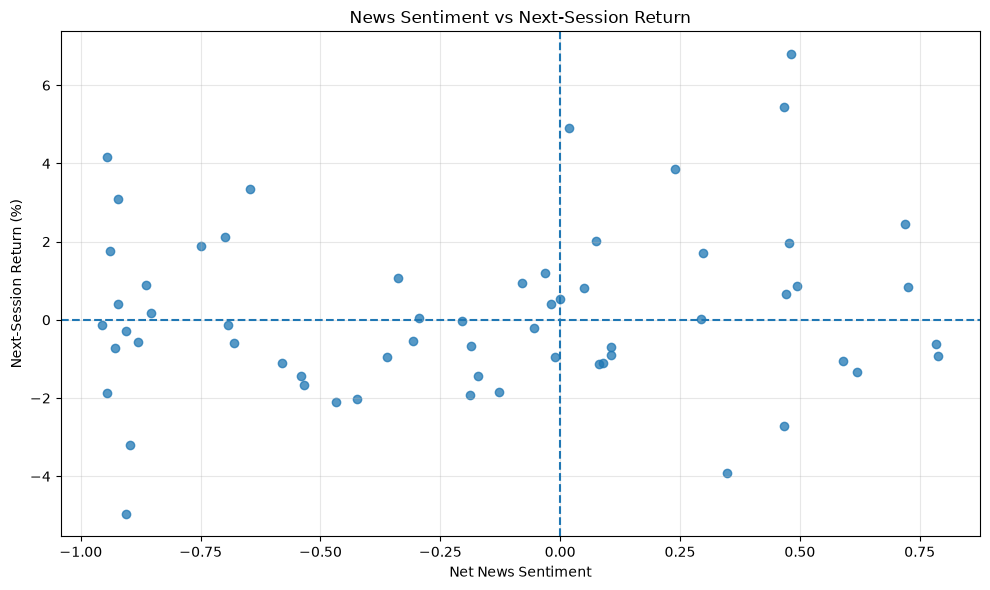

Observations: 61
Pearson Correlation: 0.1336
STEP 212 COMPLETED!


In [ ]:
# STEP 212: SENTIMENT VS NEXT-SESSION RETURN PLOT

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    correlation_df["Net_Sentiment"],
    correlation_df["Next_Session_Return"],
    alpha=0.75
)

plt.axhline(0, linestyle="--")
plt.axvline(0, linestyle="--")

plt.title("News Sentiment vs Next-Session Return")
plt.xlabel("Net News Sentiment")
plt.ylabel("Next-Session Return (%)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Observations: {len(correlation_df)}")
print(f"Pearson Correlation: {correlation:.4f}")
print("STEP 212 COMPLETED!")

In [ ]:
# STEP 213: SENTIMENT FEATURES READY KARO

import pandas as pd
import numpy as np

sentiment_ml_df = market_news_aligned_df.copy()

sentiment_columns = [
    "News_Count",
    "Positive_Probability",
    "Negative_Probability",
    "Neutral_Probability",
    "Average_Confidence",
    "Net_Sentiment"
]

# Indicator: is trading date ke liye news available thi?
sentiment_ml_df["Has_News"] = (
    sentiment_ml_df["Net_Sentiment"].notna()
).astype(int)

# News na hone par count zero; baaki sentiment features neutral defaults
sentiment_ml_df["News_Count"] = (
    sentiment_ml_df["News_Count"].fillna(0)
)

for column in sentiment_columns[1:]:
    sentiment_ml_df[column] = sentiment_ml_df[column].fillna(0)

print("===== SENTIMENT ML DATASET =====")
print("Total rows:", len(sentiment_ml_df))
print("Dates with news:", sentiment_ml_df["Has_News"].sum())
print("Dates without news:", (sentiment_ml_df["Has_News"] == 0).sum())
print("Missing sentiment values:",
      sentiment_ml_df[sentiment_columns].isna().sum().sum())

display(
    sentiment_ml_df[
        ["Market_Date"] + sentiment_columns + ["Has_News"]
    ].tail(10).round(4)
)

print("\nSTEP 213 COMPLETED!")

===== SENTIMENT ML DATASET =====
Total rows: 1237
Dates with news: 62
Dates without news: 1175
Missing sentiment values: 0


,Market_Date,News_Count,Positive_Probability,Negative_Probability,Neutral_Probability,Average_Confidence,Net_Sentiment,Has_News
1227,2026-10-05,10.0,0.1295,0.3157,0.5548,0.7969,-0.1862,1
1228,2026-10-06,2.0,0.0503,0.4106,0.5391,0.8527,-0.3603,1
1229,2026-10-07,4.0,0.2257,0.2812,0.4930,0.7788,-0.0555,1
1230,2026-10-08,2.0,0.3653,0.1255,0.5092,0.8019,0.2397,1
1231,2026-10-09,11.0,0.2479,0.4187,0.3334,0.8444,-0.1707,1
1232,2026-10-12,24.0,0.6449,0.1636,0.1915,0.8452,0.4813,1
1233,2026-10-13,3.0,0.0281,0.7270,0.2449,0.8569,-0.6988,1
1234,2026-10-14,4.0,0.5288,0.0518,0.4193,0.7469,0.4770,1
1235,2026-10-15,13.0,0.3875,0.3694,0.2431,0.8166,0.0181,1
1236,2026-10-16,36.0,0.4320,0.1114,0.4566,0.7788,0.3205,1



STEP 213 COMPLETED!


In [ ]:
# STEP 214: NEXT-SESSION RETURN TARGET BANAO

model_df = sentiment_ml_df.copy()

model_df["Close"] = pd.to_numeric(
    model_df["Close"], errors="coerce"
)

model_df["Next_Session_Return"] = (
    model_df["Close"].shift(-1) / model_df["Close"] - 1
) * 100

model_df = model_df.dropna(
    subset=["Close", "Next_Session_Return"]
).copy()

print("===== MODEL DATASET READY =====")
print("Total usable rows:", len(model_df))
print("First market date:", model_df["Market_Date"].iloc[0])
print("Last market date:", model_df["Market_Date"].iloc[-1])
print("Missing target values:",
      model_df["Next_Session_Return"].isna().sum())

display(
    model_df[
        [
            "Market_Date",
            "Close",
            "Next_Session_Return",
            "Net_Sentiment",
            "News_Count",
            "Has_News"
        ]
    ].tail(10).round(4)
)

print("\nSTEP 214 COMPLETED!")

===== MODEL DATASET READY =====
Total usable rows: 1236
First market date: 2021-10-18
Last market date: 2026-10-15
Missing target values: 0


,Market_Date,Close,Next_Session_Return,Net_Sentiment,News_Count,Has_News
1226,2026-10-01,2064.0276,1.8988,-0.7487,4.0,1
1227,2026-10-05,2103.2190,-0.6810,-0.1862,10.0,1
1228,2026-10-06,2088.8953,-0.9381,-0.3603,2.0,1
1229,2026-10-07,2069.2996,-0.2067,-0.0555,4.0,1
1230,2026-10-08,2065.0222,3.8536,0.2397,2.0,1
1231,2026-10-09,2144.5991,-1.4378,-0.1707,11.0,1
1232,2026-10-12,2113.7632,6.7906,0.4813,24.0,1
1233,2026-10-13,2257.3000,2.1087,-0.6988,3.0,1
1234,2026-10-14,2304.8999,1.9567,0.4770,4.0,1
1235,2026-10-15,2350.0000,4.8936,0.0181,13.0,1



STEP 214 COMPLETED!


In [ ]:
# STEP 215: CHRONOLOGICAL TRAIN/TEST SPLIT

split_index = int(len(model_df) * 0.80)

train_df = model_df.iloc[:split_index].copy()
test_df = model_df.iloc[split_index:].copy()

print("===== CHRONOLOGICAL SPLIT =====")
print("Total observations:", len(model_df))
print("Training observations:", len(train_df))
print("Testing observations:", len(test_df))

print("\nTraining period:")
print(train_df["Market_Date"].iloc[0], "to",
      train_df["Market_Date"].iloc[-1])

print("\nTesting period:")
print(test_df["Market_Date"].iloc[0], "to",
      test_df["Market_Date"].iloc[-1])

print("\nTraining target missing:",
      train_df["Next_Session_Return"].isna().sum())
print("Testing target missing:",
      test_df["Next_Session_Return"].isna().sum())

print("\nSTEP 215 COMPLETED!")

===== CHRONOLOGICAL SPLIT =====
Total observations: 1236
Training observations: 988
Testing observations: 248

Training period:
2021-10-18 to 2025-10-14

Testing period:
2025-10-15 to 2026-10-15

Training target missing: 0
Testing target missing: 0

STEP 215 COMPLETED!


In [ ]:
# STEP 216: ZERO-RETURN BASELINE EVALUATE KARO

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

y_test = test_df["Next_Session_Return"].to_numpy()

baseline_predictions = np.zeros(len(y_test))

baseline_mae = mean_absolute_error(
    y_test, baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

baseline_direction_accuracy = np.mean(
    np.sign(y_test) == np.sign(baseline_predictions)
) * 100

print("===== ZERO-RETURN BASELINE =====")
print("Test observations:", len(y_test))
print(f"MAE: {baseline_mae:.4f}%")
print(f"RMSE: {baseline_rmse:.4f}%")
print(f"Direction accuracy (zero predicted): {baseline_direction_accuracy:.2f}%")
print(f"Actual mean return: {np.mean(y_test):.4f}%")
print(f"Actual return standard deviation: {np.std(y_test):.4f}%")

print("\nSTEP 216 COMPLETED!")

===== ZERO-RETURN BASELINE =====
Test observations: 248
MAE: 1.3312%
RMSE: 1.8825%
Direction accuracy (zero predicted): 0.40%
Actual mean return: -0.0403%
Actual return standard deviation: 1.8820%

STEP 216 COMPLETED!


In [ ]:
# STEP 217: MARKET FEATURES SELECT KARO

market_features = [
    "Daily_Return",
    "MA20",
    "MA50",
    "RSI_14",
    "Return_5D",
    "Return_10D",
    "High_Low_Range",
    "Open_Close_Change",
    "Volume_Change"
]

sentiment_features = [
    "News_Count",
    "Positive_Probability",
    "Negative_Probability",
    "Neutral_Probability",
    "Average_Confidence",
    "Net_Sentiment",
    "Has_News"
]

available_features = [
    column
    for column in market_features + sentiment_features
    if column in model_df.columns
]

print("===== FEATURE CHECK =====")
print("Market features available:",
      [c for c in market_features if c in model_df.columns])
print("Sentiment features available:",
      [c for c in sentiment_features if c in model_df.columns])
print("Total features:", len(available_features))

missing_features = [
    c for c in market_features + sentiment_features
    if c not in model_df.columns
]
print("Features not found:", missing_features)

print("\nSTEP 217 COMPLETED!")

===== FEATURE CHECK =====
Market features available: ['Daily_Return', 'MA20', 'MA50', 'RSI_14']
Sentiment features available: ['News_Count', 'Positive_Probability', 'Negative_Probability', 'Neutral_Probability', 'Average_Confidence', 'Net_Sentiment', 'Has_News']
Total features: 11
Features not found: ['Return_5D', 'Return_10D', 'High_Low_Range', 'Open_Close_Change', 'Volume_Change']

STEP 217 COMPLETED!


In [ ]:
# STEP 218: MISSING MARKET FEATURES BANAO

feature_df = sentiment_ml_df.copy()

# Ensure numeric market columns
for column in ["Open", "High", "Low", "Close", "Volume"]:
    if column in feature_df.columns:
        feature_df[column] = pd.to_numeric(
            feature_df[column], errors="coerce"
        )

# 5-day and 10-day returns
feature_df["Return_5D"] = (
    feature_df["Close"].pct_change(5) * 100
)

feature_df["Return_10D"] = (
    feature_df["Close"].pct_change(10) * 100
)

# High-low daily range as percentage of previous close
previous_close = feature_df["Close"].shift(1)

feature_df["High_Low_Range"] = (
    (feature_df["High"] - feature_df["Low"])
    / previous_close * 100
)

# Open-close percentage change
feature_df["Open_Close_Change"] = (
    (feature_df["Close"] - feature_df["Open"])
    / feature_df["Open"] * 100
)

# Volume percentage change
feature_df["Volume_Change"] = (
    feature_df["Volume"].pct_change() * 100
)

new_features = [
    "Return_5D",
    "Return_10D",
    "High_Low_Range",
    "Open_Close_Change",
    "Volume_Change"
]

print("===== NEW MARKET FEATURES =====")
print(feature_df[new_features].tail(10).round(4))

print("\nMissing values in new features:")
print(feature_df[new_features].isna().sum())

print("\nSTEP 218 COMPLETED!")

===== NEW MARKET FEATURES =====
      Return_5D  Return_10D  High_Low_Range  Open_Close_Change  Volume_Change
1227     1.5562      0.4465          3.7253             0.0189        53.7339
1228     1.4150     -1.3482          1.5276             0.1431       -54.7977
1229     2.3568     -1.1734          1.3810            -0.2350       -43.3472
1230     1.2387     -0.6508          3.9177            -1.3308       217.6889
1231     3.9036      3.3062          5.6840             3.3557       172.6733
1232     0.5013      2.0653          3.4416            -2.7415       -69.7192
1233     8.0619      9.5910          5.3788             5.2112       212.0497
1234    11.3855     14.0107          3.1099             1.3588         9.9344
1235    13.8002     15.2098          2.2430             0.1193       -24.6608
1236    14.9399     19.4267          4.6383             3.4845        32.9611

Missing values in new features:
Return_5D             5
Return_10D           10
High_Low_Range        1
Open_

In [ ]:
# STEP 219: FINAL FEATURE LIST VERIFY KARO

market_features = [
    "Daily_Return",
    "MA20",
    "MA50",
    "RSI_14",
    "Return_5D",
    "Return_10D",
    "High_Low_Range",
    "Open_Close_Change",
    "Volume_Change"
]

sentiment_features = [
    "News_Count",
    "Positive_Probability",
    "Negative_Probability",
    "Neutral_Probability",
    "Average_Confidence",
    "Net_Sentiment",
    "Has_News"
]

all_features = market_features + sentiment_features

print("===== FINAL FEATURE CHECK =====")
print("Total features:", len(all_features))
print("Market features:", len(market_features))
print("Sentiment features:", len(sentiment_features))

missing = [
    col for col in all_features
    if col not in feature_df.columns
]

print("\nFeatures missing from dataset:", missing)

print("\nFeature data types:")
print(feature_df[all_features].dtypes)

print("\nMissing values per feature:")
print(feature_df[all_features].isna().sum())

print("\nSTEP 219 COMPLETED!")

===== FINAL FEATURE CHECK =====
Total features: 16
Market features: 9
Sentiment features: 7

Features missing from dataset: []

Feature data types:
Daily_Return            float64
MA20                    float64
MA50                    float64
RSI_14                  float64
Return_5D               float64
Return_10D              float64
High_Low_Range          float64
Open_Close_Change       float64
Volume_Change           float64
News_Count              float64
Positive_Probability    float64
Negative_Probability    float64
Neutral_Probability     float64
Average_Confidence      float64
Net_Sentiment           float64
Has_News                  int64
dtype: object

Missing values per feature:
Daily_Return             1
MA20                    19
MA50                    49
RSI_14                  14
Return_5D                5
Return_10D              10
High_Low_Range           1
Open_Close_Change        0
Volume_Change            1
News_Count               0
Positive_Probability     0


In [ ]:
# STEP 220: PREDICTION DATA SAHI TARAH ALIGN KARO

prediction_df = feature_df.copy()

# Keep dates in chronological order
prediction_df = prediction_df.sort_index()

# Target: next trading session's close-to-close return
prediction_df["Target_Return"] = (
    prediction_df["Close"].shift(-1)
    / prediction_df["Close"] - 1
) * 100

# News assigned to the next trading session is used for that session's prediction.
# Shift sentiment features back one row so they align with the previous market close.
for column in sentiment_features:
    prediction_df[column] = prediction_df[column].shift(-1)

# Remove rows with unavailable target or required feature values
required_columns = all_features + ["Target_Return"]
clean_prediction_df = prediction_df.dropna(
    subset=required_columns
).copy()

print("===== PREDICTION DATA ALIGNMENT =====")
print("Original rows:", len(prediction_df))
print("Usable rows:", len(clean_prediction_df))
print("First prediction date:", clean_prediction_df.index.min())
print("Last prediction date:", clean_prediction_df.index.max())
print("Missing required values:",
      int(clean_prediction_df[required_columns].isna().sum().sum()))

print("\nSample aligned data:")
print(
    clean_prediction_df[
        ["Close", "News_Count", "Net_Sentiment", "Target_Return"]
    ].tail(10).round(4)
)

print("\nSTEP 220 COMPLETED!")

===== PREDICTION DATA ALIGNMENT =====
Original rows: 1237
Usable rows: 1187
First prediction date: 49
Last prediction date: 1235
Missing required values: 0

Sample aligned data:
          Close  News_Count  Net_Sentiment  Target_Return
1226  2064.0276        10.0        -0.1862         1.8988
1227  2103.2190         2.0        -0.3603        -0.6810
1228  2088.8953         4.0        -0.0555        -0.9381
1229  2069.2996         2.0         0.2397        -0.2067
1230  2065.0222        11.0        -0.1707         3.8536
1231  2144.5991        24.0         0.4813        -1.4378
1232  2113.7632         3.0        -0.6988         6.7906
1233  2257.3000         4.0         0.4770         2.1087
1234  2304.8999        13.0         0.0181         1.9567
1235  2350.0000        36.0         0.3205         4.8936

STEP 220 COMPLETED!


In [ ]:
# STEP 221: ACTUAL TRADING DATES VERIFY KARO

print("===== DATE INDEX VERIFICATION =====")

print("Original df index type:", type(df.index))
print("Original df index sample:")
print(df.index[:5].tolist())

print("\nPrediction DataFrame index sample:")
print(clean_prediction_df.index[:5].tolist())

# Restore actual market dates from the original market dataframe
original_dates = pd.to_datetime(df.index)

clean_prediction_df["Market_Date"] = (
    original_dates[
        clean_prediction_df.index.astype(int)
    ].to_numpy()
)

print("\nRestored date sample:")
print(
    clean_prediction_df[
        ["Market_Date", "Close", "Target_Return"]
    ].head(5)
)

print("\nFirst date:", clean_prediction_df["Market_Date"].min())
print("Last date:", clean_prediction_df["Market_Date"].max())
print("Duplicate dates:", clean_prediction_df["Market_Date"].duplicated().sum())

print("\nSTEP 221 COMPLETED!")

===== DATE INDEX VERIFICATION =====
Original df index type: <class 'pandas.DatetimeIndex'>
Original df index sample:
[Timestamp('2021-10-18 00:00:00'), Timestamp('2021-10-19 00:00:00'), Timestamp('2021-10-20 00:00:00'), Timestamp('2021-10-21 00:00:00'), Timestamp('2021-10-22 00:00:00')]

Prediction DataFrame index sample:
[49, 50, 51, 52, 53]

Restored date sample:
   Market_Date        Close  Target_Return
49  2021-12-28  3208.993408      -0.319712
50  2021-12-29  3198.733887       1.056914
51  2021-12-30  3232.541748       0.123221
52  2021-12-31  3236.524902       2.123928
53  2022-01-03  3305.266357       1.754960

First date: 2021-12-28 00:00:00
Last date: 2026-10-15 00:00:00
Duplicate dates: 0

STEP 221 COMPLETED!


In [ ]:
# STEP 222: CHRONOLOGICAL TRAIN/TEST SPLIT

clean_prediction_df = clean_prediction_df.sort_values(
    "Market_Date"
).reset_index(drop=True)

split_index = int(len(clean_prediction_df) * 0.80)

train_df = clean_prediction_df.iloc[:split_index].copy()
test_df = clean_prediction_df.iloc[split_index:].copy()

print("===== CHRONOLOGICAL DATA SPLIT =====")
print("Total observations:", len(clean_prediction_df))
print("Training observations:", len(train_df))
print("Testing observations:", len(test_df))

print("\nTraining period:")
print(train_df["Market_Date"].min(), "to", train_df["Market_Date"].max())

print("\nTesting period:")
print(test_df["Market_Date"].min(), "to", test_df["Market_Date"].max())

print("\nNews availability:")
print("Training dates with news:", int((train_df["Has_News"] == 1).sum()))
print("Testing dates with news:", int((test_df["Has_News"] == 1).sum()))

print("\nTraining target missing:", train_df["Target_Return"].isna().sum())
print("Testing target missing:", test_df["Target_Return"].isna().sum())

print("\nSTEP 222 COMPLETED!")

===== CHRONOLOGICAL DATA SPLIT =====
Total observations: 1187
Training observations: 949
Testing observations: 238

Training period:
2021-12-28 00:00:00 to 2025-10-29 00:00:00

Testing period:
2025-10-30 00:00:00 to 2026-10-15 00:00:00

News availability:
Training dates with news: 0
Testing dates with news: 62

Training target missing: 0
Testing target missing: 0

STEP 222 COMPLETED!


In [ ]:
# STEP 223: NEWS DATA COVERAGE CHECK KARO

print("===== NEWS DATA COVERAGE =====")

news_dates = clean_prediction_df.loc[
    clean_prediction_df["Has_News"] == 1,
    "Market_Date"
]

if len(news_dates) > 0:
    print("First date with news:", news_dates.min())
    print("Last date with news:", news_dates.max())
else:
    print("No dates with news found.")

print("\nTraining news coverage:")
print(
    train_df.loc[
        train_df["Has_News"] == 1,
        ["Market_Date", "News_Count", "Net_Sentiment"]
    ].head(10)
)

print("\nTesting news coverage:")
print(
    test_df.loc[
        test_df["Has_News"] == 1,
        ["Market_Date", "News_Count", "Net_Sentiment"]
    ].head(10)
)

print("\nSTEP 223 COMPLETED!")

===== NEWS DATA COVERAGE =====
First date with news: 2025-12-30 00:00:00
Last date with news: 2026-10-15 00:00:00

Training news coverage:
Empty DataFrame
Columns: [Market_Date, News_Count, Net_Sentiment]
Index: []

Testing news coverage:
     Market_Date  News_Count  Net_Sentiment
990   2025-12-30         1.0         0.4701
992   2026-01-01         1.0         0.5905
1007  2026-01-22         1.0        -0.9549
1038  2026-03-10         1.0         0.7886
1041  2026-03-13         1.0        -0.9286
1045  2026-03-19         1.0        -0.9054
1051  2026-03-30         1.0        -0.9388
1065  2026-04-22         1.0        -0.9057
1080  2026-05-14         1.0         0.7257
1089  2026-05-27         1.0         0.2988

STEP 223 COMPLETED!


In [ ]:
# STEP 224: RECENT PERIOD KE LIYE DATA READY KARO

recent_df = clean_prediction_df.loc[
    clean_prediction_df["Market_Date"] >= pd.Timestamp("2025-12-30")
].copy()

recent_news_df = recent_df.loc[
    recent_df["Has_News"] == 1
].copy()

print("===== RECENT PERIOD DATA =====")
print("Recent period observations:", len(recent_df))
print("First date:", recent_df["Market_Date"].min())
print("Last date:", recent_df["Market_Date"].max())

print("\nDates with news:", len(recent_news_df))
print(
    "News coverage:",
    round(len(recent_news_df) / len(recent_df) * 100, 2),
    "%"
)

print("\nNews count distribution:")
print(recent_news_df["News_Count"].describe().round(2))

print("\nTarget return distribution:")
print(recent_df["Target_Return"].describe().round(4))

print("\nSTEP 224 COMPLETED!")

===== RECENT PERIOD DATA =====
Recent period observations: 197
First date: 2025-12-30 00:00:00
Last date: 2026-10-15 00:00:00

Dates with news: 62
News coverage: 31.47 %

News count distribution:
count    62.00
mean      3.74
std       5.58
min       1.00
25%       1.00
50%       2.00
75%       4.00
max      36.00
Name: News_Count, dtype: float64

Target return distribution:
count    197.0000
mean      -0.0972
std        2.0578
min       -8.3861
25%       -1.1808
50%       -0.1244
75%        0.9579
max        6.7906
Name: Target_Return, dtype: float64

STEP 224 COMPLETED!


In [ ]:
# STEP 225: RECENT PERIOD KA BASELINE BANAO

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

y_recent = recent_df["Target_Return"].to_numpy()
zero_predictions = np.zeros(len(y_recent))

baseline_mae = mean_absolute_error(
    y_recent, zero_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_recent, zero_predictions)
)

baseline_mean_return = np.mean(y_recent)

print("===== RECENT PERIOD BASELINE =====")
print("Observations:", len(y_recent))
print(f"Zero-return MAE: {baseline_mae:.4f}%")
print(f"Zero-return RMSE: {baseline_rmse:.4f}%")
print(f"Actual average return: {baseline_mean_return:.4f}%")
print(f"Actual return standard deviation: {np.std(y_recent):.4f}%")

print("\nSTEP 225 COMPLETED!")

===== RECENT PERIOD BASELINE =====
Observations: 197
Zero-return MAE: 1.4893%
Zero-return RMSE: 2.0548%
Actual average return: -0.0972%
Actual return standard deviation: 2.0525%

STEP 225 COMPLETED!


In [ ]:
# STEP 226: MARKET-ONLY MODEL KE LIYE DATA SPLIT KARO

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

market_features = [
    "Daily_Return",
    "MA20",
    "MA50",
    "RSI_14",
    "Return_5D",
    "Return_10D",
    "High_Low_Range",
    "Open_Close_Change",
    "Volume_Change"
]

recent_model_df = recent_df.sort_values("Market_Date").copy()

split_index = int(len(recent_model_df) * 0.80)

market_train_df = recent_model_df.iloc[:split_index].copy()
market_test_df = recent_model_df.iloc[split_index:].copy()

X_train_market = market_train_df[market_features]
y_train_market = market_train_df["Target_Return"]

X_test_market = market_test_df[market_features]
y_test_market = market_test_df["Target_Return"]

print("===== MARKET-ONLY SPLIT =====")
print("Training rows:", len(X_train_market))
print("Testing rows:", len(X_test_market))
print("Training period:",
      market_train_df["Market_Date"].min(),
      "to",
      market_train_df["Market_Date"].max())
print("Testing period:",
      market_test_df["Market_Date"].min(),
      "to",
      market_test_df["Market_Date"].max())

print("\nMissing training values:",
      int(X_train_market.isna().sum().sum()))
print("Missing testing values:",
      int(X_test_market.isna().sum().sum()))

print("\nSTEP 226 COMPLETED!")

===== MARKET-ONLY SPLIT =====
Training rows: 157
Testing rows: 40
Training period: 2025-12-30 00:00:00 to 2026-08-18 00:00:00
Testing period: 2026-08-19 00:00:00 to 2026-10-15 00:00:00

Missing training values: 0
Missing testing values: 0

STEP 226 COMPLETED!


In [ ]:
# STEP 227: RANDOM FOREST MODEL TRAIN KARO

market_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=4,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

market_model.fit(X_train_market, y_train_market)

market_predictions = market_model.predict(X_test_market)

market_mae = mean_absolute_error(
    y_test_market,
    market_predictions
)

market_rmse = np.sqrt(
    mean_squared_error(y_test_market, market_predictions)
)

print("===== MARKET-ONLY RANDOM FOREST =====")
print(f"MAE: {market_mae:.4f}%")
print(f"RMSE: {market_rmse:.4f}%")
print(f"Average predicted return: {np.mean(market_predictions):.4f}%")
print(f"Average actual return: {np.mean(y_test_market):.4f}%")

print("\nBaseline comparison:")
print(f"Zero-return MAE: {baseline_mae:.4f}%")
print(f"Zero-return RMSE: {baseline_rmse:.4f}%")

print("\nSTEP 227 COMPLETED!")

ValueError: Input X contains infinity or a value too large for dtype('float32').

In [ ]:
# STEP 228: INFINITY VALUES CHECK KARO

import numpy as np
import pandas as pd

# Convert feature columns to numeric and identify invalid values
X_check = X_train_market.copy()

print("===== INVALID VALUE CHECK =====")

print("\nInfinite values per feature:")
infinity_counts = pd.DataFrame(
    np.isinf(X_check.to_numpy(dtype=float)),
    columns=X_check.columns
).sum()

print(infinity_counts[infinity_counts > 0])

print("\nNaN values per feature:")
print(X_check.isna().sum()[X_check.isna().sum() > 0])

print("\nNon-finite values per feature:")
nonfinite_counts = (~np.isfinite(X_check.to_numpy(dtype=float))).sum(axis=0)

print(pd.Series(
    nonfinite_counts,
    index=X_check.columns
)[nonfinite_counts > 0])

print("\nMaximum absolute value per feature:")
print(X_check.abs().max().sort_values(ascending=False))

print("\nSTEP 228 COMPLETED!")

===== INVALID VALUE CHECK =====

Infinite values per feature:
Volume_Change    1
dtype: int64

NaN values per feature:
Series([], dtype: int64)

Non-finite values per feature:
Volume_Change    1
dtype: int64

Maximum absolute value per feature:
Volume_Change                inf
MA20                 3119.802600
MA50                 3086.459966
RSI_14                 73.196689
Return_10D             15.747379
Return_5D              12.092850
Daily_Return            8.386125
High_Low_Range          6.874002
Open_Close_Change       6.322610
dtype: float64

STEP 228 COMPLETED!


In [ ]:
# STEP 229: INVALID VALUES CLEAN KARO AUR MODEL TRAIN KARO

# Replace infinite values with NaN
X_train_clean = X_train_market.replace(
    [np.inf, -np.inf], np.nan
).copy()

X_test_clean = X_test_market.replace(
    [np.inf, -np.inf], np.nan
).copy()

y_train_clean = y_train_market.copy()
y_test_clean = y_test_market.copy()

# Keep only rows where all features and target are valid
train_valid = (
    np.isfinite(X_train_clean.to_numpy(dtype=float)).all(axis=1)
    & np.isfinite(y_train_clean.to_numpy(dtype=float))
)

test_valid = (
    np.isfinite(X_test_clean.to_numpy(dtype=float)).all(axis=1)
    & np.isfinite(y_test_clean.to_numpy(dtype=float))
)

X_train_clean = X_train_clean.loc[train_valid]
y_train_clean = y_train_clean.loc[train_valid]

X_test_clean = X_test_clean.loc[test_valid]
y_test_clean = y_test_clean.loc[test_valid]

# Train Random Forest
market_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=4,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

market_model.fit(X_train_clean, y_train_clean)

market_predictions = market_model.predict(X_test_clean)

market_mae = mean_absolute_error(
    y_test_clean, market_predictions
)

market_rmse = np.sqrt(
    mean_squared_error(y_test_clean, market_predictions)
)

# Recalculate baseline on the exact same test rows
zero_predictions = np.zeros(len(y_test_clean))

clean_baseline_mae = mean_absolute_error(
    y_test_clean, zero_predictions
)

clean_baseline_rmse = np.sqrt(
    mean_squared_error(y_test_clean, zero_predictions)
)

print("===== RANDOM FOREST RESULTS =====")
print("Training rows retained:", len(X_train_clean))
print("Testing rows retained:", len(X_test_clean))
print(f"Random Forest MAE: {market_mae:.4f}%")
print(f"Random Forest RMSE: {market_rmse:.4f}%")
print(f"Zero-return baseline MAE: {clean_baseline_mae:.4f}%")
print(f"Zero-return baseline RMSE: {clean_baseline_rmse:.4f}%")

print("\nSTEP 229 COMPLETED!")

===== RANDOM FOREST RESULTS =====
Training rows retained: 156
Testing rows retained: 40
Random Forest MAE: 1.5129%
Random Forest RMSE: 2.0901%
Zero-return baseline MAE: 1.5178%
Zero-return baseline RMSE: 2.0925%

STEP 229 COMPLETED!


In [ ]:
# STEP 230: SENTIMENT MODEL KE LIYE FEATURES READY KARO

sentiment_model_features = market_features + [
    "News_Count",
    "Positive_Probability",
    "Negative_Probability",
    "Neutral_Probability",
    "Average_Confidence",
    "Net_Sentiment",
    "Has_News"
]

X_train_sentiment = market_train_df[sentiment_model_features].copy()
X_test_sentiment = market_test_df[sentiment_model_features].copy()

y_train_sentiment = market_train_df["Target_Return"].copy()
y_test_sentiment = market_test_df["Target_Return"].copy()

print("===== SENTIMENT MODEL FEATURE CHECK =====")
print("Total features:", len(sentiment_model_features))
print("Training rows:", len(X_train_sentiment))
print("Testing rows:", len(X_test_sentiment))

print("\nTraining dates with news:",
      int((X_train_sentiment["Has_News"] == 1).sum()))
print("Testing dates with news:",
      int((X_test_sentiment["Has_News"] == 1).sum()))

print("\nMissing training values:",
      int(X_train_sentiment.isna().sum().sum()))
print("Missing testing values:",
      int(X_test_sentiment.isna().sum().sum()))

print("\nSTEP 230 COMPLETED!")

===== SENTIMENT MODEL FEATURE CHECK =====
Total features: 16
Training rows: 157
Testing rows: 40

Training dates with news: 35
Testing dates with news: 27

Missing training values: 0
Missing testing values: 0

STEP 230 COMPLETED!


In [ ]:
# STEP 231: SENTIMENT DATA ALIGNMENT VERIFY KARO

print("===== SENTIMENT ALIGNMENT VERIFICATION =====")

print("\nRecent dataset:")
print("Rows:", len(recent_df))
print("Dates with news:",
      int((recent_df["Has_News"] == 1).sum()))

print("\nMarket training dataset:")
print("Rows:", len(market_train_df))
print("Dates with news:",
      int((market_train_df["Has_News"] == 1).sum()))

print("\nMarket testing dataset:")
print("Rows:", len(market_test_df))
print("Dates with news:",
      int((market_test_df["Has_News"] == 1).sum()))

print("\nTraining news examples:")
print(
    market_train_df.loc[
        market_train_df["Has_News"] == 1,
        ["Market_Date", "News_Count", "Net_Sentiment"]
    ].head(10)
)

print("\nTesting news examples:")
print(
    market_test_df.loc[
        market_test_df["Has_News"] == 1,
        ["Market_Date", "News_Count", "Net_Sentiment"]
    ].head(10)
)

print("\nSTEP 231 COMPLETED!")

===== SENTIMENT ALIGNMENT VERIFICATION =====

Recent dataset:
Rows: 197
Dates with news: 62

Market training dataset:
Rows: 157
Dates with news: 35

Market testing dataset:
Rows: 40
Dates with news: 27

Training news examples:
     Market_Date  News_Count  Net_Sentiment
990   2025-12-30         1.0         0.4701
992   2026-01-01         1.0         0.5905
1007  2026-01-22         1.0        -0.9549
1038  2026-03-10         1.0         0.7886
1041  2026-03-13         1.0        -0.9286
1045  2026-03-19         1.0        -0.9054
1051  2026-03-30         1.0        -0.9388
1065  2026-04-22         1.0        -0.9057
1080  2026-05-14         1.0         0.7257
1089  2026-05-27         1.0         0.2988

Testing news examples:
     Market_Date  News_Count  Net_Sentiment
1147  2026-08-19         4.0        -0.8545
1149  2026-08-21         2.0         0.0004
1150  2026-08-24         2.0         0.0813
1151  2026-08-25         6.0        -0.0105
1152  2026-08-26         2.0        -0.9450
1

In [ ]:
# STEP 232: MARKET + SENTIMENT RANDOM FOREST TRAIN KARO

sentiment_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=4,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

sentiment_model.fit(
    X_train_sentiment,
    y_train_sentiment
)

sentiment_predictions = sentiment_model.predict(
    X_test_sentiment
)

sentiment_mae = mean_absolute_error(
    y_test_sentiment,
    sentiment_predictions
)

sentiment_rmse = np.sqrt(
    mean_squared_error(
        y_test_sentiment,
        sentiment_predictions
    )
)

print("===== MARKET + SENTIMENT RESULTS =====")
print("Training rows:", len(X_train_sentiment))
print("Testing rows:", len(X_test_sentiment))
print(f"MAE: {sentiment_mae:.4f}%")
print(f"RMSE: {sentiment_rmse:.4f}%")
print(
    f"Average predicted return: "
    f"{np.mean(sentiment_predictions):.4f}%"
)

print("\nSTEP 232 COMPLETED!")

ValueError: Input X contains infinity or a value too large for dtype('float32').

In [ ]:
# STEP 233: SENTIMENT DATA CLEAN KARO AUR MODEL TRAIN KARO

# Replace infinite values with NaN
X_train_sentiment_clean = X_train_sentiment.replace(
    [np.inf, -np.inf], np.nan
).copy()

X_test_sentiment_clean = X_test_sentiment.replace(
    [np.inf, -np.inf], np.nan
).copy()

# Keep only rows with finite features and targets
train_valid = (
    np.isfinite(
        X_train_sentiment_clean.to_numpy(dtype=float)
    ).all(axis=1)
    & np.isfinite(
        y_train_sentiment.to_numpy(dtype=float)
    )
)

test_valid = (
    np.isfinite(
        X_test_sentiment_clean.to_numpy(dtype=float)
    ).all(axis=1)
    & np.isfinite(
        y_test_sentiment.to_numpy(dtype=float)
    )
)

X_train_sentiment_clean = X_train_sentiment_clean.loc[train_valid]
y_train_sentiment_clean = y_train_sentiment.loc[train_valid]

X_test_sentiment_clean = X_test_sentiment_clean.loc[test_valid]
y_test_sentiment_clean = y_test_sentiment.loc[test_valid]

# Train model
sentiment_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=4,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

sentiment_model.fit(
    X_train_sentiment_clean,
    y_train_sentiment_clean
)

sentiment_predictions = sentiment_model.predict(
    X_test_sentiment_clean
)

sentiment_mae = mean_absolute_error(
    y_test_sentiment_clean,
    sentiment_predictions
)

sentiment_rmse = np.sqrt(
    mean_squared_error(
        y_test_sentiment_clean,
        sentiment_predictions
    )
)

print("===== MARKET + SENTIMENT RESULTS =====")
print("Training rows retained:", len(X_train_sentiment_clean))
print("Testing rows retained:", len(X_test_sentiment_clean))
print(f"MAE: {sentiment_mae:.4f}%")
print(f"RMSE: {sentiment_rmse:.4f}%")
print(f"Average predicted return: {np.mean(sentiment_predictions):.4f}%")

print("\nSTEP 233 COMPLETED!")

===== MARKET + SENTIMENT RESULTS =====
Training rows retained: 156
Testing rows retained: 40
MAE: 1.5129%
RMSE: 2.0918%
Average predicted return: -0.1760%

STEP 233 COMPLETED!


In [ ]:
# STEP 234: TEENO MODELS KA FAIR COMPARISON

comparison_df = pd.DataFrame([
    {
        "Model": "Zero-Return Baseline",
        "MAE (%)": mean_absolute_error(
            y_test_sentiment_clean,
            np.zeros(len(y_test_sentiment_clean))
        ),
        "RMSE (%)": np.sqrt(
            mean_squared_error(
                y_test_sentiment_clean,
                np.zeros(len(y_test_sentiment_clean))
            )
        )
    },
    {
        "Model": "Market-Only Random Forest",
        "MAE (%)": market_mae,
        "RMSE (%)": market_rmse
    },
    {
        "Model": "Market + Sentiment Random Forest",
        "MAE (%)": sentiment_mae,
        "RMSE (%)": sentiment_rmse
    }
])

comparison_df = comparison_df.round(4)

print("===== MODEL PERFORMANCE COMPARISON =====")
display(comparison_df.sort_values("MAE (%)").reset_index(drop=True))

print("\nSTEP 234 COMPLETED!")

===== MODEL PERFORMANCE COMPARISON =====


,Model,MAE (%),RMSE (%)
0,Market-Only Random Forest,1.5129,2.0901
1,Market + Sentiment Random Forest,1.5129,2.0918
2,Zero-Return Baseline,1.5178,2.0925



STEP 234 COMPLETED!


In [ ]:
# STEP 235: SENTIMENT MODEL FEATURE IMPORTANCE

feature_importance_df = pd.DataFrame({
    "Feature": X_train_sentiment_clean.columns,
    "Importance": sentiment_model.feature_importances_
})

feature_importance_df = (
    feature_importance_df
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

print("===== TOP 10 IMPORTANT FEATURES =====")
display(feature_importance_df.head(10).round(4))

print("\nSTEP 235 COMPLETED!")

===== TOP 10 IMPORTANT FEATURES =====


,Feature,Importance
0,RSI_14,0.1523
1,Return_10D,0.1452
2,MA20,0.1339
3,High_Low_Range,0.1140
4,MA50,0.1043
5,Volume_Change,0.0789
6,Open_Close_Change,0.0744
7,Return_5D,0.0692
8,Daily_Return,0.0561
9,Average_Confidence,0.0340



STEP 235 COMPLETED!


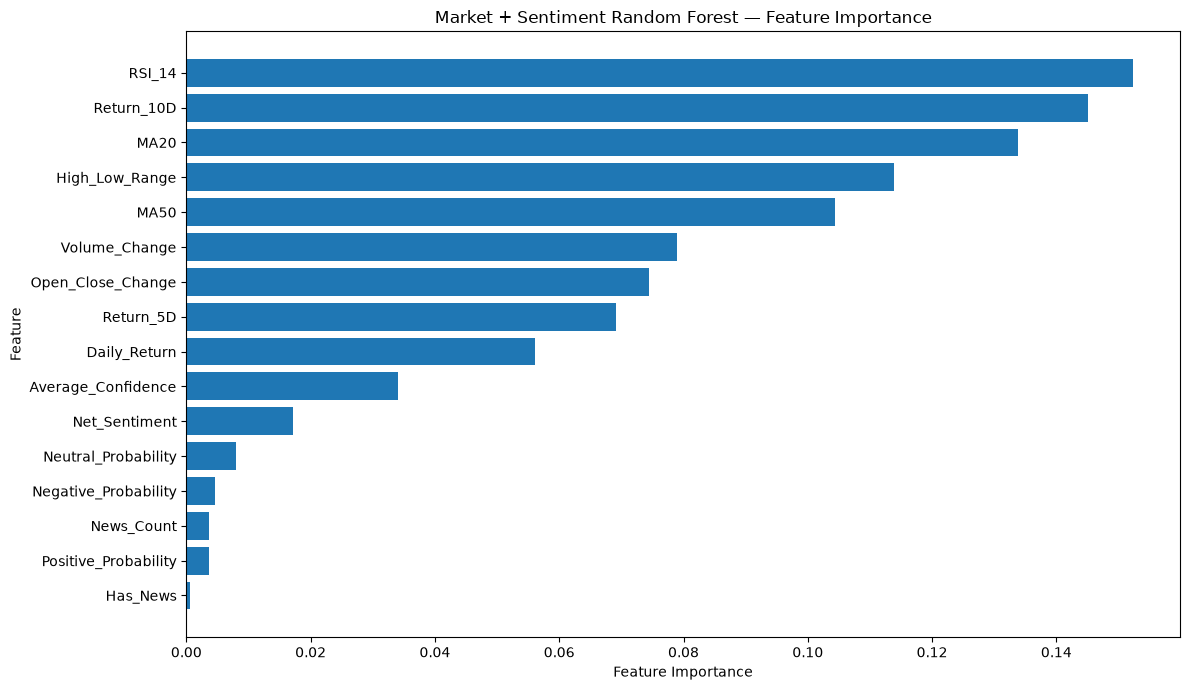

STEP 236 COMPLETED!


In [ ]:
# STEP 236: ALL FEATURES KI IMPORTANCE KA BAR CHART

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

plt.barh(
    feature_importance_df["Feature"][::-1],
    feature_importance_df["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Market + Sentiment Random Forest — Feature Importance")
plt.tight_layout()
plt.show()

print("STEP 236 COMPLETED!")

In [ ]:
# STEP 237: MARKET VS SENTIMENT COLLECTIVE IMPORTANCE

market_features = [
    "Daily_Return",
    "MA20",
    "MA50",
    "RSI_14",
    "Return_5D",
    "Return_10D",
    "High_Low_Range",
    "Open_Close_Change",
    "Volume_Change"
]

sentiment_features = [
    "News_Count",
    "Positive_Probability",
    "Negative_Probability",
    "Neutral_Probability",
    "Average_Confidence",
    "Net_Sentiment",
    "Has_News"
]

importance_lookup = feature_importance_df.set_index("Feature")["Importance"]

market_importance = importance_lookup.reindex(
    market_features
).fillna(0).sum()

sentiment_importance = importance_lookup.reindex(
    sentiment_features
).fillna(0).sum()

group_importance_df = pd.DataFrame({
    "Feature Group": ["Market Features", "Sentiment Features"],
    "Total Importance": [
        market_importance,
        sentiment_importance
    ]
})

group_importance_df["Share (%)"] = (
    group_importance_df["Total Importance"]
    / group_importance_df["Total Importance"].sum()
    * 100
)

print("===== COLLECTIVE FEATURE IMPORTANCE =====")
display(group_importance_df.round(4))

print("\nSTEP 237 COMPLETED!")

===== COLLECTIVE FEATURE IMPORTANCE =====


,Feature Group,Total Importance,Share (%)
0,Market Features,0.9283,92.8252
1,Sentiment Features,0.0717,7.1748



STEP 237 COMPLETED!


In [ ]:
# STEP 238: PREDICTED VS ACTUAL RETURNS CHECK

prediction_comparison_df = pd.DataFrame({
    "Actual_Return (%)": y_test_sentiment_clean,
    "Predicted_Return (%)": sentiment_predictions
})

prediction_comparison_df["Absolute_Error (%)"] = (
    prediction_comparison_df["Actual_Return (%)"]
    - prediction_comparison_df["Predicted_Return (%)"]
).abs()

# Restore corresponding test dates
prediction_comparison_df["Market_Date"] = (
    market_test_df.loc[
        prediction_comparison_df.index, "Market_Date"
    ].values
    if "Market_Date" in market_test_df.columns
    else market_test_df.loc[
        X_test_sentiment_clean.index
    ].index
)

prediction_comparison_df = (
    prediction_comparison_df
    .reset_index(drop=True)
)

print("===== ACTUAL VS PREDICTED RETURNS =====")
display(prediction_comparison_df.head(10).round(4))

print("\nSTEP 238 COMPLETED!")

===== ACTUAL VS PREDICTED RETURNS =====


C:\Users\Hp Victus\AppData\Local\Temp\ipykernel_39764\714721736.py:30: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(prediction_comparison_df.head(10).round(4))


,Actual_Return (%),Predicted_Return (%),Absolute_Error (%),Market_Date
0,0.3932,-0.3437,0.7369,2026-08-19
1,0.1741,-0.1796,0.3537,2026-08-20
2,-0.7776,-0.3716,0.4059,2026-08-21
3,0.5297,-0.0742,0.6039,2026-08-24
4,-1.1410,-0.2185,0.9225,2026-08-25
5,-0.9515,-0.1344,0.8172,2026-08-26
6,4.1630,-0.2543,4.4173,2026-08-27
7,2.4466,-0.2040,2.6506,2026-08-28
8,-1.2629,-0.7658,0.4970,2026-08-31
9,-0.8864,0.1300,1.0164,2026-09-01



STEP 238 COMPLETED!


In [ ]:
# STEP 239: PREDICTION DIRECTION ACCURACY CHECK

actual_returns = y_test_sentiment_clean.to_numpy(dtype=float)
predicted_returns = np.asarray(sentiment_predictions, dtype=float)

actual_direction = np.sign(actual_returns)
predicted_direction = np.sign(predicted_returns)

direction_accuracy = np.mean(
    actual_direction == predicted_direction
) * 100

actual_positive = actual_returns > 0
predicted_positive = predicted_returns > 0

positive_actual_count = int(actual_positive.sum())
negative_actual_count = int((actual_returns < 0).sum())

print("===== DIRECTION PREDICTION RESULTS =====")
print("Testing observations:", len(actual_returns))
print("Actual positive-return days:", positive_actual_count)
print("Actual negative-return days:", negative_actual_count)
print(f"Direction accuracy: {direction_accuracy:.2f}%")

print("\nSTEP 239 COMPLETED!")

===== DIRECTION PREDICTION RESULTS =====
Testing observations: 40
Actual positive-return days: 16
Actual negative-return days: 24
Direction accuracy: 57.50%

STEP 239 COMPLETED!


In [ ]:
# STEP 240: DIRECTION ACCURACY BASELINE COMPARISON

actual_returns = y_test_sentiment_clean.to_numpy(dtype=float)
predicted_returns = np.asarray(sentiment_predictions, dtype=float)

# Model predicts direction using the sign of predicted return
model_direction_accuracy = np.mean(
    np.sign(actual_returns) == np.sign(predicted_returns)
) * 100

# Baseline 1: predict negative every day
always_negative_accuracy = np.mean(
    actual_returns < 0
) * 100

# Baseline 2: predict positive every day
always_positive_accuracy = np.mean(
    actual_returns > 0
) * 100

direction_comparison_df = pd.DataFrame({
    "Strategy": [
        "Market + Sentiment Random Forest",
        "Always Predict Negative",
        "Always Predict Positive"
    ],
    "Direction Accuracy (%)": [
        model_direction_accuracy,
        always_negative_accuracy,
        always_positive_accuracy
    ]
})

print("===== DIRECTION ACCURACY COMPARISON =====")
display(
    direction_comparison_df
    .sort_values("Direction Accuracy (%)", ascending=False)
    .reset_index(drop=True)
    .round(2)
)

print("\nSTEP 240 COMPLETED!")

===== DIRECTION ACCURACY COMPARISON =====


,Strategy,Direction Accuracy (%)
0,Always Predict Negative,60.0
1,Market + Sentiment Random Forest,57.5
2,Always Predict Positive,40.0



STEP 240 COMPLETED!


In [ ]:
# STEP 241: WALK-FORWARD VALIDATION KE LIYE DATA CHECK

walk_forward_df = clean_prediction_df.copy()

walk_forward_df["Market_Date"] = pd.to_datetime(
    walk_forward_df["Market_Date"]
)

walk_forward_df = (
    walk_forward_df
    .sort_values("Market_Date")
    .reset_index(drop=True)
)

print("===== WALK-FORWARD DATA CHECK =====")
print("Total rows:", len(walk_forward_df))
print("Start date:", walk_forward_df["Market_Date"].min().date())
print("End date:", walk_forward_df["Market_Date"].max().date())
print("Duplicate dates:", walk_forward_df["Market_Date"].duplicated().sum())
print("Target column exists:", "Target_Return" in walk_forward_df.columns)

print("\nSTEP 241 COMPLETED!")

===== WALK-FORWARD DATA CHECK =====
Total rows: 1187
Start date: 2021-12-28
End date: 2026-10-15
Duplicate dates: 0
Target column exists: True

STEP 241 COMPLETED!


In [ ]:
# STEP 242: WALK-FORWARD FEATURES AUR TARGET PREPARE KARO

market_features = [
    "Daily_Return",
    "MA20",
    "MA50",
    "RSI_14",
    "Return_5D",
    "Return_10D",
    "High_Low_Range",
    "Open_Close_Change",
    "Volume_Change"
]

sentiment_features = [
    "News_Count",
    "Positive_Probability",
    "Negative_Probability",
    "Neutral_Probability",
    "Average_Confidence",
    "Net_Sentiment",
    "Has_News"
]

required_features = market_features + sentiment_features

walk_forward_df = walk_forward_df.replace(
    [np.inf, -np.inf], np.nan
)

walk_forward_df = walk_forward_df.dropna(
    subset=required_features + ["Target_Return"]
).reset_index(drop=True)

print("===== WALK-FORWARD DATASET READY =====")
print("Rows retained:", len(walk_forward_df))
print("Market features:", len(market_features))
print("Sentiment features:", len(sentiment_features))
print("Total features:", len(required_features))
print("Missing feature values:", walk_forward_df[required_features].isna().sum().sum())
print("Missing targets:", walk_forward_df["Target_Return"].isna().sum())
print("Start date:", walk_forward_df["Market_Date"].min().date())
print("End date:", walk_forward_df["Market_Date"].max().date())

print("\nSTEP 242 COMPLETED!")

===== WALK-FORWARD DATASET READY =====
Rows retained: 1185
Market features: 9
Sentiment features: 7
Total features: 16
Missing feature values: 0
Missing targets: 0
Start date: 2021-12-28
End date: 2026-10-15

STEP 242 COMPLETED!


In [ ]:
# STEP 243: EXPANDING-WINDOW VALIDATION SPLITS

from sklearn.model_selection import TimeSeriesSplit

X_walk = walk_forward_df[required_features]
y_walk = walk_forward_df["Target_Return"]

time_splitter = TimeSeriesSplit(n_splits=3)

walk_forward_splits = list(
    time_splitter.split(X_walk)
)

print("===== WALK-FORWARD SPLITS =====")

for fold_number, (train_idx, test_idx) in enumerate(
    walk_forward_splits, start=1
):
    train_dates = walk_forward_df.iloc[train_idx]["Market_Date"]
    test_dates = walk_forward_df.iloc[test_idx]["Market_Date"]

    print(f"\nFold {fold_number}")
    print("Training rows:", len(train_idx))
    print("Testing rows:", len(test_idx))
    print("Train period:", train_dates.min().date(), "to", train_dates.max().date())
    print("Test period:", test_dates.min().date(), "to", test_dates.max().date())

    assert train_dates.max() < test_dates.min(), (
        "Date leakage detected!"
    )

print("\nAll folds preserve chronological order.")
print("STEP 243 COMPLETED!")

===== WALK-FORWARD SPLITS =====

Fold 1
Training rows: 297
Testing rows: 296
Train period: 2021-12-28 to 2023-03-06
Test period: 2023-03-08 to 2024-05-24

Fold 2
Training rows: 593
Testing rows: 296
Train period: 2021-12-28 to 2024-05-24
Test period: 2024-05-27 to 2025-08-01

Fold 3
Training rows: 889
Testing rows: 296
Train period: 2021-12-28 to 2025-08-01
Test period: 2025-08-04 to 2026-10-15

All folds preserve chronological order.
STEP 243 COMPLETED!


In [ ]:
# STEP 244: WALK-FORWARD MODEL EVALUATION

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

walk_forward_results = []

for fold_number, (train_idx, test_idx) in enumerate(
    walk_forward_splits, start=1
):
    train_data = walk_forward_df.iloc[train_idx]
    test_data = walk_forward_df.iloc[test_idx]

    y_train = train_data["Target_Return"].to_numpy()
    y_test = test_data["Target_Return"].to_numpy()

    X_train_market = train_data[market_features]
    X_test_market = test_data[market_features]

    X_train_sentiment = train_data[required_features]
    X_test_sentiment = test_data[required_features]

    market_model = RandomForestRegressor(
        n_estimators=200,
        max_depth=4,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )

    sentiment_model = RandomForestRegressor(
        n_estimators=200,
        max_depth=4,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )

    market_model.fit(X_train_market, y_train)
    sentiment_model.fit(X_train_sentiment, y_train)

    market_pred = market_model.predict(X_test_market)
    sentiment_pred = sentiment_model.predict(X_test_sentiment)

    baseline_pred = np.zeros(len(y_test))

    for model_name, predictions in [
        ("Zero-Return Baseline", baseline_pred),
        ("Market-Only RF", market_pred),
        ("Market + Sentiment RF", sentiment_pred)
    ]:
        walk_forward_results.append({
            "Fold": fold_number,
            "Model": model_name,
            "MAE (%)": mean_absolute_error(y_test, predictions),
            "RMSE (%)": np.sqrt(
                mean_squared_error(y_test, predictions)
            ),
            "Test_Start": test_data["Market_Date"].min().date(),
            "Test_End": test_data["Market_Date"].max().date()
        })

walk_forward_results_df = pd.DataFrame(walk_forward_results)

print("===== WALK-FORWARD RESULTS =====")
print(
    walk_forward_results_df.round(4).to_string(index=False)
)

print("\nSTEP 244 COMPLETED!")

===== WALK-FORWARD RESULTS =====
 Fold                 Model  MAE (%)  RMSE (%) Test_Start   Test_End
    1  Zero-Return Baseline   0.8878    1.1954 2023-03-08 2024-05-24
    1        Market-Only RF   0.9423    1.2624 2023-03-08 2024-05-24
    1 Market + Sentiment RF   0.9423    1.2624 2023-03-08 2024-05-24
    2  Zero-Return Baseline   0.9211    1.3279 2024-05-27 2025-08-01
    2        Market-Only RF   0.9549    1.3642 2024-05-27 2025-08-01
    2 Market + Sentiment RF   0.9551    1.3642 2024-05-27 2025-08-01
    3  Zero-Return Baseline   1.2637    1.7945 2025-08-04 2026-10-15
    3        Market-Only RF   1.2852    1.8069 2025-08-04 2026-10-15
    3 Market + Sentiment RF   1.2850    1.8068 2025-08-04 2026-10-15

STEP 244 COMPLETED!


In [ ]:
# STEP 245: OVERALL WALK-FORWARD MODEL COMPARISON

overall_walk_forward_df = (
    walk_forward_results_df
    .groupby("Model")[["MAE (%)", "RMSE (%)"]]
    .mean()
    .sort_values("MAE (%)")
    .reset_index()
)

print("===== OVERALL WALK-FORWARD COMPARISON =====")
print(overall_walk_forward_df.round(4).to_string(index=False))

best_model = overall_walk_forward_df.iloc[0]

print("\nLowest average MAE model:", best_model["Model"])
print("Average MAE:", round(best_model["MAE (%)"], 4), "%")
print("Average RMSE:", round(best_model["RMSE (%)"], 4), "%")

print("\nSTEP 245 COMPLETED!")

===== OVERALL WALK-FORWARD COMPARISON =====
                Model  MAE (%)  RMSE (%)
 Zero-Return Baseline   1.0242    1.4393
Market + Sentiment RF   1.0608    1.4778
       Market-Only RF   1.0608    1.4778

Lowest average MAE model: Zero-Return Baseline
Average MAE: 1.0242 %
Average RMSE: 1.4393 %

STEP 245 COMPLETED!


In [ ]:
# STEP 246: MODEL PERFORMANCE IMPROVEMENT CHECK

baseline_row = overall_walk_forward_df.loc[
    overall_walk_forward_df["Model"] == "Zero-Return Baseline"
].iloc[0]

comparison_rows = overall_walk_forward_df[
    overall_walk_forward_df["Model"] != "Zero-Return Baseline"
].copy()

comparison_rows["MAE Change vs Baseline (%)"] = (
    (comparison_rows["MAE (%)"] - baseline_row["MAE (%)"])
    / baseline_row["MAE (%)"] * 100
)

comparison_rows["RMSE Change vs Baseline (%)"] = (
    (comparison_rows["RMSE (%)"] - baseline_row["RMSE (%)"])
    / baseline_row["RMSE (%)"] * 100
)

print("===== MODEL PERFORMANCE VS BASELINE =====")
print(
    comparison_rows[
        [
            "Model",
            "MAE (%)",
            "RMSE (%)",
            "MAE Change vs Baseline (%)",
            "RMSE Change vs Baseline (%)"
        ]
    ].round(4).to_string(index=False)
)

print("\nPositive change = baseline se worse")
print("Negative change = baseline se better")
print("\nSTEP 246 COMPLETED!")

===== MODEL PERFORMANCE VS BASELINE =====
                Model  MAE (%)  RMSE (%)  MAE Change vs Baseline (%)  RMSE Change vs Baseline (%)
Market + Sentiment RF   1.0608    1.4778                      3.5732                       2.6795
       Market-Only RF   1.0608    1.4778                      3.5744                       2.6798

Positive change = baseline se worse
Negative change = baseline se better

STEP 246 COMPLETED!


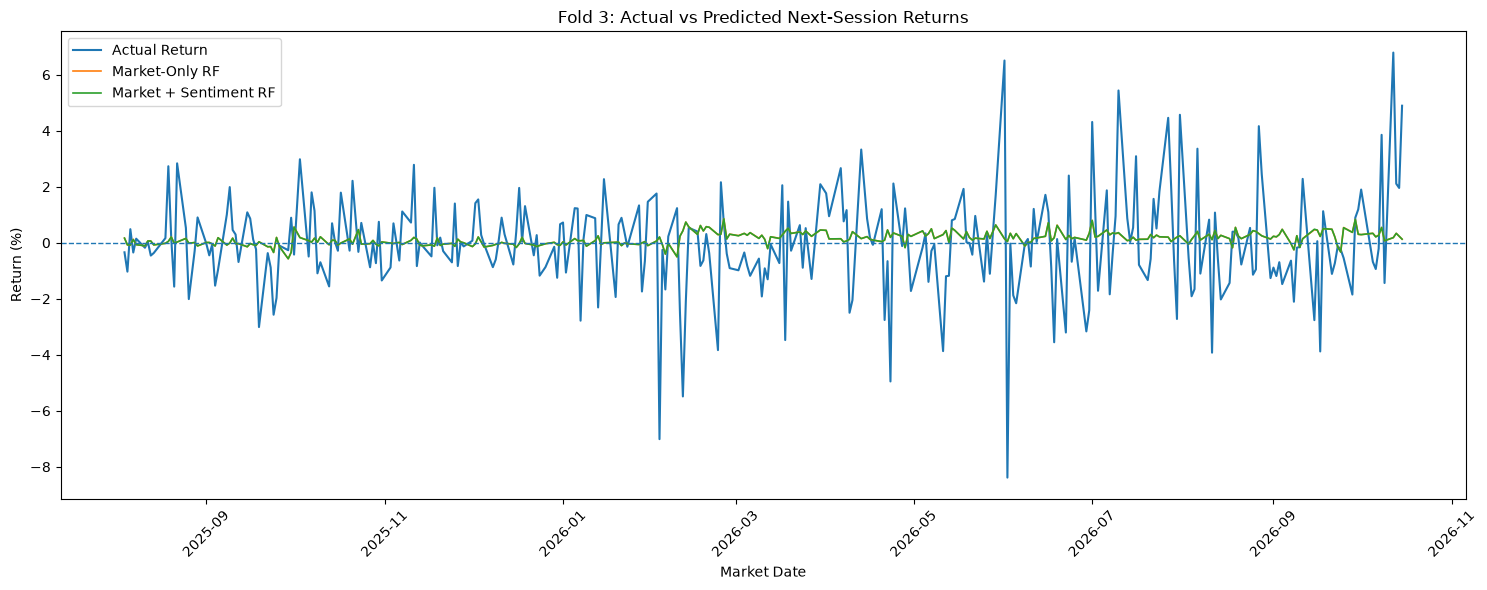

STEP 247 COMPLETED!


In [ ]:
# STEP 247: ACTUAL VS PREDICTED RETURNS VISUALIZATION

import matplotlib.pyplot as plt
import numpy as np

fold_number = 3
train_idx, test_idx = walk_forward_splits[fold_number - 1]

train_data = walk_forward_df.iloc[train_idx]
test_data = walk_forward_df.iloc[test_idx]

market_model_viz = RandomForestRegressor(
    n_estimators=200,
    max_depth=4,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

sentiment_model_viz = RandomForestRegressor(
    n_estimators=200,
    max_depth=4,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

market_model_viz.fit(train_data[market_features], train_data["Target_Return"])
sentiment_model_viz.fit(train_data[required_features], train_data["Target_Return"])

actual_returns = test_data["Target_Return"].to_numpy()
market_predictions = market_model_viz.predict(test_data[market_features])
sentiment_predictions = sentiment_model_viz.predict(test_data[required_features])

plt.figure(figsize=(15, 6))
plt.plot(test_data["Market_Date"], actual_returns, label="Actual Return", linewidth=1.5)
plt.plot(test_data["Market_Date"], market_predictions, label="Market-Only RF", linewidth=1.2)
plt.plot(test_data["Market_Date"], sentiment_predictions, label="Market + Sentiment RF", linewidth=1.2)
plt.axhline(0, linestyle="--", linewidth=1)
plt.title("Fold 3: Actual vs Predicted Next-Session Returns")
plt.xlabel("Market Date")
plt.ylabel("Return (%)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("STEP 247 COMPLETED!")

In [ ]:
# STEP 248: HISTORICAL RETURN RISK ANALYSIS

import numpy as np
import pandas as pd

risk_df = test_data[["Market_Date", "Target_Return"]].copy()
risk_df = risk_df.dropna().sort_values("Market_Date")

daily_returns = risk_df["Target_Return"]

daily_volatility = daily_returns.std()
average_return = daily_returns.mean()
best_day = daily_returns.max()
worst_day = daily_returns.min()
positive_days_pct = (daily_returns > 0).mean() * 100
negative_days_pct = (daily_returns < 0).mean() * 100

print("===== FOLD 3 HISTORICAL RETURN RISK REPORT =====")
print("Test period:", risk_df["Market_Date"].min().date(), "to", risk_df["Market_Date"].max().date())
print("Observations:", len(risk_df))
print(f"Average next-session return: {average_return:.4f}%")
print(f"Daily return volatility (standard deviation): {daily_volatility:.4f}%")
print(f"Best observed next-session return: {best_day:.4f}%")
print(f"Worst observed next-session return: {worst_day:.4f}%")
print(f"Positive-return observations: {positive_days_pct:.2f}%")
print(f"Negative-return observations: {negative_days_pct:.2f}%")

print("\nSTEP 248 COMPLETED!")

===== FOLD 3 HISTORICAL RETURN RISK REPORT =====
Test period: 2025-08-04 to 2026-10-15
Observations: 296
Average next-session return: -0.0384%
Daily return volatility (standard deviation): 1.7971%
Best observed next-session return: 6.7906%
Worst observed next-session return: -8.3861%
Positive-return observations: 45.95%
Negative-return observations: 53.72%

STEP 248 COMPLETED!


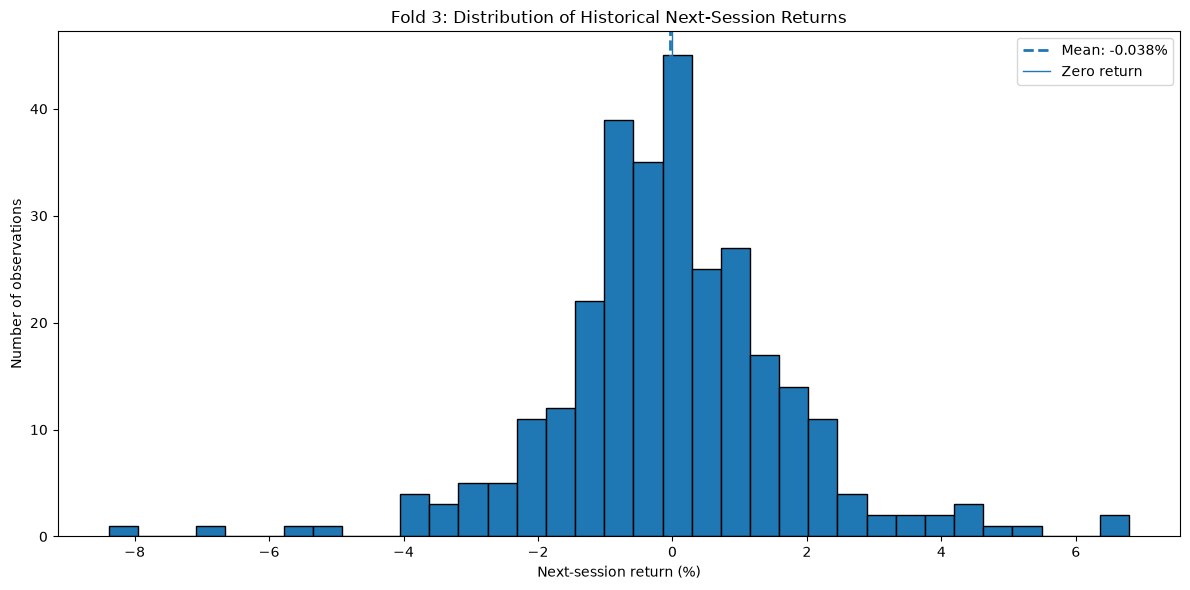

STEP 249 COMPLETED!


In [ ]:
# STEP 249: HISTORICAL RETURN DISTRIBUTION

import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(12, 6))

plt.hist(
    daily_returns,
    bins=35,
    edgecolor="black"
)

plt.axvline(
    daily_returns.mean(),
    linestyle="--",
    linewidth=2,
    label=f"Mean: {daily_returns.mean():.3f}%"
)

plt.axvline(
    0,
    linestyle="-",
    linewidth=1,
    label="Zero return"
)

plt.title("Fold 3: Distribution of Historical Next-Session Returns")
plt.xlabel("Next-session return (%)")
plt.ylabel("Number of observations")
plt.legend()
plt.tight_layout()
plt.show()

print("STEP 249 COMPLETED!")

In [ ]:
# STEP 250: HISTORICAL DOWNSIDE-RISK ANALYSIS

import numpy as np
import pandas as pd

risk_returns = pd.Series(daily_returns).dropna()

q05 = risk_returns.quantile(0.05)
q25 = risk_returns.quantile(0.25)
median_return = risk_returns.quantile(0.50)
q75 = risk_returns.quantile(0.75)
q95 = risk_returns.quantile(0.95)

negative_returns = risk_returns[risk_returns < 0]

downside_deviation = np.sqrt(
    np.mean(np.minimum(risk_returns.to_numpy(), 0) ** 2)
)

historical_var_95 = q05

tail_returns = risk_returns[risk_returns <= historical_var_95]
historical_cvar_95 = tail_returns.mean()

print("===== HISTORICAL DOWNSIDE-RISK REPORT =====")
print(f"5th percentile return (historical VaR threshold): {historical_var_95:.4f}%")
print(f"Average return in worst 5% tail (historical CVaR): {historical_cvar_95:.4f}%")
print(f"25th percentile return: {q25:.4f}%")
print(f"Median return: {median_return:.4f}%")
print(f"75th percentile return: {q75:.4f}%")
print(f"95th percentile return: {q95:.4f}%")
print(f"Downside deviation: {downside_deviation:.4f}%")
print(f"Negative-return observations: {len(negative_returns)} out of {len(risk_returns)}")

print("\nSTEP 250 COMPLETED!")

===== HISTORICAL DOWNSIDE-RISK REPORT =====
5th percentile return (historical VaR threshold): -2.7594%
Average return in worst 5% tail (historical CVaR): -4.2203%
25th percentile return: -0.8863%
Median return: -0.0829%
75th percentile return: 0.8910%
95th percentile return: 2.7447%
Downside deviation: 1.2826%
Negative-return observations: 159 out of 296

STEP 250 COMPLETED!


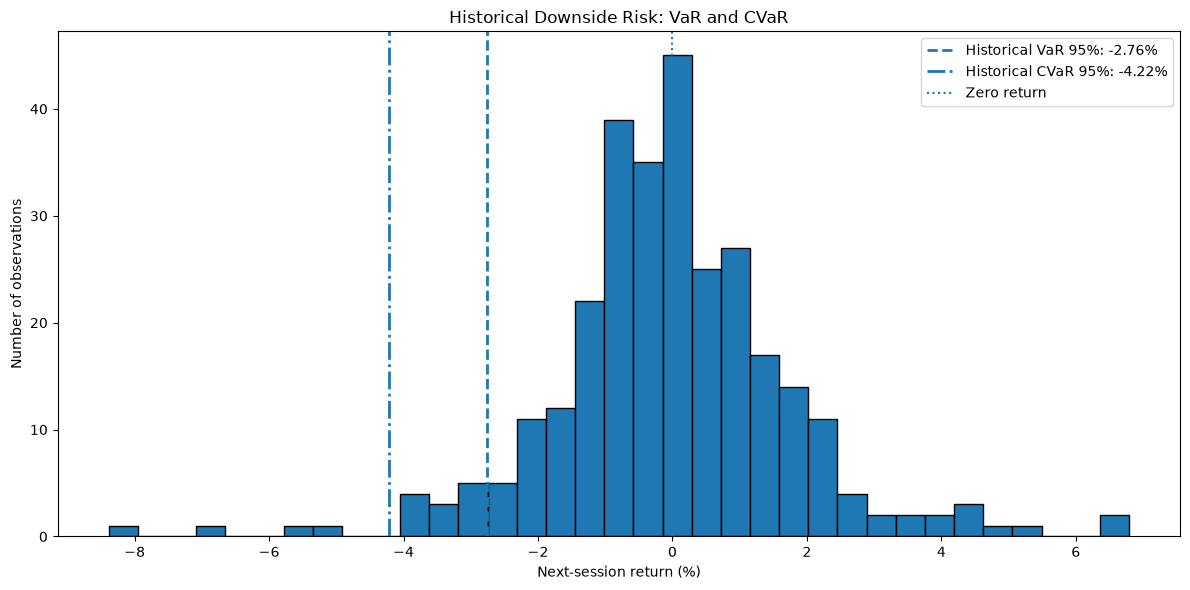

STEP 251 COMPLETED!


In [ ]:
# STEP 251: HISTORICAL VaR AUR CVaR VISUALIZATION

import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(12, 6))

plt.hist(
    risk_returns,
    bins=35,
    edgecolor="black"
)

plt.axvline(
    historical_var_95,
    linestyle="--",
    linewidth=2,
    label=f"Historical VaR 95%: {historical_var_95:.2f}%"
)

plt.axvline(
    historical_cvar_95,
    linestyle="-.",
    linewidth=2,
    label=f"Historical CVaR 95%: {historical_cvar_95:.2f}%"
)

plt.axvline(
    0,
    linestyle=":",
    linewidth=1.5,
    label="Zero return"
)

plt.title("Historical Downside Risk: VaR and CVaR")
plt.xlabel("Next-session return (%)")
plt.ylabel("Number of observations")
plt.legend()
plt.tight_layout()
plt.show()

print("STEP 251 COMPLETED!")

In [ ]:
# STEP 252: RISK METRICS SUMMARY TABLE

risk_summary_df = pd.DataFrame({
    "Metric": [
        "Average Return",
        "Daily Volatility",
        "Historical VaR (95%)",
        "Historical CVaR (95%)",
        "Downside Deviation",
        "Best Observed Return",
        "Worst Observed Return",
        "Positive-Return Days (%)",
        "Negative-Return Days (%)"
    ],
    "Value (%)": [
        risk_returns.mean(),
        risk_returns.std(),
        historical_var_95,
        historical_cvar_95,
        downside_deviation,
        risk_returns.max(),
        risk_returns.min(),
        (risk_returns > 0).mean() * 100,
        (risk_returns < 0).mean() * 100
    ]
})

print("===== STOCK VISSION AI: RISK SUMMARY =====")
print(risk_summary_df.round(4).to_string(index=False))

print("\nSTEP 252 COMPLETED!")

===== STOCK VISSION AI: RISK SUMMARY =====
                  Metric  Value (%)
          Average Return    -0.0384
        Daily Volatility     1.7971
    Historical VaR (95%)    -2.7594
   Historical CVaR (95%)    -4.2203
      Downside Deviation     1.2826
    Best Observed Return     6.7906
   Worst Observed Return    -8.3861
Positive-Return Days (%)    45.9459
Negative-Return Days (%)    53.7162

STEP 252 COMPLETED!


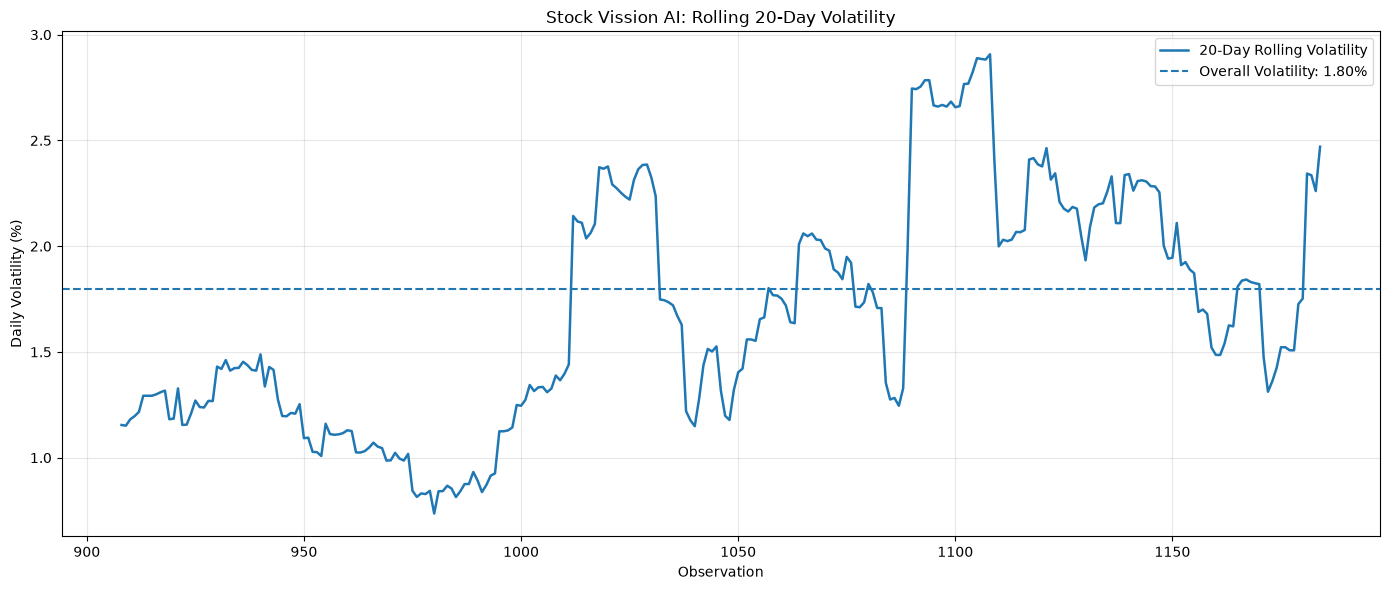

STEP 253 COMPLETED!
Average rolling volatility: 1.6765%
Maximum rolling volatility: 2.9073%
Minimum rolling volatility: 0.7359%


In [ ]:
# STEP 253: ROLLING 20-DAY VOLATILITY

import matplotlib.pyplot as plt
import pandas as pd

rolling_volatility = risk_returns.rolling(window=20).std()

plt.figure(figsize=(14, 6))

plt.plot(
    rolling_volatility.index,
    rolling_volatility,
    linewidth=1.8,
    label="20-Day Rolling Volatility"
)

plt.title("Stock Vission AI: Rolling 20-Day Volatility")
plt.xlabel("Observation")
plt.ylabel("Daily Volatility (%)")
plt.axhline(
    risk_returns.std(),
    linestyle="--",
    linewidth=1.5,
    label=f"Overall Volatility: {risk_returns.std():.2f}%"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("STEP 253 COMPLETED!")
print(f"Average rolling volatility: {rolling_volatility.mean():.4f}%")
print(f"Maximum rolling volatility: {rolling_volatility.max():.4f}%")
print(f"Minimum rolling volatility: {rolling_volatility.min():.4f}%")

In [ ]:
# STEP 254: TOP 10 HIGH-VOLATILITY PERIODS

rolling_volatility_df = pd.DataFrame({
    "Observation": rolling_volatility.index,
    "Rolling_Volatility_Pct": rolling_volatility.values
})

rolling_volatility_df = rolling_volatility_df.dropna()

top_10_volatility = (
    rolling_volatility_df
    .nlargest(10, "Rolling_Volatility_Pct")
    .sort_values("Rolling_Volatility_Pct", ascending=False)
    .reset_index(drop=True)
)

print("===== TOP 10 HIGH-VOLATILITY PERIODS =====")
print(top_10_volatility.round(4).to_string(index=False))

print("\nSTEP 254 COMPLETED!")

===== TOP 10 HIGH-VOLATILITY PERIODS =====
 Observation  Rolling_Volatility_Pct
        1108                  2.9073
        1105                  2.8890
        1106                  2.8852
        1107                  2.8825
        1104                  2.8234
        1094                  2.7848
        1093                  2.7845
        1103                  2.7687
        1102                  2.7667
        1092                  2.7546

STEP 254 COMPLETED!


===== TOP 10 HIGH-VOLATILITY DATES =====
            Rolling_Volatility_Pct
Date                              
2026-06-30                  2.9073
2026-06-24                  2.8890
2026-06-25                  2.8852
2026-06-29                  2.8825
2026-06-23                  2.8234
2026-06-09                  2.7848
2026-06-08                  2.7845
2026-06-22                  2.7687
2026-06-19                  2.7667
2026-06-05                  2.7546


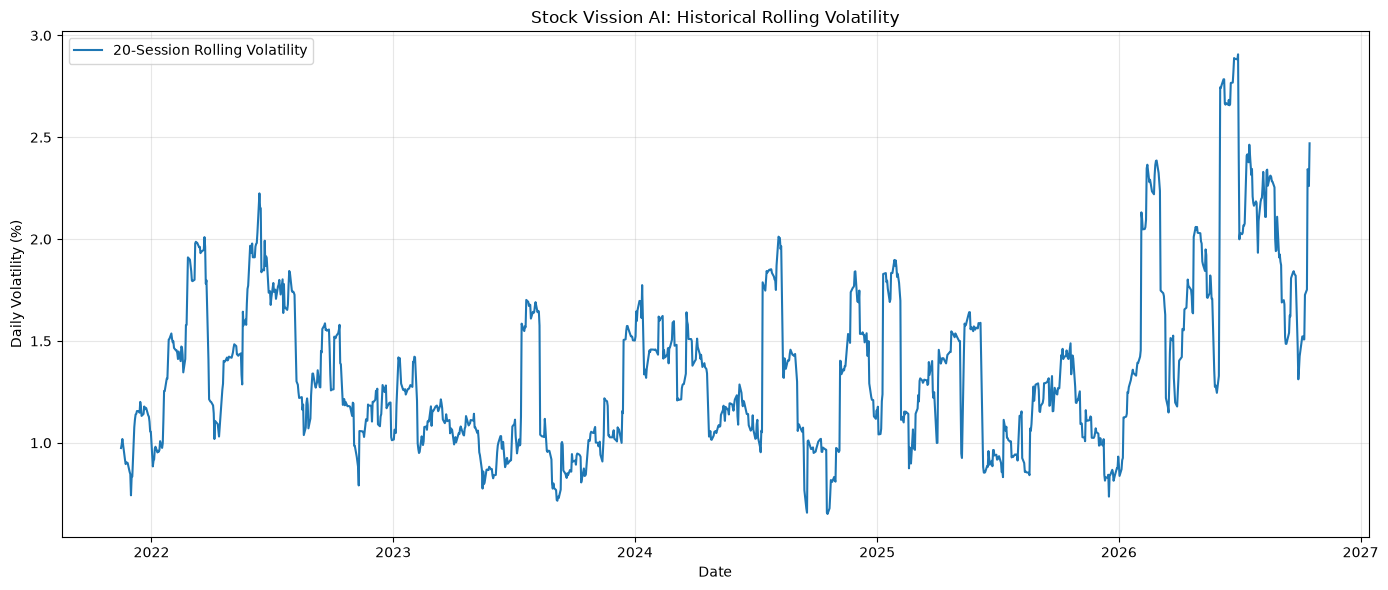


STEP 255 COMPLETED!


In [ ]:
# STEP 255: ROLLING VOLATILITY WITH ACTUAL DATES

import pandas as pd
import matplotlib.pyplot as plt

# Use the original market data and its actual date index
risk_returns_dated = df["Daily_Return"].dropna()

# Calculate rolling 20-session volatility
rolling_volatility_dated = risk_returns_dated.rolling(
    window=20
).std()

# Create a dated volatility table
volatility_dates_df = (
    rolling_volatility_dated
    .dropna()
    .rename("Rolling_Volatility_Pct")
    .to_frame()
)

# Display the 10 highest-volatility dates
top_10_volatility_dates = (
    volatility_dates_df
    .nlargest(10, "Rolling_Volatility_Pct")
)

print("===== TOP 10 HIGH-VOLATILITY DATES =====")
print(top_10_volatility_dates.round(4).to_string())

# Plot volatility against actual dates
plt.figure(figsize=(14, 6))

plt.plot(
    rolling_volatility_dated.index,
    rolling_volatility_dated.values,
    linewidth=1.5,
    label="20-Session Rolling Volatility"
)

plt.title("Stock Vission AI: Historical Rolling Volatility")
plt.xlabel("Date")
plt.ylabel("Daily Volatility (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nSTEP 255 COMPLETED!")

In [ ]:
# STEP 255A: CHECK AVAILABLE VARIABLES

required_names = [
    "risk_returns",
    "daily_returns",
    "test_data",
    "walk_forward_df",
    "clean_prediction_df",
    "prediction_df",
    "test_df",
    "market_test_df"
]

print("===== AVAILABLE PROJECT VARIABLES =====")

for name in required_names:
    if name in globals():
        obj = globals()[name]
        shape = getattr(obj, "shape", None)
        print(f"{name}: AVAILABLE | shape={shape}")
    else:
        print(f"{name}: NOT DEFINED")

print("\nSTEP 255A COMPLETED!")

===== AVAILABLE PROJECT VARIABLES =====
risk_returns: NOT DEFINED
daily_returns: NOT DEFINED
test_data: NOT DEFINED
walk_forward_df: NOT DEFINED
clean_prediction_df: NOT DEFINED
prediction_df: NOT DEFINED
test_df: NOT DEFINED
market_test_df: NOT DEFINED

STEP 255A COMPLETED!


In [ ]:
# STEP 255B: INSPECT CURRENT NOTEBOOK VARIABLES

import pandas as pd

print("===== CURRENT NOTEBOOK DATA VARIABLES =====")

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(f"DataFrame: {name} | Shape: {obj.shape}")
        print(f"Columns: {list(obj.columns)}")
        print("-" * 60)

    elif isinstance(obj, pd.Series):
        print(f"Series: {name} | Length: {len(obj)}")
        print("-" * 60)

print("\nSTEP 255B COMPLETED!")

===== CURRENT NOTEBOOK DATA VARIABLES =====
DataFrame: _ | Shape: (8, 5)
Columns: [('Close', 'TCS.NS'), ('High', 'TCS.NS'), ('Low', 'TCS.NS'), ('Open', 'TCS.NS'), ('Volume', 'TCS.NS')]
------------------------------------------------------------
DataFrame: __ | Shape: (5, 5)
Columns: [('Close', 'TCS.NS'), ('High', 'TCS.NS'), ('Low', 'TCS.NS'), ('Open', 'TCS.NS'), ('Volume', 'TCS.NS')]
------------------------------------------------------------
DataFrame: df | Shape: (1237, 10)
Columns: ['Close', 'High', 'Low', 'Open', 'Volume', 'Daily_Return', 'MA20', 'MA50', 'MA200', 'RSI_14']
------------------------------------------------------------
DataFrame: _7 | Shape: (5, 5)
Columns: [('Close', 'TCS.NS'), ('High', 'TCS.NS'), ('Low', 'TCS.NS'), ('Open', 'TCS.NS'), ('Volume', 'TCS.NS')]
------------------------------------------------------------
DataFrame: _9 | Shape: (8, 5)
Columns: [('Close', 'TCS.NS'), ('High', 'TCS.NS'), ('Low', 'TCS.NS'), ('Open', 'TCS.NS'), ('Volume', 'TCS.NS')]
--------

In [ ]:
# STEP 255C: CHECK RISK DATA AND DATE ALIGNMENT

print("===== ORIGINAL MARKET DATA =====")
print("df shape:", df.shape)
print("df index type:", type(df.index).__name__)
print("df index start:", df.index[0])
print("df index end:", df.index[-1])

print("\n===== DATE INFORMATION =====")
print("Date columns:", [
    col for col in df.columns
    if "date" in str(col).lower()
])

print("\n===== RECENT MARKET DATA =====")
print(df.tail(5).to_string())

print("\n===== RISK VARIABLES =====")
for name in [
    "historical_var_95",
    "historical_cvar_95",
    "downside_deviation",
    "rolling_volatility",
    "rolling_volatility_df",
    "top_10_volatility"
]:
    print(f"{name}: {'AVAILABLE' if name in globals() else 'NOT DEFINED'}")

print("\nSTEP 255C COMPLETED!")

===== ORIGINAL MARKET DATA =====
df shape: (1237, 10)
df index type: DatetimeIndex
df index start: 2021-10-18 00:00:00
df index end: 2026-10-16 00:00:00

===== DATE INFORMATION =====
Date columns: []

===== RECENT MARKET DATA =====
Price             Close         High          Low         Open    Volume  Daily_Return         MA20         MA50        MA200     RSI_14
Date                                                                                                                                    
2026-10-12  2113.763184  2183.492598  2109.684767  2173.346340   3540523     -1.437842  2104.228821  2236.198267  2437.829988  46.725656
2026-10-13  2257.300049  2257.300049  2143.604416  2145.494271  11048193      6.790584  2107.635706  2234.282451  2433.385425  61.562466
2026-10-14  2304.899902  2335.800049  2265.600098  2274.000000  12145767      2.108707  2110.925854  2231.168066  2428.973237  65.039631
2026-10-15  2350.000000  2386.699951  2335.000000  2347.199951   9150523      1.956

In [ ]:
# STEP 256: CLASSIFY VOLATILITY REGIMES

volatility_regime_df = rolling_volatility_dated.dropna().rename(
    "Rolling_Volatility_Pct"
).to_frame()

low_threshold = volatility_regime_df["Rolling_Volatility_Pct"].quantile(0.33)
high_threshold = volatility_regime_df["Rolling_Volatility_Pct"].quantile(0.67)

volatility_regime_df["Volatility_Regime"] = pd.cut(
    volatility_regime_df["Rolling_Volatility_Pct"],
    bins=[-float("inf"), low_threshold, high_threshold, float("inf")],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

print("===== VOLATILITY REGIME SUMMARY =====")
print(
    volatility_regime_df["Volatility_Regime"]
    .value_counts()
    .reindex(["Low", "Medium", "High"])
    .to_string()
)

print("\nVolatility thresholds:")
print(f"Low regime: up to {low_threshold:.4f}%")
print(f"Medium regime: {low_threshold:.4f}% to {high_threshold:.4f}%")
print(f"High regime: above {high_threshold:.4f}%")

print("\nSTEP 256 COMPLETED!")

===== VOLATILITY REGIME SUMMARY =====
Volatility_Regime
Low       402
Medium    413
High      402

Volatility thresholds:
Low regime: up to 1.1122%
Medium regime: 1.1122% to 1.4744%
High regime: above 1.4744%

STEP 256 COMPLETED!


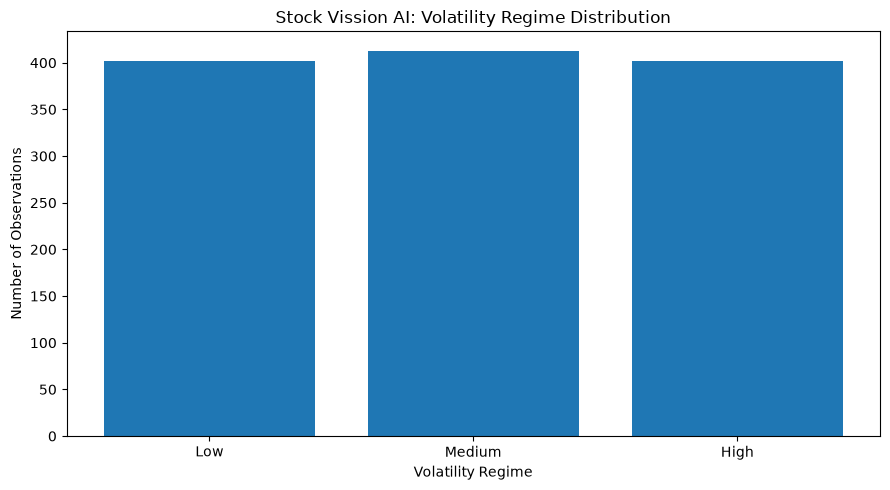

===== VOLATILITY REGIME PERCENTAGES =====
Volatility_Regime
Low       33.03%
Medium    33.94%
High      33.03%

STEP 257 COMPLETED!


In [ ]:
# STEP 257: VOLATILITY REGIME DISTRIBUTION CHART

import matplotlib.pyplot as plt

regime_counts = (
    volatility_regime_df["Volatility_Regime"]
    .value_counts()
    .reindex(["Low", "Medium", "High"])
)

plt.figure(figsize=(9, 5))

plt.bar(regime_counts.index, regime_counts.values)

plt.title("Stock Vission AI: Volatility Regime Distribution")
plt.xlabel("Volatility Regime")
plt.ylabel("Number of Observations")

plt.tight_layout()
plt.show()

print("===== VOLATILITY REGIME PERCENTAGES =====")
print(
    (regime_counts / regime_counts.sum() * 100)
    .round(2)
    .astype(str)
    .add("%")
    .to_string()
)

print("\nSTEP 257 COMPLETED!")

In [ ]:
# STEP 258: ANALYZE RETURNS BY VOLATILITY REGIME

regime_analysis_df = volatility_regime_df.join(
    df["Daily_Return"].rename("Daily_Return"),
    how="inner"
).dropna()

regime_summary = (
    regime_analysis_df
    .groupby("Volatility_Regime", observed=False)["Daily_Return"]
    .agg(
        Observations="count",
        Average_Return="mean",
        Return_Std="std",
        Best_Return="max",
        Worst_Return="min"
    )
    .reindex(["Low", "Medium", "High"])
)

regime_summary["Positive_Days_Pct"] = (
    regime_analysis_df
    .assign(Is_Positive=regime_analysis_df["Daily_Return"] > 0)
    .groupby("Volatility_Regime", observed=False)["Is_Positive"]
    .mean()
    .reindex(["Low", "Medium", "High"]) * 100
)

print("===== RETURNS BY VOLATILITY REGIME =====")
print(regime_summary.round(4).to_string())

print("\nSTEP 258 COMPLETED!")

===== RETURNS BY VOLATILITY REGIME =====
                   Observations  Average_Return  Return_Std  Best_Return  Worst_Return  Positive_Days_Pct
Volatility_Regime                                                                                        
Low                         402         -0.0287      0.9658       3.4408       -3.5400            48.5075
Medium                      413         -0.0020      1.3222       5.2350       -3.9730            48.4262
High                        402          0.0072      1.8980       6.7906       -8.3861            47.2637

STEP 258 COMPLETED!


In [ ]:
# STEP 258: ANALYZE RETURNS BY VOLATILITY REGIME

regime_analysis_df = volatility_regime_df.join(
    df["Daily_Return"].rename("Daily_Return"),
    how="inner"
).dropna()

regime_summary = (
    regime_analysis_df
    .groupby("Volatility_Regime", observed=False)["Daily_Return"]
    .agg(
        Observations="count",
        Average_Return="mean",
        Return_Std="std",
        Best_Return="max",
        Worst_Return="min"
    )
    .reindex(["Low", "Medium", "High"])
)

regime_summary["Positive_Days_Pct"] = (
    regime_analysis_df
    .assign(Is_Positive=regime_analysis_df["Daily_Return"] > 0)
    .groupby("Volatility_Regime", observed=False)["Is_Positive"]
    .mean()
    .reindex(["Low", "Medium", "High"]) * 100
)

print("===== RETURNS BY VOLATILITY REGIME =====")
print(regime_summary.round(4).to_string())

print("\nSTEP 258 COMPLETED!")

===== RETURNS BY VOLATILITY REGIME =====
                   Observations  Average_Return  Return_Std  Best_Return  Worst_Return  Positive_Days_Pct
Volatility_Regime                                                                                        
Low                         402         -0.0287      0.9658       3.4408       -3.5400            48.5075
Medium                      413         -0.0020      1.3222       5.2350       -3.9730            48.4262
High                        402          0.0072      1.8980       6.7906       -8.3861            47.2637

STEP 258 COMPLETED!


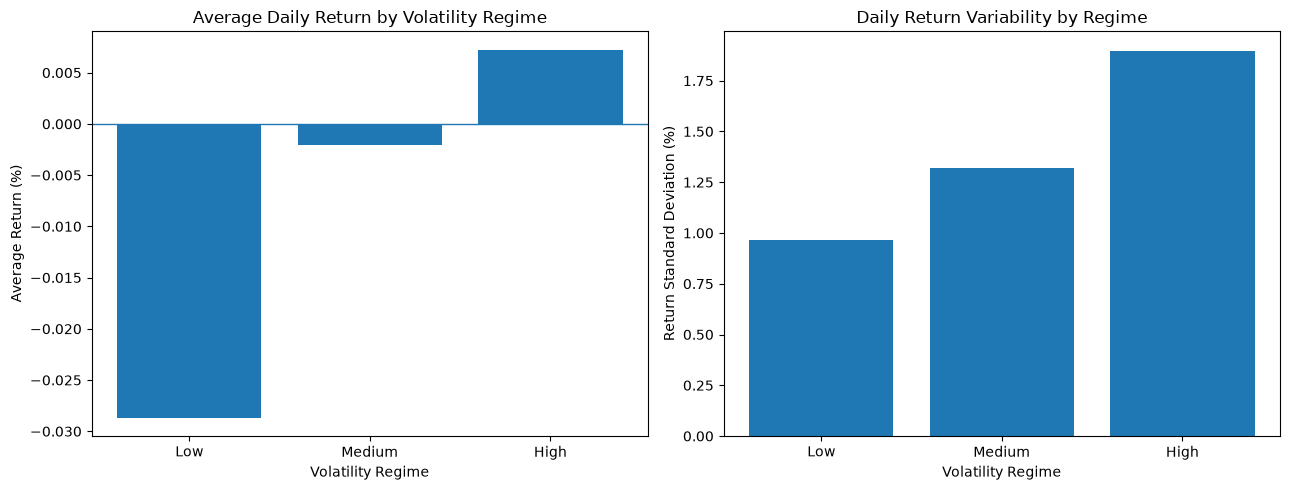

STEP 259 COMPLETED!


In [ ]:
# STEP 259: VISUALIZE RETURNS BY VOLATILITY REGIME

import matplotlib.pyplot as plt

regimes = ["Low", "Medium", "High"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Chart 1: Average daily return
axes[0].bar(
    regimes,
    regime_summary.loc[regimes, "Average_Return"]
)

axes[0].axhline(0, linewidth=1)
axes[0].set_title("Average Daily Return by Volatility Regime")
axes[0].set_xlabel("Volatility Regime")
axes[0].set_ylabel("Average Return (%)")

# Chart 2: Return variability
axes[1].bar(
    regimes,
    regime_summary.loc[regimes, "Return_Std"]
)

axes[1].set_title("Daily Return Variability by Regime")
axes[1].set_xlabel("Volatility Regime")
axes[1].set_ylabel("Return Standard Deviation (%)")

plt.tight_layout()
plt.show()

print("STEP 259 COMPLETED!")

In [ ]:
# STEP 260: IDENTIFY WORST MARKET DAYS

worst_market_days = (
    regime_analysis_df
    .sort_values("Daily_Return", ascending=True)
    .head(10)
    .copy()
)

worst_market_days["Market_Date"] = pd.to_datetime(
    worst_market_days.index
).strftime("%Y-%m-%d")

worst_market_days = worst_market_days.reset_index(drop=True)

worst_market_days = worst_market_days[
    [
        "Market_Date",
        "Daily_Return",
        "Rolling_Volatility_Pct",
        "Volatility_Regime"
    ]
].rename(
    columns={
        "Daily_Return": "Daily_Return_Pct"
    }
)

print("===== 10 WORST TCS MARKET DAYS =====")
print(worst_market_days.round(4).to_string(index=False))

print("\nSTEP 260 COMPLETED!")

===== 10 WORST TCS MARKET DAYS =====
Market_Date  Daily_Return_Pct  Rolling_Volatility_Pct Volatility_Regime
 2026-06-03           -8.3861                  2.7456              High
 2026-02-04           -7.0133                  2.1314              High
 2026-02-12           -5.4883                  2.3477              High
 2022-05-19           -5.4178                  1.6438              High
 2026-04-24           -4.9528                  2.0106              High
 2022-07-11           -4.6441                  1.7675              High
 2022-02-24           -4.5499                  1.7322              High
 2024-03-19           -4.2191                  1.6407              High
 2022-06-13           -4.1757                  2.2245              High
 2025-04-03           -3.9730                  1.3186            Medium

STEP 260 COMPLETED!


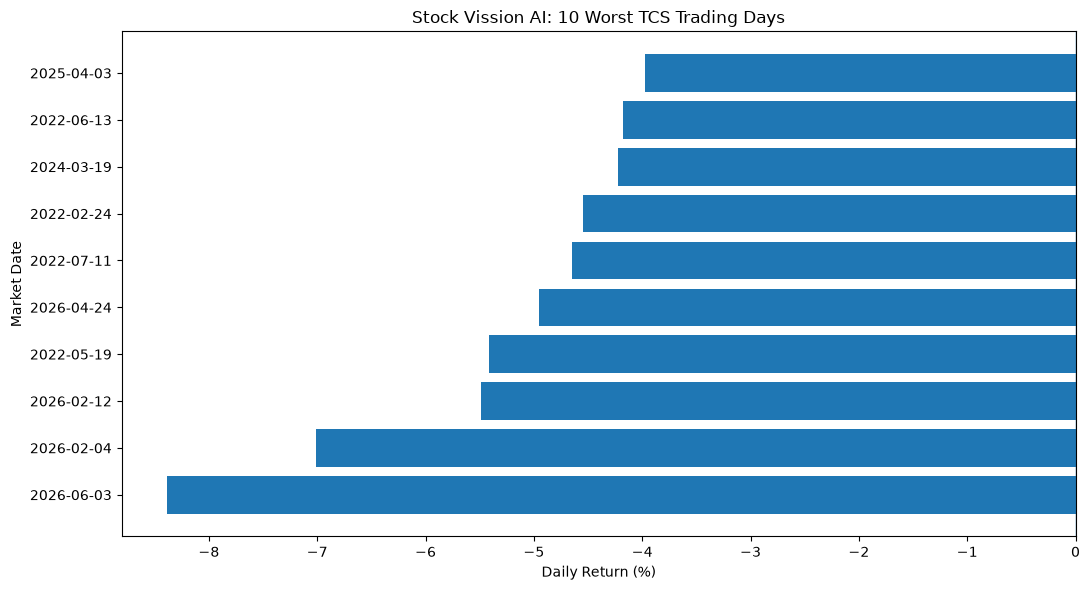

STEP 261 COMPLETED!


In [ ]:
# STEP 261: VISUALIZE THE 10 WORST MARKET DAYS

import matplotlib.pyplot as plt

plot_df = worst_market_days.sort_values(
    "Daily_Return_Pct",
    ascending=True
)

plt.figure(figsize=(11, 6))

plt.barh(
    plot_df["Market_Date"],
    plot_df["Daily_Return_Pct"]
)

plt.axvline(0, linewidth=1)
plt.title("Stock Vission AI: 10 Worst TCS Trading Days")
plt.xlabel("Daily Return (%)")
plt.ylabel("Market Date")

plt.tight_layout()
plt.show()

print("STEP 261 COMPLETED!")

In [ ]:
# STEP 262: EXPORT HISTORICAL RISK ANALYSIS

import os

output_dir = "project_outputs"
os.makedirs(output_dir, exist_ok=True)

worst_market_days.to_csv(
    os.path.join(output_dir, "tcs_worst_market_days.csv"),
    index=False
)

regime_summary.to_csv(
    os.path.join(output_dir, "tcs_volatility_regime_summary.csv")
)

print("===== RISK ANALYSIS EXPORT =====")
print("Worst market days: tcs_worst_market_days.csv")
print("Volatility summary: tcs_volatility_regime_summary.csv")
print(f"Output folder: {os.path.abspath(output_dir)}")
print("\nSTEP 262 COMPLETED!")

===== RISK ANALYSIS EXPORT =====
Worst market days: tcs_worst_market_days.csv
Volatility summary: tcs_volatility_regime_summary.csv
Output folder: d:\PROJECT\Stock_Vission_Project\project_outputs

STEP 262 COMPLETED!


In [ ]:
# STEP 263: CREATE COMBINED RISK DASHBOARD DATASET

risk_dashboard_df = regime_analysis_df.copy()

risk_dashboard_df.index = pd.to_datetime(risk_dashboard_df.index)
risk_dashboard_df.index.name = "Market_Date"

risk_dashboard_df = risk_dashboard_df.reset_index()

risk_dashboard_df.to_csv(
    os.path.join(output_dir, "tcs_risk_dashboard_data.csv"),
    index=False
)

print("===== RISK DASHBOARD DATASET =====")
print(f"Total observations: {len(risk_dashboard_df)}")
print(f"Date range: {risk_dashboard_df['Market_Date'].min().date()} to "
      f"{risk_dashboard_df['Market_Date'].max().date()}")
print("\nColumns:")
print(risk_dashboard_df.columns.tolist())
print("\nSaved: tcs_risk_dashboard_data.csv")
print("\nSTEP 263 COMPLETED!")

===== RISK DASHBOARD DATASET =====
Total observations: 1217
Date range: 2021-11-16 to 2026-10-16

Columns:
['Market_Date', 'Rolling_Volatility_Pct', 'Volatility_Regime', 'Daily_Return']

Saved: tcs_risk_dashboard_data.csv

STEP 263 COMPLETED!


In [ ]:
# STEP 264: CREATE RISK METRICS SUMMARY

risk_returns = risk_dashboard_df["Daily_Return"].dropna()

risk_metrics = {
    "Total Observations": len(risk_returns),
    "Average Daily Return (%)": risk_returns.mean(),
    "Daily Return Volatility (%)": risk_returns.std(),
    "Best Daily Return (%)": risk_returns.max(),
    "Worst Daily Return (%)": risk_returns.min(),
    "Positive Days (%)": (risk_returns > 0).mean() * 100,
    "Negative Days (%)": (risk_returns < 0).mean() * 100
}

risk_metrics_df = pd.DataFrame(
    list(risk_metrics.items()),
    columns=["Metric", "Value"]
)

print("===== HISTORICAL RISK METRICS =====")
print(risk_metrics_df.round(4).to_string(index=False))

risk_metrics_df.to_csv(
    os.path.join(output_dir, "tcs_risk_metrics_summary.csv"),
    index=False
)

print("\nSaved: tcs_risk_metrics_summary.csv")
print("\nSTEP 264 COMPLETED!")

===== HISTORICAL RISK METRICS =====
                     Metric     Value
         Total Observations 1217.0000
   Average Daily Return (%)   -0.0078
Daily Return Volatility (%)    1.4451
      Best Daily Return (%)    6.7906
     Worst Daily Return (%)   -8.3861
          Positive Days (%)   48.0690
          Negative Days (%)   51.7666

Saved: tcs_risk_metrics_summary.csv

STEP 264 COMPLETED!


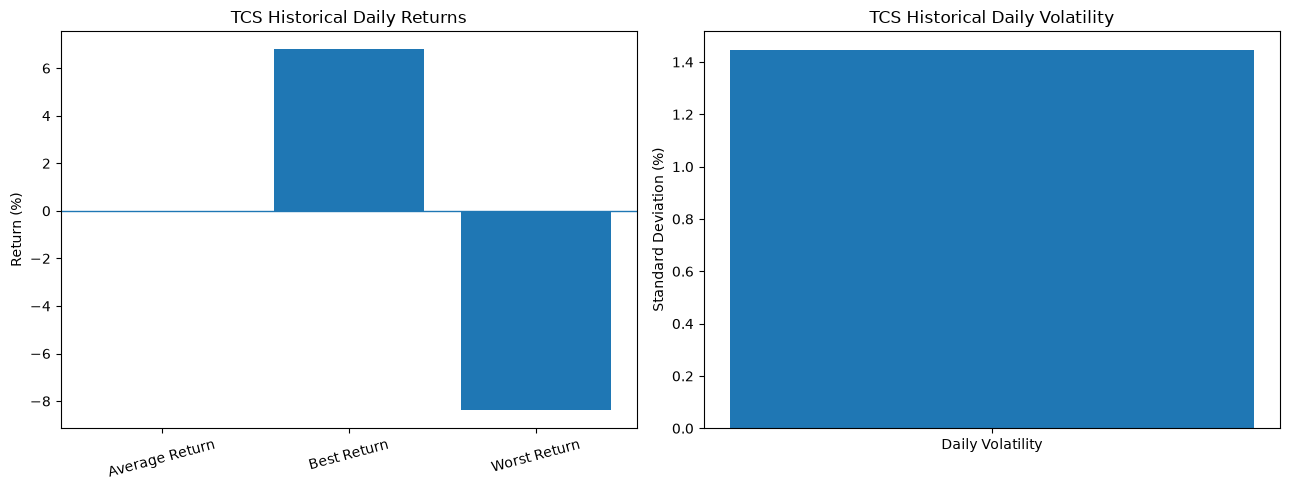

STEP 265 COMPLETED!


In [ ]:
# STEP 265: VISUALIZE HISTORICAL RISK METRICS

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Average, best and worst daily returns
return_labels = ["Average Return", "Best Return", "Worst Return"]
return_values = [
    risk_returns.mean(),
    risk_returns.max(),
    risk_returns.min()
]

axes[0].bar(return_labels, return_values)
axes[0].axhline(0, linewidth=1)
axes[0].set_title("TCS Historical Daily Returns")
axes[0].set_ylabel("Return (%)")
axes[0].tick_params(axis="x", rotation=15)

# Daily return volatility
axes[1].bar(
    ["Daily Volatility"],
    [risk_returns.std()]
)
axes[1].set_title("TCS Historical Daily Volatility")
axes[1].set_ylabel("Standard Deviation (%)")

plt.tight_layout()
plt.show()

print("STEP 265 COMPLETED!")

In [ ]:
# STEP 266: CALCULATE HISTORICAL MAXIMUM DRAWDOWN

drawdown_df = df[["Close"]].dropna().copy()
drawdown_df = drawdown_df.sort_index()

drawdown_df["Running_Peak"] = drawdown_df["Close"].cummax()

drawdown_df["Drawdown_Pct"] = (
    (drawdown_df["Close"] / drawdown_df["Running_Peak"]) - 1
) * 100

maximum_drawdown = drawdown_df["Drawdown_Pct"].min()
worst_drawdown_date = drawdown_df["Drawdown_Pct"].idxmin()

print("===== TCS HISTORICAL DRAWDOWN ANALYSIS =====")
print(f"Maximum Drawdown: {maximum_drawdown:.2f}%")
print(f"Date of Maximum Drawdown: {worst_drawdown_date.date()}")

print("\nSTEP 266 COMPLETED!")

===== TCS HISTORICAL DRAWDOWN ANALYSIS =====
Maximum Drawdown: -53.39%
Date of Maximum Drawdown: 2026-07-01

STEP 266 COMPLETED!


===== MAXIMUM DRAWDOWN VERIFICATION =====
Worst drawdown date: 2026-07-01
Closing price: 1961.36
Running peak: 4208.34
Maximum drawdown: -53.39%

===== CLOSE PRICE DATA CHECK =====
count    1237.00
mean     3109.73
std       479.06
min      1961.36
25%      2872.47
50%      3072.72
75%      3375.24
max      4208.34
Name: Close, dtype: float64

Lowest 5 closing prices:
Price             Close
Date                   
2026-07-01  1961.362061
2026-06-30  2009.738281
2026-09-29  2021.652832
2026-07-09  2027.545410
2026-07-08  2035.459717


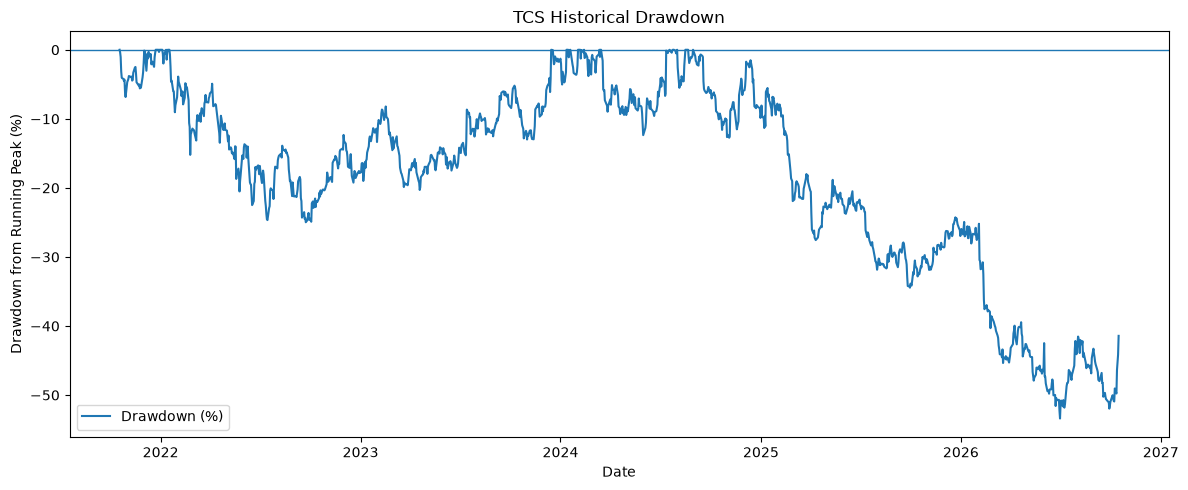


STEP 267 COMPLETED!


In [ ]:
# STEP 267: VERIFY AND VISUALIZE MAXIMUM DRAWDOWN

import matplotlib.pyplot as plt

drawdown_df = df[["Close"]].dropna().copy()
drawdown_df = drawdown_df.sort_index()

drawdown_df["Running_Peak"] = drawdown_df["Close"].cummax()
drawdown_df["Drawdown_Pct"] = (
    drawdown_df["Close"] / drawdown_df["Running_Peak"] - 1
) * 100

worst_date = drawdown_df["Drawdown_Pct"].idxmin()
worst_row = drawdown_df.loc[worst_date]

print("===== MAXIMUM DRAWDOWN VERIFICATION =====")
print(f"Worst drawdown date: {worst_date.date()}")
print(f"Closing price: {worst_row['Close']:.2f}")
print(f"Running peak: {worst_row['Running_Peak']:.2f}")
print(f"Maximum drawdown: {worst_row['Drawdown_Pct']:.2f}%")

print("\n===== CLOSE PRICE DATA CHECK =====")
print(drawdown_df["Close"].describe().round(2))
print("\nLowest 5 closing prices:")
print(drawdown_df.nsmallest(5, "Close")[["Close"]].to_string())

plt.figure(figsize=(12, 5))
plt.plot(
    drawdown_df.index,
    drawdown_df["Drawdown_Pct"],
    label="Drawdown (%)"
)
plt.axhline(0, linewidth=1)
plt.title("TCS Historical Drawdown")
plt.xlabel("Date")
plt.ylabel("Drawdown from Running Peak (%)")
plt.legend()
plt.tight_layout()
plt.show()

print("\nSTEP 267 COMPLETED!")

In [ ]:
# STEP 268: INVESTIGATE LARGE PRICE CHANGES

price_check_df = df[["Close"]].dropna().copy()
price_check_df = price_check_df.sort_index()

price_check_df["Close_Change_Pct"] = (
    price_check_df["Close"].pct_change() * 100
)

large_moves_df = price_check_df[
    price_check_df["Close_Change_Pct"].abs() > 10
].copy()

print("===== DAILY PRICE CHANGES ABOVE 10% =====")

if large_moves_df.empty:
    print("No daily closing-price changes above 10% found.")
else:
    print(large_moves_df.round(2).to_string())

print("\n===== CLOSE PRICES: JUNE–JULY 2026 =====")

june_july_df = price_check_df.loc[
    "2026-06-15":"2026-07-15"
]

print(june_july_df.round(2).to_string())

print("\nSTEP 268 COMPLETED!")

===== DAILY PRICE CHANGES ABOVE 10% =====
No daily closing-price changes above 10% found.

===== CLOSE PRICES: JUNE–JULY 2026 =====
Price         Close  Close_Change_Pct
Date                                 
2026-06-15  2138.84              0.03
2026-06-16  2175.44              1.71
2026-06-17  2199.19              1.09
2026-06-18  2179.70             -0.89
2026-06-19  2102.24             -3.55
2026-06-22  2105.01              0.13
2026-06-23  2037.54             -3.21
2026-06-24  2086.41              2.40
2026-06-25  2072.26             -0.68
2026-06-29  2075.43              0.15
2026-06-30  2009.74             -3.17
2026-07-01  1961.36             -2.41
2026-07-02  2045.95              4.31
2026-07-03  2071.07              1.23
2026-07-06  2035.56             -1.71
2026-07-07  2073.65              1.87
2026-07-08  2035.46             -1.84
2026-07-09  2027.55             -0.39
2026-07-10  2046.84              0.95
2026-07-13  2158.13              5.44
2026-07-14  2177.03             

In [ ]:
# STEP 269: VERIFY HISTORICAL PEAK DATE

price_history_df = df[["Close"]].dropna().copy()
price_history_df = price_history_df.sort_index()

peak_date = price_history_df["Close"].idxmax()
peak_price = price_history_df["Close"].max()

trough_date = price_history_df["Close"].idxmin()
trough_price = price_history_df["Close"].min()

print("===== HISTORICAL PRICE EXTREMES =====")
print(f"Maximum closing price: ₹{peak_price:.2f}")
print(f"Peak date: {peak_date.date()}")
print(f"Minimum closing price: ₹{trough_price:.2f}")
print(f"Minimum-price date: {trough_date.date()}")

print("\n===== PRICES AROUND THE PEAK =====")

peak_window_df = price_history_df.loc[
    peak_date - pd.Timedelta(days=5):
    peak_date + pd.Timedelta(days=5)
]

print(peak_window_df.to_string())

print("\n===== PRICE HISTORY AROUND JULY 2026 =====")

july_window_df = price_history_df.loc[
    "2026-06-25":"2026-07-10"
]

print(july_window_df.to_string())

print("\nSTEP 269 COMPLETED!")

===== HISTORICAL PRICE EXTREMES =====
Maximum closing price: ₹4208.34
Peak date: 2024-08-30
Minimum closing price: ₹1961.36
Minimum-price date: 2026-07-01

===== PRICES AROUND THE PEAK =====
Price             Close
Date                   
2024-08-26  4160.929688
2024-08-27  4156.031738
2024-08-28  4164.255859
2024-08-29  4169.570801
2024-08-30  4208.337891
2024-09-02  4178.118652
2024-09-03  4170.078613
2024-09-04  4139.489258

===== PRICE HISTORY AROUND JULY 2026 =====
Price             Close
Date                   
2026-06-25  2072.260986
2026-06-29  2075.426758
2026-06-30  2009.738281
2026-07-01  1961.362061
2026-07-02  2045.946411
2026-07-03  2071.073975
2026-07-06  2035.558716
2026-07-07  2073.646240
2026-07-08  2035.459717
2026-07-09  2027.545410
2026-07-10  2046.836426

STEP 269 COMPLETED!


In [ ]:
# STEP 270: CHECK YEAR-WISE PRICE CONSISTENCY

price_consistency_df = df[["Open", "High", "Low", "Close"]].dropna().copy()

price_consistency_df.index = pd.to_datetime(price_consistency_df.index)
price_consistency_df = price_consistency_df.sort_index()

yearly_price_summary = (
    price_consistency_df
    .groupby(price_consistency_df.index.year)
    .agg(
        First_Close=("Close", "first"),
        Average_Close=("Close", "mean"),
        Highest_Price=("High", "max"),
        Lowest_Price=("Low", "min"),
        Last_Close=("Close", "last")
    )
)

yearly_price_summary["Yearly_Change_Pct"] = (
    yearly_price_summary["Last_Close"]
    .div(yearly_price_summary["First_Close"])
    .sub(1)
    .mul(100)
)

print("===== YEAR-WISE TCS PRICE SUMMARY =====")
print(yearly_price_summary.round(2).to_string())

print("\nSTEP 270 COMPLETED!")

===== YEAR-WISE TCS PRICE SUMMARY =====
      First_Close  Average_Close  Highest_Price  Lowest_Price  Last_Close  Yearly_Change_Pct
Date                                                                                        
2021      3157.57        3080.61        3255.27       2931.43     3236.52               2.50
2022      3305.27        2962.75        3500.28       2561.60     2858.39             -13.52
2023      2862.56        3058.77        3571.54       2756.00     3448.28              20.46
2024      3464.37        3767.98        4243.92       3311.39     3793.43               9.50
2025      3809.78        3215.12        4004.79       2737.79     3073.55             -19.32
2026      3093.87        2407.18        3269.78       1955.62     2465.00             -20.33

STEP 270 COMPLETED!


In [ ]:
# STEP 271: VERIFY OHLC DATA QUALITY

ohlc_check_df = df[["Open", "High", "Low", "Close"]].dropna().copy()
ohlc_check_df = ohlc_check_df.sort_index()

invalid_ohlc = ohlc_check_df[
    (ohlc_check_df["High"] < ohlc_check_df[["Open", "Close", "Low"]].max(axis=1))
    | (ohlc_check_df["Low"] > ohlc_check_df[["Open", "Close", "High"]].min(axis=1))
]

print("===== OHLC DATA QUALITY CHECK =====")
print(f"Total OHLC rows: {len(ohlc_check_df)}")
print(f"Invalid OHLC rows: {len(invalid_ohlc)}")

if not invalid_ohlc.empty:
    print("\nInvalid rows:")
    print(invalid_ohlc.head(10).to_string())

print("\n===== LATEST 10 OHLC ROWS =====")
print(ohlc_check_df.tail(10).round(2).to_string())

print("\nSTEP 271 COMPLETED!")

===== OHLC DATA QUALITY CHECK =====
Total OHLC rows: 1237
Invalid OHLC rows: 0

===== LATEST 10 OHLC ROWS =====
Price          Open     High      Low    Close
Date                                          
2026-10-05  2102.82  2129.58  2052.69  2103.22
2026-10-06  2085.91  2103.82  2071.69  2088.90
2026-10-07  2074.17  2093.87  2065.02  2069.30
2026-10-08  2092.87  2130.18  2049.11  2065.02
2026-10-09  2074.97  2192.35  2074.97  2144.60
2026-10-12  2173.35  2183.49  2109.68  2113.76
2026-10-13  2145.49  2257.30  2143.60  2257.30
2026-10-14  2274.00  2335.80  2265.60  2304.90
2026-10-15  2347.20  2386.70  2335.00  2350.00
2026-10-16  2382.00  2484.70  2375.70  2465.00

STEP 271 COMPLETED!


In [ ]:
# STEP 272: VERIFY ADJUSTED CLOSE DATA

import yfinance as yf
import pandas as pd

ticker = yf.Ticker("TCS.NS")

source_history = ticker.history(
    period="5y",
    auto_adjust=False,
    actions=True
)

print("===== SOURCE DATA COLUMNS =====")
print(source_history.columns.tolist())

if "Adj Close" in source_history.columns:
    adjustment_df = source_history[["Close", "Adj Close"]].dropna().copy()

    adjustment_df["Adjustment_Difference"] = (
        adjustment_df["Adj Close"] - adjustment_df["Close"]
    )

    adjustment_df["Adjustment_Difference_Pct"] = (
        adjustment_df["Adj Close"] / adjustment_df["Close"] - 1
    ) * 100

    print("\n===== LATEST CLOSE VS ADJUSTED CLOSE =====")
    print(adjustment_df.tail(10).round(4).to_string())

    print("\n===== ADJUSTMENT SUMMARY =====")
    print(
        adjustment_df[
            ["Adjustment_Difference_Pct"]
        ].describe().round(4).to_string()
    )
else:
    print("Adj Close column is unavailable in the returned data.")

action_columns = [
    column for column in ["Dividends", "Stock Splits"]
    if column in source_history.columns
]

print("\n===== CORPORATE ACTIONS =====")
if action_columns:
    actions_df = source_history[action_columns]
    actions_df = actions_df.loc[(actions_df != 0).any(axis=1)]
    print(actions_df.tail(20).to_string())
else:
    print("Corporate-action columns are unavailable.")

print("\nSTEP 272 COMPLETED!")

===== SOURCE DATA COLUMNS =====
['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'Dividends', 'Stock Splits']

===== LATEST CLOSE VS ADJUSTED CLOSE =====
                               Close  Adj Close  Adjustment_Difference  Adjustment_Difference_Pct
Date                                                                                             
2026-10-05 00:00:00+05:30  2114.3999  2103.2190               -11.1809                    -0.5288
2026-10-06 00:00:00+05:30  2100.0000  2088.8953               -11.1047                    -0.5288
2026-10-07 00:00:00+05:30  2080.3000  2069.2996               -11.0005                    -0.5288
2026-10-08 00:00:00+05:30  2076.0000  2065.0222               -10.9778                    -0.5288
2026-10-09 00:00:00+05:30  2156.0000  2144.5991               -11.4009                    -0.5288
2026-10-12 00:00:00+05:30  2125.0000  2113.7632               -11.2368                    -0.5288
2026-10-13 00:00:00+05:30  2269.3000  2257.3000        

In [ ]:
# STEP 273: CHECK CORPORATE ACTIONS AND ADJUSTMENT CHANGES

action_check_df = source_history[
    ["Close", "Adj Close", "Dividends", "Stock Splits"]
].copy()

action_check_df["Adjustment_Factor"] = (
    action_check_df["Adj Close"] / action_check_df["Close"]
)

action_check_df["Factor_Change_Pct"] = (
    action_check_df["Adjustment_Factor"].pct_change() * 100
)

corporate_actions_df = action_check_df[
    (action_check_df["Dividends"] != 0)
    | (action_check_df["Stock Splits"] != 0)
].copy()

factor_changes_df = action_check_df[
    action_check_df["Factor_Change_Pct"].abs() > 0.01
].copy()

print("===== NON-ZERO CORPORATE ACTIONS =====")
if corporate_actions_df.empty:
    print("No non-zero corporate actions found.")
else:
    print(corporate_actions_df.round(4).to_string())

print("\n===== ADJUSTMENT FACTOR CHANGES =====")
if factor_changes_df.empty:
    print("No significant adjustment-factor changes found.")
else:
    print(factor_changes_df.round(4).to_string())

print("\n===== ADJUSTMENT FACTOR SUMMARY =====")
print(action_check_df["Adjustment_Factor"].describe().round(5).to_string())

print("\nSTEP 273 COMPLETED!")

===== NON-ZERO CORPORATE ACTIONS =====
                               Close  Adj Close  Dividends  Stock Splits  Adjustment_Factor  Factor_Change_Pct
Date                                                                                                          
2022-01-19 00:00:00+05:30  3914.6499  3395.1140        7.0           0.0             0.8673             0.1757
2022-05-25 00:00:00+05:30  3167.6499  2765.7588       22.0           0.0             0.8731             0.6736
2022-07-14 00:00:00+05:30  2998.7500  2625.1985        8.0           0.0             0.8754             0.2640
2022-10-17 00:00:00+05:30  3111.7500  2731.1726        8.0           0.0             0.8777             0.2588
2023-01-16 00:00:00+05:30  3334.0500  2992.8000       75.0           0.0             0.8976             2.2730
2023-06-15 00:00:00+05:30  3216.3000  2908.5737       24.0           0.0             0.9043             0.7437
2023-07-20 00:00:00+05:30  3463.3000  3140.0862        9.0           0.0 

In [ ]:
# STEP 274: COMPARE CLOSE AND ADJUSTED CLOSE DRAWDOWN

def calculate_drawdown(price_series):
    prices = price_series.dropna().sort_index()
    running_peak = prices.cummax()
    drawdown_pct = (prices / running_peak - 1) * 100

    return drawdown_pct, drawdown_pct.idxmin(), drawdown_pct.min()

close_dd, close_dd_date, close_max_dd = calculate_drawdown(
    source_history["Close"]
)

adj_close_dd, adj_dd_date, adj_max_dd = calculate_drawdown(
    source_history["Adj Close"]
)

drawdown_comparison_df = pd.DataFrame({
    "Price_Type": ["Close", "Adjusted Close"],
    "Maximum_Drawdown_Pct": [close_max_dd, adj_max_dd],
    "Worst_Drawdown_Date": [close_dd_date, adj_dd_date]
})

print("===== MAXIMUM DRAWDOWN COMPARISON =====")
print(drawdown_comparison_df.round(2).to_string(index=False))

print("\n===== CLOSE DRAWDOWN DETAILS =====")
print(f"Worst drawdown date: {close_dd_date}")
print(f"Maximum drawdown: {close_max_dd:.2f}%")

print("\n===== ADJUSTED CLOSE DRAWDOWN DETAILS =====")
print(f"Worst drawdown date: {adj_dd_date}")
print(f"Maximum drawdown: {adj_max_dd:.2f}%")

print("\nSTEP 274 COMPLETED!")

===== MAXIMUM DRAWDOWN COMPARISON =====
    Price_Type  Maximum_Drawdown_Pct       Worst_Drawdown_Date
         Close                -56.46 2026-07-01 00:00:00+05:30
Adjusted Close                -53.39 2026-07-01 00:00:00+05:30

===== CLOSE DRAWDOWN DETAILS =====
Worst drawdown date: 2026-07-01 00:00:00+05:30
Maximum drawdown: -56.46%

===== ADJUSTED CLOSE DRAWDOWN DETAILS =====
Worst drawdown date: 2026-07-01 00:00:00+05:30
Maximum drawdown: -53.39%

STEP 274 COMPLETED!


C:\Users\Hp Victus\AppData\Local\Temp\ipykernel_29620\2880863966.py:25: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(drawdown_comparison_df.round(2).to_string(index=False))


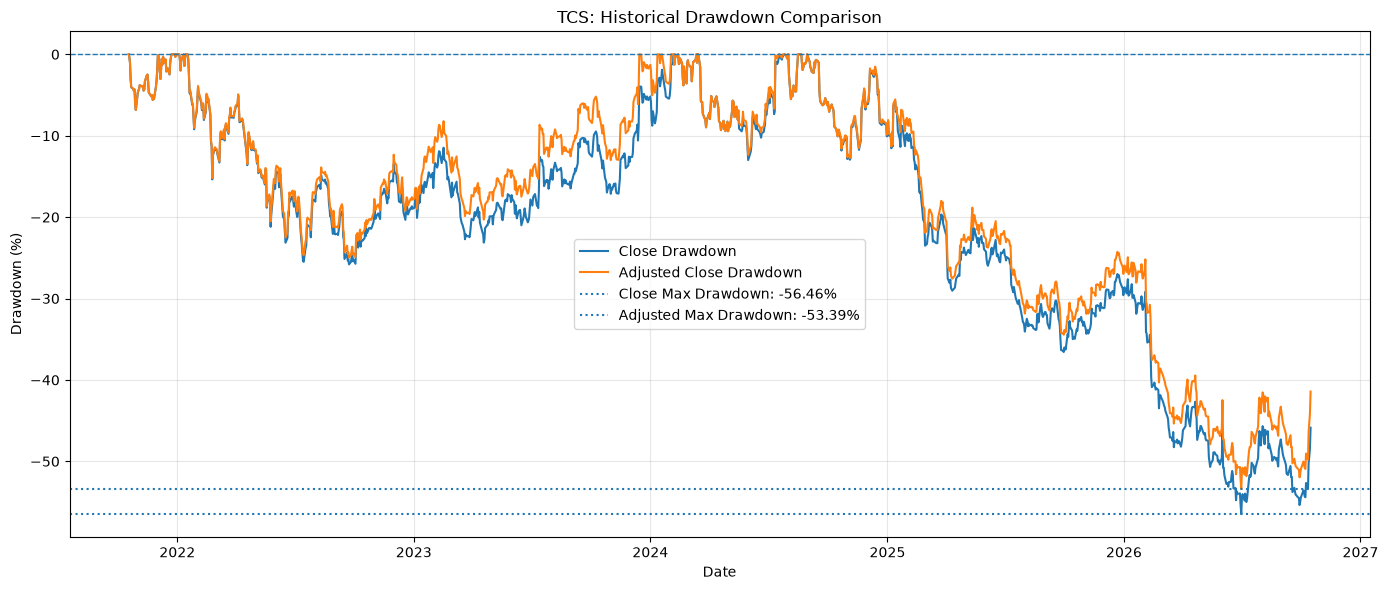

STEP 275 COMPLETED!


In [ ]:
# STEP 275: PLOT CLOSE VS ADJUSTED CLOSE DRAWDOWN

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    close_dd.index,
    close_dd,
    label="Close Drawdown",
    linewidth=1.5
)

plt.plot(
    adj_close_dd.index,
    adj_close_dd,
    label="Adjusted Close Drawdown",
    linewidth=1.5
)

plt.axhline(0, linestyle="--", linewidth=1)
plt.axhline(
    close_max_dd,
    linestyle=":",
    linewidth=1.5,
    label=f"Close Max Drawdown: {close_max_dd:.2f}%"
)
plt.axhline(
    adj_max_dd,
    linestyle=":",
    linewidth=1.5,
    label=f"Adjusted Max Drawdown: {adj_max_dd:.2f}%"
)

plt.title("TCS: Historical Drawdown Comparison")
plt.xlabel("Date")
plt.ylabel("Drawdown (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("STEP 275 COMPLETED!")

In [ ]:
# STEP 276: VERIFY MAXIMUM DRAWDOWN PEAK AND TROUGH

def get_drawdown_details(price_series):
    prices = price_series.dropna().sort_index()
    running_peak = prices.cummax()
    drawdown = (prices / running_peak - 1) * 100

    trough_date = drawdown.idxmin()
    peak_price = running_peak.loc[trough_date]
    trough_price = prices.loc[trough_date]

    peak_candidates = prices.loc[:trough_date]
    peak_date = peak_candidates[peak_candidates == peak_price].index[-1]

    return {
        "Peak_Date": peak_date,
        "Peak_Price": peak_price,
        "Trough_Date": trough_date,
        "Trough_Price": trough_price,
        "Maximum_Drawdown_Pct": drawdown.loc[trough_date]
    }

close_details = get_drawdown_details(source_history["Close"])
adjusted_details = get_drawdown_details(source_history["Adj Close"])

print("===== CLOSE DRAWDOWN DETAILS =====")
for key, value in close_details.items():
    print(f"{key}: {value:.2f}" if isinstance(value, float) else f"{key}: {value}")

print("\n===== ADJUSTED CLOSE DRAWDOWN DETAILS =====")
for key, value in adjusted_details.items():
    print(f"{key}: {value:.2f}" if isinstance(value, float) else f"{key}: {value}")

print("\nSTEP 276 COMPLETED!")

===== CLOSE DRAWDOWN DETAILS =====
Peak_Date: 2024-08-30 00:00:00+05:30
Peak_Price: 4553.75
Trough_Date: 2026-07-01 00:00:00+05:30
Trough_Price: 1982.60
Maximum_Drawdown_Pct: -56.46

===== ADJUSTED CLOSE DRAWDOWN DETAILS =====
Peak_Date: 2024-08-30 00:00:00+05:30
Peak_Price: 4208.34
Trough_Date: 2026-07-01 00:00:00+05:30
Trough_Price: 1961.36
Maximum_Drawdown_Pct: -53.39

STEP 276 COMPLETED!


In [ ]:
# STEP 277: SAVE VERIFIED DRAWDOWN COMPARISON

import os
import pandas as pd

os.makedirs("project_outputs", exist_ok=True)

drawdown_report_df = pd.DataFrame([
    {
        "Price_Type": "Raw Close",
        "Peak_Date": close_details["Peak_Date"],
        "Peak_Price": close_details["Peak_Price"],
        "Trough_Date": close_details["Trough_Date"],
        "Trough_Price": close_details["Trough_Price"],
        "Maximum_Drawdown_Pct": close_details["Maximum_Drawdown_Pct"]
    },
    {
        "Price_Type": "Adjusted Close",
        "Peak_Date": adjusted_details["Peak_Date"],
        "Peak_Price": adjusted_details["Peak_Price"],
        "Trough_Date": adjusted_details["Trough_Date"],
        "Trough_Price": adjusted_details["Trough_Price"],
        "Maximum_Drawdown_Pct": adjusted_details["Maximum_Drawdown_Pct"]
    }
])

report_path = "project_outputs/tcs_drawdown_comparison.csv"
drawdown_report_df.to_csv(report_path, index=False)

print("===== VERIFIED DRAWDOWN REPORT =====")
print(drawdown_report_df.round(2).to_string(index=False))

print(f"\nSaved report: {os.path.abspath(report_path)}")
print("\nSTEP 277 COMPLETED!")

===== VERIFIED DRAWDOWN REPORT =====
    Price_Type                 Peak_Date  Peak_Price               Trough_Date  Trough_Price  Maximum_Drawdown_Pct
     Raw Close 2024-08-30 00:00:00+05:30     4553.75 2026-07-01 00:00:00+05:30       1982.60                -56.46
Adjusted Close 2024-08-30 00:00:00+05:30     4208.34 2026-07-01 00:00:00+05:30       1961.36                -53.39

Saved report: d:\PROJECT\Stock_Vission_Project\project_outputs\tcs_drawdown_comparison.csv

STEP 277 COMPLETED!


C:\Users\Hp Victus\AppData\Local\Temp\ipykernel_29620\10348700.py:31: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(drawdown_report_df.round(2).to_string(index=False))


In [ ]:
# STEP 278: ANALYZE DRAWDOWN RECOVERY

def analyze_recovery(price_series):
    prices = price_series.dropna().sort_index()

    running_peak = prices.cummax()
    drawdown = (prices / running_peak - 1) * 100

    trough_date = drawdown.idxmin()
    trough_price = prices.loc[trough_date]

    # Peak immediately preceding the maximum drawdown trough
    peak_price = running_peak.loc[trough_date]
    peak_candidates = prices.loc[:trough_date]
    peak_date = peak_candidates[peak_candidates == peak_price].index[-1]

    # Check whether price recovered to the previous peak after the trough
    prices_after_trough = prices.loc[prices.index > trough_date]
    recovered = prices_after_trough[prices_after_trough >= peak_price]

    recovery_date = recovered.index[0] if not recovered.empty else None

    if recovery_date is not None:
        trading_sessions = len(
            prices.loc[(prices.index > trough_date) &
                       (prices.index <= recovery_date)]
        )
        recovery_status = "Recovered"
    else:
        trading_sessions = len(prices_after_trough)
        recovery_status = "Not yet recovered in available data"

    return {
        "Peak_Date": peak_date,
        "Peak_Price": peak_price,
        "Trough_Date": trough_date,
        "Trough_Price": trough_price,
        "Maximum_Drawdown_Pct": drawdown.loc[trough_date],
        "Recovery_Status": recovery_status,
        "Recovery_Date": recovery_date,
        "Sessions_After_Trough": trading_sessions
    }


recovery_result = analyze_recovery(source_history["Adj Close"])

print("===== TCS DRAWDOWN RECOVERY ANALYSIS =====")

for key, value in recovery_result.items():
    if isinstance(value, float):
        print(f"{key}: {value:.2f}")
    else:
        print(f"{key}: {value}")

print("\nSTEP 278 COMPLETED!")

===== TCS DRAWDOWN RECOVERY ANALYSIS =====
Peak_Date: 2024-08-30 00:00:00+05:30
Peak_Price: 4208.34
Trough_Date: 2026-07-01 00:00:00+05:30
Trough_Price: 1961.36
Maximum_Drawdown_Pct: -53.39
Recovery_Status: Not yet recovered in available data
Recovery_Date: None
Sessions_After_Trough: 75

STEP 278 COMPLETED!


In [ ]:
# STEP 279: CALCULATE RECOVERY PROGRESS

adjusted_prices = source_history["Adj Close"].dropna().sort_index()

latest_date = adjusted_prices.index[-1]
latest_price = adjusted_prices.iloc[-1]

previous_peak = recovery_result["Peak_Price"]
trough_price = recovery_result["Trough_Price"]

decline_from_peak_pct = (latest_price / previous_peak - 1) * 100
gain_needed_to_peak_pct = (previous_peak / latest_price - 1) * 100

rebound_from_trough_pct = (latest_price / trough_price - 1) * 100

print("===== TCS RECOVERY PROGRESS =====")
print(f"Latest date: {latest_date}")
print(f"Latest adjusted close: ₹{latest_price:.2f}")
print(f"Previous peak: ₹{previous_peak:.2f}")
print(f"Trough price: ₹{trough_price:.2f}")

print(f"\nDecline from previous peak: {decline_from_peak_pct:.2f}%")
print(f"Gain needed to return to peak: {gain_needed_to_peak_pct:.2f}%")
print(f"Rebound from trough: {rebound_from_trough_pct:.2f}%")

print("\nSTEP 279 COMPLETED!")

===== TCS RECOVERY PROGRESS =====
Latest date: 2026-10-16 00:00:00+05:30
Latest adjusted close: ₹2465.00
Previous peak: ₹4208.34
Trough price: ₹1961.36

Decline from previous peak: -41.43%
Gain needed to return to peak: 70.72%
Rebound from trough: 25.68%

STEP 279 COMPLETED!


In [ ]:
# STEP 280: SAVE RECOVERY SUMMARY REPORT

import os
import pandas as pd

os.makedirs("project_outputs", exist_ok=True)

recovery_summary_df = pd.DataFrame([{
    "Latest_Date": latest_date,
    "Latest_Adjusted_Close": latest_price,
    "Previous_Peak_Date": recovery_result["Peak_Date"],
    "Previous_Peak_Price": previous_peak,
    "Trough_Date": recovery_result["Trough_Date"],
    "Trough_Price": trough_price,
    "Maximum_Drawdown_Pct": recovery_result["Maximum_Drawdown_Pct"],
    "Decline_From_Peak_Pct": decline_from_peak_pct,
    "Rebound_From_Trough_Pct": rebound_from_trough_pct,
    "Gain_Needed_To_Reach_Peak_Pct": gain_needed_to_peak_pct,
    "Recovery_Status": recovery_result["Recovery_Status"],
    "Sessions_After_Trough": recovery_result["Sessions_After_Trough"]
}])

recovery_report_path = "project_outputs/tcs_recovery_summary.csv"

recovery_summary_df.to_csv(recovery_report_path, index=False)

print("===== TCS RECOVERY SUMMARY =====")
print(recovery_summary_df.to_string(index=False))

print(f"\nSaved report: {os.path.abspath(recovery_report_path)}")
print("\nSTEP 280 COMPLETED!")

===== TCS RECOVERY SUMMARY =====
              Latest_Date  Latest_Adjusted_Close        Previous_Peak_Date  Previous_Peak_Price               Trough_Date  Trough_Price  Maximum_Drawdown_Pct  Decline_From_Peak_Pct  Rebound_From_Trough_Pct  Gain_Needed_To_Reach_Peak_Pct                     Recovery_Status  Sessions_After_Trough
2026-10-16 00:00:00+05:30                 2465.0 2024-08-30 00:00:00+05:30          4208.338867 2026-07-01 00:00:00+05:30   1961.362061            -53.393438              -41.42582                25.677969                      70.723686 Not yet recovered in available data                     75

Saved report: d:\PROJECT\Stock_Vission_Project\project_outputs\tcs_recovery_summary.csv

STEP 280 COMPLETED!


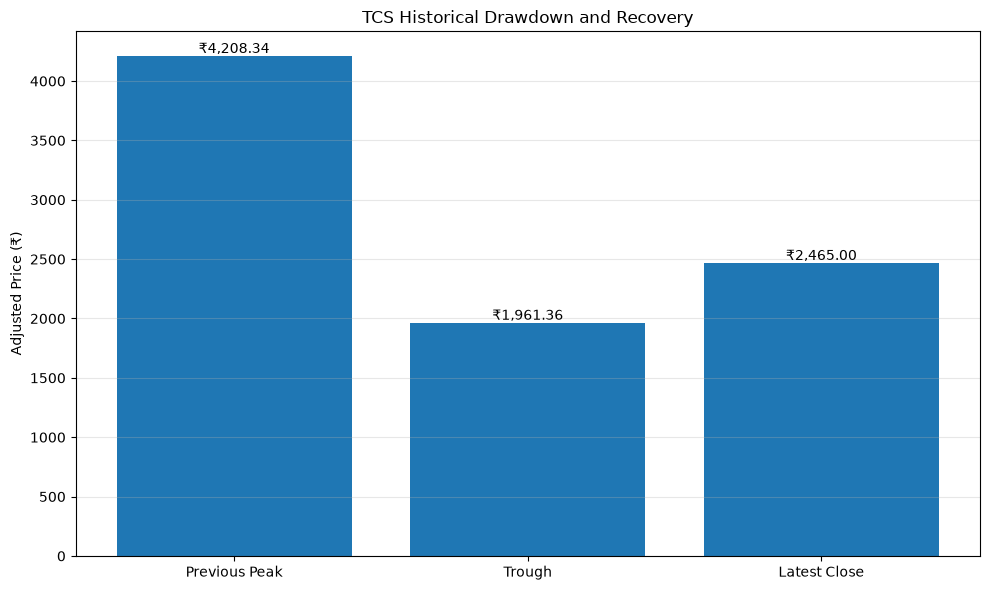

STEP 281 COMPLETED!


In [ ]:
# STEP 281: VISUALIZE TCS RECOVERY PROGRESS

import matplotlib.pyplot as plt

price_labels = ["Previous Peak", "Trough", "Latest Close"]
price_values = [
    previous_peak,
    trough_price,
    latest_price
]

plt.figure(figsize=(10, 6))

bars = plt.bar(price_labels, price_values)

plt.title("TCS Historical Drawdown and Recovery")
plt.ylabel("Adjusted Price (₹)")
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, price_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"₹{value:,.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

print("STEP 281 COMPLETED!")

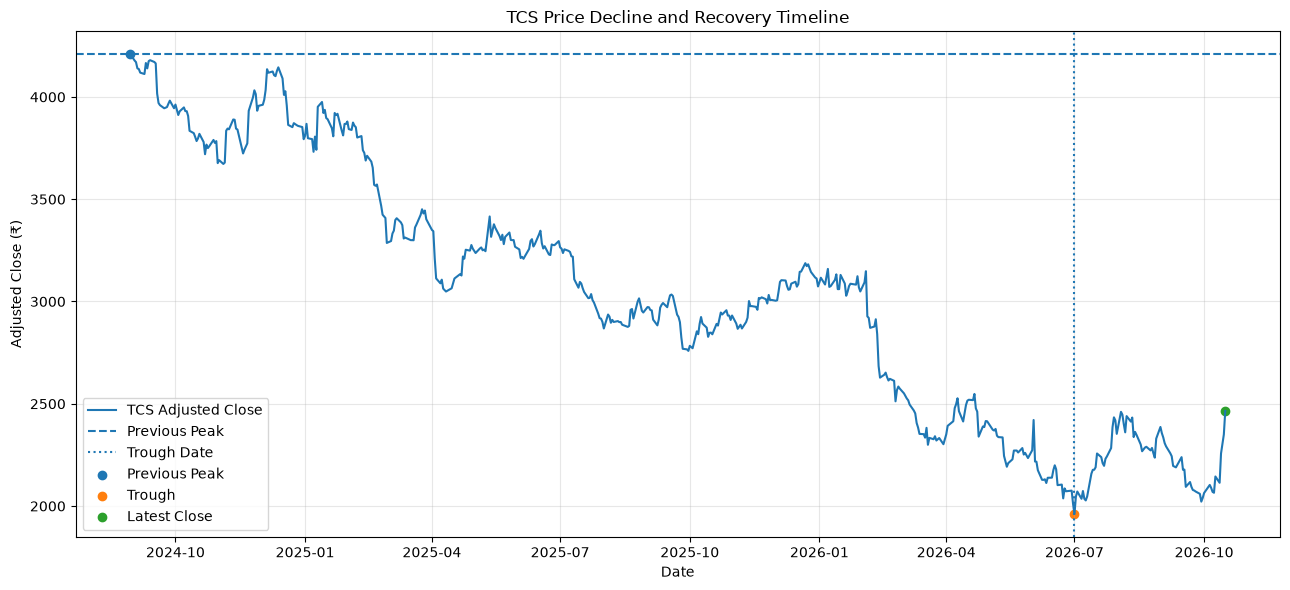

Timeline start: 2024-08-30 00:00:00+05:30
Timeline end: 2026-10-16 00:00:00+05:30
STEP 282 COMPLETED!


In [ ]:
# STEP 282: PLOT FULL TCS RECOVERY TIMELINE

import matplotlib.pyplot as plt

adjusted_prices = source_history["Adj Close"].dropna().sort_index()

peak_date = pd.Timestamp(recovery_result["Peak_Date"])
trough_date = pd.Timestamp(recovery_result["Trough_Date"])

timeline_prices = adjusted_prices.loc[peak_date:]

plt.figure(figsize=(13, 6))

plt.plot(
    timeline_prices.index,
    timeline_prices.values,
    label="TCS Adjusted Close"
)

plt.axhline(
    previous_peak,
    linestyle="--",
    label="Previous Peak"
)

plt.axvline(
    trough_date,
    linestyle=":",
    label="Trough Date"
)

plt.scatter(
    [peak_date],
    [previous_peak],
    label="Previous Peak"
)

plt.scatter(
    [trough_date],
    [trough_price],
    label="Trough"
)

plt.scatter(
    [timeline_prices.index[-1]],
    [timeline_prices.iloc[-1]],
    label="Latest Close"
)

plt.title("TCS Price Decline and Recovery Timeline")
plt.xlabel("Date")
plt.ylabel("Adjusted Close (₹)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Timeline start:", timeline_prices.index[0])
print("Timeline end:", timeline_prices.index[-1])
print("STEP 282 COMPLETED!")

In [ ]:
# STEP 283: CALCULATE RECOVERY MILESTONES

recovery_amount = previous_peak - trough_price

milestone_percentages = [25, 50, 75, 100]

milestone_rows = []

for percentage in milestone_percentages:
    milestone_price = trough_price + (
        recovery_amount * percentage / 100
    )

    distance_from_latest = milestone_price - latest_price

    milestone_rows.append({
        "Recovery_Milestone_Pct": percentage,
        "Milestone_Price": round(milestone_price, 2),
        "Latest_Adjusted_Close": round(latest_price, 2),
        "Distance_From_Latest": round(distance_from_latest, 2)
    })

recovery_milestones_df = pd.DataFrame(milestone_rows)

print("===== TCS RECOVERY MILESTONES =====")
print(recovery_milestones_df.to_string(index=False))

recovery_milestones_df.to_csv(
    "project_outputs/tcs_recovery_milestones.csv",
    index=False
)

print("\nSaved: project_outputs/tcs_recovery_milestones.csv")
print("\nSTEP 283 COMPLETED!")


===== TCS RECOVERY MILESTONES =====
 Recovery_Milestone_Pct  Milestone_Price  Latest_Adjusted_Close  Distance_From_Latest
                     25          2523.11                 2465.0                 58.11
                     50          3084.85                 2465.0                619.85
                     75          3646.59                 2465.0               1181.59
                    100          4208.34                 2465.0               1743.34

Saved: project_outputs/tcs_recovery_milestones.csv

STEP 283 COMPLETED!


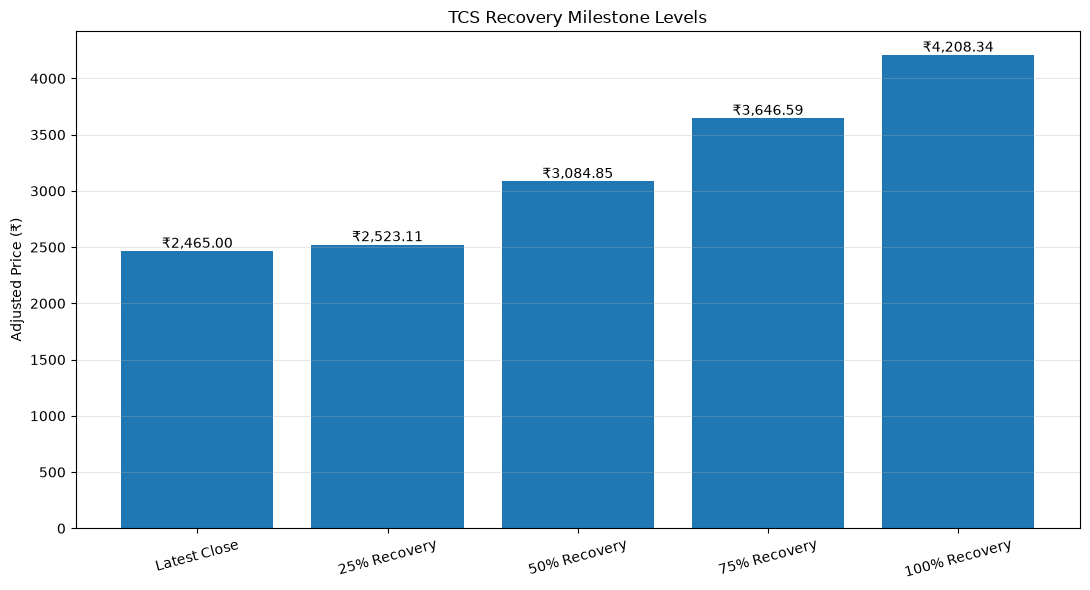

STEP 284 COMPLETED!


In [ ]:
# STEP 284: PLOT RECOVERY MILESTONES

import matplotlib.pyplot as plt

plot_labels = ["Latest Close"] + [
    f"{p}% Recovery" for p in milestone_percentages
]

plot_values = [latest_price] + [
    row["Milestone_Price"] for row in milestone_rows
]

plt.figure(figsize=(11, 6))

bars = plt.bar(plot_labels, plot_values)

plt.title("TCS Recovery Milestone Levels")
plt.ylabel("Adjusted Price (₹)")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, plot_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"₹{value:,.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

print("STEP 284 COMPLETED!")

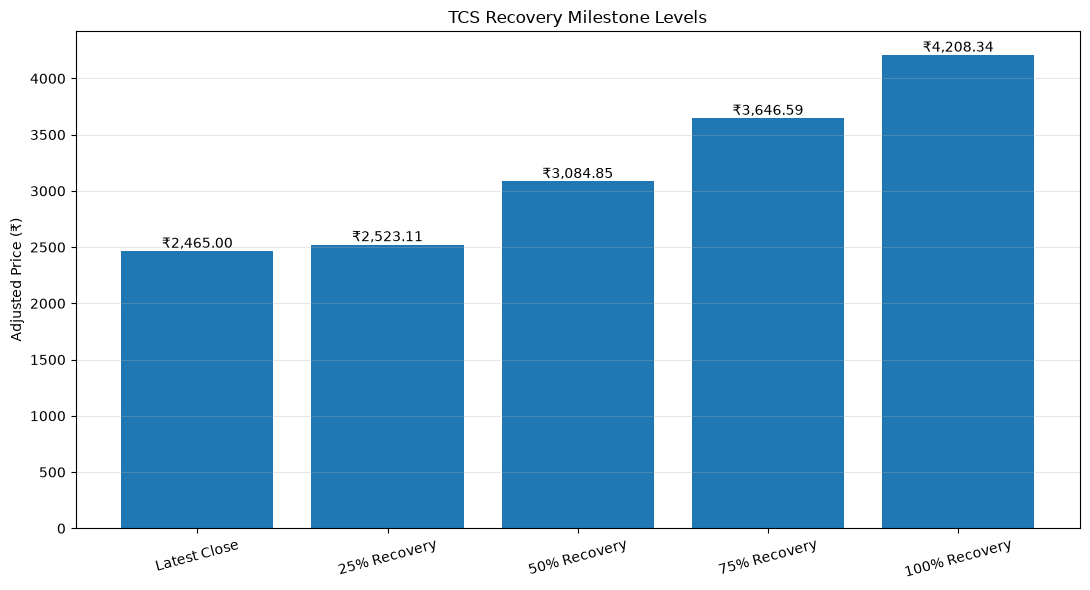

Chart saved successfully!
File path: d:\PROJECT\Stock_Vission_Project\project_outputs\tcs_recovery_milestones.png

STEP 285 COMPLETED!


In [ ]:
# STEP 285: SAVE RECOVERY MILESTONE CHART

import os
import matplotlib.pyplot as plt

os.makedirs("project_outputs", exist_ok=True)

plot_labels = ["Latest Close"] + [
    f"{p}% Recovery" for p in milestone_percentages
]

plot_values = [latest_price] + [
    row["Milestone_Price"] for row in milestone_rows
]

plt.figure(figsize=(11, 6))

bars = plt.bar(plot_labels, plot_values)

plt.title("TCS Recovery Milestone Levels")
plt.ylabel("Adjusted Price (₹)")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, plot_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"₹{value:,.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

chart_path = "project_outputs/tcs_recovery_milestones.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")

plt.show()

print("Chart saved successfully!")
print("File path:", os.path.abspath(chart_path))
print("\nSTEP 285 COMPLETED!")

In [ ]:
# STEP 286: VERIFY PROJECT OUTPUT FILES

import os

output_folder = "project_outputs"

print("===== PROJECT OUTPUT FILES =====")

if os.path.exists(output_folder):
    output_files = sorted(os.listdir(output_folder))

    for file_name in output_files:
        file_path = os.path.join(output_folder, file_name)

        if os.path.isfile(file_path):
            size_kb = os.path.getsize(file_path) / 1024
            print(f"{file_name}  |  {size_kb:.2f} KB")

    print(f"\nTotal files found: {len(output_files)}")
else:
    print("Output folder does not exist.")

print("\nSTEP 286 COMPLETED!")

===== PROJECT OUTPUT FILES =====
tcs_drawdown_comparison.csv  |  0.30 KB
tcs_recovery_milestones.csv  |  0.18 KB
tcs_recovery_milestones.png  |  132.01 KB
tcs_recovery_summary.csv  |  0.46 KB
tcs_risk_dashboard_data.csv  |  66.21 KB
tcs_risk_metrics_summary.csv  |  0.29 KB
tcs_volatility_regime_summary.csv  |  0.41 KB
tcs_worst_market_days.csv  |  0.61 KB

Total files found: 8

STEP 286 COMPLETED!


In [ ]:
# STEP 287: CREATE MASTER RISK REPORT

import os
import pandas as pd

output_folder = "project_outputs"

drawdown_df = pd.read_csv(
    os.path.join(output_folder, "tcs_drawdown_comparison.csv")
)

recovery_df = pd.read_csv(
    os.path.join(output_folder, "tcs_recovery_summary.csv")
)

risk_df = pd.read_csv(
    os.path.join(output_folder, "tcs_risk_metrics_summary.csv")
)

print("===== DRAW DOWN REPORT =====")
print(drawdown_df.to_string(index=False))

print("\n===== RECOVERY REPORT =====")
print(recovery_df.to_string(index=False))

print("\n===== RISK METRICS REPORT =====")
print(risk_df.to_string(index=False))

print("\nSTEP 287 COMPLETED!")

===== DRAW DOWN REPORT =====
    Price_Type                 Peak_Date  Peak_Price               Trough_Date  Trough_Price  Maximum_Drawdown_Pct
     Raw Close 2024-08-30 00:00:00+05:30 4553.750000 2026-07-01 00:00:00+05:30   1982.599976            -56.462257
Adjusted Close 2024-08-30 00:00:00+05:30 4208.338867 2026-07-01 00:00:00+05:30   1961.362061            -53.393438

===== RECOVERY REPORT =====
              Latest_Date  Latest_Adjusted_Close        Previous_Peak_Date  Previous_Peak_Price               Trough_Date  Trough_Price  Maximum_Drawdown_Pct  Decline_From_Peak_Pct  Rebound_From_Trough_Pct  Gain_Needed_To_Reach_Peak_Pct                     Recovery_Status  Sessions_After_Trough
2026-10-16 00:00:00+05:30                 2465.0 2024-08-30 00:00:00+05:30          4208.338867 2026-07-01 00:00:00+05:30   1961.362061            -53.393438              -41.42582                25.677969                      70.723686 Not yet recovered in available data                     75

====

In [ ]:
# STEP 288: CREATE MASTER RISK REPORT

import os
import pandas as pd

output_folder = "project_outputs"

# Load the existing reports
drawdown_df = pd.read_csv(
    os.path.join(output_folder, "tcs_drawdown_comparison.csv")
)

recovery_df = pd.read_csv(
    os.path.join(output_folder, "tcs_recovery_summary.csv")
)

risk_df = pd.read_csv(
    os.path.join(output_folder, "tcs_risk_metrics_summary.csv")
)

# Convert the risk metrics table into a dictionary
risk_metrics = dict(zip(risk_df["Metric"], risk_df["Value"]))

# Select the adjusted-price drawdown row
adjusted_drawdown = drawdown_df.loc[
    drawdown_df["Price_Type"] == "Adjusted Close"
].iloc[0]

# Build one consolidated summary
master_risk_report = pd.DataFrame([{
    "Latest_Date": recovery_df.loc[0, "Latest_Date"],
    "Latest_Adjusted_Close": recovery_df.loc[0, "Latest_Adjusted_Close"],
    "Peak_Date": adjusted_drawdown["Peak_Date"],
    "Peak_Price": adjusted_drawdown["Peak_Price"],
    "Trough_Date": adjusted_drawdown["Trough_Date"],
    "Trough_Price": adjusted_drawdown["Trough_Price"],
    "Maximum_Drawdown_Pct": adjusted_drawdown["Maximum_Drawdown_Pct"],
    "Rebound_From_Trough_Pct": recovery_df.loc[0, "Rebound_From_Trough_Pct"],
    "Gain_Needed_To_Reach_Peak_Pct": recovery_df.loc[0, "Gain_Needed_To_Reach_Peak_Pct"],
    "Recovery_Status": recovery_df.loc[0, "Recovery_Status"],
    "Total_Observations": risk_metrics["Total Observations"],
    "Average_Daily_Return_Pct": risk_metrics["Average Daily Return (%)"],
    "Daily_Return_Volatility_Pct": risk_metrics["Daily Return Volatility (%)"],
    "Best_Daily_Return_Pct": risk_metrics["Best Daily Return (%)"],
    "Worst_Daily_Return_Pct": risk_metrics["Worst Daily Return (%)"],
    "Positive_Days_Pct": risk_metrics["Positive Days (%)"],
    "Negative_Days_Pct": risk_metrics["Negative Days (%)"]
}])

master_path = os.path.join(
    output_folder,
    "tcs_master_risk_report.csv"
)

master_risk_report.to_csv(master_path, index=False)

print("===== TCS MASTER RISK REPORT =====")
print(master_risk_report.T.to_string(header=False))

print(f"\nSaved to: {os.path.abspath(master_path)}")
print("\nSTEP 288 COMPLETED!")

===== TCS MASTER RISK REPORT =====
Latest_Date                              2026-10-16 00:00:00+05:30
Latest_Adjusted_Close                                       2465.0
Peak_Date                                2024-08-30 00:00:00+05:30
Peak_Price                                             4208.338867
Trough_Date                              2026-07-01 00:00:00+05:30
Trough_Price                                           1961.362061
Maximum_Drawdown_Pct                                    -53.393438
Rebound_From_Trough_Pct                                  25.677969
Gain_Needed_To_Reach_Peak_Pct                            70.723686
Recovery_Status                Not yet recovered in available data
Total_Observations                                          1217.0
Average_Daily_Return_Pct                                 -0.007773
Daily_Return_Volatility_Pct                               1.445051
Best_Daily_Return_Pct                                     6.790584
Worst_Daily_Return_Pct     

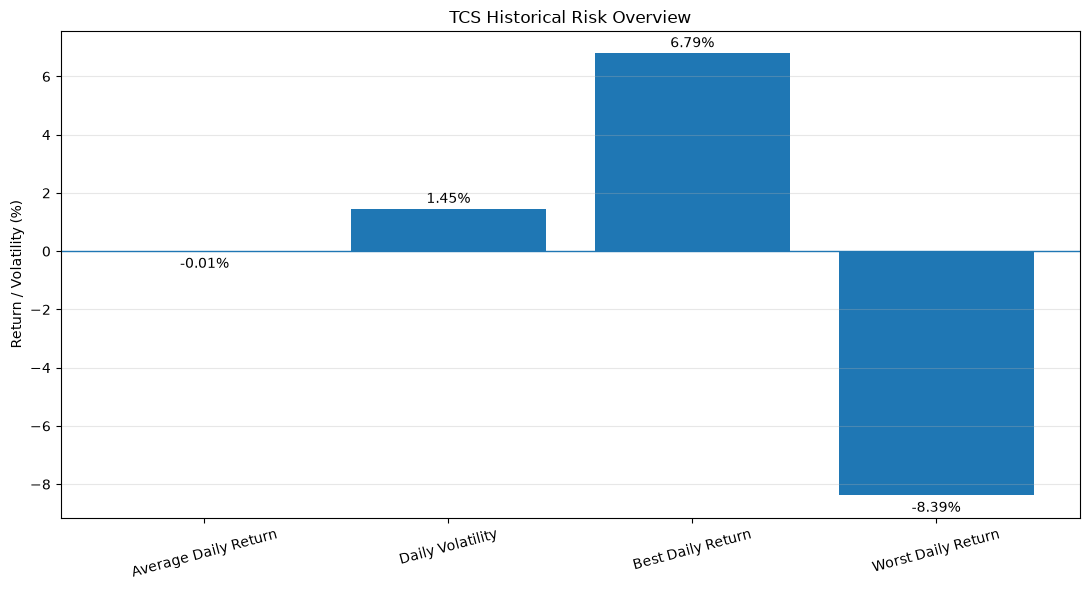

Chart saved: project_outputs/tcs_master_risk_dashboard.png
STEP 289 COMPLETED!


In [ ]:
# STEP 289: CREATE MASTER RISK DASHBOARD CHART

import matplotlib.pyplot as plt

chart_metrics = [
    "Average Daily Return",
    "Daily Volatility",
    "Best Daily Return",
    "Worst Daily Return"
]

chart_values = [
    risk_metrics["Average Daily Return (%)"],
    risk_metrics["Daily Return Volatility (%)"],
    risk_metrics["Best Daily Return (%)"],
    risk_metrics["Worst Daily Return (%)"]
]

plt.figure(figsize=(11, 6))

bars = plt.bar(chart_metrics, chart_values)

plt.axhline(0, linewidth=1)
plt.title("TCS Historical Risk Overview")
plt.ylabel("Return / Volatility (%)")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, chart_values):
    vertical_position = value + (0.1 if value >= 0 else -0.2)

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        vertical_position,
        f"{value:.2f}%",
        ha="center",
        va="bottom" if value >= 0 else "top"
    )

plt.tight_layout()
plt.savefig(
    "project_outputs/tcs_master_risk_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Chart saved: project_outputs/tcs_master_risk_dashboard.png")
print("STEP 289 COMPLETED!")

In [ ]:
# STEP 290: VERIFY MASTER DASHBOARD FILES

import os

required_files = [
    "tcs_master_risk_report.csv",
    "tcs_master_risk_dashboard.png"
]

print("===== MASTER DASHBOARD FILE CHECK =====")

for file_name in required_files:
    file_path = os.path.join("project_outputs", file_name)

    if os.path.isfile(file_path):
        size_kb = os.path.getsize(file_path) / 1024
        print(f"FOUND: {file_name} ({size_kb:.2f} KB)")
    else:
        print(f"MISSING: {file_name}")

print("\nSTEP 290 COMPLETED!")

===== MASTER DASHBOARD FILE CHECK =====
FOUND: tcs_master_risk_report.csv (0.64 KB)
FOUND: tcs_master_risk_dashboard.png (115.33 KB)

STEP 290 COMPLETED!


In [ ]:
# STEP 294: SAVE FINBERT NEWS SENTIMENT DATA

from pathlib import Path

# Confirm that the existing news dataset is available
if "news_df" not in globals():
    print("ERROR: news_df is not available in this notebook.")
    print("Run the previous news collection and sentiment analysis cells first.")

else:
    output_dir = Path("project_outputs")
    output_dir.mkdir(parents=True, exist_ok=True)

    news_output_path = output_dir / "tcs_news_sentiment.csv"

    news_df.to_csv(news_output_path, index=False)

    print("FinBERT news sentiment data saved successfully!")
    print(f"File: {news_output_path.resolve()}")
    print(f"Total headlines: {len(news_df)}")
    print("\nAvailable columns:")
    print(news_df.columns.tolist())

print("\nSTEP 294 COMPLETED!")

ERROR: news_df is not available in this notebook.
Run the previous news collection and sentiment analysis cells first.

STEP 294 COMPLETED!


In [ ]:
# STEP 295: COLLECT NEWS, ANALYZE FINBERT SENTIMENT AND SAVE RESULTS

from pathlib import Path
import xml.etree.ElementTree as ET

import pandas as pd
import requests
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from tqdm.auto import tqdm


# 1. Collect Google News RSS headlines
queries = [
    "TCS stock India",
    "NIFTY 50 stock market India",
    "Indian stock market"
]

news_records = []

for query in queries:
    rss_url = "https://news.google.com/rss/search"
    params = {
        "q": query,
        "hl": "en-IN",
        "gl": "IN",
        "ceid": "IN:en"
    }

    try:
        response = requests.get(
            rss_url,
            params=params,
            timeout=20,
            headers={"User-Agent": "Mozilla/5.0"}
        )
        response.raise_for_status()

        root = ET.fromstring(response.content)

        for item in root.findall(".//item"):
            title = item.findtext("title", default="").strip()
            link = item.findtext("link", default="").strip()
            pub_date = item.findtext("pubDate", default="")

            if title:
                news_records.append({
                    "Headline": title,
                    "Link": link,
                    "Published": pub_date,
                    "Query": query
                })

    except Exception as error:
        print(f"Could not fetch query '{query}': {error}")


news_df = pd.DataFrame(news_records)

if news_df.empty:
    raise RuntimeError(
        "No news headlines were collected. Check your internet connection "
        "and try running this cell again."
    )

news_df = news_df.drop_duplicates(
    subset=["Headline"]
).reset_index(drop=True)

print(f"Unique headlines collected: {len(news_df)}")


# 2. Load the FinBERT model
model_name = "ProsusAI/finbert"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Using device: {device}")
print("Loading FinBERT model...")

finbert_tokenizer = AutoTokenizer.from_pretrained(model_name)

finbert_model = AutoModelForSequenceClassification.from_pretrained(
    model_name
).to(device)

finbert_model.eval()


# 3. Analyze headline sentiment
finbert_results = []
batch_size = 16

id2label = {
    int(key): value.lower()
    for key, value in finbert_model.config.id2label.items()
}

for start in tqdm(range(0, len(news_df), batch_size)):
    batch = (
        news_df["Headline"]
        .iloc[start:start + batch_size]
        .fillna("")
        .astype(str)
        .tolist()
    )

    inputs = finbert_tokenizer(
        batch,
        padding=True,
        truncation=True,
        max_length=128,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        outputs = finbert_model(**inputs)
        probabilities = torch.softmax(
            outputs.logits,
            dim=1
        ).cpu().numpy()

    for probs in probabilities:
        predicted_index = int(probs.argmax())
        sentiment = id2label[predicted_index]

        result = {
            "FinBERT_Sentiment": sentiment.capitalize(),
            "FinBERT_Confidence": float(probs[predicted_index]),
            "FinBERT_Positive": 0.0,
            "FinBERT_Negative": 0.0,
            "FinBERT_Neutral": 0.0
        }

        for index, probability in enumerate(probs):
            label = id2label[index]

            if label in ["positive", "negative", "neutral"]:
                result[f"FinBERT_{label.capitalize()}"] = float(
                    probability
                )

        finbert_results.append(result)


# 4. Attach sentiment results
finbert_df = pd.DataFrame(finbert_results)

news_df = pd.concat(
    [news_df.reset_index(drop=True), finbert_df],
    axis=1
)


# 5. Save the news data for the Streamlit website
output_dir = Path("project_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "tcs_news_sentiment.csv"

news_df.to_csv(output_path, index=False)

print("\nFinBERT Sentiment Distribution:")
print(news_df["FinBERT_Sentiment"].value_counts())

print(f"\nCSV saved successfully: {output_path.resolve()}")
print(f"Total headlines analyzed: {len(news_df)}")

display(
    news_df[
        [
            "Headline",
            "Published",
            "FinBERT_Sentiment",
            "FinBERT_Confidence"
        ]
    ].head(10)
)

print("\nSTEP 295 COMPLETED!")

d:\PROJECT\Stock_Vission_Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Unique headlines collected: 274
Using device: cpu
Loading FinBERT model...


100%|██████████| 18/18 [00:17<00:00,  1.06it/s]



FinBERT Sentiment Distribution:
FinBERT_Sentiment
Neutral     100
Negative     90
Positive     84
Name: count, dtype: int64

CSV saved successfully: D:\PROJECT\Stock_Vission_Project\project_outputs\tcs_news_sentiment.csv
Total headlines analyzed: 274


,Headline,Published,FinBERT_Sentiment,FinBERT_Confidence
0,"HCLTech jumps over 7%, TCS up 5%: Why are IT s...","Tue, 13 Oct 2026 05:45:00 GMT",Positive,0.651793
1,India's TCS rises as margins steady despite AI...,"Fri, 09 Oct 2026 07:00:00 GMT",Positive,0.809072
2,Indian IT stocks surge despite US immigration ...,"Fri, 09 Oct 2026 05:09:31 GMT",Neutral,0.664812
3,TCS shares jump over 5% after Q2 results; IT s...,"Fri, 09 Oct 2026 03:57:15 GMT",Positive,0.904370
4,"HCLTech jumps 6%, TCS surges over 5%: Why are ...","Tue, 13 Oct 2026 05:12:12 GMT",Positive,0.661486
5,"TCS, TechM, Infosys shares lead Sensex, Nifty ...","Thu, 15 Oct 2026 04:15:10 GMT",Neutral,0.629639
6,"Market wrap: Tech Mahindra, TCS, InterGlobe, B...","Fri, 16 Oct 2026 11:04:23 GMT",Negative,0.493379
7,"Indian IT stocks on fire due to anti-AI trade,...","Thu, 15 Oct 2026 06:35:40 GMT",Neutral,0.659169
8,TCS completes acquisition of BBY Services Indi...,"Thu, 15 Oct 2026 08:12:43 GMT",Neutral,0.881645
9,TCS shares rise as AI revenue offsets sluggish...,"Thu, 08 Oct 2026 07:00:00 GMT",Positive,0.891321



STEP 295 COMPLETED!


In [ ]:
# STEP 298: INSPECT SAVED ML MODELS

from pathlib import Path
import joblib

models_dir = Path("models")

model_files = [
    "extra_trees.joblib",
    "gradient_boosting.joblib",
    "linear_regression.joblib",
    "random_forest.joblib",
    "xgboost.joblib"
]

for file_name in model_files:

    model_path = models_dir / file_name

    print("\n" + "=" * 55)
    print(f"MODEL: {file_name}")
    print("=" * 55)

    if not model_path.exists():
        print("Model file not found.")
        continue

    try:
        model = joblib.load(model_path)

        print("Model type:", type(model).__name__)

        if hasattr(model, "n_features_in_"):
            print("Expected input features:", model.n_features_in_)

        if hasattr(model, "feature_names_in_"):
            print("Feature names:")
            print(list(model.feature_names_in_))

        if hasattr(model, "steps"):
            print("Pipeline steps:")
            print([name for name, _ in model.steps])

    except Exception as error:
        print("Could not inspect model:", error)

print("\nSTEP 298 COMPLETED!")


MODEL: extra_trees.joblib
Model type: ExtraTreesRegressor
Expected input features: 18
Feature names:
['Close', 'High', 'Low', 'Open', 'Volume', 'Daily_Return', 'MA20', 'MA50', 'MA200', 'RSI_14', 'EMA12', 'EMA26', 'MACD', 'MACD_Signal', 'BB_Middle', 'BB_Upper', 'BB_Lower', 'Volume_MA20']

MODEL: gradient_boosting.joblib
Model type: MultiOutputRegressor
Expected input features: 18
Feature names:
['Close', 'High', 'Low', 'Open', 'Volume', 'Daily_Return', 'MA20', 'MA50', 'MA200', 'RSI_14', 'EMA12', 'EMA26', 'MACD', 'MACD_Signal', 'BB_Middle', 'BB_Upper', 'BB_Lower', 'Volume_MA20']

MODEL: linear_regression.joblib
Model type: LinearRegression
Expected input features: 18
Feature names:
['Close', 'High', 'Low', 'Open', 'Volume', 'Daily_Return', 'MA20', 'MA50', 'MA200', 'RSI_14', 'EMA12', 'EMA26', 'MACD', 'MACD_Signal', 'BB_Middle', 'BB_Upper', 'BB_Lower', 'Volume_MA20']

MODEL: random_forest.joblib
Model type: RandomForestRegressor
Expected input features: 18
Feature names:
['Close', 'High',

In [ ]:
 # STEP 299: CHECK SAVED MODEL OUTPUT DIMENSIONS

from pathlib import Path
import joblib

models_dir = Path("models")

model_files = [
    "extra_trees.joblib",
    "gradient_boosting.joblib",
    "linear_regression.joblib",
    "random_forest.joblib",
    "xgboost.joblib"
]

for file_name in model_files:

    model_path = models_dir / file_name

    print("\n" + "=" * 50)
    print(f"Model: {file_name}")
    print("=" * 50)

    if not model_path.exists():
        print("Model file not found.")
        continue

    try:
        model = joblib.load(model_path)

        print("Model type:", type(model).__name__)
        print("Input features:", getattr(model, "n_features_in_", "Unknown"))

        if hasattr(model, "feature_names_in_"):
            print("Feature names:", list(model.feature_names_in_))

        if hasattr(model, "estimators_"):
            print("Number of fitted estimators:", len(model.estimators_))

        print("Number of outputs:", getattr(model, "n_outputs_", "Not directly available"))

    except Exception as error:
        print("Inspection error:", error)

print("\nSTEP 299 COMPLETED!")


Model: extra_trees.joblib
Model type: ExtraTreesRegressor
Input features: 18
Feature names: ['Close', 'High', 'Low', 'Open', 'Volume', 'Daily_Return', 'MA20', 'MA50', 'MA200', 'RSI_14', 'EMA12', 'EMA26', 'MACD', 'MACD_Signal', 'BB_Middle', 'BB_Upper', 'BB_Lower', 'Volume_MA20']
Number of fitted estimators: 200
Number of outputs: 4

Model: gradient_boosting.joblib
Model type: MultiOutputRegressor
Input features: 18
Feature names: ['Close', 'High', 'Low', 'Open', 'Volume', 'Daily_Return', 'MA20', 'MA50', 'MA200', 'RSI_14', 'EMA12', 'EMA26', 'MACD', 'MACD_Signal', 'BB_Middle', 'BB_Upper', 'BB_Lower', 'Volume_MA20']
Number of fitted estimators: 4
Number of outputs: Not directly available

Model: linear_regression.joblib
Model type: LinearRegression
Input features: 18
Feature names: ['Close', 'High', 'Low', 'Open', 'Volume', 'Daily_Return', 'MA20', 'MA50', 'MA200', 'RSI_14', 'EMA12', 'EMA26', 'MACD', 'MACD_Signal', 'BB_Middle', 'BB_Upper', 'BB_Lower', 'Volume_MA20']
Number of outputs: Not 

In [ ]:
# STEP 300: TEST SAVED MODELS ON LATEST MARKET DATA

from pathlib import Path
import joblib
import numpy as np
import pandas as pd

models_dir = Path("models")

model_files = [
    "extra_trees.joblib",
    "gradient_boosting.joblib",
    "linear_regression.joblib",
    "random_forest.joblib",
    "xgboost.joblib"
]

if "df" not in globals():
    raise NameError(
        "DataFrame 'df' not found. Run the market data and feature-engineering cells first."
    )

print("Latest available market date:", df.index[-1])

for file_name in model_files:

    model_path = models_dir / file_name

    print("\n" + "=" * 55)
    print("MODEL:", file_name)
    print("=" * 55)

    if not model_path.exists():
        print("Model file not found.")
        continue

    model = joblib.load(model_path)

    if not hasattr(model, "feature_names_in_"):
        print("Feature names unavailable. Skipping automatic prediction test.")
        continue

    features = list(model.feature_names_in_)
    missing_features = [
        feature for feature in features
        if feature not in df.columns
    ]

    if missing_features:
        print("Missing required features:", missing_features)
        continue

    latest_features = df[features].tail(1)

    if not np.isfinite(
        latest_features.to_numpy(dtype=float)
    ).all():
        print("Latest row contains missing or infinite feature values.")
        continue

    try:
        prediction = np.asarray(
            model.predict(latest_features)
        )

        print("Input features:", len(features))
        print("Prediction output shape:", prediction.shape)
        print("Raw prediction values:", prediction.flatten())

    except Exception as error:
        print("Prediction failed:", error)

print("\nSTEP 300 COMPLETED!")

Latest available market date: 2026-10-16 00:00:00

MODEL: extra_trees.joblib
Missing required features: ['EMA12', 'EMA26', 'MACD', 'MACD_Signal', 'BB_Middle', 'BB_Upper', 'BB_Lower', 'Volume_MA20']

MODEL: gradient_boosting.joblib
Missing required features: ['EMA12', 'EMA26', 'MACD', 'MACD_Signal', 'BB_Middle', 'BB_Upper', 'BB_Lower', 'Volume_MA20']

MODEL: linear_regression.joblib
Missing required features: ['EMA12', 'EMA26', 'MACD', 'MACD_Signal', 'BB_Middle', 'BB_Upper', 'BB_Lower', 'Volume_MA20']

MODEL: random_forest.joblib
Missing required features: ['EMA12', 'EMA26', 'MACD', 'MACD_Signal', 'BB_Middle', 'BB_Upper', 'BB_Lower', 'Volume_MA20']

MODEL: xgboost.joblib
Missing required features: [np.str_('EMA12'), np.str_('EMA26'), np.str_('MACD'), np.str_('MACD_Signal'), np.str_('BB_Middle'), np.str_('BB_Upper'), np.str_('BB_Lower'), np.str_('Volume_MA20')]

STEP 300 COMPLETED!


In [ ]:
# STEP 301: CREATE MISSING FEATURES FOR SAVED ML MODELS

import numpy as np
import pandas as pd

if "df" not in globals():
    raise NameError(
        "DataFrame 'df' not found. Run the market-data loading cells first."
    )

# Make sure the required source columns exist
required_columns = ["Close", "High", "Low", "Open", "Volume"]

missing_source_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_source_columns:
    raise ValueError(
        f"Required market columns are missing: {missing_source_columns}"
    )

# Ensure each source is a Series, including with MultiIndex columns
close = df["Close"]
volume = df["Volume"]

if isinstance(close, pd.DataFrame):
    close = close.iloc[:, 0]

if isinstance(volume, pd.DataFrame):
    volume = volume.iloc[:, 0]

# Exponential moving averages
df["EMA12"] = close.ewm(
    span=12,
    adjust=False
).mean()

df["EMA26"] = close.ewm(
    span=26,
    adjust=False
).mean()

# MACD and its signal line
df["MACD"] = df["EMA12"] - df["EMA26"]

df["MACD_Signal"] = df["MACD"].ewm(
    span=9,
    adjust=False
).mean()

# Bollinger Bands, using a 20-session window
df["BB_Middle"] = close.rolling(
    window=20,
    min_periods=20
).mean()

rolling_std = close.rolling(
    window=20,
    min_periods=20
).std()

df["BB_Upper"] = df["BB_Middle"] + 2 * rolling_std
df["BB_Lower"] = df["BB_Middle"] - 2 * rolling_std

# 20-session average volume
df["Volume_MA20"] = volume.rolling(
    window=20,
    min_periods=20
).mean()

# Confirm all model-required features are now present
model_features = [
    "Close", "High", "Low", "Open", "Volume",
    "Daily_Return", "MA20", "MA50", "MA200", "RSI_14",
    "EMA12", "EMA26", "MACD", "MACD_Signal",
    "BB_Middle", "BB_Upper", "BB_Lower", "Volume_MA20"
]

missing_features = [
    col for col in model_features
    if col not in df.columns
]

print("Total required model features:", len(model_features))
print("Missing feature columns:", missing_features)

print("\nLatest feature values:")
display(df[model_features].tail(3).round(4))

print("\nMissing values in latest feature row:")
print(df[model_features].tail(1).isna().sum().to_dict())

print("\nSTEP 301 COMPLETED!")

Total required model features: 18
Missing feature columns: []

Latest feature values:


Price,Close,High,Low,Open,Volume,Daily_Return,MA20,MA50,MA200,RSI_14,EMA12,EMA26,MACD,MACD_Signal,BB_Middle,BB_Upper,BB_Lower,Volume_MA20
Date,,,,,,,,,,,,,,,,,,
2026-10-14,2304.8999,2335.8,2265.6001,2274.0,12145767,2.1087,2110.9259,2231.1681,2428.9732,65.0396,2150.8374,2156.4264,-5.5890,-35.5273,2110.9259,2252.9946,1968.8571,4596818.45
2026-10-15,2350.0000,2386.7,2335.0000,2347.2,9150523,1.9567,2119.5646,2229.2282,2424.8580,67.9940,2181.4778,2170.7652,10.7126,-26.2793,2119.5646,2295.5670,1943.5622,4916159.15
2026-10-16,2465.0000,2484.7,2375.7000,2382.0,12166634,4.8936,2133.8936,2230.5234,2421.2746,74.0222,2225.0966,2192.5604,32.5362,-14.5162,2133.8936,2367.3551,1900.4321,5359695.00



Missing values in latest feature row:
{'Close': 0, 'High': 0, 'Low': 0, 'Open': 0, 'Volume': 0, 'Daily_Return': 0, 'MA20': 0, 'MA50': 0, 'MA200': 0, 'RSI_14': 0, 'EMA12': 0, 'EMA26': 0, 'MACD': 0, 'MACD_Signal': 0, 'BB_Middle': 0, 'BB_Upper': 0, 'BB_Lower': 0, 'Volume_MA20': 0}

STEP 301 COMPLETED!


In [ ]:
# STEP 302: TEST SAVED MODELS WITH COMPLETE FEATURES

from pathlib import Path
import joblib
import numpy as np
import pandas as pd

models_dir = Path("models")

model_files = [
    "extra_trees.joblib",
    "gradient_boosting.joblib",
    "linear_regression.joblib",
    "random_forest.joblib",
    "xgboost.joblib"
]

# Define the required model features
model_features = [
    "Close", "High", "Low", "Open", "Volume",
    "Daily_Return", "MA20", "MA50", "MA200", "RSI_14",
    "EMA12", "EMA26", "MACD", "MACD_Signal",
    "BB_Middle", "BB_Upper", "BB_Lower", "Volume_MA20"
]

latest_date = df.index[-1]
latest_features = df[model_features].tail(1)

print("Latest market date:", latest_date)
print("Next-session estimate will use the latest available row.")

if not np.isfinite(latest_features.to_numpy(dtype=float)).all():
    raise ValueError(
        "Latest feature row contains missing or infinite values."
    )

for file_name in model_files:

    model_path = models_dir / file_name

    print("\n" + "=" * 50)
    print("MODEL:", file_name)
    print("=" * 50)

    if not model_path.exists():
        print("Model file not found.")
        continue

    try:
        model = joblib.load(model_path)

        expected_features = list(model.feature_names_in_)

        if expected_features != model_features:
            if set(expected_features) != set(model_features):
                print("Model feature mismatch. Skipping.")
                continue

            X_latest = latest_features[expected_features]
        else:
            X_latest = latest_features

        prediction = np.asarray(model.predict(X_latest))

        print("Prediction output shape:", prediction.shape)
        print("Raw prediction:", prediction.flatten())

    except Exception as error:
        print("Prediction failed:", error)

print("\nSTEP 302 COMPLETED!")

Latest market date: 2026-10-16 00:00:00
Next-session estimate will use the latest available row.

MODEL: extra_trees.joblib
Prediction output shape: (1, 4)
Raw prediction: [2668.95061284 2700.701112   2645.86728225 2679.7817477 ]

MODEL: gradient_boosting.joblib
Prediction output shape: (1, 4)
Raw prediction: [2655.1765405  2696.96000368 2637.16075311 2677.6926382 ]

MODEL: linear_regression.joblib
Prediction output shape: (1, 4)
Raw prediction: [2482.66738561 2508.85431406 2476.17892504 2499.57179615]

MODEL: random_forest.joblib
Prediction output shape: (1, 4)
Raw prediction: [2665.82977481 2714.9986567  2644.70943264 2695.95708008]

MODEL: xgboost.joblib
Prediction output shape: (1, 4)
Raw prediction: [2649.3542 2695.7153 2641.286  2686.4272]

STEP 302 COMPLETED!


In [367]:
# STEP 303: VERIFY NEXT-DAY OHLC PREDICTIONS

import joblib
import numpy as np
import pandas as pd
from pathlib import Path

# Support either a dictionary or a list of target columns
if isinstance(target_columns, dict):
    target_names = list(target_columns.keys())
elif isinstance(target_columns, (list, tuple)):
    target_names = list(target_columns)
else:
    raise TypeError(
        f"Unexpected target_columns type: {type(target_columns).__name__}"
    )

print("Prediction targets:", target_names)

# Load the saved Linear Regression model
model_path = Path("models") / "linear_regression.joblib"
lr_saved_model = joblib.load(model_path)

# Retrieve the exact input features expected by the model
feature_names = list(lr_saved_model.feature_names_in_)

missing_features = [
    feature for feature in feature_names
    if feature not in df.columns
]

if missing_features:
    raise ValueError(
        f"Missing model features: {missing_features}. "
        "Run the feature-engineering cells first."
    )

# Latest available market observation
latest_X = df[feature_names].tail(1).copy()

if not np.isfinite(latest_X.to_numpy(dtype=float)).all():
    raise ValueError(
        "The latest input row contains missing or infinite values."
    )

# Generate the model prediction
predicted_values = np.asarray(
    lr_saved_model.predict(latest_X)
).reshape(-1)

if len(predicted_values) != len(target_names):
    raise ValueError(
        f"Model returned {len(predicted_values)} outputs, "
        f"but {len(target_names)} target names are defined."
    )

# Display predictions without changing their original target order
prediction_result = pd.DataFrame(
    [predicted_values],
    columns=target_names,
    index=latest_X.index
)

prediction_result.index.name = "Latest_Feature_Date"

print("\nLatest market data date:", latest_X.index[-1])
print("\nPredicted next-session values:")
display(prediction_result.round(2))

print("\nSTEP 303 COMPLETED!")

Prediction targets: ['Target_Next_Open', 'Target_Next_High', 'Target_Next_Low', 'Target_Next_Close']

Latest market data date: 2026-10-16 00:00:00

Predicted next-session values:


,Target_Next_Open,Target_Next_High,Target_Next_Low,Target_Next_Close
Latest_Feature_Date,,,,
2026-10-16,2482.67,2508.85,2476.18,2499.57



STEP 303 COMPLETED!


In [370]:
# STEP 305: VALIDATE SAVED MODELS ON CHRONOLOGICAL TEST DATA

from pathlib import Path
import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Features expected by the saved models
feature_columns = [
    "Close", "High", "Low", "Open", "Volume",
    "Daily_Return", "MA20", "MA50", "MA200", "RSI_14",
    "EMA12", "EMA26", "MACD", "MACD_Signal",
    "BB_Middle", "BB_Upper", "BB_Lower", "Volume_MA20"
]

# Model outputs are defined in STEP 122D
target_columns = [
    "Target_Next_Open",
    "Target_Next_High",
    "Target_Next_Low",
    "Target_Next_Close"
]

source_columns = ["Open", "High", "Low", "Close"]

# Validate source data
if "df" not in globals():
    raise NameError("df is missing. Run the market-data cells first.")

missing_features = [
    column for column in feature_columns
    if column not in df.columns
]

if missing_features:
    raise ValueError(
        f"Missing model features: {missing_features}"
    )

# Reconstruct next-session OHLC targets
validation_df = df.sort_index().copy()

for target_name, source_column in zip(
    target_columns, source_columns
):
    validation_df[target_name] = (
        validation_df[source_column].shift(-1)
    )

# Remove invalid rows
validation_df = validation_df.replace(
    [np.inf, -np.inf],
    np.nan
)

validation_df = validation_df.dropna(
    subset=feature_columns + target_columns
)

if len(validation_df) < 20:
    raise ValueError("Not enough valid observations for validation.")

# Chronological 80/20 split; do not shuffle
split_index = int(len(validation_df) * 0.80)

train_eval_df = validation_df.iloc[:split_index].copy()
test_eval_df = validation_df.iloc[split_index:].copy()

X_test_eval = test_eval_df[feature_columns].copy()
y_test_eval = test_eval_df[target_columns].copy()

print("Training observations:", len(train_eval_df))
print("Test observations:", len(test_eval_df))
print(
    "Test period:",
    test_eval_df.index.min(),
    "to",
    test_eval_df.index.max()
)

# Naive baseline: tomorrow's OHLC equals today's OHLC
baseline_predictions = X_test_eval[source_columns].copy()
baseline_predictions.columns = target_columns

models_dir = Path("models")

model_files = {
    "Extra Trees": "extra_trees.joblib",
    "Gradient Boosting": "gradient_boosting.joblib",
    "Linear Regression": "linear_regression.joblib",
    "Random Forest": "random_forest.joblib",
    "XGBoost": "xgboost.joblib"
}

results = []

# Evaluate each saved model on the same chronological test period
for display_name, file_name in model_files.items():

    model_path = models_dir / file_name

    if not model_path.exists():
        print(f"Model not found: {file_name}")
        continue

    try:
        model = joblib.load(model_path)

        expected_features = list(model.feature_names_in_)

        if set(expected_features) != set(feature_columns):
            print(f"Feature mismatch: {display_name}")
            continue

        model_input = X_test_eval[expected_features]

        predictions = np.asarray(
            model.predict(model_input)
        )

        if predictions.ndim == 1:
            predictions = predictions.reshape(-1, 1)

        if predictions.shape != y_test_eval.shape:
            print(
                f"Output shape mismatch for {display_name}: "
                f"{predictions.shape}"
            )
            continue

        for index, target in enumerate(target_columns):

            actual = y_test_eval[target].to_numpy(dtype=float)
            predicted = predictions[:, index]

            valid = (
                np.isfinite(actual)
                & np.isfinite(predicted)
            )

            if not valid.any():
                continue

            results.append({
                "Model": display_name,
                "Target": target,
                "MAE": mean_absolute_error(
                    actual[valid],
                    predicted[valid]
                ),
                "RMSE": np.sqrt(
                    mean_squared_error(
                        actual[valid],
                        predicted[valid]
                    )
                )
            })

    except Exception as error:
        print(f"{display_name} evaluation failed: {error}")

# Evaluate baseline
for target in target_columns:

    actual = y_test_eval[target].to_numpy(dtype=float)
    predicted = baseline_predictions[target].to_numpy(dtype=float)

    valid = np.isfinite(actual) & np.isfinite(predicted)

    if valid.any():
        results.append({
            "Model": "Naive OHLC Baseline",
            "Target": target,
            "MAE": mean_absolute_error(
                actual[valid],
                predicted[valid]
            ),
            "RMSE": np.sqrt(
                mean_squared_error(
                    actual[valid],
                    predicted[valid]
                )
            )
        })

results_df = pd.DataFrame(results)

if results_df.empty:
    print("No models completed validation.")
else:
    print("\n===== ERROR BY OHLC TARGET =====")
    display(
        results_df.sort_values(
            ["Target", "MAE"]
        ).round(3)
    )

    print("\n===== OVERALL MODEL COMPARISON =====")

    summary_df = (
        results_df.groupby("Model", as_index=False)
        .agg(
            Average_MAE=("MAE", "mean"),
            Average_RMSE=("RMSE", "mean")
        )
        .sort_values("Average_MAE")
    )

    display(summary_df.round(3))

print("\nSTEP 305 COMPLETED!")

Training observations: 829
Test observations: 208
Test period: 2025-12-12 00:00:00 to 2026-10-15 00:00:00

===== ERROR BY OHLC TARGET =====


,Model,Target,MAE,RMSE
23,Naive OHLC Baseline,Target_Next_Close,35.115,48.959
11,Linear Regression,Target_Next_Close,39.459,53.152
3,Extra Trees,Target_Next_Close,306.340,364.397
7,Gradient Boosting,Target_Next_Close,312.312,369.531
19,XGBoost,Target_Next_Close,313.557,370.569
15,Random Forest,Target_Next_Close,319.742,379.607
9,Linear Regression,Target_Next_High,28.135,38.828
21,Naive OHLC Baseline,Target_Next_High,33.272,45.887
1,Extra Trees,Target_Next_High,295.346,354.588
17,XGBoost,Target_Next_High,297.543,356.174



===== OVERALL MODEL COMPARISON =====


,Model,Average_MAE,Average_RMSE
2,Linear Regression,29.897,42.054
3,Naive OHLC Baseline,34.513,47.958
0,Extra Trees,297.333,356.048
5,XGBoost,298.291,356.506
1,Gradient Boosting,302.600,361.301
4,Random Forest,302.778,362.694



STEP 305 COMPLETED!


In [371]:
# STEP 306: DIAGNOSE SAVED MODEL PREDICTION BIAS

from pathlib import Path
import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import mean_absolute_error

# Features expected by the saved models
feature_columns = [
    "Close", "High", "Low", "Open", "Volume",
    "Daily_Return", "MA20", "MA50", "MA200", "RSI_14",
    "EMA12", "EMA26", "MACD", "MACD_Signal",
    "BB_Middle", "BB_Upper", "BB_Lower", "Volume_MA20"
]

target_columns = [
    "Target_Next_Open",
    "Target_Next_High",
    "Target_Next_Low",
    "Target_Next_Close"
]

source_columns = ["Open", "High", "Low", "Close"]

# Rebuild the chronological evaluation dataset
validation_df = df.sort_index().copy()

for target_name, source_column in zip(
    target_columns, source_columns
):
    validation_df[target_name] = (
        validation_df[source_column].shift(-1)
    )

validation_df = validation_df.replace(
    [np.inf, -np.inf], np.nan
)

validation_df = validation_df.dropna(
    subset=feature_columns + target_columns
)

split_index = int(len(validation_df) * 0.80)

test_df = validation_df.iloc[split_index:].copy()

X_test_diag = test_df[feature_columns].copy()
y_test_diag = test_df[target_columns].copy()

models_dir = Path("models")

model_files = {
    "Extra Trees": "extra_trees.joblib",
    "Gradient Boosting": "gradient_boosting.joblib",
    "Linear Regression": "linear_regression.joblib",
    "Random Forest": "random_forest.joblib",
    "XGBoost": "xgboost.joblib"
}

diagnostic_rows = []

# Evaluate prediction distributions against actual test prices
for model_name, file_name in model_files.items():

    model_path = models_dir / file_name

    if not model_path.exists():
        print(f"Skipping missing model: {file_name}")
        continue

    model = joblib.load(model_path)

    if not hasattr(model, "feature_names_in_"):
        print(f"Skipping {model_name}: feature names unavailable.")
        continue

    expected_features = list(model.feature_names_in_)

    if set(expected_features) != set(feature_columns):
        print(f"Skipping {model_name}: feature mismatch.")
        continue

    predictions = np.asarray(
        model.predict(X_test_diag[expected_features])
    )

    if predictions.ndim == 1:
        predictions = predictions.reshape(-1, 1)

    if predictions.shape != y_test_diag.shape:
        print(f"Skipping {model_name}: output shape mismatch.")
        continue

    for index, target in enumerate(target_columns):

        actual = y_test_diag[target].to_numpy(dtype=float)
        predicted = predictions[:, index]

        valid = (
            np.isfinite(actual)
            & np.isfinite(predicted)
        )

        if not valid.any():
            continue

        actual_valid = actual[valid]
        predicted_valid = predicted[valid]

        diagnostic_rows.append({
            "Model": model_name,
            "Target": target,
            "Actual_Mean": actual_valid.mean(),
            "Predicted_Mean": predicted_valid.mean(),
            "Mean_Error": (
                predicted_valid - actual_valid
            ).mean(),
            "Actual_Min": actual_valid.min(),
            "Actual_Max": actual_valid.max(),
            "Predicted_Min": predicted_valid.min(),
            "Predicted_Max": predicted_valid.max(),
            "MAE": mean_absolute_error(
                actual_valid, predicted_valid
            )
        })

diagnostic_df = pd.DataFrame(diagnostic_rows)

print("Test observations:", len(test_df))
print(
    "Test dates:",
    test_df.index.min(),
    "to",
    test_df.index.max()
)

print("\n===== PREDICTION DISTRIBUTION DIAGNOSTICS =====")

display(
    diagnostic_df.sort_values(
        ["Target", "MAE"]
    ).round(2)
)

print("\nSTEP 306 COMPLETED!")

Test observations: 208
Test dates: 2025-12-12 00:00:00 to 2026-10-15 00:00:00

===== PREDICTION DISTRIBUTION DIAGNOSTICS =====


,Model,Target,Actual_Mean,Predicted_Mean,Mean_Error,Actual_Min,Actual_Max,Predicted_Min,Predicted_Max,MAE
11,Linear Regression,Target_Next_Close,2448.76,2468.42,19.66,1961.36,3187.34,1990.41,3186.91,39.46
3,Extra Trees,Target_Next_Close,2448.76,2748.92,300.17,1961.36,3187.34,2635.81,3174.14,306.34
7,Gradient Boosting,Target_Next_Close,2448.76,2755.00,306.24,1961.36,3187.34,2670.47,3182.52,312.31
19,XGBoost,Target_Next_Close,2448.76,2756.34,307.58,1961.36,3187.34,2661.24,3186.68,313.56
15,Random Forest,Target_Next_Close,2448.76,2762.23,313.47,1961.36,3187.34,2631.48,3172.78,319.74
9,Linear Regression,Target_Next_High,2480.36,2479.83,-0.53,2030.02,3269.78,1992.69,3209.00,28.13
1,Extra Trees,Target_Next_High,2480.36,2769.92,289.56,2030.02,3269.78,2657.54,3195.57,295.35
17,XGBoost,Target_Next_High,2480.36,2772.35,291.99,2030.02,3269.78,2679.90,3204.20,297.54
5,Gradient Boosting,Target_Next_High,2480.36,2780.44,300.09,2030.02,3269.78,2691.65,3202.67,305.60
13,Random Forest,Target_Next_High,2480.36,2780.99,300.63,2030.02,3269.78,2655.64,3191.24,306.47



STEP 306 COMPLETED!


In [372]:
# STEP 307: SAVE ML MODEL VALIDATION REPORTS

from pathlib import Path
import pandas as pd

output_dir = Path("project_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Check that validation results are available
if "results_df" not in globals():
    raise NameError(
        "results_df not found. Run STEP 305 first."
    )

if "diagnostic_df" not in globals():
    raise NameError(
        "diagnostic_df not found. Run STEP 306 first."
    )

# Save error metrics for each model and OHLC target
validation_path = output_dir / "tcs_model_validation_results.csv"

results_df.to_csv(validation_path, index=False)

# Save actual vs predicted distribution diagnostics
diagnostic_path = output_dir / "tcs_model_prediction_diagnostics.csv"

diagnostic_df.to_csv(diagnostic_path, index=False)

print("Validation reports saved successfully!")

print("\nFile 1:")
print(validation_path.resolve())

print("\nFile 2:")
print(diagnostic_path.resolve())

print("\nValidation report preview:")
display(results_df.head(10).round(3))

print("\nSTEP 307 COMPLETED!")

Validation reports saved successfully!

File 1:
D:\PROJECT\Stock_Vission_Project\project_outputs\tcs_model_validation_results.csv

File 2:
D:\PROJECT\Stock_Vission_Project\project_outputs\tcs_model_prediction_diagnostics.csv

Validation report preview:


,Model,Target,MAE,RMSE
0,Extra Trees,Target_Next_Open,290.168,349.930
1,Extra Trees,Target_Next_High,295.346,354.588
2,Extra Trees,Target_Next_Low,297.477,355.277
3,Extra Trees,Target_Next_Close,306.340,364.397
4,Gradient Boosting,Target_Next_Open,291.067,351.397
5,Gradient Boosting,Target_Next_High,305.597,365.097
6,Gradient Boosting,Target_Next_Low,301.426,359.178
7,Gradient Boosting,Target_Next_Close,312.312,369.531
8,Linear Regression,Target_Next_Open,18.736,29.025
9,Linear Regression,Target_Next_High,28.135,38.828



STEP 307 COMPLETED!


In [373]:
# STEP 314: VERIFY TRAINING DATA AND SAVED MODEL CONSISTENCY

from pathlib import Path
from datetime import datetime
import joblib
import numpy as np
import pandas as pd

project_dir = Path.cwd()

# Locate the project root
if not (project_dir / "models").is_dir():
    project_dir = Path("D:/PROJECT/Stock_Vission_Project")

models_dir = project_dir / "models"

print("=" * 65)
print("TRAINING DATA STATUS")
print("=" * 65)

for variable_name in ["X_train", "X_test", "y_train", "y_test", "df"]:
    variable = globals().get(variable_name)

    if variable is None:
        print(f"{variable_name}: NOT AVAILABLE")
    elif hasattr(variable, "shape"):
        print(f"{variable_name}: shape = {variable.shape}")
    else:
        print(f"{variable_name}: available")

# Inspect target columns
if "y_train" in globals():

    print("\nTraining target definition:")

    if isinstance(y_train, pd.DataFrame):
        print("Target columns:", y_train.columns.tolist())
    else:
        print("Target array shape:", np.asarray(y_train).shape)

# Match saved artifacts with current in-memory models
model_map = {
    "linear_regression": "lr_model",
    "random_forest": "rf_model",
    "gradient_boosting": "gb_model",
    "extra_trees": "et_model",
    "xgboost": "xgb_model"
}

print("\n" + "=" * 65)
print("SAVED MODEL CONSISTENCY CHECK")
print("=" * 65)

for file_name, variable_name in model_map.items():

    model_path = models_dir / f"{file_name}.joblib"

    print(f"\nModel: {file_name}")

    if not model_path.exists():
        print("Saved model file: NOT FOUND")
        continue

    saved_model = joblib.load(model_path)

    print(
        "Saved file modified:",
        datetime.fromtimestamp(model_path.stat().st_mtime).strftime(
            "%Y-%m-%d %H:%M:%S"
        )
    )

    saved_features = getattr(
        saved_model, "feature_names_in_", None
    )

    if saved_features is not None:
        saved_features = list(saved_features)
        print("Saved model input feature count:", len(saved_features))
    else:
        print("Saved model input feature names: unavailable")

    current_model = globals().get(variable_name)

    if current_model is None:
        print(f"Current Notebook model ({variable_name}): NOT AVAILABLE")
        continue

    print(f"Current Notebook model ({variable_name}): available")

    # Compare model predictions on the same test observations
    if (
        "X_test" in globals()
        and isinstance(X_test, pd.DataFrame)
        and saved_features is not None
    ):

        missing_features = [
            feature for feature in saved_features
            if feature not in X_test.columns
        ]

        if missing_features:
            print("Cannot compare: missing features:", missing_features)
            continue

        sample_X = X_test[saved_features].head(10)

        try:
            saved_pred = np.asarray(saved_model.predict(sample_X))
            current_pred = np.asarray(current_model.predict(sample_X))

            if saved_pred.shape == current_pred.shape:

                max_difference = np.max(
                    np.abs(
                        saved_pred.astype(float)
                        - current_pred.astype(float)
                    )
                )

                print(
                    "Maximum saved-vs-current prediction difference:",
                    round(float(max_difference), 8)
                )

                if np.allclose(
                    saved_pred, current_pred,
                    rtol=1e-6, atol=1e-6
                ):
                    print("Status: predictions MATCH")
                else:
                    print("Status: predictions DIFFER")

            else:
                print(
                    "Cannot compare: output shapes differ:",
                    saved_pred.shape,
                    current_pred.shape
                )

        except Exception as error:
            print("Comparison failed:", error)

    else:
        print("Test data unavailable for direct comparison.")

print("\nSTEP 314 COMPLETED!")

TRAINING DATA STATUS
X_train: shape = (829, 10)
X_test: shape = (208, 10)
y_train: shape = (829, 4)
y_test: shape = (208, 4)
df: shape = (1237, 22)

Training target definition:
Target columns: ['Target_Next_Open', 'Target_Next_High', 'Target_Next_Low', 'Target_Next_Close']

SAVED MODEL CONSISTENCY CHECK

Model: linear_regression
Saved file modified: 2026-10-18 12:46:16
Saved model input feature count: 18
Current Notebook model (lr_model): available
Cannot compare: missing features: ['EMA12', 'EMA26', 'MACD', 'MACD_Signal', 'BB_Middle', 'BB_Upper', 'BB_Lower', 'Volume_MA20']

Model: random_forest
Saved file modified: 2026-10-18 12:46:16
Saved model input feature count: 18
Current Notebook model (rf_model): available
Cannot compare: missing features: ['EMA12', 'EMA26', 'MACD', 'MACD_Signal', 'BB_Middle', 'BB_Upper', 'BB_Lower', 'Volume_MA20']

Model: gradient_boosting
Saved file modified: 2026-10-18 12:46:16
Saved model input feature count: 18
Current Notebook model (gb_model): available

In [374]:
# STEP 316: CHECK TRAINING AND SAVED MODEL FEATURES

from pathlib import Path
import joblib

print("=" * 55)
print("1. CURRENT FEATURE COLUMNS")
print("=" * 55)

print("Feature count:", len(feature_columns))
print("Feature columns:", list(feature_columns))

print("\n" + "=" * 55)
print("2. CLEAN DATAFRAME COLUMNS")
print("=" * 55)

print("df_clean shape:", df_clean.shape)
print("df_clean columns:", list(df_clean.columns))

print("\n" + "=" * 55)
print("3. CURRENT TRAINING DATA")
print("=" * 55)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\n" + "=" * 55)
print("4. SAVED MODEL FEATURES")
print("=" * 55)

model_path = Path("models") / "linear_regression.joblib"

saved_model = joblib.load(model_path)

saved_features = list(saved_model.feature_names_in_)

print("Saved model feature count:", len(saved_features))
print("Saved model features:", saved_features)

print("\n" + "=" * 55)
print("5. FEATURE DIFFERENCE")
print("=" * 55)

print(
    "Features missing from current training:",
    [feature for feature in saved_features if feature not in feature_columns]
)

print(
    "Features present only in current training:",
    [feature for feature in feature_columns if feature not in saved_features]
)

print("\nSTEP 316 COMPLETED!")

1. CURRENT FEATURE COLUMNS
Feature count: 18
Feature columns: ['Close', 'High', 'Low', 'Open', 'Volume', 'Daily_Return', 'MA20', 'MA50', 'MA200', 'RSI_14', 'EMA12', 'EMA26', 'MACD', 'MACD_Signal', 'BB_Middle', 'BB_Upper', 'BB_Lower', 'Volume_MA20']

2. CLEAN DATAFRAME COLUMNS
df_clean shape: (1037, 22)
df_clean columns: ['Close', 'High', 'Low', 'Open', 'Volume', 'Daily_Return', 'MA20', 'MA50', 'MA200', 'RSI_14', 'EMA12', 'EMA26', 'MACD', 'MACD_Signal', 'BB_Middle', 'BB_Upper', 'BB_Lower', 'Volume_MA20', 'Target_Next_Open', 'Target_Next_High', 'Target_Next_Low', 'Target_Next_Close']

3. CURRENT TRAINING DATA
X_train shape: (829, 10)
X_test shape: (208, 10)

4. SAVED MODEL FEATURES
Saved model feature count: 18
Saved model features: ['Close', 'High', 'Low', 'Open', 'Volume', 'Daily_Return', 'MA20', 'MA50', 'MA200', 'RSI_14', 'EMA12', 'EMA26', 'MACD', 'MACD_Signal', 'BB_Middle', 'BB_Upper', 'BB_Lower', 'Volume_MA20']

5. FEATURE DIFFERENCE
Features missing from current training: []
Featur

In [375]:
# STEP 317: REBUILD TRAIN/TEST DATA WITH ALL 18 FEATURES

import numpy as np
import pandas as pd

# Define the exact 18 features expected by saved models
feature_columns = [
    "Close", "High", "Low", "Open", "Volume",
    "Daily_Return", "MA20", "MA50", "MA200", "RSI_14",
    "EMA12", "EMA26", "MACD", "MACD_Signal",
    "BB_Middle", "BB_Upper", "BB_Lower", "Volume_MA20"
]

# Define the four next-session OHLC targets
target_columns = [
    "Target_Next_Open",
    "Target_Next_High",
    "Target_Next_Low",
    "Target_Next_Close"
]

# Verify that the source DataFrame exists
if "df_clean" not in globals():
    raise NameError(
        "df_clean is unavailable. Run the original data-cleaning "
        "and target-creation cells first."
    )

# Ensure required columns exist
required_columns = feature_columns + target_columns

missing_columns = [
    column for column in required_columns
    if column not in df_clean.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Clean and sort chronologically
model_df = df_clean.sort_index().copy()

model_df = model_df.replace(
    [np.inf, -np.inf],
    np.nan
)

model_df = model_df.dropna(
    subset=required_columns
)

if model_df.index.has_duplicates:
    raise ValueError(
        "Duplicate dates found. Resolve duplicate dates before splitting."
    )

# Create inputs and targets
X = model_df[feature_columns].copy()
y = model_df[target_columns].copy()

# Chronological 80/20 split; no shuffling
split_index = int(len(model_df) * 0.80)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

# Verify the rebuilt data
print("Features required by models:", len(feature_columns))
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

print("\nTarget columns:")
print(target_columns)

print("\nTraining date range:")
print(X_train.index.min(), "to", X_train.index.max())

print("\nTesting date range:")
print(X_test.index.min(), "to", X_test.index.max())

print(
    "\nChronological split verified:",
    X_train.index.max() < X_test.index.min()
)

print("\nSTEP 317 COMPLETED!")

Features required by models: 18
X_train shape: (829, 18)
X_test shape: (208, 18)
y_train shape: (829, 4)
y_test shape: (208, 4)

Target columns:
['Target_Next_Open', 'Target_Next_High', 'Target_Next_Low', 'Target_Next_Close']

Training date range:
2022-08-03 00:00:00 to 2025-12-11 00:00:00

Testing date range:
2025-12-12 00:00:00 to 2026-10-15 00:00:00

Chronological split verified: True

STEP 317 COMPLETED!


In [376]:
# STEP 318: REVALIDATE SAVED MODELS ON CORRECTED TEST DATA

from pathlib import Path
import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import mean_absolute_error, mean_squared_error

models_dir = Path("models")

model_files = {
    "Extra Trees": "extra_trees.joblib",
    "Gradient Boosting": "gradient_boosting.joblib",
    "Linear Regression": "linear_regression.joblib",
    "Random Forest": "random_forest.joblib",
    "XGBoost": "xgboost.joblib"
}

# Ensure the target names are in the original training order
target_columns = [
    "Target_Next_Open",
    "Target_Next_High",
    "Target_Next_Low",
    "Target_Next_Close"
]

source_columns = ["Open", "High", "Low", "Close"]

# Verify corrected test data
if X_test.shape[1] != 18:
    raise ValueError(f"Expected 18 features, found {X_test.shape[1]}.")

if y_test.shape[1] != 4:
    raise ValueError(f"Expected 4 targets, found {y_test.shape[1]}.")

X_eval = X_test.copy()
y_eval = y_test[target_columns].copy()

# Naive baseline: estimate next-session OHLC as today's OHLC
baseline_predictions = X_eval[source_columns].copy()
baseline_predictions.columns = target_columns

results = []

# Baseline metrics
for target in target_columns:

    actual = y_eval[target].to_numpy(dtype=float)
    predicted = baseline_predictions[target].to_numpy(dtype=float)

    valid = np.isfinite(actual) & np.isfinite(predicted)

    results.append({
        "Model": "Naive OHLC Baseline",
        "Target": target,
        "MAE": mean_absolute_error(actual[valid], predicted[valid]),
        "RMSE": np.sqrt(
            mean_squared_error(actual[valid], predicted[valid])
        )
    })

# Validate each saved model on exactly the same test rows
for model_name, file_name in model_files.items():

    model_path = models_dir / file_name

    if not model_path.exists():
        print(f"Missing model file: {file_name}")
        continue

    model = joblib.load(model_path)
    expected_features = list(model.feature_names_in_)

    missing = [
        feature for feature in expected_features
        if feature not in X_eval.columns
    ]

    if missing:
        print(f"{model_name} skipped; missing features: {missing}")
        continue

    model_input = X_eval[expected_features]

    predictions = np.asarray(model.predict(model_input))

    if predictions.ndim == 1:
        predictions = predictions.reshape(-1, 1)

    if predictions.shape != y_eval.shape:
        print(
            f"{model_name} skipped; prediction shape "
            f"{predictions.shape} differs from target shape {y_eval.shape}."
        )
        continue

    for position, target in enumerate(target_columns):

        actual = y_eval[target].to_numpy(dtype=float)
        predicted = predictions[:, position]

        valid = np.isfinite(actual) & np.isfinite(predicted)

        results.append({
            "Model": model_name,
            "Target": target,
            "MAE": mean_absolute_error(actual[valid], predicted[valid]),
            "RMSE": np.sqrt(
                mean_squared_error(actual[valid], predicted[valid])
            )
        })

# Display metrics by individual OHLC target
results_df = pd.DataFrame(results)

print("Test rows:", len(X_eval))
print("Test period:", X_eval.index.min(), "to", X_eval.index.max())

print("\n===== MAE AND RMSE BY TARGET =====")
display(
    results_df.sort_values(["Target", "MAE"]).round(3)
)

# Average the four target errors for each model
summary_df = (
    results_df.groupby("Model", as_index=False)
    .agg(
        Average_OHLC_MAE=("MAE", "mean"),
        Average_OHLC_RMSE=("RMSE", "mean")
    )
    .sort_values("Average_OHLC_MAE")
)

print("\n===== OVERALL MODEL COMPARISON =====")
display(summary_df.round(3))

print("\nSTEP 318 COMPLETED!")

Test rows: 208
Test period: 2025-12-12 00:00:00 to 2026-10-15 00:00:00

===== MAE AND RMSE BY TARGET =====


,Model,Target,MAE,RMSE
3,Naive OHLC Baseline,Target_Next_Close,35.115,48.959
15,Linear Regression,Target_Next_Close,39.459,53.152
7,Extra Trees,Target_Next_Close,306.340,364.397
11,Gradient Boosting,Target_Next_Close,312.312,369.531
23,XGBoost,Target_Next_Close,313.557,370.569
19,Random Forest,Target_Next_Close,319.742,379.607
13,Linear Regression,Target_Next_High,28.135,38.828
1,Naive OHLC Baseline,Target_Next_High,33.272,45.887
5,Extra Trees,Target_Next_High,295.346,354.588
21,XGBoost,Target_Next_High,297.543,356.174



===== OVERALL MODEL COMPARISON =====


,Model,Average_OHLC_MAE,Average_OHLC_RMSE
2,Linear Regression,29.897,42.054
3,Naive OHLC Baseline,34.513,47.958
0,Extra Trees,297.333,356.048
5,XGBoost,298.291,356.506
1,Gradient Boosting,302.600,361.301
4,Random Forest,302.778,362.694



STEP 318 COMPLETED!


In [377]:
# STEP 319: CHECK TRAINING VS TESTING PRICE DISTRIBUTION

import numpy as np
import pandas as pd

target_columns = [
    "Target_Next_Open",
    "Target_Next_High",
    "Target_Next_Low",
    "Target_Next_Close"
]

if "df_clean" not in globals():
    raise NameError(
        "df_clean not found. Run the original data-cleaning "
        "and target-creation cells first."
    )

# Sort chronologically and prepare valid OHLC targets
analysis_df = df_clean.sort_index().copy()

analysis_df = analysis_df.replace(
    [np.inf, -np.inf],
    np.nan
)

analysis_df = analysis_df.dropna(
    subset=target_columns
)

# Keep the same chronological 80/20 split
split_index = int(len(analysis_df) * 0.80)

train_period = analysis_df.iloc[:split_index]
test_period = analysis_df.iloc[split_index:]

summary_rows = []

for target in target_columns:

    train_values = train_period[target]
    test_values = test_period[target]

    summary_rows.append({
        "Target": target,
        "Train_Mean": train_values.mean(),
        "Test_Mean": test_values.mean(),
        "Mean_Shift": test_values.mean() - train_values.mean(),
        "Train_Min": train_values.min(),
        "Train_Max": train_values.max(),
        "Test_Min": test_values.min(),
        "Test_Max": test_values.max()
    })

distribution_df = pd.DataFrame(summary_rows)

print("Training period:")
print(train_period.index.min(), "to", train_period.index.max())

print("\nTesting period:")
print(test_period.index.min(), "to", test_period.index.max())

print("\n===== OHLC DISTRIBUTION SHIFT =====")

display(distribution_df.round(2))

print("\nSTEP 319 COMPLETED!")

Training period:
2022-08-03 00:00:00 to 2025-12-11 00:00:00

Testing period:
2025-12-12 00:00:00 to 2026-10-15 00:00:00

===== OHLC DISTRIBUTION SHIFT =====


,Target,Train_Mean,Test_Mean,Mean_Shift,Train_Min,Train_Max,Test_Min,Test_Max
0,Target_Next_Open,3287.87,2453.95,-833.91,2591.14,4228.90,1986.49,3269.78
1,Target_Next_High,3315.77,2480.36,-835.42,2643.54,4243.92,2030.02,3269.78
2,Target_Next_Low,3259.90,2422.94,-836.96,2561.60,4169.75,1955.62,3159.73
3,Target_Next_Close,3287.13,2448.76,-838.37,2610.58,4208.34,1961.36,3187.34



STEP 319 COMPLETED!


In [378]:
# STEP 320: CREATE NORMALIZED OHLC PREDICTION DATASET

import numpy as np
import pandas as pd

if "df_clean" not in globals():
    raise NameError(
        "df_clean is unavailable. Run the original data-cleaning "
        "and target-creation cells first."
    )

# Required historical features and next-session targets
required_columns = [
    "Close", "Open", "High", "Low", "Volume",
    "Daily_Return", "MA20", "MA50", "MA200", "RSI_14",
    "EMA12", "EMA26", "MACD", "MACD_Signal",
    "BB_Middle", "BB_Upper", "BB_Lower", "Volume_MA20",
    "Target_Next_Open", "Target_Next_High",
    "Target_Next_Low", "Target_Next_Close"
]

missing_columns = [
    column for column in required_columns
    if column not in df_clean.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Work on a separate copy; preserve original data
normalized_source = df_clean.sort_index().copy()

current_close = normalized_source["Close"].replace(0, np.nan)
current_open = normalized_source["Open"].replace(0, np.nan)
volume_ma20 = normalized_source["Volume_MA20"].replace(0, np.nan)

normalized_prediction_df = pd.DataFrame(
    index=normalized_source.index
)

# Price indicators relative to current Close
relative_price_columns = [
    "Open", "High", "Low",
    "MA20", "MA50", "MA200",
    "EMA12", "EMA26",
    "BB_Middle", "BB_Upper", "BB_Lower"
]

for column in relative_price_columns:
    normalized_prediction_df[f"{column}_Rel_Pct"] = (
        normalized_source[column] / current_close - 1
    ) * 100

# Normalize MACD indicators by current price
normalized_prediction_df["MACD_Pct"] = (
    normalized_source["MACD"] / current_close
) * 100

normalized_prediction_df["MACD_Signal_Pct"] = (
    normalized_source["MACD_Signal"] / current_close
) * 100

# Keep indicators that are already scale-independent
normalized_prediction_df["Daily_Return"] = (
    normalized_source["Daily_Return"]
)

normalized_prediction_df["RSI_14"] = (
    normalized_source["RSI_14"]
)

# Volume expressed relative to its recent average
normalized_prediction_df["Volume_Ratio"] = (
    normalized_source["Volume"] / volume_ma20
)

normalized_prediction_df["High_Low_Range_Pct"] = (
    (normalized_source["High"] - normalized_source["Low"])
    / current_close
) * 100

normalized_prediction_df["Open_Close_Change_Pct"] = (
    (normalized_source["Close"] / current_open - 1)
) * 100

# Targets are next-session OHLC percentage changes
target_map = {
    "Target_Next_Open_Pct": "Target_Next_Open",
    "Target_Next_High_Pct": "Target_Next_High",
    "Target_Next_Low_Pct": "Target_Next_Low",
    "Target_Next_Close_Pct": "Target_Next_Close"
}

for new_target, original_target in target_map.items():
    normalized_prediction_df[new_target] = (
        normalized_source[original_target] / current_close - 1
    ) * 100

# Define inputs and targets
normalized_feature_columns = [
    column for column in normalized_prediction_df.columns
    if not column.startswith("Target_Next_")
]

normalized_target_columns = list(target_map.keys())

# Remove non-finite and incomplete observations
normalized_prediction_df = normalized_prediction_df.replace(
    [np.inf, -np.inf],
    np.nan
)

normalized_prediction_df = normalized_prediction_df.dropna(
    subset=normalized_feature_columns + normalized_target_columns
)

# Chronological 80/20 split; do not shuffle
split_index = int(len(normalized_prediction_df) * 0.80)

normalized_train_df = normalized_prediction_df.iloc[:split_index].copy()
normalized_test_df = normalized_prediction_df.iloc[split_index:].copy()

X_train_norm = normalized_train_df[normalized_feature_columns].copy()
X_test_norm = normalized_test_df[normalized_feature_columns].copy()

y_train_norm = normalized_train_df[normalized_target_columns].copy()
y_test_norm = normalized_test_df[normalized_target_columns].copy()

print("Normalized dataset created successfully!")
print("Feature count:", len(normalized_feature_columns))
print("Target count:", len(normalized_target_columns))
print("Total observations:", len(normalized_prediction_df))
print("Training observations:", len(X_train_norm))
print("Testing observations:", len(X_test_norm))

print("\nTraining period:")
print(normalized_train_df.index.min(), "to", normalized_train_df.index.max())

print("\nTesting period:")
print(normalized_test_df.index.min(), "to", normalized_test_df.index.max())

print("\nTarget percentage changes — latest observations:")
display(y_test_norm.tail(5).round(3))

print("\nSTEP 320 COMPLETED!")

Normalized dataset created successfully!
Feature count: 18
Target count: 4
Total observations: 1037
Training observations: 829
Testing observations: 208

Training period:
2022-08-03 00:00:00 to 2025-12-11 00:00:00

Testing period:
2025-12-12 00:00:00 to 2026-10-15 00:00:00

Target percentage changes — latest observations:


,Target_Next_Open_Pct,Target_Next_High_Pct,Target_Next_Low_Pct,Target_Next_Close_Pct
Date,,,,
2026-10-09,1.340,1.814,-1.628,-1.438
2026-10-12,1.501,6.791,1.412,6.791
2026-10-13,0.740,3.478,0.368,2.109
2026-10-14,1.835,3.549,1.306,1.957
2026-10-15,1.362,5.732,1.094,4.894



STEP 320 COMPLETED!


In [379]:
# STEP 321: TRAIN AND COMPARE NORMALIZED OHLC MODELS

import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

# --------------------------------------------------
# 1. VERIFY STEP 320 DATA
# --------------------------------------------------

required_variables = [
    "X_train_norm",
    "X_test_norm",
    "y_train_norm",
    "y_test_norm",
    "normalized_source"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        f"Missing variables: {missing_variables}. "
        "Run STEP 320 first."
    )

if not X_train_norm.index.max() < X_test_norm.index.min():
    raise ValueError(
        "Training and testing dates are not correctly chronological."
    )

if not (
    np.isfinite(X_train_norm.to_numpy(dtype=float)).all()
    and np.isfinite(X_test_norm.to_numpy(dtype=float)).all()
    and np.isfinite(y_train_norm.to_numpy(dtype=float)).all()
    and np.isfinite(y_test_norm.to_numpy(dtype=float)).all()
):
    raise ValueError(
        "Non-finite values detected. Clean the data before training."
    )

print("Training observations:", len(X_train_norm))
print("Testing observations:", len(X_test_norm))
print("Input features:", X_train_norm.shape[1])
print("Prediction targets:", y_train_norm.columns.tolist())

# --------------------------------------------------
# 2. DEFINE EXPERIMENTAL CANDIDATE MODELS
# --------------------------------------------------

normalized_models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": make_pipeline(
        StandardScaler(),
        Ridge(alpha=10.0)
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=5,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200,
        max_depth=5,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": MultiOutputRegressor(
        GradientBoostingRegressor(
            n_estimators=100,
            learning_rate=0.03,
            max_depth=2,
            loss="huber",
            random_state=42
        )
    )
}

# --------------------------------------------------
# 3. CREATE TWO SIMPLE BASELINES
# --------------------------------------------------

target_columns_norm = list(y_train_norm.columns)

# Baseline A: predict zero change for all OHLC targets
zero_baseline = pd.DataFrame(
    0.0,
    index=X_test_norm.index,
    columns=target_columns_norm
)

# Baseline B: carry forward today's corresponding OHLC
source_test = normalized_source.loc[X_test_norm.index]

source_to_target = {
    "Target_Next_Open_Pct": "Open",
    "Target_Next_High_Pct": "High",
    "Target_Next_Low_Pct": "Low",
    "Target_Next_Close_Pct": "Close"
}

carry_forward_baseline = pd.DataFrame(
    index=X_test_norm.index
)

for target, source_column in source_to_target.items():
    carry_forward_baseline[target] = (
        source_test[source_column] / source_test["Close"] - 1
    ) * 100

baseline_predictions = {
    "Zero-Return Baseline": zero_baseline,
    "Carry-Forward OHLC Baseline": carry_forward_baseline
}

# --------------------------------------------------
# 4. TRAIN MODELS AND CALCULATE TEST ERRORS
# --------------------------------------------------

normalized_results = []
normalized_models_fitted = {}

def evaluate_predictions(model_name, predictions):

    predictions = pd.DataFrame(
        predictions,
        index=y_test_norm.index,
        columns=target_columns_norm
    )

    for target in target_columns_norm:

        actual = y_test_norm[target].to_numpy(dtype=float)
        predicted = predictions[target].to_numpy(dtype=float)

        valid = np.isfinite(actual) & np.isfinite(predicted)

        normalized_results.append({
            "Model": model_name,
            "Target": target,
            "MAE_Percentage_Points": mean_absolute_error(
                actual[valid], predicted[valid]
            ),
            "RMSE_Percentage_Points": np.sqrt(
                mean_squared_error(actual[valid], predicted[valid])
            ),
            "Valid_Test_Rows": int(valid.sum())
        })

# Evaluate simple baselines
for baseline_name, baseline_pred in baseline_predictions.items():
    evaluate_predictions(baseline_name, baseline_pred)

# Train each candidate on the chronological training set only
for model_name, model in normalized_models.items():

    print(f"\nTraining: {model_name}")

    try:
        model.fit(X_train_norm, y_train_norm)

        predictions = model.predict(X_test_norm)

        evaluate_predictions(model_name, predictions)

        normalized_models_fitted[model_name] = model

        print("Test evaluation completed.")

    except Exception as error:
        print(f"{model_name} failed: {error}")

# --------------------------------------------------
# 5. DISPLAY RESULTS
# --------------------------------------------------

normalized_results_df = pd.DataFrame(normalized_results)

print("\n===== ERROR BY TARGET =====")

display(
    normalized_results_df.sort_values(
        ["Target", "MAE_Percentage_Points"]
    ).round(4)
)

normalized_summary_df = (
    normalized_results_df
    .groupby("Model", as_index=False)
    .agg(
        Average_MAE=("MAE_Percentage_Points", "mean"),
        Average_RMSE=("RMSE_Percentage_Points", "mean")
    )
    .sort_values("Average_MAE")
)

print("\n===== OVERALL MODEL COMPARISON =====")

display(normalized_summary_df.round(4))

print("\nSTEP 321 COMPLETED!")

Training observations: 829
Testing observations: 208
Input features: 18
Prediction targets: ['Target_Next_Open_Pct', 'Target_Next_High_Pct', 'Target_Next_Low_Pct', 'Target_Next_Close_Pct']

Training: Linear Regression
Test evaluation completed.

Training: Ridge Regression
Test evaluation completed.

Training: Random Forest
Test evaluation completed.

Training: Extra Trees
Test evaluation completed.

Training: Gradient Boosting
Test evaluation completed.

===== ERROR BY TARGET =====


,Model,Target,MAE_Percentage_Points,RMSE_Percentage_Points,Valid_Test_Rows
3,Zero-Return Baseline,Target_Next_Close_Pct,1.4475,2.0103,208
7,Carry-Forward OHLC Baseline,Target_Next_Close_Pct,1.4475,2.0103,208
15,Ridge Regression,Target_Next_Close_Pct,1.4501,2.0109,208
11,Linear Regression,Target_Next_Close_Pct,1.4557,2.0115,208
27,Gradient Boosting,Target_Next_Close_Pct,1.4610,2.0218,208
23,Extra Trees,Target_Next_Close_Pct,1.4660,2.0233,208
19,Random Forest,Target_Next_Close_Pct,1.4808,2.0426,208
13,Ridge Regression,Target_Next_High_Pct,1.1714,1.6651,208
9,Linear Regression,Target_Next_High_Pct,1.1756,1.6696,208
17,Random Forest,Target_Next_High_Pct,1.1775,1.6605,208



===== OVERALL MODEL COMPARISON =====


,Model,Average_MAE,Average_RMSE
5,Ridge Regression,1.1217,1.6066
1,Extra Trees,1.1263,1.6026
3,Linear Regression,1.1300,1.6141
4,Random Forest,1.1344,1.6112
2,Gradient Boosting,1.1460,1.6227
6,Zero-Return Baseline,1.2670,1.7845
0,Carry-Forward OHLC Baseline,1.4224,1.9509



STEP 321 COMPLETED!


In [380]:
# STEP 322: DISPLAY NORMALIZED MODEL COMPARISON

if "normalized_results_df" not in globals():
    print("Results not found. Please run STEP 321 again.")
else:
    print("===== ERROR BY TARGET =====")
    display(
        normalized_results_df
        .sort_values(["Target", "MAE_Percentage_Points"])
        .round(4)
    )

    print("\n===== OVERALL MODEL COMPARISON =====")

    if "normalized_summary_df" in globals():
        display(normalized_summary_df.round(4))
    else:
        print("Overall summary not found. Recalculate the summary.")

print("\nSTEP 322 COMPLETED!")

===== ERROR BY TARGET =====


,Model,Target,MAE_Percentage_Points,RMSE_Percentage_Points,Valid_Test_Rows
3,Zero-Return Baseline,Target_Next_Close_Pct,1.4475,2.0103,208
7,Carry-Forward OHLC Baseline,Target_Next_Close_Pct,1.4475,2.0103,208
15,Ridge Regression,Target_Next_Close_Pct,1.4501,2.0109,208
11,Linear Regression,Target_Next_Close_Pct,1.4557,2.0115,208
27,Gradient Boosting,Target_Next_Close_Pct,1.4610,2.0218,208
23,Extra Trees,Target_Next_Close_Pct,1.4660,2.0233,208
19,Random Forest,Target_Next_Close_Pct,1.4808,2.0426,208
13,Ridge Regression,Target_Next_High_Pct,1.1714,1.6651,208
9,Linear Regression,Target_Next_High_Pct,1.1756,1.6696,208
17,Random Forest,Target_Next_High_Pct,1.1775,1.6605,208



===== OVERALL MODEL COMPARISON =====


,Model,Average_MAE,Average_RMSE
5,Ridge Regression,1.1217,1.6066
1,Extra Trees,1.1263,1.6026
3,Linear Regression,1.1300,1.6141
4,Random Forest,1.1344,1.6112
2,Gradient Boosting,1.1460,1.6227
6,Zero-Return Baseline,1.2670,1.7845
0,Carry-Forward OHLC Baseline,1.4224,1.9509



STEP 322 COMPLETED!


In [381]:
# STEP 323: WALK-FORWARD VALIDATION FOR NORMALIZED OHLC MODELS

import numpy as np
import pandas as pd

from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

# --------------------------------------------------
# 1. VERIFY STEP 320 DATA
# --------------------------------------------------

if (
    "normalized_prediction_df" not in globals()
    or "normalized_feature_columns" not in globals()
    or "normalized_target_columns" not in globals()
):
    raise NameError("Run STEP 320 first to create the normalized dataset.")

walk_df = normalized_prediction_df.sort_index().copy()

feature_cols = normalized_feature_columns
target_cols = normalized_target_columns

walk_df = walk_df.replace([np.inf, -np.inf], np.nan)
walk_df = walk_df.dropna(subset=feature_cols + target_cols)

X_all = walk_df[feature_cols].copy()
y_all = walk_df[target_cols].copy()

if not np.isfinite(X_all.to_numpy(dtype=float)).all():
    raise ValueError("Non-finite input features remain.")

if not np.isfinite(y_all.to_numpy(dtype=float)).all():
    raise ValueError("Non-finite target values remain.")

print("Total observations:", len(walk_df))
print("Features:", len(feature_cols))
print("Targets:", len(target_cols))
print("Date range:", walk_df.index.min(), "to", walk_df.index.max())

# --------------------------------------------------
# 2. DEFINE FRESH MODELS FOR EACH FOLD
# --------------------------------------------------

def build_normalized_models():

    return {
        "Linear Regression": LinearRegression(),

        "Ridge Regression": make_pipeline(
            StandardScaler(),
            Ridge(alpha=10.0)
        ),

        "Random Forest": RandomForestRegressor(
            n_estimators=200,
            max_depth=5,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        ),

        "Extra Trees": ExtraTreesRegressor(
            n_estimators=200,
            max_depth=5,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        ),

        "Gradient Boosting": MultiOutputRegressor(
            GradientBoostingRegressor(
                n_estimators=100,
                learning_rate=0.03,
                max_depth=2,
                loss="huber",
                random_state=42
            )
        )
    }

# --------------------------------------------------
# 3. SET UP CHRONOLOGICAL FOLDS
# --------------------------------------------------

time_split = TimeSeriesSplit(n_splits=3)

fold_results = []

baseline_target_to_source = {
    "Target_Next_Open_Pct": "Open",
    "Target_Next_High_Pct": "High",
    "Target_Next_Low_Pct": "Low",
    "Target_Next_Close_Pct": "Close"
}

# Use historical OHLC values from the same dates for the carry-forward baseline
baseline_source = normalized_source.loc[walk_df.index].copy()

# --------------------------------------------------
# 4. TRAIN AND EVALUATE EACH FOLD
# --------------------------------------------------

for fold_number, (train_idx, test_idx) in enumerate(
    time_split.split(X_all), start=1
):

    X_train_fold = X_all.iloc[train_idx]
    X_test_fold = X_all.iloc[test_idx]

    y_train_fold = y_all.iloc[train_idx]
    y_test_fold = y_all.iloc[test_idx]

    test_dates = X_test_fold.index

    print(f"\n===== FOLD {fold_number} =====")
    print("Train:", X_train_fold.index.min(), "to", X_train_fold.index.max())
    print("Test:", X_test_fold.index.min(), "to", X_test_fold.index.max())

    # Baseline 1: predict zero percentage change
    zero_predictions = np.zeros_like(
        y_test_fold.to_numpy(dtype=float)
    )

    # Baseline 2: carry forward today's corresponding OHLC value,
    # expressed as a percentage relative to today's Close
    current_prices = baseline_source.loc[test_dates]

    carry_predictions = pd.DataFrame(index=test_dates)

    for target_name, source_column in baseline_target_to_source.items():
        carry_predictions[target_name] = (
            current_prices[source_column]
            / current_prices["Close"] - 1
        ) * 100

    baseline_predictions_fold = {
        "Zero-Return Baseline": zero_predictions,
        "Carry-Forward OHLC Baseline": carry_predictions[
            target_cols
        ].to_numpy(dtype=float)
    }

    for baseline_name, predictions in baseline_predictions_fold.items():

        for target_position, target_name in enumerate(target_cols):

            actual = y_test_fold[target_name].to_numpy(dtype=float)
            predicted = predictions[:, target_position]

            fold_results.append({
                "Fold": fold_number,
                "Model": baseline_name,
                "Target": target_name,
                "MAE": mean_absolute_error(actual, predicted),
                "RMSE": np.sqrt(mean_squared_error(actual, predicted))
            })

    # Train new model instances using only this fold's training period
    for model_name, model in build_normalized_models().items():

        model.fit(X_train_fold, y_train_fold)

        predictions = np.asarray(
            model.predict(X_test_fold)
        )

        if predictions.shape != y_test_fold.shape:
            raise ValueError(
                f"{model_name} returned unexpected shape {predictions.shape}."
            )

        for target_position, target_name in enumerate(target_cols):

            actual = y_test_fold[target_name].to_numpy(dtype=float)
            predicted = predictions[:, target_position]

            fold_results.append({
                "Fold": fold_number,
                "Model": model_name,
                "Target": target_name,
                "MAE": mean_absolute_error(actual, predicted),
                "RMSE": np.sqrt(mean_squared_error(actual, predicted))
            })

# --------------------------------------------------
# 5. SUMMARIZE WALK-FORWARD RESULTS
# --------------------------------------------------

walk_forward_results_df = pd.DataFrame(fold_results)

fold_summary_df = (
    walk_forward_results_df
    .groupby(["Fold", "Model"], as_index=False)
    .agg(
        Average_MAE=("MAE", "mean"),
        Average_RMSE=("RMSE", "mean")
    )
)

print("\n===== AVERAGE ERROR BY FOLD =====")
display(
    fold_summary_df.sort_values(
        ["Fold", "Average_MAE"]
    ).round(4)
)

overall_summary_df = (
    fold_summary_df
    .groupby("Model", as_index=False)
    .agg(
        Average_MAE=("Average_MAE", "mean"),
        Average_RMSE=("Average_RMSE", "mean")
    )
)

# Compare each model against the zero-return baseline in each fold
zero_baseline_by_fold = (
    fold_summary_df[
        fold_summary_df["Model"] == "Zero-Return Baseline"
    ]
    .set_index("Fold")["Average_MAE"]
)

beats_baseline = []

for _, row in fold_summary_df.iterrows():

    if row["Model"] == "Zero-Return Baseline":
        continue

    baseline_mae = zero_baseline_by_fold.loc[row["Fold"]]

    beats_baseline.append({
        "Model": row["Model"],
        "Fold": row["Fold"],
        "Beats_Zero_Baseline": row["Average_MAE"] < baseline_mae
    })

baseline_comparison_df = pd.DataFrame(beats_baseline)

baseline_wins_df = (
    baseline_comparison_df
    .groupby("Model", as_index=False)
    .agg(
        Folds_Beat_Zero_Baseline=("Beats_Zero_Baseline", "sum")
    )
)

overall_summary_df = overall_summary_df.merge(
    baseline_wins_df,
    on="Model",
    how="left"
)

print("\n===== OVERALL WALK-FORWARD COMPARISON =====")
display(
    overall_summary_df.sort_values("Average_MAE").round(4)
)

print("\nSTEP 323 COMPLETED!")

Total observations: 1037
Features: 18
Targets: 4
Date range: 2022-08-03 00:00:00 to 2026-10-15 00:00:00

===== FOLD 1 =====
Train: 2022-08-03 00:00:00 to 2023-08-22 00:00:00
Test: 2023-08-23 00:00:00 to 2024-09-12 00:00:00

===== FOLD 2 =====
Train: 2022-08-03 00:00:00 to 2024-09-12 00:00:00
Test: 2024-09-13 00:00:00 to 2025-09-26 00:00:00

===== FOLD 3 =====
Train: 2022-08-03 00:00:00 to 2025-09-26 00:00:00
Test: 2025-09-29 00:00:00 to 2026-10-15 00:00:00

===== AVERAGE ERROR BY FOLD =====


,Fold,Model,Average_MAE,Average_RMSE
5,1,Ridge Regression,0.6785,0.9565
1,1,Extra Trees,0.6809,0.9485
3,1,Linear Regression,0.6865,0.9606
2,1,Gradient Boosting,0.6900,0.9619
4,1,Random Forest,0.6936,0.9566
6,1,Zero-Return Baseline,0.8189,1.1019
0,1,Carry-Forward OHLC Baseline,0.8951,1.2401
8,2,Extra Trees,0.7224,1.0503
12,2,Ridge Regression,0.7282,1.0577
11,2,Random Forest,0.7323,1.0559



===== OVERALL WALK-FORWARD COMPARISON =====


,Model,Average_MAE,Average_RMSE,Folds_Beat_Zero_Baseline
5,Ridge Regression,0.8049,1.1644,3.0
1,Extra Trees,0.8061,1.1581,3.0
4,Random Forest,0.8166,1.1651,3.0
3,Linear Regression,0.8244,1.1820,3.0
2,Gradient Boosting,0.8282,1.1820,3.0
6,Zero-Return Baseline,0.9357,1.3149,NaN
0,Carry-Forward OHLC Baseline,1.0398,1.4524,0.0



STEP 323 COMPLETED!


In [382]:
# STEP 324: SAVE NORMALIZED WALK-FORWARD VALIDATION REPORTS

from pathlib import Path
import pandas as pd

# Verify STEP 323 results are available
if "walk_forward_results_df" not in globals():
    raise NameError(
        "walk_forward_results_df not found. Run STEP 323 first."
    )

# Locate the project folder
current_path = Path.cwd()

project_dir = next(
    (
        folder
        for folder in [current_path, *current_path.parents]
        if (folder / "app.py").is_file()
        and (folder / "models").is_dir()
    ),
    current_path
)

output_dir = project_dir / "project_outputs"
output_dir.mkdir(parents=True, exist_ok=True)

# Report 1: All individual fold/target results
detail_path = (
    output_dir / "tcs_normalized_walk_forward_results.csv"
)

walk_forward_results_df.to_csv(detail_path, index=False)

# Report 2: Average performance for each model and target
target_summary_df = (
    walk_forward_results_df
    .groupby(["Model", "Target"], as_index=False)
    .agg(
        Average_MAE=("MAE", "mean"),
        Average_RMSE=("RMSE", "mean")
    )
)

target_summary_path = (
    output_dir / "tcs_normalized_target_summary.csv"
)

target_summary_df.to_csv(target_summary_path, index=False)

# Report 3: Overall average performance for each model
overall_summary_df = (
    walk_forward_results_df
    .groupby(["Fold", "Model"], as_index=False)
    .agg(
        Average_MAE=("MAE", "mean"),
        Average_RMSE=("RMSE", "mean")
    )
    .groupby("Model", as_index=False)
    .agg(
        Average_MAE=("Average_MAE", "mean"),
        Average_RMSE=("Average_RMSE", "mean")
    )
    .sort_values("Average_MAE")
)

overall_path = (
    output_dir / "tcs_normalized_walk_forward_summary.csv"
)

overall_summary_df.to_csv(overall_path, index=False)

# Report 4: Count how many folds each model beats the zero-return baseline
zero_baseline_by_fold = (
    walk_forward_results_df[
        walk_forward_results_df["Model"] == "Zero-Return Baseline"
    ]
    .groupby("Fold")["MAE"]
    .mean()
)

comparison_rows = []

for (fold_number, model_name), group in (
    walk_forward_results_df.groupby(["Fold", "Model"])
):
    if model_name == "Zero-Return Baseline":
        continue

    model_mae = group["MAE"].mean()
    baseline_mae = zero_baseline_by_fold.loc[fold_number]

    comparison_rows.append({
        "Model": model_name,
        "Fold": fold_number,
        "Model_MAE": model_mae,
        "Baseline_MAE": baseline_mae,
        "Beats_Baseline": model_mae < baseline_mae
    })

baseline_comparison_df = pd.DataFrame(comparison_rows)

baseline_path = (
    output_dir / "tcs_normalized_baseline_comparison.csv"
)

baseline_comparison_df.to_csv(baseline_path, index=False)

print("Walk-forward reports saved successfully!")

print("\n1. Detailed fold results:")
print(detail_path)

print("\n2. Target-wise summary:")
print(target_summary_path)

print("\n3. Overall model summary:")
print(overall_path)

print("\n4. Baseline comparison:")
print(baseline_path)

print("\n===== OVERALL MODEL PERFORMANCE =====")
display(overall_summary_df.round(4))

print("\n===== FOLDS BEATING ZERO-RETURN BASELINE =====")

display(
    baseline_comparison_df
    .groupby("Model", as_index=False)
    .agg(
        Folds_Beat_Baseline=("Beats_Baseline", "sum"),
        Total_Folds=("Fold", "nunique")
    )
)

print("\nSTEP 324 COMPLETED!")

Walk-forward reports saved successfully!

1. Detailed fold results:
d:\PROJECT\Stock_Vission_Project\project_outputs\tcs_normalized_walk_forward_results.csv

2. Target-wise summary:
d:\PROJECT\Stock_Vission_Project\project_outputs\tcs_normalized_target_summary.csv

3. Overall model summary:
d:\PROJECT\Stock_Vission_Project\project_outputs\tcs_normalized_walk_forward_summary.csv

4. Baseline comparison:
d:\PROJECT\Stock_Vission_Project\project_outputs\tcs_normalized_baseline_comparison.csv

===== OVERALL MODEL PERFORMANCE =====


,Model,Average_MAE,Average_RMSE
5,Ridge Regression,0.8049,1.1644
1,Extra Trees,0.8061,1.1581
4,Random Forest,0.8166,1.1651
3,Linear Regression,0.8244,1.1820
2,Gradient Boosting,0.8282,1.1820
6,Zero-Return Baseline,0.9357,1.3149
0,Carry-Forward OHLC Baseline,1.0398,1.4524



===== FOLDS BEATING ZERO-RETURN BASELINE =====


,Model,Folds_Beat_Baseline,Total_Folds
0,Carry-Forward OHLC Baseline,0,3
1,Extra Trees,3,3
2,Gradient Boosting,3,3
3,Linear Regression,3,3
4,Random Forest,3,3
5,Ridge Regression,3,3



STEP 324 COMPLETED!


In [383]:
# STEP 325: CHECK MODEL CONSISTENCY AGAINST ZERO-RETURN BASELINE

from pathlib import Path
import pandas as pd
import numpy as np

# Locate project outputs
current_path = Path.cwd()

project_dir = next(
    (
        folder
        for folder in [current_path, *current_path.parents]
        if (folder / "project_outputs").is_dir()
    ),
    None
)

if project_dir is None:
    raise FileNotFoundError("project_outputs folder not found.")

output_dir = project_dir / "project_outputs"

detail_path = (
    output_dir / "tcs_normalized_walk_forward_results.csv"
)

if not detail_path.exists():
    raise FileNotFoundError(
        "Walk-forward results file not found. Run STEP 324 first."
    )

# Load the saved walk-forward results
walk_results = pd.read_csv(detail_path)

required_columns = [
    "Fold", "Model", "Target", "MAE", "RMSE"
]

missing_columns = [
    column for column in required_columns
    if column not in walk_results.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns missing: {missing_columns}"
    )

# Calculate average OHLC error per model per fold
fold_metrics = (
    walk_results
    .groupby(["Fold", "Model"], as_index=False)
    .agg(
        Average_MAE=("MAE", "mean"),
        Average_RMSE=("RMSE", "mean")
    )
)

# Extract baseline performance for each fold
baseline_metrics = (
    fold_metrics[
        fold_metrics["Model"] == "Zero-Return Baseline"
    ][["Fold", "Average_MAE", "Average_RMSE"]]
    .rename(columns={
        "Average_MAE": "Baseline_MAE",
        "Average_RMSE": "Baseline_RMSE"
    })
)

if baseline_metrics.empty:
    raise ValueError("Zero-return baseline results were not found.")

# Compare each model with the same fold's baseline
comparison = fold_metrics.merge(
    baseline_metrics,
    on="Fold",
    how="left"
)

comparison["MAE_Improvement_Pct"] = (
    (comparison["Baseline_MAE"] - comparison["Average_MAE"])
    / comparison["Baseline_MAE"].replace(0, np.nan)
) * 100

comparison["RMSE_Improvement_Pct"] = (
    (comparison["Baseline_RMSE"] - comparison["Average_RMSE"])
    / comparison["Baseline_RMSE"].replace(0, np.nan)
) * 100

comparison["MAE_Better"] = (
    comparison["Average_MAE"] < comparison["Baseline_MAE"]
)

comparison["RMSE_Better"] = (
    comparison["Average_RMSE"] < comparison["Baseline_RMSE"]
)

# Exclude the baseline itself from model-win statistics
model_comparison = comparison[
    comparison["Model"] != "Zero-Return Baseline"
].copy()

summary = (
    model_comparison
    .groupby("Model", as_index=False)
    .agg(
        Folds_Tested=("Fold", "nunique"),
        Folds_Better_MAE=("MAE_Better", "sum"),
        Folds_Better_RMSE=("RMSE_Better", "sum"),
        Mean_MAE_Improvement_Pct=("MAE_Improvement_Pct", "mean"),
        Mean_RMSE_Improvement_Pct=("RMSE_Improvement_Pct", "mean")
    )
    .sort_values(
        ["Folds_Better_MAE", "Mean_MAE_Improvement_Pct"],
        ascending=False
    )
)

# Save detailed and summarized comparison reports
detail_output = (
    output_dir / "tcs_normalized_fold_baseline_comparison.csv"
)

summary_output = (
    output_dir / "tcs_normalized_model_consistency_summary.csv"
)

comparison.to_csv(detail_output, index=False)
summary.to_csv(summary_output, index=False)

print("===== MODEL PERFORMANCE BY FOLD =====")

display(
    comparison.sort_values(
        ["Fold", "Average_MAE"]
    ).round(4)
)

print("\n===== MODEL CONSISTENCY SUMMARY =====")

display(summary.round(3))

print("\nReports saved:")
print(detail_output)
print(summary_output)

print("\nSTEP 325 COMPLETED!")

===== MODEL PERFORMANCE BY FOLD =====


,Fold,Model,Average_MAE,Average_RMSE,Baseline_MAE,Baseline_RMSE,MAE_Improvement_Pct,RMSE_Improvement_Pct,MAE_Better,RMSE_Better
5,1,Ridge Regression,0.6785,0.9565,0.8189,1.1019,17.1443,13.1974,True,True
1,1,Extra Trees,0.6809,0.9485,0.8189,1.1019,16.8610,13.9246,True,True
3,1,Linear Regression,0.6865,0.9606,0.8189,1.1019,16.1763,12.8296,True,True
2,1,Gradient Boosting,0.6900,0.9619,0.8189,1.1019,15.7423,12.7110,True,True
4,1,Random Forest,0.6936,0.9566,0.8189,1.1019,15.2999,13.1942,True,True
6,1,Zero-Return Baseline,0.8189,1.1019,0.8189,1.1019,0.0000,0.0000,False,False
0,1,Carry-Forward OHLC Baseline,0.8951,1.2401,0.8189,1.1019,-9.2963,-12.5408,False,False
8,2,Extra Trees,0.7224,1.0503,0.8398,1.1949,13.9767,12.1047,True,True
12,2,Ridge Regression,0.7282,1.0577,0.8398,1.1949,13.2929,11.4800,True,True
11,2,Random Forest,0.7323,1.0559,0.8398,1.1949,12.8052,11.6306,True,True



===== MODEL CONSISTENCY SUMMARY =====


,Model,Folds_Tested,Folds_Better_MAE,Folds_Better_RMSE,Mean_MAE_Improvement_Pct,Mean_RMSE_Improvement_Pct
5,Ridge Regression,3,3,3,14.213,11.638
1,Extra Trees,3,3,3,14.150,12.157
4,Random Forest,3,3,3,12.975,11.610
3,Linear Regression,3,3,3,11.943,10.203
2,Gradient Boosting,3,3,3,11.658,10.221
0,Carry-Forward OHLC Baseline,3,0,0,-11.024,-10.677



Reports saved:
d:\PROJECT\Stock_Vission_Project\project_outputs\tcs_normalized_fold_baseline_comparison.csv
d:\PROJECT\Stock_Vission_Project\project_outputs\tcs_normalized_model_consistency_summary.csv

STEP 325 COMPLETED!


In [384]:
# STEP 326: COMPARE WALK-FORWARD PERFORMANCE BY OHLC TARGET

import pandas as pd
import numpy as np
from pathlib import Path

# Load results created by STEP 323
if "walk_forward_results_df" not in globals():
    raise NameError("Run STEP 323 first.")

results = walk_forward_results_df.copy()

required_columns = [
    "Fold", "Model", "Target", "MAE", "RMSE"
]

missing = [
    col for col in required_columns
    if col not in results.columns
]

if missing:
    raise ValueError(f"Missing columns: {missing}")

# Get zero-return baseline for every fold and target
baseline = results[
    results["Model"] == "Zero-Return Baseline"
][["Fold", "Target", "MAE", "RMSE"]].rename(
    columns={
        "MAE": "Baseline_MAE",
        "RMSE": "Baseline_RMSE"
    }
)

# Compare each candidate model with its matching baseline
comparison = results[
    results["Model"].isin([
        "Ridge Regression",
        "Extra Trees",
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ])
].merge(
    baseline,
    on=["Fold", "Target"],
    how="inner"
)

comparison["MAE_Improvement_Pct"] = (
    (comparison["Baseline_MAE"] - comparison["MAE"])
    / comparison["Baseline_MAE"].replace(0, np.nan)
) * 100

comparison["Beats_Baseline"] = (
    comparison["MAE"] < comparison["Baseline_MAE"]
)

# Summarize each target across all folds
target_summary = (
    comparison
    .groupby(["Model", "Target"], as_index=False)
    .agg(
        Average_MAE=("MAE", "mean"),
        Average_RMSE=("RMSE", "mean"),
        Average_Baseline_MAE=("Baseline_MAE", "mean"),
        Average_MAE_Improvement_Pct=("MAE_Improvement_Pct", "mean"),
        Folds_Better=("Beats_Baseline", "sum"),
        Total_Folds=("Fold", "nunique")
    )
    .sort_values(["Target", "Average_MAE"])
)

print("===== WALK-FORWARD PERFORMANCE BY TARGET =====")

display(target_summary.round(4))

# Save the results
output_dir = Path("project_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = (
    output_dir / "tcs_normalized_ohlc_target_validation.csv"
)

target_summary.to_csv(output_path, index=False)

print("\nSaved report:", output_path.resolve())
print("\nSTEP 326 COMPLETED!")

===== WALK-FORWARD PERFORMANCE BY TARGET =====


,Model,Target,Average_MAE,Average_RMSE,Average_Baseline_MAE,Average_MAE_Improvement_Pct,Folds_Better,Total_Folds
16,Ridge Regression,Target_Next_Close_Pct,1.0774,1.5056,1.0552,-2.4184,1,3
0,Extra Trees,Target_Next_Close_Pct,1.0796,1.5025,1.0552,-2.4494,0,3
4,Gradient Boosting,Target_Next_Close_Pct,1.0929,1.5183,1.0552,-3.9339,0,3
12,Random Forest,Target_Next_Close_Pct,1.0950,1.5143,1.0552,-3.9173,0,3
8,Linear Regression,Target_Next_Close_Pct,1.1097,1.5306,1.0552,-5.9240,0,3
17,Ridge Regression,Target_Next_High_Pct,0.8320,1.2066,1.1249,26.2092,3,3
1,Extra Trees,Target_Next_High_Pct,0.8368,1.2015,1.1249,25.8148,3,3
5,Gradient Boosting,Target_Next_High_Pct,0.8435,1.2129,1.1249,25.1193,3,3
13,Random Forest,Target_Next_High_Pct,0.8445,1.2071,1.1249,25.0983,3,3
9,Linear Regression,Target_Next_High_Pct,0.8482,1.2226,1.1249,24.4848,3,3



Saved report: D:\PROJECT\Stock_Vission_Project\project_outputs\tcs_normalized_ohlc_target_validation.csv

STEP 326 COMPLETED!


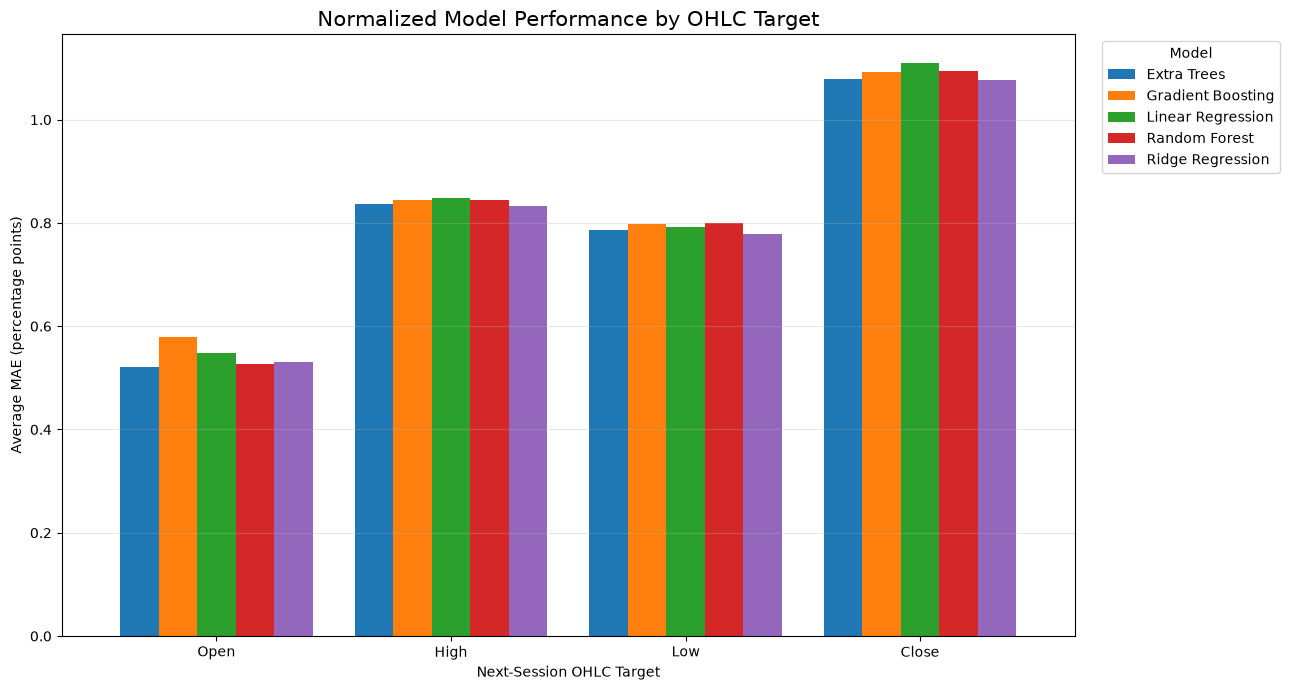

Chart saved: D:\PROJECT\Stock_Vission_Project\project_outputs\tcs_normalized_ohlc_mae_by_target.png

Lowest average MAE for each target:


,Target,Model,Average_MAE,Average_RMSE
0,Target_Next_Close_Pct,Ridge Regression,1.0774,1.5056
1,Target_Next_High_Pct,Ridge Regression,0.8320,1.2066
2,Target_Next_Low_Pct,Ridge Regression,0.7788,1.1308
3,Target_Next_Open_Pct,Extra Trees,0.5213,0.8019



STEP 327 COMPLETED!


In [385]:
# STEP 327: VISUALIZE NORMALIZED MODEL MAE BY OHLC TARGET

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

project_dir = Path.cwd()

# Locate the project root
project_dir = next(
    (
        folder
        for folder in [project_dir, *project_dir.parents]
        if (folder / "project_outputs").is_dir()
    ),
    project_dir
)

output_dir = project_dir / "project_outputs"
report_path = output_dir / "tcs_normalized_ohlc_target_validation.csv"

if not report_path.exists():
    raise FileNotFoundError(
        f"Validation report not found: {report_path}. "
        "Run STEP 326 first."
    )

target_summary = pd.read_csv(report_path)

required_columns = [
    "Model",
    "Target",
    "Average_MAE",
    "Average_RMSE"
]

missing_columns = [
    column for column in required_columns
    if column not in target_summary.columns
]

if missing_columns:
    raise ValueError(
        f"Missing validation columns: {missing_columns}"
    )

# Display names for the chart
target_labels = {
    "Target_Next_Open_Pct": "Open",
    "Target_Next_High_Pct": "High",
    "Target_Next_Low_Pct": "Low",
    "Target_Next_Close_Pct": "Close"
}

target_summary["Target_Label"] = (
    target_summary["Target"].map(target_labels)
)

# Keep target order consistent
target_order = ["Open", "High", "Low", "Close"]

pivot_mae = target_summary.pivot(
    index="Target_Label",
    columns="Model",
    values="Average_MAE"
).reindex(target_order)

ax = pivot_mae.plot(
    kind="bar",
    figsize=(13, 7),
    width=0.82
)

ax.set_title(
    "Normalized Model Performance by OHLC Target",
    fontsize=15
)

ax.set_xlabel("Next-Session OHLC Target")
ax.set_ylabel("Average MAE (percentage points)")
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", alpha=0.3)
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()

chart_path = (
    output_dir / "tcs_normalized_ohlc_mae_by_target.png"
)

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved:", chart_path.resolve())

print("\nLowest average MAE for each target:")

best_per_target = (
    target_summary
    .loc[
        target_summary.groupby("Target")["Average_MAE"].idxmin(),
        ["Target", "Model", "Average_MAE", "Average_RMSE"]
    ]
    .sort_values("Target")
    .reset_index(drop=True)
)

display(best_per_target.round(4))

print("\nSTEP 327 COMPLETED!")

In [386]:
# STEP 328: TRAIN AND SAVE FINAL NORMALIZED RIDGE MODEL

from pathlib import Path
import joblib
import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

# --------------------------------------------------
# 1. VERIFY NORMALIZED DATA
# --------------------------------------------------

required_variables = [
    "normalized_prediction_df",
    "normalized_feature_columns",
    "normalized_target_columns"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        f"Missing variables: {missing_variables}. "
        "Run STEP 320 first."
    )

feature_cols = list(normalized_feature_columns)
target_cols = list(normalized_target_columns)

# Work on a separate copy
final_model_df = normalized_prediction_df.sort_index().copy()

final_model_df = final_model_df.replace(
    [np.inf, -np.inf],
    np.nan
)

final_model_df = final_model_df.dropna(
    subset=feature_cols + target_cols
)

X_final = final_model_df[feature_cols].copy()
y_final = final_model_df[target_cols].copy()

if not (
    np.isfinite(X_final.to_numpy(dtype=float)).all()
    and np.isfinite(y_final.to_numpy(dtype=float)).all()
):
    raise ValueError(
        "Non-finite values remain in the normalized training data."
    )

if len(final_model_df) < 100:
    raise ValueError(
        "Too few observations available for the final model."
    )

# --------------------------------------------------
# 2. TRAIN THE FINAL RIDGE MODEL
# --------------------------------------------------

final_ridge_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=10.0)
)

final_ridge_model.fit(X_final, y_final)

# --------------------------------------------------
# 3. SAVE MODEL AND ITS METADATA
# --------------------------------------------------

current_path = Path.cwd()

project_dir = next(
    (
        folder
        for folder in [current_path, *current_path.parents]
        if (folder / "models").is_dir()
        and (folder / "project_outputs").is_dir()
    ),
    None
)

if project_dir is None:
    raise FileNotFoundError(
        "Project root with models and project_outputs folders not found."
    )

models_dir = project_dir / "models"
models_dir.mkdir(parents=True, exist_ok=True)

artifact_path = models_dir / "ridge_normalized_ohlc.joblib"

model_artifact = {
    "model": final_ridge_model,
    "feature_columns": feature_cols,
    "target_columns": target_cols,
    "target_type": "Next-session OHLC percentage change",
    "training_rows": len(final_model_df),
    "training_start": str(final_model_df.index.min()),
    "training_end": str(final_model_df.index.max()),
    "ridge_alpha": 10.0
}

joblib.dump(model_artifact, artifact_path)

print("Final normalized Ridge model saved successfully!")
print("Model file:", artifact_path.resolve())
print("Training observations:", len(final_model_df))
print("Feature count:", len(feature_cols))
print("Target columns:", target_cols)
print("Training period:", final_model_df.index.min(), "to", final_model_df.index.max())

print("\nOld model files have not been overwritten.")
print("STEP 328 COMPLETED!")

Final normalized Ridge model saved successfully!
Model file: D:\PROJECT\Stock_Vission_Project\models\ridge_normalized_ohlc.joblib
Training observations: 1037
Feature count: 18
Target columns: ['Target_Next_Open_Pct', 'Target_Next_High_Pct', 'Target_Next_Low_Pct', 'Target_Next_Close_Pct']
Training period: 2022-08-03 00:00:00 to 2026-10-15 00:00:00

Old model files have not been overwritten.
STEP 328 COMPLETED!


In [387]:
# STEP 329: TEST SAVED NORMALIZED RIDGE MODEL ON LATEST DATA

from pathlib import Path
import joblib
import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. LOAD THE SAVED MODEL AND METADATA
# --------------------------------------------------

project_dir = Path.cwd()

project_dir = next(
    (
        folder
        for folder in [project_dir, *project_dir.parents]
        if (folder / "models").is_dir()
        and (folder / "app.py").is_file()
    ),
    None
)

if project_dir is None:
    raise FileNotFoundError("Stock_Vission_Project folder not found.")

artifact_path = (
    project_dir / "models" / "ridge_normalized_ohlc.joblib"
)

if not artifact_path.exists():
    raise FileNotFoundError(
        f"Normalized Ridge model not found: {artifact_path}"
    )

artifact = joblib.load(artifact_path)

ridge_model = artifact["model"]
feature_columns = artifact["feature_columns"]
target_columns = artifact["target_columns"]

print("Saved model:", artifact_path.name)
print("Expected feature count:", len(feature_columns))
print("Targets:", target_columns)

# --------------------------------------------------
# 2. GET THE LATEST AVAILABLE MARKET ROW
# --------------------------------------------------

if "df" not in globals():
    raise NameError(
        "Market DataFrame 'df' not found. Run the market-data cells first."
    )

history = df.sort_index().copy()

latest_row = history.iloc[-1]
latest_date = history.index[-1]

required_sources = [
    "Open", "High", "Low", "Close", "Volume",
    "Daily_Return", "MA20", "MA50", "MA200", "RSI_14",
    "EMA12", "EMA26", "MACD", "MACD_Signal",
    "BB_Middle", "BB_Upper", "BB_Lower", "Volume_MA20"
]

missing_sources = [
    column for column in required_sources
    if column not in history.columns
]

if missing_sources:
    raise ValueError(
        f"Missing source features: {missing_sources}. "
        "Run the required feature-engineering cells first."
    )

# --------------------------------------------------
# 3. RECREATE STEP 320 NORMALIZED FEATURES
# --------------------------------------------------

current_close = float(latest_row["Close"])
current_open = float(latest_row["Open"])
current_volume_ma20 = float(latest_row["Volume_MA20"])

if (
    not np.isfinite(current_close)
    or current_close <= 0
    or not np.isfinite(current_open)
    or current_open == 0
    or not np.isfinite(current_volume_ma20)
    or current_volume_ma20 == 0
):
    raise ValueError(
        "Latest OHLC or volume data is invalid for normalization."
    )

normalized_features = {}

# Prices and price-based indicators relative to current Close
relative_price_columns = [
    "Open", "High", "Low",
    "MA20", "MA50", "MA200",
    "EMA12", "EMA26",
    "BB_Middle", "BB_Upper", "BB_Lower"
]

for column in relative_price_columns:
    normalized_features[f"{column}_Rel_Pct"] = (
        float(latest_row[column]) / current_close - 1
    ) * 100

# MACD features scaled by current Close
normalized_features["MACD_Pct"] = (
    float(latest_row["MACD"]) / current_close
) * 100

normalized_features["MACD_Signal_Pct"] = (
    float(latest_row["MACD_Signal"]) / current_close
) * 100

# Indicators retained as in STEP 320
normalized_features["Daily_Return"] = float(
    latest_row["Daily_Return"]
)

normalized_features["RSI_14"] = float(
    latest_row["RSI_14"]
)

normalized_features["Volume_Ratio"] = (
    float(latest_row["Volume"]) / current_volume_ma20
)

normalized_features["High_Low_Range_Pct"] = (
    (
        float(latest_row["High"])
        - float(latest_row["Low"])
    ) / current_close
) * 100

normalized_features["Open_Close_Change_Pct"] = (
    current_close / current_open - 1
) * 100

# Preserve the exact feature order used during training
latest_features = pd.DataFrame(
    [[normalized_features[column] for column in feature_columns]],
    columns=feature_columns,
    index=[latest_date]
)

if not np.isfinite(
    latest_features.to_numpy(dtype=float)
).all():
    raise ValueError(
        "Normalized input contains missing or infinite values."
    )

# --------------------------------------------------
# 4. PREDICT NEXT-SESSION OHLC PERCENT CHANGES
# --------------------------------------------------

predicted_pct = np.asarray(
    ridge_model.predict(latest_features)
).reshape(-1)

if len(predicted_pct) != len(target_columns):
    raise ValueError(
        "Prediction output count does not match saved target metadata."
    )

# Convert percentage changes into estimated prices
predicted_prices = current_close * (
    1 + predicted_pct / 100
)

prediction_result = pd.DataFrame({
    "Target": target_columns,
    "Estimated_Change_Pct": predicted_pct,
    "Estimated_Price": predicted_prices
})

# --------------------------------------------------
# 5. DISPLAY RESULTS AND BASIC OHLC CHECKS
# --------------------------------------------------

print("\nLatest market date:", latest_date)
print(f"Latest Close: ₹{current_close:,.2f}")

print("\nNormalized Ridge next-session estimates:")

display(
    prediction_result.round(3)
)

price_map = dict(
    zip(target_columns, predicted_prices)
)

pred_open = price_map["Target_Next_Open_Pct"]
pred_high = price_map["Target_Next_High_Pct"]
pred_low = price_map["Target_Next_Low_Pct"]
pred_close = price_map["Target_Next_Close_Pct"]

print("\nOHLC relationship checks:")
print(
    "High >= Open and Close:",
    pred_high >= max(pred_open, pred_close)
)
print(
    "Low <= Open and Close:",
    pred_low <= min(pred_open, pred_close)
)

print("\nSTEP 329 COMPLETED!")

Saved model: ridge_normalized_ohlc.joblib
Expected feature count: 18
Targets: ['Target_Next_Open_Pct', 'Target_Next_High_Pct', 'Target_Next_Low_Pct', 'Target_Next_Close_Pct']

Latest market date: 2026-10-16 00:00:00
Latest Close: ₹2,465.00

Normalized Ridge next-session estimates:


,Target,Estimated_Change_Pct,Estimated_Price
0,Target_Next_Open_Pct,0.228,2470.621
1,Target_Next_High_Pct,1.748,2508.089
2,Target_Next_Low_Pct,-0.931,2442.041
3,Target_Next_Close_Pct,0.390,2474.611



OHLC relationship checks:
High >= Open and Close: True
Low <= Open and Close: True

STEP 329 COMPLETED!
